# INTRODUCCIÓN Y CONTEXTO DEL PROBLEMA

## **Reto 1: Expected Credit Loss**

Este mes vais a poneros en la piel de un equipo de modelización de riesgo de crédito en un banco. El Comité de Riesgos os ha pasado una cartera de préstamos y os ha enviado este correo en donde os pide una cosa muy concreta:


*Buenos días,*

*Necesitamos calcular la pérdida esperada de la nueva cartera que acabamos de adquirir. Estos resultados se utilizarán para las provisiones y los tendrá que validar el regulador, así que debemos ser conservadores para evitar sanciones potenciales.*

*Necesitamos el dato listo para el Comité del 17 de octubre. Adjuntamos los datos que disponemos de la cartera.*

*Saludos,*

*Big Boss*

Ese es el reto traducido: **estimar el ECL (Expected Credit Loss)** de la cartera lo mejor posible, **con sesgo conservador**. Pero fíjate en dos cosas que dicen entre líneas (esto se aprende con la experiencia). La primera, es que indican que se utilizará para provisiones (es decir, el dinero que hay que “guardar” en caso de impagos), por lo que nos interesa que la ECL sea lo más baja posible para ahorrar capital. Pero la segunda, es precisamente que el regulador va a validarlo, por lo que **si las predicciones no son conservadoras nos impondrán sanciones**. Por tanto, **el objetivo real es obtener la ECL más precisa posible con la restricción de que la estimación esté siempre por encima del valor real.**

## **Los datos**

Cartera de préstamos personales de Lending Club (EE. UU.), solo solicitudes individuales: https://www.kaggle.com/datasets/db0boy/lending-club-loan-data-cleared/data

Son dos ficheros: X.csv (variables disponibles para la modelización) y target.csv (columna y, 1 = impago). Contiene más de 2 millones de préstamos. Las columnas de X.csv se dividen en dos grupos, y esta es una distinción importante:

* **Variables de originación**: Estas variables son las **disponibles en el momento de la concesión del préstamo**.

* **Variables de desempeño**: Estas variables son **posteriores a la concesión del préstamo** y se construyen a partir del histórico de pagos del cliente.

Este segundo grupo es la clave: son las que nos van a permitir reconstruir cuánto se ha cobrado realmente de cada préstamo y cuánto queda pendiente para calcular la LGD y el EAD observados y con ellos, la pérdida real de la cartera.

**Data leakage:** las **variables de desempeño (y el grade de Lending Club) NO pueden usarse como input de nuestro modelo de PD**, porque no existían en el momento de conceder el préstamo. Usarlas sería hacer trampa. Sí son la base para modelizar LGD y EAD.

## **El problema**

$$PD \times LGD \times EAD = ECL$$

La pérdida esperada de un préstamo se descompone en tres piezas:

* **PD** (Probability of Default): probabilidad de que ese préstamo impague.
* **LGD** (Loss Given Default): qué % de lo que debe se pierde realmente si impaga (1 – tasa de recuperación).
* **EAD** (Exposure at Default): cuánto queda pendiente en el momento del impago.

La pérdida esperada de cada préstamo es $ECL_i = PD_i × LGD_i × EAD_i$, y la pérdida esperada de la cartera es la suma de todos los $ECL_i$.

## **Las métricas de evaluación**

El objetivo es estimar con la máxima precisión posible la pérdida real de la cartera de test. Por tanto, el reto se evaluará con las siguientes métricas:

* **ECL total de la cartera  (cuanto más bajo mejor)**
* **MAE y MAPE de los $ECL_j$**

**IMPORTANTE!** Tener en cuenta las siguientes restricciones. Si se incumple alguna, el modelo se descarta automáticamente:
* **El ECL estimado tiene que ser mayor al “ECL real”**
* **$ECL_j$ puede ser menor al “$ECL_j$ real” para un máximo del 10% de la cartera**

No hace falta que los tres modelos sean igual de sofisticados, de hecho en banca es habitual que LGD y EAD sean ajustados con modelos distintos que la PD. Lo importante es que el ECL agregado sea una estimación honesta y razonablemente conservadora.





## Instrucciones para la correcta evaluación

* Todo el pipeline (desde que se cargan los datos hasta que se calcula el ECL final) depende de una sola variable SEED, definida al principio del notebook, que controla el train_test_split y cualquier otra fuente de aleatoriedad (random_state fijado en todos los modelos).
* No se pueden excluir filas "raras" a mano, mirar el test antes de tiempo, ni usar variables de desempeño en el modelo de PD.
* Los datos test no pueden incluirse en ninguna modelización. La limpieza, ingeniería de variables (y por supuesto entrenamiento de modelos) deben de hacerse sobre la muestra Train, y solo después se aplicará todo esto a la muestra de Test.
* El notebook termina con una única celda que imprime los dos números de interés.


# 1.PREPROCESAMIENTO DE DATOS Y EDA

In [ ]:
# Librerias

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from google.colab import drive
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

# Monta tu unidad de Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
ruta_data = '/content/drive/MyDrive/Proyectos Data Science/X.csv'
ruta_target = '/content/drive/MyDrive/Proyectos Data Science/target.csv'
data=pd.read_csv(ruta_data,header=0)
target=pd.read_csv(ruta_target)

In [ ]:
target.shape

(2139643, 1)

In [ ]:
data.shape

(2139643, 45)

Las longitudes de `data` y `target` coinciden en cuanto a filas.

In [ ]:
target.value_counts()

,count
y,
0,1859927
1,279716


In [ ]:
print('Porcentaje de 0:', round(target.value_counts()[0]/len(target)*100,2))
print('Porcentaje de 1:', round(target.value_counts()[1]/len(target)*100,2))

Porcentaje de 0: 86.93
Porcentaje de 1: 13.07


Como vemos, la target en cuanto a impagos está bastante desbalanceada. Es algo que habrá que tener en cuenta a la hora de la modelización. Considerar el modelo trivial para PD que asigne un 0 a cada observación consigue un 86.93% de accuracy pero no nos sirve para estimar la ECL, pues estaríamos diciendo que ECL=0 y esto no es ni útil ni realista.

Ahora entendamos cada una de las variables explicativas y hagamos su división en **variables de originación** y **variables de desempeño**.

## Variables de desempeño

| Variable | Descripción |
|---|---|
| `remaining_princ_for_tot_amnt_fund` | Principal pendiente de amortizar a la fecha de corte de los datos. |
| `paym_rec_for_tot_amnt_fund` | Total cobrado hasta la fecha (principal + intereses + comisiones, y posiblemente recobros). |
| `princ_rec` | Principal cobrado. |
| `interest_rec` | Intereses cobrados. |
| `late_fees_rec` | Comisiones por mora cobradas. |

## Variables de originación

### Características del préstamo

| Variable | Descripción |
|---|---|
| `funded_amnt` | Importe concedido del préstamo. |
| `loan_term_months` | Plazo del préstamo en meses (36 o 60). |
| `interest_rate` | Tipo de interés en %. Lo fija Lending Club según el sub-grade, por lo que es casi un sustituto del `grade`. |
| `monthly_payment` | Cuota mensual. Función determinista del importe, el tipo de interés y el plazo. |
| `loan_purpose` | Finalidad del préstamo (debt_consolidation, credit_card, small_business…). |
| `initial_list_status` | Modalidad de venta a inversores: `w` (whole, entero) o `f` (fractional, en fracciones). |
| `disbursement_method` | Método de desembolso: `Cash` o `DirectPay` (pago directo a acreedores). |
| `issue_date_month` | Mes de emisión del préstamo. |
| `issue_date_year` | Año de emisión del préstamo. |

### Perfil del prestatario

| Variable | Descripción |
|---|---|
| `emp_title` | Puesto de trabajo del prestatario (texto libre, alta cardinalidad). |
| `emp_length` | Antigüedad laboral ("< 1 year" … "10+ years"). |
| `home_ownership_status` | Situación de la vivienda (RENT, MORTGAGE, OWN y categorías residuales). |
| `annual_income` | Ingresos anuales declarados. |
| `verification_status` | Verificación de ingresos: Not Verified, Source Verified o Verified. |
| `dept_paym_income_ratio` | Ratio deuda-ingresos (DTI) en %, sin incluir hipoteca ni este préstamo. |

### Localización geográfica

| Variable | Descripción |
|---|---|
| `addr_state` | Estado de residencia del prestatario. |
| `region_code` | Primer dígito del código postal (región geográfica, redundante con el estado). |

### Historial crediticio

| Variable | Descripción |
|---|---|
| `earliest_cr_line_month` | Mes de apertura de la primera línea de crédito. |
| `earliest_cr_line_year` | Año de apertura de la primera línea de crédito. |
| `num_open_credit_lines` | Número de líneas de crédito abiertas. |
| `tot_num_credit_lines` | Número total de líneas de crédito en el historial. |
| `num_derogatory_pub_rec` | Registros públicos negativos (quiebras, embargos…). |

### Morosidad previa

| Variable | Descripción |
|---|---|
| `num_30+_delinq_in_2yrs` | Número de retrasos de más de 30 días en los últimos 2 años. |
| `mths_since_last_delinq` | Meses desde el último retraso en pagos (NaN = sin retrasos registrados). |
| `mths_since_recent_bankcard_delinq` | Meses desde el último retraso en tarjeta bancaria (NaN = sin retrasos registrados). |
| `mths_since_recent_revol_delinq` | Meses desde el último retraso en crédito revolving (NaN = sin retrasos registrados). |

### Crédito revolving y endeudamiento

| Variable | Descripción |
|---|---|
| `total_credit_revolving_bal` | Saldo total en crédito revolving. |
| `used_credit_share` | % del límite revolving utilizado. |
| `max_bal_owed` | Saldo máximo adeudado en cuentas revolving. |
| `bal_to_cred_lim` | % de saldo sobre límite de crédito en todas las cuentas. |

### Apertura reciente de cuentas

| Variable | Descripción |
|---|---|
| `num_open_trades_in_6mths` | Cuentas abiertas en los últimos 6 meses. |
| `num_installment_acc_op_in_12mths` | Préstamos a plazos abiertos en los últimos 12 meses. |
| `num_installment_acc_op_in_24mths` | Préstamos a plazos abiertos en los últimos 24 meses. |
| `mths_since_last_installment_acc_op` | Meses desde la apertura del último préstamo a plazos. |
| `num_rev_trades_op_in_12mths` | Cuentas revolving abiertas en los últimos 12 meses. |
| `num_rev_trades_op_in_24mths` | Cuentas revolving abiertas en los últimos 24 meses. |

### Consultas de crédito

| Variable | Descripción |
|---|---|
| `num_inq_in_6mths` | Consultas de crédito en los últimos 6 meses. |
| `num_inq_in_12mths` | Consultas de crédito en los últimos 12 meses. |
| `num_inq` | Consultas de financiación personal. |

## Target de PD

Es una variable binaria donde:
* 1 = Impago
* 0 = No impago



Debemos predecir 3 cosas: PD, LGD,EAD.

Comenzamos por PD

Tener en cuenta que en la siguiente selección de variables hemos quitado `grade` ya que esta variable estaría introduciendo data leakage.

In [ ]:
variables_originacion=[
    # Características del préstamo
    "funded_amnt",
    "loan_term_months",
    "interest_rate",
    "monthly_payment",
    "loan_purpose",
    "initial_list_status",
    "disbursement_method",
    "issue_date_month",
    "issue_date_year",
    # Perfil del prestatario
    "emp_title",
    "emp_length",
    "home_ownership_status",
    "annual_income",
    "verification_status",
    "dept_paym_income_ratio",
    # Localización geográfica
    "addr_state",
    "region_code",
    # Historial crediticio
    "earliest_cr_line_month",
    "earliest_cr_line_year",
    "num_open_credit_lines",
    "tot_num_credit_lines",
    "num_derogatory_pub_rec",
    # Morosidad previa
    "num_30+_delinq_in_2yrs",
    "mths_since_last_delinq",
    "mths_since_recent_bankcard_delinq",
    "mths_since_recent_revol_delinq",
    # Crédito revolving y endeudamiento
    "total_credit_revolving_bal",
    "used_credit_share",
    "max_bal_owed",
    "bal_to_cred_lim",
    # Apertura reciente de cuentas
    "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "mths_since_last_installment_acc_op",
    "num_rev_trades_op_in_12mths",
    "num_rev_trades_op_in_24mths",
    # Consultas de crédito
    "num_inq_in_6mths",
    "num_inq_in_12mths",
    "num_inq",
]


variables_desmpeño=["remaining_princ_for_tot_amnt_fund", "paym_rec_for_tot_amnt_fund",
                 "princ_rec", "interest_rec", "late_fees_rec"]

## División en TRAIN - VAL - TEST

A partir de aquí, todo el tratamiento de los datos dependerá de una semilla fijada en la variable **SEED**.

A continuación, hacemos la división de los datos en tres conjuntos.
* **Train:** se utilizará para hacer el preprocesamiento de los datos, el EDA y entrenar modelos.
* **Val:** se utilizará para comparar la selección de los modelos finales mediante la comparación de las métricas obtenidas en este conjunto. Además, con este se enterna la calibración final de ECL.
* **Test:** se utilizará para obtener las métricas finales e insesgadas sobre un conjunto de datos que nunca ha sido utilizado durante la fase de modelización.



In [ ]:
# ===== Parámetros globales =====
SEED = 42
perc_train, perc_val, perc_test = 0.6, 0.2, 0.2
stratify = False

np.random.seed(SEED)

X=data
y=target
y=y.squeeze()

def split_train_val_test(X, y, perc_train, perc_val, perc_test, seed, stratify=stratify):
    assert np.isclose(perc_train + perc_val + perc_test, 1.0), "Los porcentajes deben sumar 1"

    # 1) Separar test
    X_trval, X_test, y_trval, y_test = train_test_split(
        X, y, test_size=perc_test, random_state=seed,
        stratify=y if stratify else None,
    )
    # 2) Separar validación del resto (reescalando su proporción)
    val_rel = perc_val / (perc_train + perc_val)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trval, y_trval, test_size=val_rel, random_state=seed,
        stratify=y_trval if stratify else None,
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = split_train_val_test(
    X, y, perc_train, perc_val, perc_test, SEED
)

# Comprobación: tamaños y tasa de default en cada muestra
for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nombre:5s}: {len(yy):>9,} filas ({len(yy)/len(y):.1%}) | tasa default = {yy.mean():.2%}")

train: 1,283,785 filas (60.0%) | tasa default = 13.09%
val  :   427,929 filas (20.0%) | tasa default = 13.01%
test :   427,929 filas (20.0%) | tasa default = 13.08%


## Estudio general sobre las variables en train

In [ ]:
print(X.dtypes.value_counts())
X.select_dtypes(include="object").columns.tolist()

float64    22
int64      12
object     11
Name: count, dtype: int64


['grade',
 'emp_title',
 'emp_length',
 'home_ownership_status',
 'verification_status',
 'loan_purpose',
 'addr_state',
 'initial_list_status',
 'disbursement_method',
 'issue_date_month',
 'earliest_cr_line_month']

Las columnas de tipo objeto son las qué esperábamos que contendrían texto.

A continuación analizamos si todos los valores nulos están correctamente formateados.

### Análisis de valores nulos

In [ ]:
sospechosos = {
    # Vacíos y variantes de "no disponible"
    "", "na", "n/a", "n.a", "n.a.", "n\\a", "na.", "#n/a",
    "nan", "null", "nil", "none", "void", "undefined", "unknown", "unk",
    "missing", "blank", "empty", "not available", "not applicable",
    "not specified", "unspecified", "not provided", "not given",
    "no data", "no info", "no information", "none given", "tbd", "tba",
    # Errores típicos de Excel
    "#value!", "#ref!", "#div/0!", "#name?", "#null!", "#num!",
    # Relleno típico
    "x", "xx", "xxx", "xxxx", "0", "00", "000", "-1", "999", "9999",
    "test", "dummy", "default", "...",
}

# Cadenas compuestas solo por puntuación o espacios: "-", "--", "?", "???", ".", "*", "_"
patron_puntuacion = r"^[\W_]+$"

for col in X.select_dtypes(include="object").columns:
    valores = X[col].dropna().astype(str).str.strip().str.lower()
    mask = valores.isin(sospechosos) | valores.str.match(patron_puntuacion)
    encontrados = valores[mask].value_counts()
    if not encontrados.empty:
        print(f"{col}:\n{encontrados}\n")

emp_title:
emp_title
na      8
test    4
        3
.       1
Name: count, dtype: int64



In [ ]:
mask = X["emp_title"].astype(str).str.strip().str.lower().isin({"", "na",".","test"})
X.loc[mask, "emp_title"].map(repr).value_counts()

,count
emp_title,
'na',5
'Na',3
'Test',3
' ',3
'test',1
'.',1


In [ ]:
X.loc[X["emp_title"].str.strip().str.lower().isin(["","na","test","Test",".","teste"])]

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
22669,11000,10.72,358.67,B2,Na,1 year,RENT,48000.0,Source Verified,debt_consolidation,...,1,NaN,NaN,DirectPay,36,Dec,2018,9,Mar,2005
80496,8000,16.91,284.87,C5,Na,1 year,MORTGAGE,33000.0,Source Verified,home_improvement,...,1,NaN,NaN,Cash,36,Oct,2018,1,Oct,2006
124102,32000,10.47,687.33,B2,Test,4 years,RENT,65000.0,Verified,credit_card,...,0,NaN,NaN,Cash,60,Sep,2018,9,Nov,2007
196398,11200,15.02,388.37,C3,Na,3 years,MORTGAGE,42000.0,Verified,credit_card,...,0,NaN,16.0,Cash,36,Jul,2018,9,Mar,2007
250530,9600,10.41,311.62,B3,,10+ years,OWN,40000.0,Not Verified,credit_card,...,0,NaN,NaN,Cash,36,Jun,2018,0,Oct,1999
567446,16000,8.39,327.42,B1,,10+ years,MORTGAGE,76000.0,Source Verified,home_improvement,...,0,73.0,73.0,Cash,60,May,2016,1,Apr,2003
570838,6000,7.39,186.34,A4,test,4 years,OWN,78400.0,Source Verified,home_improvement,...,3,NaN,NaN,Cash,36,May,2016,1,Mar,2000
594598,6000,7.39,186.34,A4,,10+ years,OWN,43000.0,Source Verified,debt_consolidation,...,0,NaN,NaN,Cash,36,Apr,2016,0,Oct,1999
663925,6000,12.99,202.14,C2,Test,10+ years,MORTGAGE,78000.0,Source Verified,home_improvement,...,1,NaN,NaN,Cash,36,Mar,2016,3,Nov,2001
712307,14600,20.75,392.93,E2,na,10+ years,MORTGAGE,72000.0,Not Verified,debt_consolidation,...,1,NaN,NaN,Cash,60,Feb,2016,2,Sep,2003


Parecen registros normales. Por tanto, interpretaremos los valores anteriores como nulos.

In [ ]:
emp = X["emp_title"].str.strip()
X["emp_title"] = emp.mask(emp.str.lower().isin({"", "na","test","Test","."}))

Ahora podemos estar casi 100% seguros de que todos los valores faltantes están correctamente formateados como `NaN`.

A partir de aquí, el estudio y tratamiento de valores faltantes se hará con el conjunto $X_{train}$.

Estudiamos ahora qué variables tienen nulos para así poder darles un tratamiento adecuado.

In [ ]:
nulls_train=pd.Series(name='nulls')
for c in X_train.columns:
  nulls_train[c]=X_train[c].isna().sum()
nulls_train=nulls_train.loc[nulls_train > 0.0]

#Porcentaje de valores nulos
(nulls_train.sort_values() / X_train.shape[0]).map("{:.2%}".format)

,nulls
emp_length,6.11%
emp_title,6.96%
num_open_trades_in_6mths,40.50%
num_installment_acc_op_in_12mths,40.50%
num_rev_trades_op_in_12mths,40.50%
num_installment_acc_op_in_24mths,40.50%
max_bal_owed,40.50%
num_rev_trades_op_in_24mths,40.50%
num_inq,40.50%
bal_to_cred_lim,40.50%


Las columnas con valores faltantes son:

| Variable | %NaN |
|---|---|
| `emp_length` | 6.11% |
| `emp_title` | 6.96% |
| `max_bal_owed` | 40.50% |
| `num_rev_trades_op_in_12mths` | 40.50% |
| `num_inq` | 40.50% |
| `num_installment_acc_op_in_12mths` | 40.50% |
| `num_open_trades_in_6mths` | 40.50% |
| `num_installment_acc_op_in_24mths` | 40.50% |
| `num_rev_trades_op_in_24mths` | 40.50% |
| `bal_to_cred_lim` | 40.50% |
| `mths_since_last_installment_acc_op` | 42.35% |
| `mths_since_last_delinq` | 50.98% |
| `mths_since_recent_revol_delinq` | 67.01% |
| `mths_since_recent_bankcard_delinq` | 76.83% |


Observar que no hay ninguna variable de desempeño con valores faltantes, lo cual es bastante importante a la hora de **calcular la LGD y la EAD observadas**, que son las targets de los modelos para estimar LGD_i y EAD_i.

**Primeros insights sobre los valores faltantes**

Según su significado, las variables con nulos se agrupan en cuatro casos:

**1. Variables de "meses desde el último evento": el nulo indica que el evento nunca ha ocurrido.**
* `mths_since_last_delinq`: meses desde el último retraso en cualquier cuenta.
* `mths_since_recent_revol_delinq`: meses desde el último retraso en cuentas revolving.
* `mths_since_recent_bankcard_delinq`: meses desde el último retraso en tarjetas.
* `mths_since_last_installment_acc_op`: meses desde la apertura del último préstamo a plazos.

En las tres primeras, un nulo indica que el prestatario no tiene retrasos registrados; en la última, que nunca ha abierto un préstamo a plazos.

**2. Recuentos e importes del buró de crédito: el nulo no equivale a cero.**

| Variable | Descripción |
|---|---|
| `num_open_trades_in_6mths` | Cuentas abiertas en los últimos 6 meses |
| `num_rev_trades_op_in_12mths` | Cuentas revolving abiertas en los últimos 12 meses |
| `num_rev_trades_op_in_24mths` | Cuentas revolving abiertas en los últimos 24 meses |
| `num_installment_acc_op_in_12mths` | Préstamos a plazos abiertos en los últimos 12 meses |
| `num_installment_acc_op_in_24mths` | Préstamos a plazos abiertos en los últimos 24 meses |
| `num_inq` | Consultas de financiación personal |
| `max_bal_owed` | Saldo máximo adeudado en cuentas revolving |

En principio, un nulo podría significar que no hubo ninguna apertura, consulta o saldo, o bien que el dato no se recogió. Como el valor 0 sí aparece en todas estas variables, lo más prudente es interpretar el nulo como **dato no registrado** y no imputarlo como 0.

**3. `bal_to_cred_lim` (saldo sobre el límite de crédito en todas las cuentas): requiere un estudio más detallado.** Sus nulos también pueden corresponder a datos no recogidos, en cuyo caso imputarlos con un 0 sería un error grave.

**4. Variables de empleo.**
* `emp_title` (puesto de trabajo): los nulos se sustituyen por la categoría `"unknown"`.
* `emp_length` (antigüedad laboral): ya existe la categoría `"< 1 year"`, que recoge las antigüedades nulas o casi nulas, por lo que un nulo no puede interpretarse como antigüedad 0. Se trata como valor desconocido, que podría estimarse a partir del resto de variables explicativas en caso de ser necesario.

In [ ]:
for c in ["num_rev_trades_op_in_24mths","num_installment_acc_op_in_24mths","num_open_trades_in_6mths","num_installment_acc_op_in_12mths","num_inq","num_rev_trades_op_in_12mths","max_bal_owed"]:
  print(c,":",(0 or 0.0) in X_train[c].value_counts().index)

num_rev_trades_op_in_24mths : True
num_installment_acc_op_in_24mths : True
num_open_trades_in_6mths : True
num_installment_acc_op_in_12mths : True
num_inq : True
num_rev_trades_op_in_12mths : True
max_bal_owed : True


Observamos que las variables `num_rev_trades_op_in_24mths`,`num_installment_acc_op_in_24mths`,`num_open_trades_in_6mths`,`num_installment_acc_op_in_12mths`,`num_inq`,`num_rev_trades_op_in_12mths` y `max_bal_owed`registran el valor $0$ en al menos un préstamo. Por tanto, esto nos permite concluir que el nulo no significa que su valor sea $0$ necesariamente y nos abre la puerta a estudiar otras causas.

#### **emp_title y emp_length**

Estudiamos las variables `emp_title` y `emp_length`.

In [ ]:
print("Impago en emp_title = Nan :",y_train[X_train.emp_title.isna()].mean())
print("Impago en emp_title != Nan :",y_train[~X_train.emp_title.isna()].mean())

Impago en emp_title = Nan : 0.1543214713487737
Impago en emp_title != Nan : 0.1291713689625033


In [ ]:
print("Impago en emp_length = Nan :",y_train[X_train.emp_length.isna()].mean())
print("Impago en emp_length != Nan :",y_train[~X_train.emp_length.isna()].mean())

Impago en emp_length = Nan : 0.16418805163001887
Impago en emp_length != Nan : 0.12875762933047724


**El impago en el grupo con valores faltantes es un 3% superior que en el grupo sin valores faltantes tanto para `emp_title` como para `emp_length`**, porcentaje que es bastante significativo teniendo en cuenta los porcentajes de impago en los que nos movemos. Por tanto, conviene tratar a estos grupos como categorías nuevas.

Entre los motivos por los cuales este valor sería desconocido en `emp_length` se encuentran: jubilados, autónomos, desempleados, no quisieron aportar el dato, etc.

In [ ]:
# Computamos los nulos de la columna "emp_title" por la categoria "unknown"
for df in (X_train, X_val, X_test):
    df["emp_title"] = df["emp_title"].fillna("unknown")

# Computamos los nulos de la columna "emp_length" por la categoria "unknown"
for df in (X_train, X_val, X_test):
    df["emp_length"] = df["emp_length"].fillna("unknown")

Con esto la variable `emp_length` ya no tiene valores nulos.

Analizamos ahora la tasa de default por grupo de `emp_length`.

Asumiendo observaciones independientes y por el Teorema Central del Límite, la tasa de default (media de las variables bernoullis que representan si el cliente impaga o no) sigue una distribución asintóticamente normal. De esta manera podemos calcular el intervalo de confianza de Wald al 95% para poder identificar si hay diferencias estadísticamente significativas para la tasa de default entre los diferentes grupos.

De ahora en adelante, cada vez que usemo intervalos de confianza nos estaremos apoyando en este razonamiento.



In [ ]:
ORDEN_EMP_LENGTH = ["< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
                    "6 years", "7 years", "8 years", "9 years", "10+ years", "unknown"]

tabla = y_train.groupby(X_train["emp_length"]).agg(n="size", tasa_default="mean").reindex(ORDEN_EMP_LENGTH)
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]

tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup
emp_length,,,,,
< 1 year,"100,938",13.30%,0.21%,13.09%,13.51%
1 year,"85,334",13.57%,0.23%,13.34%,13.80%
2 years,"117,080",12.92%,0.19%,12.73%,13.11%
3 years,"103,524",13.23%,0.21%,13.03%,13.44%
4 years,"78,397",12.77%,0.23%,12.53%,13.00%
5 years,"79,907",13.07%,0.23%,12.84%,13.31%
6 years,"58,776",12.89%,0.27%,12.62%,13.17%
7 years,"53,624",13.54%,0.29%,13.25%,13.83%
8 years,"53,207",14.31%,0.30%,14.01%,14.61%


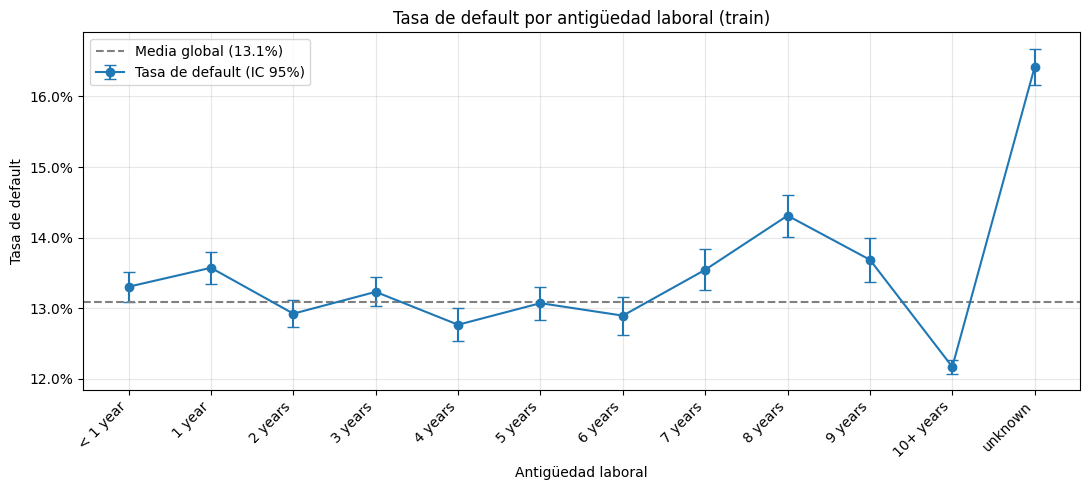

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.errorbar(range(len(tabla)), tabla["tasa_default"], yerr=tabla["ic95_±"],
            fmt="-o", capsize=4, label="Tasa de default (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Media global ({y_train.mean():.1%})")

ax.set_xticks(range(len(tabla)))
ax.set_xticklabels(tabla.index, rotation=45, ha="right")
ax.set_xlabel("Antigüedad laboral")
ax.set_ylabel("Tasa de default")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Tasa de default por antigüedad laboral (train)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Basándonos en los intervalos de confianza podemos reducir el número de categorías a las siguientes:
* \< 2 years
* 2 years
* 3 years
* 4 years
* 5-6 years
* 7 years
* 8 years
* 9 years
* 10+ years
* unknown

Cabe destacar que la **mayor tasa de default se encuentra en el grupo "unknown" (16,4%)** y **la menor en "10+ years" (12,2%)**.

Además, observamos que **la relación entre la tasa de default y la antigüedad laboral no es lineal ni monótona**.

Creamos la variable `emp_length_cat` según las categorías descritas arriba y comprobamos que su construcción se ha hecho correctamente.

In [ ]:
MAPA_EMP_LENGTH = {
    "< 1 year": "< 2 years", "1 year": "< 2 years",
    "2 years": "2 years", "3 years": "3 years", "4 years": "4 years",
    "5 years": "5-6 years", "6 years": "5-6 years",
    "7 years": "7 years", "8 years": "8 years", "9 years": "9 years",
    "10+ years": "10+ years", "unknown": "unknown",
}

for df in (X_train, X_val, X_test):
    df["emp_length_cat"] = df["emp_length"].fillna("unknown").map(MAPA_EMP_LENGTH)

print(X_train["emp_length_cat"].isna().sum(), "valores sin categoría")
X_train["emp_length_cat"].value_counts()

0 valores sin categoría


,count
emp_length_cat,
10+ years,428598
< 2 years,186272
5-6 years,138683
2 years,117080
3 years,103524
unknown,78404
4 years,78397
7 years,53624
8 years,53207


Eliminamos la variable `emp_length` y nos quedamos con `emp_length_cat`.

In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns=["emp_length"], inplace=True)

Continuamos ahora con el análisis de `emp_title`.

In [ ]:
#X_train.emp_title.value_counts().to_csv("emp_title_value_counts")

#from google.colab import files
#files.download("emp_title_value_counts")

*Descargamos la lista de valores únicos de esta variable para aprovechar la potencia de la IA generativa y así poder crear una función que realice su limpieza.*

In [ ]:
len(X_train.emp_title.value_counts())

335404

In [ ]:
X_train.emp_title.sample(20)

,emp_title
1742326,"4D, Inc."
1380836,Engineer
362069,Principal Software Engineer
1108310,School Counselor
1541872,Realtor
543692,licensed lending officer
483326,Sr programmer
1278663,Superintendent
1326962,Mechanical CAD Designer
1073234,Supervisor


Observamos que la variable `emp_title` tiene una cardinalidad demasiado alta y no sigue un formato de registro claro: hay observaciones donde únicamente se describe el puesto, otras donde sólo se indica la empresa, otras que sólo registran la jerarquía dentro de la empresa e incluso valores desconocidos como "unknown".

In [ ]:
X_train.emp_title.value_counts()[X_train.emp_title.value_counts()==1]

,count
emp_title,
Halcon Resources Corporation,1
Imaging and IT Manager,1
jail,1
Community Employment Specialist,1
"Yodlee, Inc.",1
...,...
CSR 440,1
Laser Safety Expert,1
Financial Center Lending Officer,1


Tenemos que 262964 puestos de trabajo constan de una única observación,lo cual supone un problema a la hora de modelar los datos. Además, debido a la falta de normalización del texto hay observaciones con registros distintos que hacen referencia al mismo puesto de trabajo.

A continuación, normalizamos el texto y clasificamos las observaciones en base a tres situaciones distintas:
* clasificación de puestos por palabras clave.
* empresas cuyo nombre indica el sector.
* categoría propia para los casos en que solo sabemos que es un nombre de empresa sin sector identificable.

A continuación creamos una función **ClasificadorEmpTitle** en el archivo de python **emp_title_clasification.py** que nos permita limpiar esta variable y generar un número manejable de categorías a partir de ella.

In [ ]:
from emp_title_clasification import ClasificadorEmpTitle

clf = ClasificadorEmpTitle().fit(X_train["emp_title"])
for df in (X_train, X_val, X_test):
    df[["emp_title_norm", "emp_tipo", "emp_ambito"]] = clf.transform(df["emp_title"])

In [ ]:
X_train.emp_tipo.value_counts()

,count
emp_tipo,
puesto,1145167
desconocido,89342
empresa,49276


In [ ]:
X_train.emp_ambito.value_counts()

,count
emp_ambito,
puesto_sin_sector,297471
sanidad,112586
desconocido,89342
finanzas_seguros,81758
transporte_logistica,73046
ventas_comercio,71630
educacion_investigacion,64818
otros,53174
tecnologia_telecom,50885


La variable generada `emp_title_norm` es la versión normalizada del texto de `emp_title`, y es la base sobre la que se aplican las reglas de clasificación de `emp_tipo` y `emp_ambito`. Se obtiene aplicando los siguientes pasos:

1. **Limpieza del formato:** paso a minúsculas, sustitución de "&" por "and", unión de abreviaturas con puntos (por ejemplo, "P.C." pasa a "pc"), eliminación de signos de puntuación y espacios sobrantes.
2. **Expansión de abreviaturas frecuentes:** por ejemplo, "sr" pasa a "senior", "mgr" a "manager", "rn" a "registered nurse" o "hr" a "human resources".
3. **Corrección de erratas manual:** erratas y variantes frecuentes identificadas en train, como "supervisior", "maintanence" o "captian", y términos en español como "operador" o "mantenimiento".
4. **Corrección de erratas automática:** cada palabra que no pertenece al vocabulario de las reglas se sustituye por la palabra del vocabulario más parecida, siempre que la similitud sea alta, empiecen por la misma letra y la palabra sea rara en train (5 apariciones o menos) o al menos 20 veces menos frecuente que la palabra correcta. Las correcciones se aprenden solo con train y se aplican después a validación y test. Una lista de palabras protegidas evita corregir palabras reales que se parecen a otras, como "country" y "county".

Con esta normalización, variantes como "Sr. Software Engr", "SR SOFTWARE ENGINEER" o "senior softwre engineer" se convierten en el mismo texto, "senior software engineer". Aun así, la variable mantiene una cardinalidad muy alta, por lo que no está pensada para usarse directamente en el modelo, sino como paso intermedio para construir `emp_tipo` y `emp_ambito`.

La variable generada `emp_tipo` indica qué tipo de información contiene `emp_title`, y consta de tres categorías:
* **puesto**: el texto describe un puesto de trabajo (por ejemplo, "Registered Nurse" o "Manager").
* **empresa**: el texto es el nombre de un empleador, identificado por llevar un sufijo legal (inc, llc, corp…) o por mencionar una organización sin ninguna palabra de puesto (por ejemplo, "Wells Fargo Bank" o "Halcon Resources Corporation"). Es habitual en los primeros años de Lending Club, cuando el formulario pedía el empleador en lugar del puesto.
* **desconocido**: el puesto no se informó

Además de los ámbitos profesionales, la variable `emp_ambito` incluye tres categorías para los títulos a los que no se puede asignar un sector:
* **puesto_sin_sector**: puestos que indican un rol o nivel jerárquico, pero no el sector de actividad, como "Manager", "Owner", "Director" o "Analyst". Agrupa en torno al 23% de la cartera.
* **empresa_sin_sector**: nombres de empresa cuyo nombre no permite deducir a qué se dedican, como "Ferguson Enterprises" o "DynCorp International". Representa en torno al 1% de la cartera.
* **otros**: títulos que no coinciden con ninguna regla de clasificación, como siglas ambiguas ("rca", "ssa"), fragmentos sin información ("registration") o empresas sin sufijo legal. Representa en torno al 4% de la cartera.

Estudiamos ahora si hay diferencias significativas en la tasa de default entre los grupos "ortros", "empresa_sin_sector" y "puesto_sin_sector" para ver si resulta adecuado fusionarlos o no.


In [ ]:
grupos = ["otros", "puesto_sin_sector", "empresa_sin_sector"]
mask = X_train["emp_ambito"].isin(grupos)

tabla_ic = (
    y_train[mask]
    .groupby(X_train.loc[mask, "emp_ambito"])
    .agg(n="size", tasa_default="mean")
    .reindex(grupos)
)
tabla_ic["ic95_±"] = 1.96 * np.sqrt(tabla_ic["tasa_default"] * (1 - tabla_ic["tasa_default"]) / tabla_ic["n"])
tabla_ic["ic95_inf"] = tabla_ic["tasa_default"] - tabla_ic["ic95_±"]
tabla_ic["ic95_sup"] = tabla_ic["tasa_default"] + tabla_ic["ic95_±"]

print(f"Tasa de default global en train: {y_train.mean():.2%}")
tabla_ic.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                       "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

Tasa de default global en train: 13.09%


,n,tasa_default,ic95_±,ic95_inf,ic95_sup
emp_ambito,,,,,
otros,"53,174",15.72%,0.31%,15.41%,16.03%
puesto_sin_sector,"297,471",12.16%,0.12%,12.04%,12.27%
empresa_sin_sector,"13,307",14.27%,0.59%,13.68%,14.86%


Ningún intervalo se solapa, por tanto, mantenemos estas categorías sin agruparlas.

In [ ]:
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df[['emp_tipo', 'emp_ambito','emp_length_cat']].isna().sum().to_dict()}")

train: {'emp_tipo': 0, 'emp_ambito': 0, 'emp_length_cat': 0}
val: {'emp_tipo': 0, 'emp_ambito': 0, 'emp_length_cat': 0}
test: {'emp_tipo': 0, 'emp_ambito': 0, 'emp_length_cat': 0}


Con todo esto hemos conseguido:
* `emp_length` variable categórica sin nulos
* `emp_ambito` y `emp_tipo` variables categóricas y sin nulos creadas a partir de `emp_title` (esta última ya se puede eliminar ya que su información normalizada está en `emp_title_norm`)

In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns=["emp_title"], errors="ignore" ,inplace=True)

A partir de `emp_title_norm` podría generarse una nueva variable categórica que mida el nivel jerárquico del prestatario en su empresa (por ejemplo: dirección, mando intermedio, empleado, junior y propietario). Esta variable sería especialmente útil para la categoría "puesto_sin_sector" de `emp_ambito`, que agrupa en torno al 23% de la cartera: aunque títulos como "Owner", "Manager" o "CEO" no indican el sector de actividad, sí revelan el nivel de responsabilidad, que podría estar relacionado con la estabilidad de ingresos y, por tanto, con el riesgo de impago.

Por ahora eliminamos la variable `emp_title_norm` para liberar espacio en memoria.

In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns=["emp_title_norm"],errors="ignore", inplace=True)

#### **mths_since_recent_bankcard_delinq, mths_since_recent_revol_delinq y mths_since_last_delinq**

Estudiamos las variables `mths_since_recent_bankcard_delinq`, `mths_since_recent_revol_delinq` y `mths_since_recent_revol_delinq`.

In [ ]:
print("Impago en mths_since_recent_bankcard_delinq = Nan :",y_train[X_train.mths_since_recent_bankcard_delinq.isna()].mean())
print("Impago en mths_since_recent_bankcard_delinq != Nan :",y_train[~X_train.mths_since_recent_bankcard_delinq.isna()].mean())

Impago en mths_since_recent_bankcard_delinq = Nan : 0.12770260817022552
Impago en mths_since_recent_bankcard_delinq != Nan : 0.1415963123228533


In [ ]:
print("Impago en mths_since_recent_revol_delinq = Nan :",y_train[X_train.mths_since_recent_revol_delinq.isna()].mean())
print("Impago en mths_since_recent_revol_delinq != Nan :",y_train[~X_train.mths_since_recent_revol_delinq.isna()].mean())

Impago en mths_since_recent_revol_delinq = Nan : 0.1273733873751774
Impago en mths_since_recent_revol_delinq != Nan : 0.13812980560330984


In [ ]:
print("Impago en mths_since_last_delinq = Nan :",y_train[X_train.mths_since_last_delinq.isna()].mean())
print("Impago en mths_since_last_delinq != Nan :",y_train[~X_train.mths_since_last_delinq.isna()].mean())

Impago en mths_since_last_delinq = Nan : 0.12438916308848921
Impago en mths_since_last_delinq != Nan : 0.13771400878677376


En los tres casos vemos una dinámica similar. En el grupo donde no hay nulos el porcentaje de impago es entre un 1% y un 1,3% superior con respecto al grupo cuyo valor en estas variables es nulo. Esto refuerza la teoría de que **es adecuado tratar los valores faltantes en estas variables como que no consta ningún retraso**. Además, un 67.04% y un 76.82% de valores faltantes para las variables `mths_since_recent_revol_delinq` y `mths_since_recent_bankcard_delinq` respectivamente refuerzan todavía más esta teoría.

Por otro lado, una comprobación que habría que tener en cuenta respecto a estas variables es: si alguien tiene un retraso en tarjeta bancaria, también debe tener un retraso en "cualquier cuenta", y este no puede ser más antiguo.

Las variables `mths_since_recent_bankcard_delinq`, `mths_since_recent_revol_delinq` y `mths_since_last_delinq` son numéricas tipo float64, por tanto para el modelo baseline de regresión logística para PD hay que imputar los nulos, por ejemplo con un valor extremo (grande).

Premisa: ningún retraso puede ser anterior a la primera línea de crédito. Lo comprobamos.

Creamos la variable `credit_history_months` que responde a **"antigüedad del historial crediticio reportado, medida como meses desde la primera cuenta que consta en el buró hasta la concesión del préstamo".**

Para imputar los nulos de `mths_since_last_delinq` usaremos `credit_history_months`, pues el buró no muestra ningún retraso en el periodo que cubre el historial, y `credit_history_months` es la mejor aproximación disponible de la longitud de ese periodo.

In [ ]:
# 1) Construimos credit_history_months en las tres muestras

MESES = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "Jun": 6,
         "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}

def construir_credit_history(df):
    issue_m = df["issue_date_month"].str.strip().map(MESES)
    first_m = df["earliest_cr_line_month"].str.strip().map(MESES)
    issue_y = pd.to_numeric(df["issue_date_year"], errors="coerce")
    first_y = pd.to_numeric(df["earliest_cr_line_year"], errors="coerce")
    return (issue_y - first_y) * 12 + (issue_m - first_m)

for df in (X_train, X_val, X_test):
    df["credit_history_months"] = construir_credit_history(df)

In [ ]:
# 2) Validamos la construcción (sobre train)

hist = X_train["credit_history_months"]

# Meses que no se han podido mapear (formato inesperado)
for col in ["issue_date_month", "earliest_cr_line_month"]:
    no_mapeados = X_train.loc[X_train[col].str.strip().map(MESES).isna(), col].unique()
    print(f"{col} sin mapear: {no_mapeados}")

print(f"\nNulos en credit_history_months: {hist.isna().sum():,}")
print(f"Valores negativos (primera línea posterior a la emisión): {(hist < 0).sum():,}")
print(f"Valores = 0 (primera línea en el mismo mes de la emisión): {(hist == 0).sum():,}\n")
print((hist / 12).describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).rename("años de historial"))

issue_date_month sin mapear: []
earliest_cr_line_month sin mapear: []

Nulos en credit_history_months: 0
Valores negativos (primera línea posterior a la emisión): 0
Valores = 0 (primera línea en el mismo mes de la emisión): 0

count    1.283785e+06
mean     1.636279e+01
std      7.656913e+00
min      5.000000e-01
1%       3.750000e+00
5%       5.916667e+00
50%      1.483333e+01
95%      3.116667e+01
99%      4.025000e+01
max      7.508333e+01
Name: años de historial, dtype: float64


In [ ]:
# 3) Coherencia con las variables de morosidad (sobre train)

cols_delinq = ["mths_since_last_delinq",
               "mths_since_recent_revol_delinq",
               "mths_since_recent_bankcard_delinq"]

# 3a) Ningún retraso puede ser anterior a la primera línea de crédito
filas = []
for col in cols_delinq:
    con_dato = X_train[col].notna()
    incoh = con_dato & (X_train[col] > hist)
    filas.append({
        "variable": col,
        "n_con_dato": con_dato.sum(),
        "n_incoherentes": incoh.sum(),
        "pct_incoherentes": incoh.sum() / con_dato.sum() * 100,
        "exceso_mediano_meses": (X_train.loc[incoh, col] - hist[incoh]).median(),
    })

coherencia = pd.DataFrame(filas).set_index("variable")
display(coherencia.style.format({"n_con_dato": "{:,}", "n_incoherentes": "{:,}",
                                 "pct_incoherentes": "{:.2f}%", "exceso_mediano_meses": "{:.0f}"}))

# 3b) Ventana de reporte del buró: ¿se cortan los retrasos hacia los 84 meses (7 años)?
display(X_train[cols_delinq].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T)

for col in cols_delinq:
    con_dato = X_train[col].notna()
    print(f"{col}: {(X_train.loc[con_dato, col] > 84).mean():.2%} llevan más de 84 meses sin retraso")

,n_con_dato,n_incoherentes,pct_incoherentes,exceso_mediano_meses
variable,,,,
mths_since_last_delinq,"629,355",6,0.00%,20
mths_since_recent_revol_delinq,"423,464",1,0.00%,23
mths_since_recent_bankcard_delinq,"297,423",0,0.00%,nan


,count,mean,std,min,50%,90%,95%,99%,max
mths_since_last_delinq,629355.0,34.502780,21.891795,0.0,31.0,68.0,74.0,81.0,226.0
mths_since_recent_revol_delinq,423464.0,35.771723,22.304624,0.0,33.0,70.0,76.0,82.0,202.0
mths_since_recent_bankcard_delinq,297423.0,39.342062,22.617005,0.0,37.0,72.0,77.0,84.0,202.0


mths_since_last_delinq: 0.23% llevan más de 84 meses sin retraso
mths_since_recent_revol_delinq: 0.70% llevan más de 84 meses sin retraso
mths_since_recent_bankcard_delinq: 0.95% llevan más de 84 meses sin retraso


Solo 7 filas entre más de un millón de registros con dato tienen un retraso anterior a su primera línea de crédito (6 + 1), y ninguna en tarjeta bancaria. Debe ser ruido de registro, sin ninguna relevancia para los modelos. Luego nuestra premisa se sostiene: los retrasos caen siempre dentro del historial crediticio, así que tiene sentido usar `credit_history_months` como referencia.

Por otro lado, si nos fijamos en la forma de la distribución: el percentil 99 está en 81–84 meses, y por encima de 84 solo hay entre un 0,2% y un 1% de los casos, aunque el máximo llegue a 202–226. Una distribución natural de "meses desde el último retraso" no se cortaría en seco ahí. Lo que vemos es el efecto de la normativa estadounidense, que obliga a borrar los retrasos del informe de crédito a los 7 años. La pequeña cola por encima de 84 deben ser excepciones de reporte.

La consecuencia directa es que un nulo no significa "nunca se retrasó", sino "no consta ningún retraso en los últimos ~7 años". Para alguien con 20 años de historial, solo sabemos que los últimos 7 están limpios.

In [ ]:
VENTANA_BURO = 84

cols_delinq = ["mths_since_last_delinq",
               "mths_since_recent_revol_delinq",
               "mths_since_recent_bankcard_delinq"]

filas = []
for col in cols_delinq:
    v = X_train[col]
    grupos = {
        "Sin retraso registrado (NaN)": v.isna(),
        f"Retraso dentro de la ventana (≤ {VENTANA_BURO})": v <= VENTANA_BURO,
        f"Excepción de reporte (> {VENTANA_BURO})": v > VENTANA_BURO,
    }
    for grupo, mask in grupos.items():
        filas.append({
            "variable": col,
            "grupo": grupo,
            "n": mask.sum(),
            "tasa_default": y_train[mask].mean(),
        })

tabla = pd.DataFrame(filas).set_index(["variable", "grupo"])
tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}"})

In [ ]:
#Calculamos los intervalos de confianza de Wald para la tasa de default en cada grupo
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}"})

El grupo de excepciones de reporte (> 84 meses) cuenta con pocas observaciones (entre 1.464 y 2.955 según la variable), por lo que su tasa de default se estima con un margen de error amplio, superior a un punto porcentual en todos los casos. Las diferencias entre este grupo y el de prestatarios sin retrasos registrados son de, como máximo, en torno a un punto porcentual, dentro de dicho margen, por lo que no hay evidencia estadística de que ambos grupos difieran en tasa de default. Además, en revolving y tarjeta bancaria las excepciones presentan una tasa significativamente inferior a la de los retrasos dentro de la ventana. Esto indica que los retrasos de más de 7 años no aportan riesgo adicional, lo que justifica recortar estas variables a 84 meses sin crear un indicador específico para ella.

**Los valores superiores a 84 meses se recortan a ese límite para mantener la coherencia con la imputación de los nulos**, que como máximo reconoce 84 meses verificables sin retrasos: sin el recorte, un prestatario con un retraso antiguo aparecería con un historial más limpio que uno sin ningún retraso registrado, y el anális anterior muestra que esos retrasos antiguos no aportan riesgo adicional.

In [ ]:
for df in (X_train, X_val, X_test):
    # 1) Recorte: los retrasos de más de 84 meses no aportan riesgo adicional (EDA)
    df[cols_delinq] = df[cols_delinq].clip(upper=VENTANA_BURO)

    # 2) Flags de "sin retraso registrado" (antes de imputar, para no perder la información del nulo)
    # Son indicadores que registran si la variable era nula o no en el dataset previo a imputaciones.
    df["never_delinq"] = df["mths_since_last_delinq"].isna().astype(int)
    df["never_revol_delinq"] = df["mths_since_recent_revol_delinq"].isna().astype(int)
    df["never_bankcard_delinq"] = df["mths_since_recent_bankcard_delinq"].isna().astype(int)

    # 3) Imputación: periodo verificable sin retrasos = min(historial crediticio, 84)
    periodo_verificable = df["credit_history_months"].clip(lower=0, upper=VENTANA_BURO)

    # mths_since_last_delinq: el historial crediticio cubre todas las cuentas, por lo que
    # min(historial, 84) es el periodo verificable sin retrasos en cualquier cuenta.
    # para "mths_since_recent_revol_delinq" y "mths_since_recent_bankcard_delinq" la imputación es una aproximación

    for col in ["mths_since_last_delinq","mths_since_recent_revol_delinq", "mths_since_recent_bankcard_delinq"]:
        df[col] = df[col].fillna(periodo_verificable)

# Comprobaciones
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: nulos restantes = {df[cols_delinq].isna().sum().to_dict()} | "
          f"máximo = {df[cols_delinq].max().max():.0f}")

train: nulos restantes = {'mths_since_last_delinq': 0, 'mths_since_recent_revol_delinq': 0, 'mths_since_recent_bankcard_delinq': 0} | máximo = 84
val: nulos restantes = {'mths_since_last_delinq': 0, 'mths_since_recent_revol_delinq': 0, 'mths_since_recent_bankcard_delinq': 0} | máximo = 84
test: nulos restantes = {'mths_since_last_delinq': 0, 'mths_since_recent_revol_delinq': 0, 'mths_since_recent_bankcard_delinq': 0} | máximo = 84


**Imputación de `mths_since_recent_revol_delinq` y `mths_since_recent_bankcard_delinq`**.

El dataset no incluye la fecha de apertura de la primera cuenta revolving ni de la primera tarjeta bancaria del prestatario, por lo que el periodo sin retrasos en estos productos no es verificable. Los nulos se imputan con **min(credit_history_months, 84)** como aproximación: es una cota superior del periodo limpio, ya que ninguna cuenta puede ser anterior a la primera línea de crédito y el buró solo reporta retrasos de los últimos 84 meses. Además, el nulo puede indicar tanto la ausencia de retrasos como la ausencia del producto; los indicadores `never_revol_delinq` y `never_bankcard_delinq` conservan esa información para el modelo.

Queda por tratar los nulos en

* max_bal_owed
* num_rev_trades_op_in_12mths
* num_inq
* num_installment_acc_op_in_12mths
* num_open_trades_in_6mths
* num_installment_acc_op_in_24mths
* num_rev_trades_op_in_24mths
* bal_to_cred_lim
* mths_since_last_installment_acc_op

y analizar la congruencia de datos entre varias variables como por ejemplo `num_installment_acc_op_in_24mths` y `num_installment_acc_op_in_12mths`.

Un valor nulo en `num_installment_acc_op_in_24mths` pero un valor de
$2$ en `num_installment_acc_op_in_24mths` es incongruente. En la primera varianbale como mínimo habría que computar un $2$.

#### **max_bal_owed, num_rev_trades_op_in_12mths, num_inq, num_installment_acc_op_in_12mths, num_open_trades_in_6mths, num_installment_acc_op_in_24mths y num_rev_trades_op_in_24mths**




Estudiamos las variables `max_bal_owed, num_rev_trades_op_in_12mths`,`num_rev_trades_op_in_24mths`,`num_installment_acc_op_in_12mths`,`num_installment_acc_op_in_24mths`, `num_inq` y `num_open_trades_in_6mths`.

Anteriormente hemos observado que todas estas tienen un 40.5% de valores nulos, lo cual nos hace sospechar que se tratan de nulos estructurales, es decir, valores que no se registran sistemáticamente para estas variables siguiendo un patron que deberemos identificar.

Lo comprobamos:

In [ ]:
mismo_pct_nulos = [
    "max_bal_owed",
    "num_rev_trades_op_in_12mths",
    "num_inq",
    "num_installment_acc_op_in_12mths",
    "num_open_trades_in_6mths",
    "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_24mths",
]

nulos = X_train[mismo_pct_nulos].isna()
n_nulos_por_fila = nulos.sum(axis=1)

print(f"Filas con TODAS las variables nulas:     {(n_nulos_por_fila == len(mismo_pct_nulos)).mean():.3%}")
print(f"Filas con ALGUNA variable nula:          {(n_nulos_por_fila > 0).mean():.3%}")
print(f"Filas con nulos parciales (ni 0 ni todas): {((n_nulos_por_fila > 0) & (n_nulos_por_fila < len(mismo_pct_nulos))).sum():,}")

# Distribución del número de variables nulas por fila
print(n_nulos_por_fila.value_counts().sort_index())

Filas con TODAS las variables nulas:     40.496%
Filas con ALGUNA variable nula:          40.496%
Filas con nulos parciales (ni 0 ni todas): 0
0    763909
7    519876
Name: count, dtype: int64


Comprobamos que el 40,5% de las observaciones de train tienen nulas las 7 variables simultáneamente, y que no existe ninguna observación con nulos parciales: o se dispone de todo el bloque o de ninguna de sus variables. Los nulos forman, por tanto, un bloque común, lo que apunta a una causa estructural más que a valores faltantes individuales.

In [ ]:
bloque_nulo = X_train[mismo_pct_nulos].isna().all(axis=1)

por_año = (
    pd.DataFrame({"año": X_train["issue_date_year"], "nulo": bloque_nulo})
    .groupby("año")["nulo"]
    .agg(n="size", pct_nulos="mean")
)
por_año.style.format({"n": "{:,}", "pct_nulos": "{:.1%}"})

,n,pct_nulos
año,,
2007,341,100.0%
2008,"1,456",100.0%
2009,"3,133",100.0%
2010,"7,512",100.0%
2011,"13,041",100.0%
2012,"32,103",100.0%
2013,"80,760",100.0%
2014,"141,556",100.0%
2015,"252,777",94.9%


El resultado confirma la hipótesis: **el 100% de los préstamos hasta 2014 no tiene estos datos, y el 100% desde 2016 sí**. 2015 es el año de transición, con un 94,9% de nulos, así que Lending Club empezó a recoger estos campos al final de ese año.

In [ ]:
fecha = pd.to_datetime(X_train["issue_date_year"].astype(str) + "-" + X_train["issue_date_month"], format="%Y-%b")
bloque_nulo.groupby(fecha).mean().loc["2015":"2016"].map("{:.1%}".format)

,0
2015-01-01,100.0%
2015-02-01,100.0%
2015-03-01,100.0%
2015-04-01,100.0%
2015-05-01,100.0%
2015-06-01,100.0%
2015-07-01,100.0%
2015-08-01,100.0%
2015-09-01,100.0%
2015-10-01,100.0%


Detectamos que **Lending Club comienza a recoger estos datos en diciembre de 2015**.

Por ahora no imputamos los nulos de estas variables. Tener en cuenta que si queremos usar estas variables a la hora de modelar PD deberemos usar modelos que admitan valores nulos como random forest o gradient boosting.

#### **bal_to_cred_lim y mths_since_last_installment_acc_op**

Las variables con valores faltantes que quedan por analizar son `bal_to_cred_lim` y `mths_since_last_installment_acc_op`, ambas con un porcentaje de nulos ligeramente superior al 40.5% anterior.

Para su análisis dividimos los nulos en dos partes:
* Los que coinciden con el bloque de nulos estructurales anterior
* Los nulos adicionales




In [ ]:
bloque_nulo = X_train[mismo_pct_nulos].isna().all(axis=1)

for col in ["bal_to_cred_lim", "mths_since_last_installment_acc_op"]:
    nulo = X_train[col].isna()
    print(f"{col}:")
    print(f"  nulos dentro del bloque:   {(nulo & bloque_nulo).sum():,}")
    print(f"  nulos adicionales:         {(nulo & ~bloque_nulo).sum():,}")
    print(f"  con dato dentro del bloque nulo: {(~nulo & bloque_nulo).sum():,}\n")

bal_to_cred_lim:
  nulos dentro del bloque:   519,876
  nulos adicionales:         74
  con dato dentro del bloque nulo: 0

mths_since_last_installment_acc_op:
  nulos dentro del bloque:   519,876
  nulos adicionales:         23,838
  con dato dentro del bloque nulo: 0



Observamos que ninguna fila de las del bloque de nulos estructurales tiene registro para las dos variables `bal_to_cred_lim` y `mths_since_last_installment_acc_op`, con lo que **podemos asumir que antes de diciembre de 2015 Lending Club tampoco registraba estas variables.**

Por otro lado, vemos que sí existen nulos adicionales, es decir, nulos a partir del momento en que se comienzan a registrar estas variables.

##### **mths_since_last_installment_acc_op**

Para la variable `mths_since_last_installment_acc_op`, los nulos adicionales podrían significar que nunca ha tenido un prestamo a plazos. Para validar esto, los prestatarios tampoco deberían haber tenido ninguno en los últimos 12 o 24 meses.

In [ ]:
bloque_nulo = X_train[mismo_pct_nulos].isna().all(axis=1)

extra_il = X_train["mths_since_last_installment_acc_op"].isna() & ~bloque_nulo
print(f"Nulos adicionales: {extra_il.sum():,}")
print(X_train.loc[extra_il, ["num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths"]].describe().T)

Nulos adicionales: 23,838
                                    count  mean  std  min  25%  50%  75%  max
num_installment_acc_op_in_12mths  23838.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
num_installment_acc_op_in_24mths  23838.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0


Los resultados de la tabla nos indican que la hipótesis se mantiene. Por tanto, asumimos que **los nulos adicionales para esta variable significan "nunca ha pedido un prestamo a plazos"**.

Buscamos ahora convertir `mths_since_last_installment_acc_op` a variable categórica de la siguiente manera:
* Nulo estructural: categoría "sin registro".
* Nulo adicional: categoría "nunca".
* Valor numérico: una categoría por valor (para aquellos valores que presenten muy pocas observaciones buscamos agruparlos por proximidad).

Para este último tipo de categorías necesitamos primero ver la distrubución de la variable y cruzarla con la tasa de default.

In [ ]:
v = X_train["mths_since_last_installment_acc_op"]
print(v.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))
print(f"Valores distintos: {v.nunique()}")

# Tasa de default por tramos, solo en préstamos con dato (posteriores a 2015)
tramos = pd.cut(v, bins=[0, 3, 6, 9, 12, 15, 18 ,21, 24, 30, 36, 42, 48, 60, 84, 120, v.max()], include_lowest=True)
y_train.groupby(tramos, observed=True).agg(n="size", tasa_default="mean")

count    740071.000000
mean         21.146382
std          25.969291
min           0.000000
50%          13.000000
75%          24.000000
90%          45.000000
95%          72.000000
99%         134.000000
max         507.000000
Name: mths_since_last_installment_acc_op, dtype: float64
Valores distintos: 375


,n,tasa_default
mths_since_last_installment_acc_op,,
"(-0.001, 3.0]",74813,0.134068
"(3.0, 6.0]",96505,0.120678
"(6.0, 9.0]",94996,0.114910
"(9.0, 12.0]",82306,0.104318
"(12.0, 15.0]",76449,0.096483
"(15.0, 18.0]",55480,0.092754
"(18.0, 21.0]",43807,0.087429
"(21.0, 24.0]",35680,0.081362
"(24.0, 30.0]",48470,0.080153


Observamos que hay un cambio de dinámica en cuanto a la tasa de default a partir de los 36 meses, pues hasta este punto la tasa de default decrece conforme avanzamos hacia atrás en el tiempo y a partir de este la tasa vuelve a crecer. Este crecimiento se hace notable a partir de los 60 meses.



In [ ]:
v = X_train["mths_since_last_installment_acc_op"]
CORTES = [0, 3, 6, 9, 12, 15, 18, 21, 24, 30, 36, 60, np.inf]
tramos = pd.cut(v, bins=CORTES, include_lowest=True)

tabla = y_train.groupby(tramos, observed=True).agg(n="size", tasa_default="mean")
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]

tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup
mths_since_last_installment_acc_op,,,,,
"(-0.001, 3.0]","74,813",13.41%,0.24%,13.16%,13.65%
"(3.0, 6.0]","96,505",12.07%,0.21%,11.86%,12.27%
"(6.0, 9.0]","94,996",11.49%,0.20%,11.29%,11.69%
"(9.0, 12.0]","82,306",10.43%,0.21%,10.22%,10.64%
"(12.0, 15.0]","76,449",9.65%,0.21%,9.44%,9.86%
"(15.0, 18.0]","55,480",9.28%,0.24%,9.03%,9.52%
"(18.0, 21.0]","43,807",8.74%,0.26%,8.48%,9.01%
"(21.0, 24.0]","35,680",8.14%,0.28%,7.85%,8.42%
"(24.0, 30.0]","48,470",8.02%,0.24%,7.77%,8.26%


Si analizamos los intervalos de confianza para la tasa de default en cada uno de los grupos propuestos, observamos que:

1. Los tramos (21, 24] y (24, 30] tienen intervalos de confianza 	[7,86%; 8,42%] y [7,78%; 8,26%], respectivamente, cuyo **solapamiento es casi total**. Lueo **considerarlos por separado no aporta información nueva.**

2. Los tramos (12, 15] y (15, 18]	tienen intervalos de confianza [9,44%; 9,86%] y [9,04%; 9,52%], respectivamente, mostrando un pequeño solapamiento en el límite superior del segundo. **En este caso sí mantendremos esta división, pues la diferencia en default es de casi 0,4 puntos y el solapamiento es mínimo.**

3. Los tramos (30, 36] y (36, 60] también **se solapan casi por completo** ([7,28%; 7,86%] y [7,45%; 7,91%]). Esto matiza la conclusión anterior:no hay subida del riesgo a partir de los 36 meses, sino una meseta hasta los 60. Además, **la diferencia mínima para default en estos rangos y el solapamiento de los intervalos de confianza justifican fusionar estos intervalos.**

Con todo esto, las categorías a considerar son las siguientes:
* [0, 3]
* (3, 6]
* (6, 9]
* (9, 12]
* (12, 15]
* (15,18]
* (18, 21]
* (21, 30]
* (30, 60]
* \>60

In [ ]:
CORTES = [0, 3, 6, 9, 12, 15, 18, 21, 30, 60, np.inf]
ETIQUETAS = ["0-3", "3-6", "6-9", "9-12", "12-15", "15-18", "18-21", "21-30", "30-60", ">60"]

for df in (X_train, X_val, X_test):
    bloque_nulo = df[mismo_pct_nulos].isna().all(axis=1)
    v = df["mths_since_last_installment_acc_op"]

    cat = pd.cut(v, bins=CORTES, labels=ETIQUETAS, include_lowest=True).astype("object")
    cat[v.isna() & bloque_nulo] = "sin_registro"
    cat[v.isna() & ~bloque_nulo] = "nunca"
    df["mths_since_last_installment_acc_op_cat"] = cat

# Comprobación: tamaño y tasa de default de cada categoría
orden = ["sin_registro", "nunca"] + ETIQUETAS
resumen = (
    y_train.groupby(X_train["mths_since_last_installment_acc_op_cat"])
    .agg(n="size", tasa_default="mean")
    .reindex(orden)
)
resumen.style.format({"n": "{:,}", "tasa_default": "{:.2%}"})

,n,tasa_default
mths_since_last_installment_acc_op_cat,,
sin_registro,"519,876",17.44%
nunca,"23,838",10.37%
0-3,"74,813",13.41%
3-6,"96,505",12.07%
6-9,"94,996",11.49%
9-12,"82,306",10.43%
12-15,"76,449",9.65%
15-18,"55,480",9.28%
18-21,"43,807",8.74%


Observammos que la categoría **"sin_registro" presenta la mayor tasa de default**, pero no por la ausencia de información de buró, sino porque **agrupa a los préstamos más antiguos**, emitidos antes de finales de 2015. **Estos préstamos han tenido tiempo suficiente para completar su vida, lo que significa más tiempo para observar un impago**, mientras que los más recientes están censurados: muchos de los que acabarán impagando aún no lo han hecho a la fecha de corte de los datos.

In [ ]:
for df in (X_train, X_val, X_test):
  df.drop(columns={"mths_since_last_installment_acc_op"},inplace=True)

Con todo esto, eliminamos `mths_since_last_installment_acc_op` y nos quedamos con `mths_since_last_installment_acc_op_cat`.

In [ ]:
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df['mths_since_last_installment_acc_op_cat'].isna().sum()} nulos")

train: 0 nulos
val: 0 nulos
test: 0 nulos


##### **bal_to_cred_lim**

Finalizamos el análisis de variables que presentan valores nulos con `bal_to_cred_lim`.

Recordar que antes vimos cómo esta variable también cuenta con nulos estructurales. Ahora nos interesa estudiar cómo tratar los nulos adicionales.

In [ ]:
bloque_nulo = X_train[mismo_pct_nulos].isna().all(axis=1)
extra_bal = X_train["bal_to_cred_lim"].isna() & ~bloque_nulo
fecha = pd.to_datetime(X_train["issue_date_year"].astype(str) + "-" + X_train["issue_date_month"], format="%Y-%b")

print(f"Nulos adicionales: {extra_bal.sum()} | anteriores a dic-2015: {(fecha[extra_bal] < '2015-12-01').sum()}")
print(f"Tasa de default: {y_train[extra_bal].mean():.2%} | resto con datos de buró: {y_train[~extra_bal & ~bloque_nulo].mean():.2%}")
X_train.loc[extra_bal, ["num_open_credit_lines", "total_credit_revolving_bal", "max_bal_owed", "num_open_trades_in_6mths"]].describe().T

Nulos adicionales: 74 | anteriores a dic-2015: 0
Tasa de default: 5.41% | resto con datos de buró: 10.13%


,count,mean,std,min,25%,50%,75%,max
num_open_credit_lines,74.0,1.351351,1.625418,0.0,0.0,1.0,2.0,8.0
total_credit_revolving_bal,74.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
max_bal_owed,74.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
num_open_trades_in_6mths,74.0,0.270270,1.162158,0.0,0.0,0.0,0.0,9.0


In [ ]:
X_train.loc[extra_bal, "mths_since_last_installment_acc_op_cat"].value_counts()

,count
mths_since_last_installment_acc_op_cat,
>60,26
nunca,19
30-60,10
21-30,6
9-12,5
6-9,2
3-6,2
18-21,2
12-15,1


Los 74 nulos adicionales corresponden a préstamos emitidos a partir de diciembre de 2015, por lo que no son estructurales. En todos ellos el saldo revolving es 0. Sin embargo, solo 19 no han tenido nunca un préstamo a plazos, y otros 19 abrieron uno en los últimos 30 meses, los cuales previsiblemente seguirían activos (en el dataset solo hay prestamos a plazos de 36 o 60 meses según `loan_term_months`) y deberían permitir calcular el ratio. Los nulos no responden, por tanto, a una causa única, y en parte parecen deberse a registros incompletos del buró. Al no poder deducir el valor real, y dado el reducido número de casos, **se imputan con la mediana de `bal_to_cred_lim` en train.**

In [ ]:
MEDIANA_BAL = X_train["bal_to_cred_lim"].median()


for df in (X_train, X_val, X_test):
  bloque_nulo = df[mismo_pct_nulos].isna().all(axis=1)
  extra = df["bal_to_cred_lim"].isna() & ~bloque_nulo
  df.loc[extra, "bal_to_cred_lim"] = MEDIANA_BAL

Analicemos un poco más en profundidad esta variable.

In [ ]:
b = X_train["bal_to_cred_lim"]
print(f"Valores > 100: {(b > 100).sum():,} ({(b > 100).mean():.2%} de train) | máximo: {b.max():.0f}")
print(b.describe(percentiles=[0.9, 0.95, 0.99, 0.999]))

# Tasa de default por tramos de utilización, con intervalo de confianza de Wald al 95%
tramos = pd.cut(b, bins=[-0.1, 25, 50, 75, 100,b.max()])
tabla = y_train.groupby(tramos, observed=True).agg(n="size", tasa_default="mean")
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]

tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

Valores > 100: 9,603 (0.75% de train) | máximo: 239
count    763909.000000
mean         57.097407
std          20.872776
min           0.000000
50%          58.000000
90%          83.000000
95%          90.000000
99%         102.000000
99.9%       123.000000
max         239.000000
Name: bal_to_cred_lim, dtype: float64


,n,tasa_default,ic95_±,ic95_inf,ic95_sup
bal_to_cred_lim,,,,,
"(-0.1, 25.0]","55,820",6.73%,0.21%,6.52%,6.94%
"(25.0, 50.0]","223,704",7.83%,0.11%,7.72%,7.94%
"(50.0, 75.0]","337,902",10.88%,0.10%,10.77%,10.98%
"(75.0, 100.0]","136,880",13.31%,0.18%,13.13%,13.49%
"(100.0, 239.0]","9,603",12.14%,0.65%,11.49%,12.80%


En primer lugar observamos que hay 9,603 individuos que deben más de lo que se les concedió.

Si nos fijamos ahora en la tasa de default en cada grupo, vemos como esta crece a medida que el prestatario debe más dinero sobre su línea de crédito pertinente, hasta llegar a su máximo valor en el rango (75,100]. Aunque contraintuitivo, la tasa de default en el grupo de aquellos que superan el 100% de deuda es un punto porcentual inferior a la del grupo anterior. Sin embargo, en este grupo tenemos muy pocas observaciones en comparación a las que hay en el resto de grupos. Si subdividimos este en intervalos más pequeños, vemos que la tasa de default crece de forma análoga a como se venía observando anteriormente.

In [ ]:
b = X_train["bal_to_cred_lim"]
# Tasa de default por tramos de utilización, con intervalo de confianza de Wald al 95%
tramos = pd.cut(b, bins=[100,125,150,175,b.max()])
tabla = y_train.groupby(tramos, observed=True).agg(n="size", tasa_default="mean")
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]

tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup
bal_to_cred_lim,,,,,
"(100.0, 125.0]","8,997",11.95%,0.67%,11.28%,12.62%
"(125.0, 150.0]",551,14.52%,2.94%,11.58%,17.46%
"(150.0, 175.0]",45,17.78%,11.17%,6.61%,28.95%
"(175.0, 239.0]",10,30.00%,28.40%,1.60%,58.40%


Sin embargo, hay que tener en cuenta que en los grupos generados por estas últimas subdivisiones hay demasiada incertidumbre sobre la tasa de default real debido al límitado número de observaciones.

Con todo esto, convertimos `bal_to_cred_lim` en categórica, con categoría "sin_registro" para los valores nulos estructurales y el resto de categorías basadas en los siguientes intervalos:
* [0,25]
* (25, 50]
* (50, 75]
* (75, 100]
* \>100

In [ ]:
CORTES_BAL = [0, 25, 50, 75, 100, np.inf]
ETIQUETAS_BAL = ["0-25", "25-50", "50-75", "75-100", ">100"]

for df in (X_train, X_val, X_test):
    bloque_nulo = df[mismo_pct_nulos].isna().all(axis=1)
    cat = pd.cut(df["bal_to_cred_lim"], bins=CORTES_BAL, labels=ETIQUETAS_BAL,
                 include_lowest=True).astype("object")
    cat[bloque_nulo] = "sin_registro"
    df["bal_to_cred_lim_cat"] = cat

orden = ["sin_registro"] + ETIQUETAS_BAL
y_train.groupby(X_train["bal_to_cred_lim_cat"]).agg(n="size", tasa_default="mean").reindex(orden)

,n,tasa_default
bal_to_cred_lim_cat,,
sin_registro,519876,0.174382
0-25,55820,0.067306
25-50,223704,0.078336
50-75,337902,0.108750
75-100,136880,0.133139
>100,9603,0.121420


In [ ]:
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df['bal_to_cred_lim_cat'].isna().sum()} nulos")

train: 0 nulos
val: 0 nulos
test: 0 nulos


Una vez comprobamos que la transformación de `bal_to_cred_lim` en `bal_to_cred_lim_cat` no contiene valores nulos, eliminamos la primera.

In [ ]:
for df in (X_train, X_val, X_test):
  df.drop(columns={"bal_to_cred_lim"},inplace=True)

Con esto termina el análisis de valores nulos.

### **Resumen del tratamiento de valores nulos**

#### Principios generales
* **Formato de nulos:** antes de cualquier tratamiento se verificó que todos los nulos estuvieran codificados como `NaN`. Solo `emp_title` contenía nulos mal formateados ("", "na", "." y "test"), que se convirtieron a `NaN`.
* **Sin leakage:** todas las decisiones se tomaron analizando únicamente train. Los estadísticos que dependen de los datos (medianas, correcciones de erratas) se calculan en train y se aplican después a validación y test; las reglas fijas (cortes, categorías) se aplican igual a las tres muestras.
* **Sin eliminar filas:** ningún nulo se ha resuelto eliminando observaciones.
* **Nulos informativos:** se ha distinguido entre nulos estructurales (el dato no se recogía), informativos (el evento no ocurrió) y faltantes ordinarios (el dato no se informó), ya que cada tipo requiere un tratamiento distinto.

### Tratamiento por variable

| Variable | %NaN (train) | Tipo de nulo | Tratamiento |
|---|---|---|---|
| `emp_title` | 6,96% | Faltante ordinario | Imputado como "unknown". Clasificado en `emp_tipo` y `emp_ambito`|
| `emp_length` | 6,08% | Informativo | Categoría propia "unknown" en `emp_length_cat`: es el grupo de mayor tasa de default (16,4%). |
| `mths_since_last_delinq` | 51,01% | Informativo (sin retrasos registrados) | Recorte a 84 meses, flag `never_delinq` e imputación con min(`credit_history_months`, 84). |
| `mths_since_recent_revol_delinq` | 67,04% | Informativo (sin retrasos registrados) | Recorte a 84 meses, flag `never_revol_delinq` e imputación con min(`credit_history_months`, 84), como aproximación. |
| `mths_since_recent_bankcard_delinq` | 76,82% | Informativo (sin retrasos registrados) | Recorte a 84 meses, flag `never_bankcard_delinq` e imputación con min(`credit_history_months`, 84), como aproximación. |
| `mths_since_last_installment_acc_op` | 42,35% | Estructural + informativo | Convertida en categórica (`mths_since_last_installment_acc_op_cat`): "sin registro", "nunca" y 10 tramos. |
| `bal_to_cred_lim` | 40,51% | Estructural + 74 adicionales | Nulos adicionales imputados con la mediana de train. Convertida en categórica (`bal_to_cred_lim_cat`): "sin registro" y 5 tramos. |
| Bloque de buró reciente (7 variables) | 40,50% | Estructural | Se mantienen como nulos en el análisis exploratorio. En los modelos se imputan con la mediana de train y se añade un indicador de bloque sin registro (`buro_sin_registro` en PD, `nulo_bloque_buro` en EAD). |

### Detalle de las decisiones principales

**Variables de morosidad.** Un nulo indica que no consta ningún retraso. La distribución de los valores observados se corta en torno a los 84 meses, lo que refleja la normativa estadounidense que obliga a eliminar los retrasos del informe de crédito a los 7 años; por tanto, el nulo significa "sin retrasos en los últimos ~7 años". Los valores superiores a 84 meses tienen una tasa de default compatible con la de los prestatarios sin retrasos, por lo que se recortan a ese límite. Los nulos se imputan con el periodo verificable sin retrasos, min(`credit_history_months`, 84), y se conserva un flag que identifica los nulos originales. En `revol` y `bankcard` esta imputación es una aproximación, ya que el dataset no incluye la fecha de apertura de la primera cuenta de esos productos.

**Bloque de buró reciente.** Las variables `max_bal_owed`, `num_rev_trades_op_in_12mths`, `num_inq`, `num_installment_acc_op_in_12mths`, `num_open_trades_in_6mths`, `num_installment_acc_op_in_24mths` y `num_rev_trades_op_in_24mths` son nulas simultáneamente en el 40,5% de train. Corresponden a todos los préstamos emitidos antes de diciembre de 2015, cuando Lending Club comenzó a recoger esta información. El nulo no refleja ninguna característica del prestatario, sino la fecha de emisión.

**`mths_since_last_installment_acc_op`.** Además de los nulos estructurales del bloque, presenta nulos adicionales en préstamos posteriores a diciembre de 2015, que corresponden a prestatarios sin préstamos a plazos registrados en el buró. Se convierte en una variable categórica con las categorías "sin registro" (nulo estructural), "nunca" (nulo adicional) y 10 tramos de meses, definidos fusionando los tramos contiguos cuyas tasas de default no difieren significativamente.

**`bal_to_cred_lim`.** Sus 74 nulos adicionales, posteriores a diciembre de 2015, no responden a una causa única (parte de ellos tienen préstamos a plazos recientes, que deberían permitir calcular el ratio), por lo que se imputan con la mediana de train. Después se convierte en categórica, con "sin registro" para los nulos estructurales y 5 tramos de utilización.

### Estudio individualizado de algunas variables de originación enfocado en la tasa de impagos

#### annual_income

Estudiamos ahora la variable `annual_income`.

<Axes: >

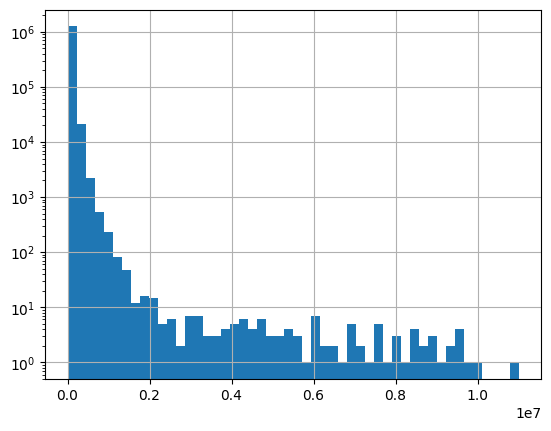

In [ ]:
X_train.annual_income.hist(bins=50,log=True)

Observamos que `annual_income`es una variable totalmente asimétrica. Además, algo positivo que se desprende del histograma es que no hay sueldos anuales con un valor negativo (de lo contrario habría que revisar esos datos).

Consideramos una transformación logarítmica.

In [ ]:
for df in (X_train, X_val, X_test):
  df["annual_income_log"] = np.log10(df["annual_income"])
  df.drop(columns={"annual_income"},inplace=True)

<Axes: >

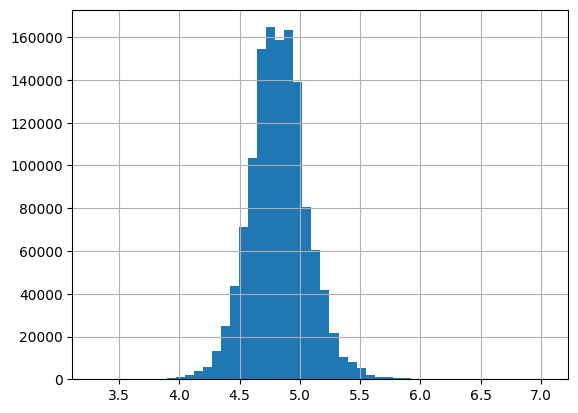

In [ ]:
X_train.annual_income_log.hist(bins=50)

Ahora `annual_income_log` es bastante más simétrica, centrada aproximadamente en 11.

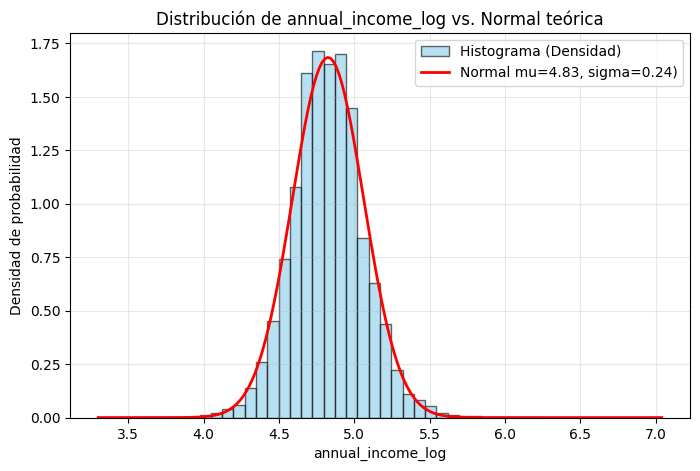

In [ ]:
# 1. Obtener media y desviación estándar de la variable
mu = X_train['annual_income_log'].mean()
sigma = X_train['annual_income_log'].std()

# 2. Crear rango de valores en X para la curva normal
x = np.linspace(X_train['annual_income_log'].min(), X_train['annual_income_log'].max(), 200)

# 3. Calcular la función de densidad de probabilidad (PDF) teórica
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)

# 4. Graficar
plt.figure(figsize=(8, 5))

# Histograma normalizado (área = 1)
plt.hist(X_train['annual_income_log'], bins=50, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Histograma (Densidad)')

# Curva normal teórica
plt.plot(x, pdf, color='red', linewidth=2, label=f'Normal mu={mu:.2f}, sigma={sigma:.2f})')

plt.title('Distribución de annual_income_log vs. Normal teórica')
plt.xlabel('annual_income_log')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Observar que la distribución normal $N(\mu = 4.83,\sigma = 0.24)$ aproxima bastante bien la distrubución de la variable `annual_income_log`.

Importante recordar que $\text{annual_income_log}=log_{10}(\text{annual_income})$

,n,tasa_default,mediana_log
veintil,,,
"(3.3000000000000003, 4.459]",64331,0.162348,4.380211
"(4.459, 4.544]",79080,0.158371,4.505150
"(4.544, 4.602]",78628,0.152465,4.591065
"(4.602, 4.633]",37036,0.152743,4.623249
"(4.633, 4.676]",61876,0.150495,4.653213
"(4.676, 4.699]",72479,0.146360,4.698970
"(4.699, 4.74]",81649,0.143884,4.732394
"(4.74, 4.771]",39197,0.136796,4.755875
"(4.771, 4.792]",70996,0.142487,4.778151


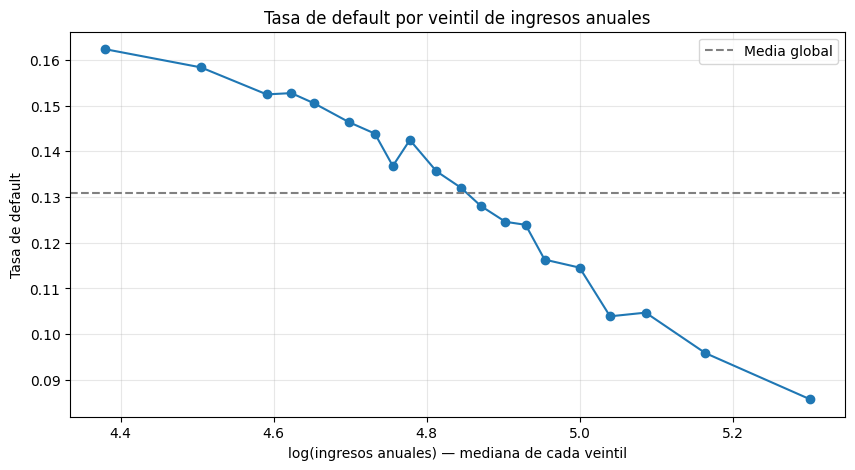

In [ ]:
veintil = pd.qcut(X_train["annual_income_log"], q=20, duplicates="drop")

tabla_ingresos = (
    pd.DataFrame({"veintil": veintil, "y": y_train, "x": X_train["annual_income_log"]})
    .groupby("veintil", observed=True)
    .agg(n=("y", "size"), tasa_default=("y", "mean"), mediana_log=("x", "median"))
)
display(tabla_ingresos)

plt.figure(figsize=(10, 5))
plt.plot(tabla_ingresos["mediana_log"], tabla_ingresos["tasa_default"], "o-")
plt.axhline(y_train.mean(), color="grey", linestyle="--", label="Media global")
plt.xlabel("log(ingresos anuales) — mediana de cada veintil")
plt.ylabel("Tasa de default")
plt.title("Tasa de default por veintil de ingresos anuales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Observamos que a medida que el aumenta el logaritmo del salario, la tasa de default disminuye, siendo esta relación aproximadamente lineal. Además, observamos que en los 5 primeros ventiles la tasa de default es superior al 15%, dos puntos porcentuales por encima de la tasa global. Luego podemos considerarlos como grupos de alto riesgo.

<Axes: ylabel='annual_income_log'>

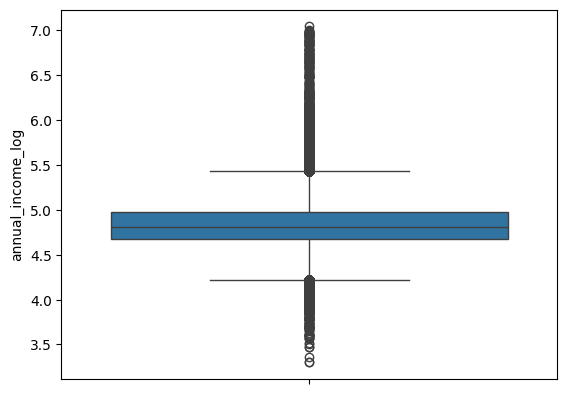

In [ ]:
sns.boxplot(y=X_train.annual_income_log)

En este caso observamos bastantes outliers.

Dado que la distrubición ahora es simétrica, veamos que ocurre en las colas de la distribución.

In [ ]:
n_left=(X_train.annual_income_log<X_train.annual_income_log.quantile(0.05)).sum()
default_left=y_train[X_train.annual_income_log<X_train.annual_income_log.quantile(0.05)].mean()
n_right=(X_train.annual_income_log>X_train.annual_income_log.quantile(0.95)).sum()
default_right=y_train[X_train.annual_income_log>X_train.annual_income_log.quantile(0.95)].mean()

print(f'En el cuantil {0.05} hay {n_left} observaciones y la tasa de default es {default_left}')
print(f'En el cuantil {0.95} hay {n_right} observaciones y la tasa de default es {default_right}')


En el cuantil 0.05 hay 63720 observaciones y la tasa de default es 0.16277463904582548
En el cuantil 0.95 hay 64038 observaciones y la tasa de default es 0.08576157906243168


Observamo que en la cola inferior (logaritmo de los ingresos mensuales menor al percentil 0.05) la tasa de defautl es el doble que en la cola superior de la distrubución (logaritmo de los ingresos mensuales mayor al percentil 0.95). Esta información será relevante para los modelos, pues tiene el doble de riesgo un prestamo concedido a un individuo situado en el rango más bajo de sueldo mensual que el concedido a un individuo del rango más alto.

#### addr_state & region_code

A continuación, se estudian las variables `addr_state` y `region_code`.

In [ ]:
X_train.addr_state.value_counts()

,count
addr_state,
CA,179638
NY,107441
TX,105430
FL,92122
IL,52000
NJ,47576
PA,43537
OH,42482
GA,42390


In [ ]:
len(X_train.addr_state.value_counts())

51

Observamos que todos los estados están correctamente formateados con su abreviatura de dos letras. Además, disponemos de datos en los 51 estados (50 + 1), teniendo en cuenta que la lista incluye DC, el Distrito de Columbia, donde está Washington D. C.

Algo que llama la atención son los 8 registros en Iowa (IA) frente a los casi 2.000 de Dakota del Norte (ND) que es un estado con menos de la mitad de población. Esto puede ser debido a que **durante la mayor parte de su historia, Lending Club no podía operar en Iowa por la regulación estatal de préstamos**.

In [ ]:
y_train[X_train.addr_state=="IA"]

,y
2037189,0
2035037,0
2037299,0
2035148,0
2037385,0
1610070,1
2037270,0
2037515,1


Uno de los problemas que podrían surgir a la hora de modelar es que default se vuelva determinista en Iowa al haber tan pocas observaciones en este grupo. Sin embargo, comprobamos que esto no ocurre, luego no es algo de lo que haya que preocuparse.

A continuación creamos un mapa de EE.UU donde se muestre la tasa de default por estado junto con un formato de mapa de calor.

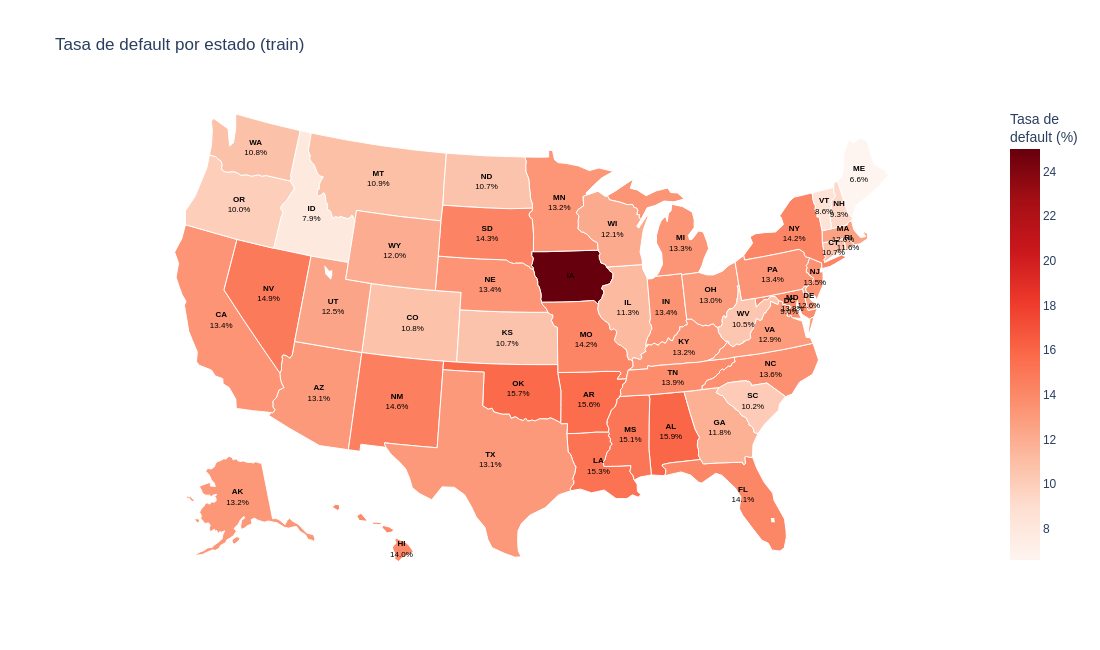

In [6]:
import plotly.graph_objects as go

# Tasa de default por estado (train)
tasa_estado = (
    y_train.groupby(X_train["addr_state"])
    .agg(n="size", tasa_default="mean")
    .reset_index()
)

# Etiqueta: abreviatura + tasa (solo abreviatura si hay pocos préstamos)
MIN_N = 500
fiables = tasa_estado["n"] >= MIN_N
tasa_estado["texto"] = tasa_estado["addr_state"].where(
    ~fiables,
    "<b>" + tasa_estado["addr_state"] + "</b><br>" + (tasa_estado["tasa_default"] * 100).round(1).astype(str) + "%",
)

fig = go.Figure()

# Capa de color (mapa de calor por estado)
fig.add_trace(go.Choropleth(
    locations=tasa_estado["addr_state"],
    locationmode="USA-states",
    z=tasa_estado["tasa_default"] * 100,
    colorscale="Reds",
    colorbar_title="Tasa de<br>default (%)",
    customdata=tasa_estado[["n"]],
    hovertemplate="<b>%{location}</b><br>Tasa de default: %{z:.2f}%<br>Préstamos: %{customdata[0]:,}<extra></extra>",
    marker_line_color="white",
))

# Capa de texto: abreviatura y tasa de cada estado
fig.add_trace(go.Scattergeo(
    locations=tasa_estado["addr_state"],
    locationmode="USA-states",
    text=tasa_estado["texto"],
    mode="text",
    textfont=dict(size=8, color="black"),
    hoverinfo="skip",
))

fig.update_layout(
    title_text="Tasa de default por estado (train)",
    geo=dict(scope="usa", projection_type="albers usa"),
    width=1100, height=650,
)
fig.show("png")

Observamos como la tasa de default varía en función del estado. Muchos estados con un número similar de préstamos presentan diferencias considerables en cuanto a tasa de impago.

Además, Iowa destaca por ser el estado con mayor tasa de default.Sin embargo, como comentabamos anteriormente, esto es debido a que solo hay registro de 8 préstamos en este estado y 2 resultarion en impago. EL bajo número de observaciones no permite hacer inferencia sobre la tasa de default en este grupo.

Continuamos analizando `region_code`.

In [ ]:
X_train.region_code.value_counts()

,count
region_code,
9,230360
3,177121
1,154592
7,140652
2,126878
0,115600
4,108950
8,95791
6,86924


`region_code` es el primer dígito del código postal (ZIP code) del prestatario.
En EE. UU., el servicio postal divide el país en 10 grandes zonas, numeradas del 0 al 9 de este a oeste, y cada estado pertenece a una de ellas:

| `region_code` | Estados |
|---|---|
| 0 | CT, MA, ME, NH, NJ, RI, VT |
| 1 | DE, NY, PA |
| 2 | DC, MD, NC, SC, VA, WV |
| 3 | AL, FL, GA, MS, TN |
| 4 | IN, KY, MI, OH |
| 5 | IA, MN, MT, ND, SD, WI |
| 6 | IL, KS, MO, NE |
| 7 | AR, LA, OK, TX |
| 8 | AZ, CO, ID, NM, NV, UT, WY |
| 9 | AK, CA, HI, OR, WA |


Por tanto, esta variable es simplemente una agregación de la variable `addr_state` en 10 grupos.

In [ ]:
# Zona postal (primer dígito del ZIP code) de cada estado
REGION_POR_ESTADO = {
    **dict.fromkeys(["CT", "MA", "ME", "NH", "NJ", "RI", "VT"], 0),
    **dict.fromkeys(["DE", "NY", "PA"], 1),
    **dict.fromkeys(["DC", "MD", "NC", "SC", "VA", "WV"], 2),
    **dict.fromkeys(["AL", "FL", "GA", "MS", "TN"], 3),
    **dict.fromkeys(["IN", "KY", "MI", "OH"], 4),
    **dict.fromkeys(["IA", "MN", "MT", "ND", "SD", "WI"], 5),
    **dict.fromkeys(["IL", "KS", "MO", "NE"], 6),
    **dict.fromkeys(["AR", "LA", "OK", "TX"], 7),
    **dict.fromkeys(["AZ", "CO", "ID", "NM", "NV", "UT", "WY"], 8),
    **dict.fromkeys(["AK", "CA", "HI", "OR", "WA"], 9),
}

region_esperada = X_train["addr_state"].map(REGION_POR_ESTADO)
incoherentes = X_train["region_code"].astype(int) != region_esperada

print(f"Estados sin zona asignada: {X_train.loc[region_esperada.isna(), 'addr_state'].unique()}")
print(f"Filas con estado y zona postal incoherentes: {incoherentes.sum():,}")
print(X_train.loc[incoherentes, ["addr_state", "region_code"]].value_counts().head(20))

Estados sin zona asignada: []
Filas con estado y zona postal incoherentes: 1,551
addr_state  region_code
NY          0              126
NE          1               41
FL          2               28
NJ          1               25
CA          8               25
AR          8               24
CO          9               23
TN          7               22
MA          2               22
IL          4               22
            5               20
NY          3               17
CA          6               16
NV          1               16
NC          1               15
NM          1               15
TX          3               14
FL          9               14
AR          9               14
CO          0               13
Name: count, dtype: int64


Observamos que 1.551 observaciones son incoherentes en cuanto al código postal asociado al estado.

Para solucionarlo, asumimos que el dato correcto es el registrado en `addr_state` y le asociamos su correspondiente `region_code` según indica la tabla.

Observar que esto no se podría hacer al contrario, pues no hay forma determinista de saber el estado a partir del código postal.


In [ ]:
for df in (X_train, X_val, X_test):
    df["region_code"] = df["addr_state"].map(REGION_POR_ESTADO)

In [ ]:
X_train.region_code=X_train.region_code.astype('object')

De todas formas, todavía hay que valorar si incluir la variable `region_code` en los modelos es útil. Como comentábamos anteriormente, esta variable simplemente agrupa los estados en 10 grupos basándose exclusivamente en el primer número de su código postal, lo cual no tiene por qué guardar relación con la tasa de default y añadirla en los modelos probablemente introduzca ruido innecesario.

#### loan_purpose

Estudiamos ahora la variable `loan_purpose`.

In [ ]:
X_train.loan_purpose.value_counts()

,count
loan_purpose,
debt_consolidation,723621
credit_card,296755
home_improvement,84036
other,79312
major_purchase,28853
medical,15226
small_business,14151
car,13795
vacation,8775


Observamos que esta variable ya viene limpia. Veamos ahora cómo se distrubuye default en cada una de las categorías.

In [ ]:
tabla = y_train.groupby(X_train["loan_purpose"]).agg(n="size", tasa_default="mean")
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]
tabla["pct_cartera"] = tabla["n"] / tabla["n"].sum()

tabla.sort_values("tasa_default", ascending=False).style.format({
    "n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}", "pct_cartera": "{:.2%}",
})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup,pct_cartera
loan_purpose,,,,,,
educational,258,23.26%,5.16%,18.10%,28.41%,0.02%
small_business,"14,151",20.34%,0.66%,19.67%,21.00%,1.10%
renewable_energy,826,17.68%,2.60%,15.07%,20.28%,0.06%
moving,"8,632",15.52%,0.76%,14.76%,16.29%,0.67%
debt_consolidation,"723,621",14.16%,0.08%,14.08%,14.24%,56.37%
medical,"15,226",13.79%,0.55%,13.24%,14.34%,1.19%
other,"79,312",13.09%,0.23%,12.86%,13.33%,6.18%
house,"8,123",12.80%,0.73%,12.08%,13.53%,0.63%
wedding,"1,422",12.80%,1.74%,11.06%,14.54%,0.11%


Observamos que la mayor tasa de default la tienen lo préstamos con prpósitos educativos. Sin embargo, este grupo también es el que menos observaciones presenta, con lo que es el grupo sobre el que mayor incertidumbre hay a cerca de su verdadera tasa de default.


En el otro extremo la menor tasa de default (~10%) la tienen préstamos cuya finalidad es pagar un coche. Este grupo presenta menos incertidumbre a cerca del valor real de la tasa de default al contener más de 10.000 observaciones.

Los préstamos con motivos relacionados a pequeños negocios representan un 1.10% de la cartera de train y muestran una tasa de default del 20.34%, lo cual nos permite considerarlos de alto riesgo.

Además, tenemos que el mayor porcentaje de la cartera son préstamos cuya finalidad es la consolidación de deuda. Estos presentan una tasa de default del 14.16%, un punto porcentual superior a la tasa de default de la cartera en train.

#### **num_inq_in_6mths y num_inq_in_12mths**

En cuanto a las variables `num_inq_in_6mths` y `num_inq_in_12mths`, dado que la primera está contenida en la segunda, debería ocurrir que `num_inq_in_12mths` $\geq$ `num_inq_in_6mths` para cada observación.

Comenzamos realizando esta comprobación.

In [ ]:
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    incoherentes = df["num_inq_in_12mths"] < df["num_inq_in_6mths"]
    print(f"{nombre}: {incoherentes.sum():,} observaciones con num_inq_in_12mths < num_inq_in_6mths "
          f"({incoherentes.mean():.3%})")

train: 1,767 observaciones con num_inq_in_12mths < num_inq_in_6mths (0.138%)
val: 565 observaciones con num_inq_in_12mths < num_inq_in_6mths (0.132%)
test: 632 observaciones con num_inq_in_12mths < num_inq_in_6mths (0.148%)


Observamos que hay 2964 (1,767+565+632) observaciones incoherentes. Dado que estas representan un porcentaje mínimo del dataset y no podemos conocer las causas reales de este fallo de registro, la decisión más sencilla para solucionarlo y que no genera consecuencias a la hora de la modelización es asumir que no hubo consultas entre los meses 7 y 12, es decir, todas fueron realizadas en los últimos 6 meses (asumimos que un dato más reciente tiene mayor porbabilidad de ser correcto).

Además, para reducir la correlación entre estas dos variables, generamos la variable `num_inq_in_7_12mths`= `num_inq_in_12mths` - `num_inq_in_6mths` que representa el número de consultas entre los meses 7 y 12. Tener en cuenta que para los valores incongruentes idetificados anteriormente se fija en $0$ su valor para esta variable.

In [ ]:
for df in (X_train, X_val, X_test):
    df["num_inq_in_7_12mths"] = (df["num_inq_in_12mths"] - df["num_inq_in_6mths"]).clip(lower=0)

print(f"Valores negativos tras la corrección: {(X_train['num_inq_in_7_12mths'] < 0).sum()}")

Valores negativos tras la corrección: 0


Así, podemos eliminar `num_inq_in_12mths` y quedarnos con `num_inq_in_6mths` y `num_inq_in_7_12mths`, las cuales miden el número de consultas en dos rangos de tiempo distintos y solucionan el problema de anidación de las variables originales.

In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns={"num_inq_in_12mths"},inplace=True)

#### **num_derogatory_pub_rec**

Realizamos ahora un estudio de la variable `num_derogatory_pub_rec`.

In [ ]:
X_train.num_derogatory_pub_rec.value_counts()

,count
num_derogatory_pub_rec,
0,1079244
1,173721
2,20053
3,6220
4,2242
5,1096
6,555
7,249
8,143


In [ ]:
X_train.num_derogatory_pub_rec.describe()

,num_derogatory_pub_rec
count,1.283785e+06
mean,1.998442e-01
std,5.735884e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,6.300000e+01


Observamos que esta variable tiene una cardinalidad moderadamente alta y la densidad de observaciones decae para valores superiores a 6, llegando a haber valores con una única observación.

Además, tenemos que se trata de una variable entera que no toma todos lo valores en su rango observado [0,63]. Por tanto, valoramos la opción de convertirla a categórica.

Para ello, debemos analizar primero cómo se distribuye la tasa de default a lo largo de los valores que toma `num_derogatory_pub_rec`.


In [ ]:
tabla = y_train.groupby(X_train["num_derogatory_pub_rec"]).agg(n="size", tasa_default="mean")
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]
tabla["pct_cartera"] = tabla["n"] / tabla["n"].sum()

tabla.sort_index().style.format({
    "n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}", "pct_cartera": "{:.2%}",
})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup,pct_cartera
num_derogatory_pub_rec,,,,,,
0,"1,079,244",12.58%,0.06%,12.51%,12.64%,84.07%
1,"173,721",15.50%,0.17%,15.33%,15.67%,13.53%
2,"20,053",17.97%,0.53%,17.44%,18.50%,1.56%
3,"6,220",16.61%,0.92%,15.68%,17.53%,0.48%
4,"2,242",18.24%,1.60%,16.64%,19.84%,0.17%
5,"1,096",16.06%,2.17%,13.88%,18.23%,0.09%
6,555,15.68%,3.02%,12.65%,18.70%,0.04%
7,249,17.67%,4.74%,12.93%,22.41%,0.02%
8,143,13.99%,5.68%,8.30%,19.67%,0.01%


Como era de esperar, tenemos valores para los cuales la tasa de default es del 100% y valores para los cuales es del 0%, lo cual supondría un problema para los modelos si considerásemos cada valor de `num_derogatory_pub_rec	` como categoría.

Basándonos en la tasa de default, número de observaciones e intervalos de confianza, consideramos adecuado crear las siguientes categorías:
* 0
* 1
* 2
* 3-5
* $\geq$ 6

donde las etiquetas representan el número de registros públicos negativos.

In [ ]:
CORTES_DEROG = [-0.1, 0, 1, 2, 5, np.inf]
ETIQUETAS_DEROG = ["0", "1", "2", "3-5", ">=6"]

for df in (X_train, X_val, X_test):
    df["num_derogatory_pub_rec_cat"] = pd.cut(df["num_derogatory_pub_rec"], bins=CORTES_DEROG,
                                              labels=ETIQUETAS_DEROG).astype("object")

print(f"Nulos: {X_train['num_derogatory_pub_rec_cat'].isna().sum()}")
y_train.groupby(X_train["num_derogatory_pub_rec_cat"]).agg(n="size", tasa_default="mean").reindex(ETIQUETAS_DEROG)

Nulos: 0


,n,tasa_default
num_derogatory_pub_rec_cat,,
0,1079244,0.125773
1,173721,0.154973
2,20053,0.179724
3-5,9558,0.169282
>=6,1209,0.157982


#### **interest_rate**

Estudiamos ahora la variable `interes_rate`.

In [ ]:
X_train.interest_rate.describe()


,interest_rate
count,1.283785e+06
mean,1.305628e+01
std,4.792090e+00
min,5.310000e+00
25%,9.490000e+00
50%,1.262000e+01
75%,1.581000e+01
max,3.099000e+01


Tenemos que Lending Club ofrece tipos de interes de entre el 5.3% y el 31%, siendo el interés medio del 13%.

A continuación hacemos un análisis de default por ventiles de `interest_rate`(intervalos de la variable que incluyen el 5% de la muestra) y calculamos su IV (Information Value). Más adelante en el notebook se analizará el IV del resto de variables de originación.

Information Value de interest_rate: 0.459


,n,tasa_default,mediana,woe
tramo,,,,
"(-inf, 6.46]","64,205",1.91%,5.32,2.043
"(6.46, 7.26]","67,739",3.46%,6.97,1.435
"(7.26, 7.9]","65,671",5.01%,7.66,1.050
"(7.9, 8.46]","62,378",5.74%,8.18,0.906
"(8.46, 9.49]","65,445",7.70%,9.17,0.591
"(9.49, 10.33]","61,086",7.47%,9.93,0.623
"(10.33, 10.91]","64,313",7.36%,10.49,0.640
"(10.91, 11.47]","64,966",10.19%,11.06,0.284
"(11.47, 11.99]","79,970",10.80%,11.67,0.218


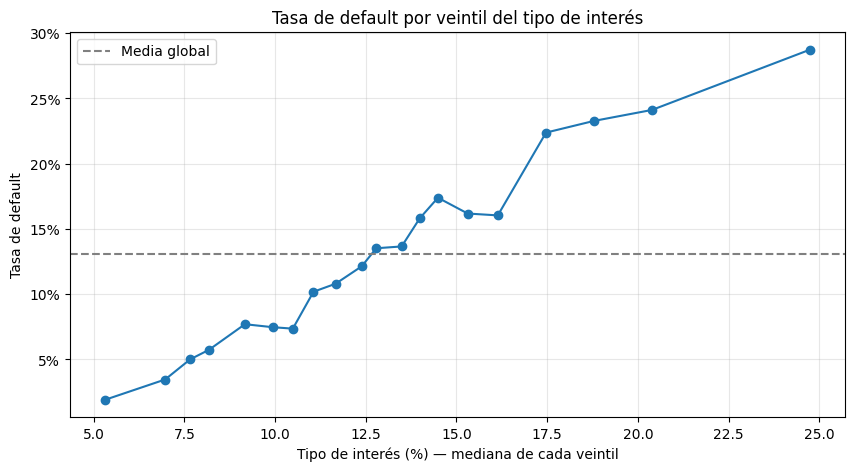

In [ ]:
import matplotlib.pyplot as plt

def bordes_cuantiles(x, q=20):
    """Bordes de los tramos por cuantiles, calculados con train y abiertos en los extremos."""
    _, bordes = pd.qcut(x, q=q, duplicates="drop", retbins=True)
    bordes[0], bordes[-1] = -np.inf, np.inf
    return bordes

def tabla_tramos(x, y, bordes, suavizado=0.5):
    """Tasa de default, WoE e IV por tramo."""
    tramos = pd.cut(x, bins=bordes)
    t = (pd.DataFrame({"tramo": tramos, "y": y, "x": x})
         .groupby("tramo", observed=True)
         .agg(n=("y", "size"), malos=("y", "sum"), mediana=("x", "median")))
    t["buenos"] = t["n"] - t["malos"]
    t["tasa_default"] = t["malos"] / t["n"]
    pct_malos = (t["malos"] + suavizado) / (t["malos"] + suavizado).sum()
    pct_buenos = (t["buenos"] + suavizado) / (t["buenos"] + suavizado).sum()
    t["woe"] = np.log(pct_buenos / pct_malos)
    iv = ((pct_buenos - pct_malos) * t["woe"]).sum()
    return t, iv

BORDES_INTERES = bordes_cuantiles(X_train["interest_rate"])
tabla_interes, iv_interes = tabla_tramos(X_train["interest_rate"], y_train, BORDES_INTERES)

print(f"Information Value de interest_rate: {iv_interes:.3f}")
display(tabla_interes[["n", "tasa_default", "mediana", "woe"]].style.format(
    {"n": "{:,}", "tasa_default": "{:.2%}", "mediana": "{:.2f}", "woe": "{:.3f}"}))

plt.figure(figsize=(10, 5))
plt.plot(tabla_interes["mediana"], tabla_interes["tasa_default"], "o-")
plt.axhline(y_train.mean(), color="grey", linestyle="--", label="Media global")
plt.xlabel("Tipo de interés (%) — mediana de cada veintil")
plt.ylabel("Tasa de default")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.title("Tasa de default por veintil del tipo de interés")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Observamos que la relación entre el tipo de interés ofrecido y la tasa de default es bastante monótona. A mayor interés mayor default.

Además, obtenemos un IV de 0.46, con lo que la variable `interest_rate` posee un gran poder predictivo. Sin embargo, hay que tener en cuenta que esto podría suponer un problema de data leakage, pues es posible que Lending Club se base en `grade` para determinar `interest_rate` en mayor o menor medida.

Comprobamos esta última objeción calculando la proporción de la varianza de `interest_rate` explicada por `grade` mediante el estimador $\eta^2$(empleado como medida descriptiva del tamaño del efecto de `grade` sobre `interest_rate` dentro de la muestra de train). Además, a este análisis se añade la variable `issue_date_year`, pudiendo así estudiar el efecto de la interacción del año de emisión del préstamo y el grade sobre el tipo de interés.

In [ ]:
def eta_cuadrado(categorica, numerica):
    """Proporción de la varianza de la numérica explicada por las categorías."""
    mask = numerica.notna()
    categorica, numerica = categorica[mask], numerica[mask]
    media_global = numerica.mean()
    media_grupo = numerica.groupby(categorica).transform("mean")
    return ((media_grupo - media_global) ** 2).sum() / ((numerica - media_global) ** 2).sum()

# 1) ¿Cuánta variación del tipo de interés hay dentro de cada sub-grade y año?
dentro = X_train.groupby(["issue_date_year", "grade"])["interest_rate"].agg(["count", "nunique", "std"])
print(f"Combinaciones año-subgrade con un único tipo de interés: {(dentro['nunique'] == 1).mean():.1%}")

display(dentro.head(15))

# 2) ¿Qué parte de la varianza del tipo de interés explican el sub-grade, y el sub-grade junto con el año?
print(f"η² (subgrade → tipo de interés):        {eta_cuadrado(X_train['grade'].astype(str), X_train['interest_rate']):.3f}")
grupo = X_train["issue_date_year"].astype(str) + "_" + X_train["grade"].astype(str)
print(f"η² (subgrade + año → tipo de interés):  {eta_cuadrado(grupo, X_train['interest_rate']):.3f}")

Combinaciones año-subgrade con un único tipo de interés: 14.8%


count  nunique  std
issue_date_year grade                     
2007            A1         1        1  NaN
                A2        15        1  0.0
                A3         6        1  0.0
                A4        11        1  0.0
                A5         6        1  0.0
                B1         8        1  0.0
                B2         9        1  0.0
                B3        11        1  0.0
                B4         8        1  0.0
                B5        12        1  0.0
                C1        14        1  0.0
                C2        16        1  0.0
                C3        18        1  0.0
                C4        16        1  0.0
                C5        13        1  0.0

η² (subgrade → tipo de interés):        0.955
η² (subgrade + año → tipo de interés):  0.992


Observamos que el 15% de las combinaciones año-subgrade son deterministas en cuanto al tipo de interes ofrecido. Además, un $\eta^2= 0.955$ para `interest_rate` respecto de `grade` y $\eta^2= 0.992$ respecto de la combinación de `grade` y `issue_date_year` apuntan a que el tipo de interés está prácticamente determinado por `grade`, variable prohibida para el reto.

Dado que en el reto no se prohíbe su uso y hemos visto su gran potencial predictivo optaremos por incluirla en los modelos. Sin embargo, **hay que destacar que en un contexto real, llegar a esta variable exigiría un trabajo previo, el cual incluiría análisis de variables de originación y modelado.**

#### num_30+_delinq_in_2yrs




Analizamos ahora la variable `num_30+_delinq_in_2yrs`, la cual mide el número de retrasos de más de 30 días en los últimos 2 años.

Observamos que el número de retrasos abarca desde 0 hasta 42.

In [ ]:
X_train["num_30+_delinq_in_2yrs"].describe()

,num_30+_delinq_in_2yrs
count,1.283785e+06
mean,3.102030e-01
std,8.728740e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,4.200000e+01


Observamos que esta variable toma valores desde 0 hasta 42, siendo 0 el percentil 75, con lo que al menos el 75% de train no tiene retrasos de más de treinta días en los últimos dos años.

In [ ]:
X_train["num_30+_delinq_in_2yrs"].value_counts().sort_index()

,count
num_30+_delinq_in_2yrs,
0,1042327
1,161077
2,46539
3,16778
4,7644
5,3832
6,2185
7,1194
8,709


Observamos que el número de préstamos decrece a medida que crece el valor de `num_30+_delinq_in_2yrs`, hasta encontrarnos con valores extremos que solo presentan un préstamo. Para realizar un análisis de cómo se comporta la tasa de impago en función de esta variable primero agrupamos todos los préstamos que presenten un valor superior a 6 en `num_30+_delinq_in_2yrs`.

Préstamos con num_30+_delinq_in_2yrs > 6: 3,403 (valor máximo: 42)


,n,tasa_default,ic95_±,ic95_inf,ic95_sup,pct_cartera
num_30+_delinq_in_2yrs,,,,,,
0,"1,042,327",12.77%,0.06%,12.71%,12.83%,81.19%
1,"161,077",14.06%,0.17%,13.89%,14.23%,12.55%
2,"46,539",14.96%,0.32%,14.64%,15.28%,3.63%
3,"16,778",15.91%,0.55%,15.36%,16.47%,1.31%
4,"7,644",15.69%,0.82%,14.87%,16.50%,0.60%
5,"3,832",16.21%,1.17%,15.04%,17.37%,0.30%
6,"2,185",15.38%,1.51%,13.86%,16.89%,0.17%
>6,"3,403",16.02%,1.23%,14.78%,17.25%,0.27%


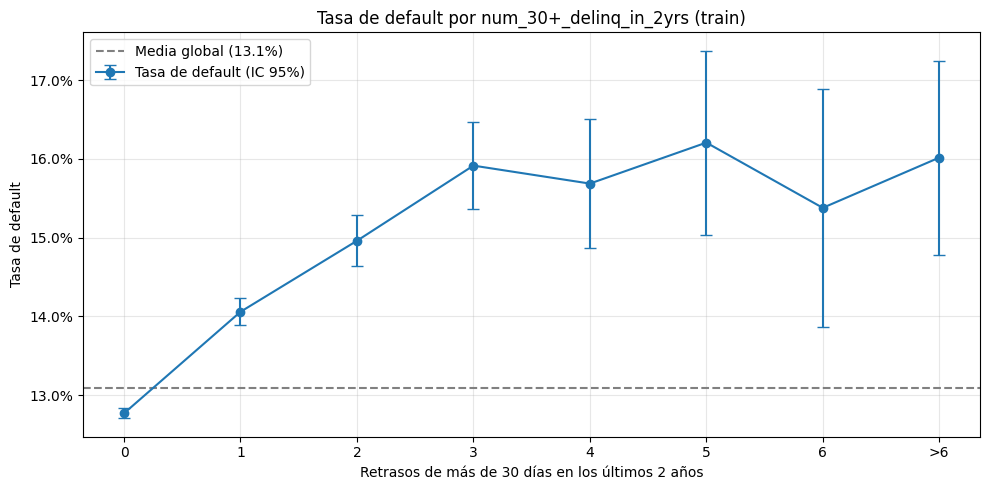

In [ ]:
# ===== num_30+_delinq_in_2yrs: tasa de impago por valor (valores > 6 agrupados) =====
UMBRAL_DELINQ_2Y = 6

v = X_train["num_30+_delinq_in_2yrs"]
grupo = v.astype(int).astype(str).where(v <= UMBRAL_DELINQ_2Y, f">{UMBRAL_DELINQ_2Y}")
orden = [str(i) for i in range(UMBRAL_DELINQ_2Y + 1)] + [f">{UMBRAL_DELINQ_2Y}"]

tabla = y_train.groupby(grupo).agg(n="size", tasa_default="mean").reindex(orden)
tabla["ic95_±"] = 1.96 * np.sqrt(tabla["tasa_default"] * (1 - tabla["tasa_default"]) / tabla["n"])
tabla["ic95_inf"] = tabla["tasa_default"] - tabla["ic95_±"]
tabla["ic95_sup"] = tabla["tasa_default"] + tabla["ic95_±"]
tabla["pct_cartera"] = tabla["n"] / tabla["n"].sum()

print(f"Préstamos con num_30+_delinq_in_2yrs > {UMBRAL_DELINQ_2Y}: {(v > UMBRAL_DELINQ_2Y).sum():,} "
      f"(valor máximo: {v.max():.0f})")
display(tabla.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                            "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}", "pct_cartera": "{:.2%}"}))

# ----- Gráfico -----
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(range(len(tabla)), tabla["tasa_default"], yerr=tabla["ic95_±"],
            fmt="-o", capsize=4, label="Tasa de default (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Media global ({y_train.mean():.1%})")
ax.set_xticks(range(len(tabla)))
ax.set_xticklabels(tabla.index)
ax.set_xlabel("Retrasos de más de 30 días en los últimos 2 años")
ax.set_ylabel("Tasa de default")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.set_title("Tasa de default por num_30+_delinq_in_2yrs (train)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Observamos que , entre 0 y 3 retrasos, la tasa de impago crece con los retrasos. A partir de 3 retrasos, la tasa de default no sigue una tendencia clara. Sin embargo, debemos tener en cuenta que esta es la cola de la distrubución de `num_30+_delinq_in_2yrs	` donde menos préstamos se acumulan y, por tanto, donde mayor incertidumbre hay sobre la tasa de impago real.

#### funded_amnt

A continuación, analizamos la variable `funded_amnt`, la cual mide el importe del préstamo concedido.

<Axes: >

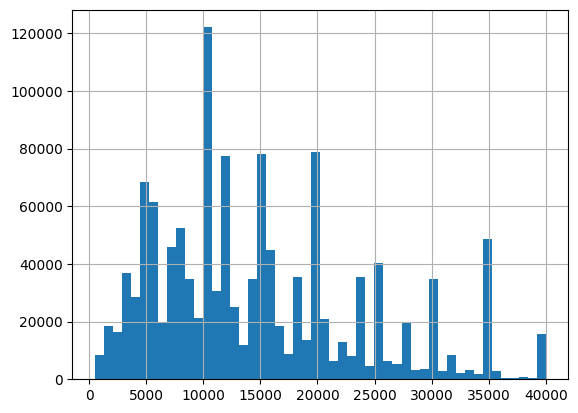

In [ ]:
X_train.funded_amnt.hist(bins=50,log=False)

Observamos en primer lugar que se trata de una variable bastante asimétrica.

In [ ]:
X_train.funded_amnt.describe()

,funded_amnt
count,1.283785e+06
mean,1.477764e+04
std,9.034479e+03
min,5.000000e+02
25%,8.000000e+03
50%,1.225000e+04
75%,2.000000e+04
max,4.000000e+04


En la cartera de train tenemos préstamos con importes desde 500\$ hasta 40.000\$, un rango bastante extenso. Además, el préstamo mediano es de 12.250\$.

Para analizar la tasa de impago, dividimos el importe concedido en ventiles y calculamos la tasa de impago en cada uno de ellos.

Número de grupos: 19 (menos de 20 si hay importes muy repetidos)


,n,tasa_default,mediana,ic95_±,ic95_inf,ic95_sup
ventil,,,,,,
"(499.999, 3200.0]","65,797",9.67%,"2,400",0.23%,9.45%,9.90%
"(3200.0, 5000.0]","108,372",10.86%,"4,800",0.19%,10.68%,11.05%
"(5000.0, 5775.0]","18,405",11.99%,"5,500",0.47%,11.52%,12.46%
"(5775.0, 6700.0]","64,585",10.95%,"6,000",0.24%,10.71%,11.19%
"(6700.0, 8000.0]","96,062",11.80%,"7,700",0.20%,11.60%,12.00%
"(8000.0, 9000.0]","36,653",12.20%,"8,800",0.34%,11.87%,12.54%
"(9000.0, 10000.0]","130,970",11.75%,"10,000",0.17%,11.57%,11.92%
"(10000.0, 12000.0]","119,023",13.95%,"12,000",0.20%,13.75%,14.15%
"(12000.0, 12250.0]","2,537",22.19%,"12,175",1.62%,20.57%,23.81%


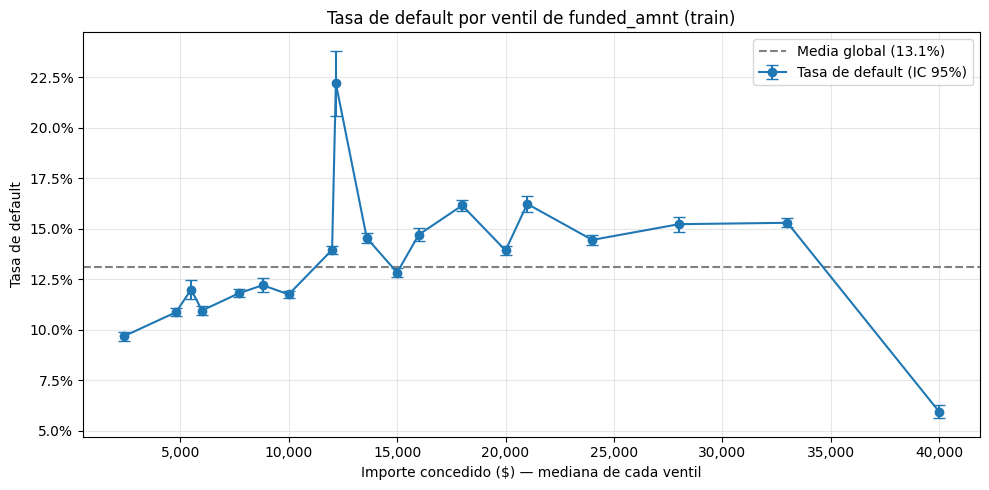

In [ ]:
# ===== funded_amnt: tasa de impago por ventiles del importe concedido =====
ventil = pd.qcut(X_train["funded_amnt"], q=20, duplicates="drop")

tabla_importe = (
    pd.DataFrame({"ventil": ventil, "y": y_train, "x": X_train["funded_amnt"]})
    .groupby("ventil", observed=True)
    .agg(n=("y", "size"), tasa_default=("y", "mean"), mediana=("x", "median"))
)
tabla_importe["ic95_±"] = 1.96 * np.sqrt(tabla_importe["tasa_default"] * (1 - tabla_importe["tasa_default"])
                                         / tabla_importe["n"])
tabla_importe["ic95_inf"] = tabla_importe["tasa_default"] - tabla_importe["ic95_±"]
tabla_importe["ic95_sup"] = tabla_importe["tasa_default"] + tabla_importe["ic95_±"]

print(f"Número de grupos: {len(tabla_importe)} (menos de 20 si hay importes muy repetidos)")
display(tabla_importe.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "mediana": "{:,.0f}",
                                    "ic95_±": "{:.2%}", "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"}))

# ----- Gráfico -----
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(tabla_importe["mediana"], tabla_importe["tasa_default"], yerr=tabla_importe["ic95_±"],
            fmt="-o", capsize=4, label="Tasa de default (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Media global ({y_train.mean():.1%})")
ax.set_xlabel("Importe concedido ($) — mediana de cada ventil")
ax.set_ylabel("Tasa de default")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.set_title("Tasa de default por ventil de funded_amnt (train)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Observamos que, para los préstamos de entre 500\$ y 22.000\$ la dinámica general de la tasa de default es crecer a medida que lo hace el importe concedido. Sin embargo, cabe destacar que este crecimiento no es lineal y presenta altibajos a lo largo de todo este rango, destacando un pico extremo de tasa de impago en el rango (12.000, 12.250]. Esta última dinámica resulta extraña, pues se trata de un rango de importes bastante estrecho y su tasa de impago es algo superior a 1.5 veces la de sus rangos vecinos, de manera que lo más probable es que esta surja de la interacción de `funded_amnt` con otra variable.

Para los préstamos de entre 22.000\$ y 35.000\$, el crecimiento de la tasa de impago se estabiliza, manteníendose por debajo del 16.22% obtenido en el rango (20.000, 22.000].

Finalmente, para los préstamos con importe concedido superior a 35.000\$, la tasa de impago cae considerablemente hasta aproximadamente el 6%. Así, los préstamos más altos de la cartera de train son los que menor riesgo de impago presentan.

#### home_ownership_status

Estudiamos ahora la variable `home_ownership_status`.



In [ ]:
X_train.home_ownership_status.value_counts()

,count
home_ownership_status,
MORTGAGE,618991
RENT,519485
OWN,144580
OTHER,729


Vemos que esta variable se divide en 4 categorías:
* **MORTGAGE**: vive en una vivienda de su propiedad con una hipoteca pendiente.
* **RENT**: vive de alquiler.
* **OWN**: vive en una vivienda de su propiedad ya pagada, sin hipoteca.
* **OTHER**: ninguna de las anteriores.

Veamos como se distribuye la tasa de impago en cada una de las categorías.

In [ ]:
tabla=( y_train
       .groupby(X_train.home_ownership_status)
       .agg(n="size",tasa_default="mean")
)
tabla["ic95_±"]=1.96*np.sqrt(  tabla["tasa_default"]*(1-tabla["tasa_default"])/tabla["n"])
tabla["ic95_inf"]=tabla["tasa_default"]-tabla["ic95_±"]
tabla["ic95_sup"]=tabla["tasa_default"]+tabla["ic95_±"]
tabla.style.format({"tasa_default":"{:.2%}","ic95_±":"{:.2%}","ic95_inf":"{:.2%}","ic95_sup":"{:.2%}"})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup
home_ownership_status,,,,,
MORTGAGE,618991,11.52%,0.08%,11.45%,11.60%
OTHER,729,8.23%,2.00%,6.24%,10.23%
OWN,144580,12.93%,0.17%,12.75%,13.10%
RENT,519485,15.01%,0.10%,14.92%,15.11%


Observamos que ningún intervalo de confianza se solapa, por tanto tenemos evidencia de diferencias en cuanto a tasa de impago entre las categorías.

La categoría OTHER es la que menos tasa de impago muestra. Una posible explicación, que no podemos comprobar con los datos disponibles, es que esta categoría esté formada en buena parte por prestatarios que viven con su familia y soportan una menor carga financiera que los prestatarios de el resto de categorías.

Por otro lado, la categoría que mayor tasa de impago muestra es RENT con un 15%.

#### loan_term_months

Realizamos un análisis de la variable `loan_term_months`.



In [ ]:
X_train.loan_term_months.value_counts()

,count
loan_term_months,
36,924058
60,359727


Observamos que en la cartera de train solo aparecen préstamos a plazos de 36 y 60 meses,  en una proporción aproximada de 3 a 1.

A continuación, estudiamos la tasa de impago en los dos tipos de plazos.

In [ ]:
tabla=(
    y_train.groupby(X_train.loan_term_months)
    .agg(n="size",tasa_default="mean")
)

tabla["ic95_±"]=1.96*np.sqrt(tabla["tasa_default"]*(1-tabla["tasa_default"])/tabla["n"])
tabla["ic95_inf"]=tabla["tasa_default"]-tabla["ic95_±"]
tabla["ic95_sup"]=tabla["tasa_default"]+tabla["ic95_±"]

tabla.style.format({"tasa_default":"{:.2%}","ic95_±":"{:.2%}","ic95_inf":"{:.2%}","ic95_sup":"{:.2%}"})

,n,tasa_default,ic95_±,ic95_inf,ic95_sup
loan_term_months,,,,,
36,924058,11.08%,0.06%,11.02%,11.15%
60,359727,18.26%,0.13%,18.13%,18.38%


Observamos una clara diferencia en cuanto a la tasa de impago, diferencia que es además significativa como indican los intervalos de confianza.

La tasa de impago en los préstamos a 60 meses es 8 puntos porcentuales superior a la encontrada en los prestamos a 36 meses. Una de las explicaciones es la siguiente: a mayor tiempo de vida de un préstamo, más tiempo hay para que se incurra en impago.  

De esta manera, los préstamos a plazos de tiempo más largos presentan un mayor riesgo.

#### issue_date_year

Estudiamos la variable `issue_date_year`

,n,tasa_default,ic95_±,ic95_inf,ic95_sup,pct_cartera,tasa_36m,tasa_60m
issue_date_year,,,,,,,,
2007,341,28.45%,4.79%,23.66%,33.23%,0.03%,28.45%,nan%
2008,"1,456",20.81%,2.09%,18.73%,22.90%,0.11%,20.81%,nan%
2009,"3,133",13.85%,1.21%,12.64%,15.06%,0.24%,13.85%,nan%
2010,"7,512",14.23%,0.79%,13.44%,15.02%,0.59%,11.23%,22.39%
2011,"13,041",15.24%,0.62%,14.63%,15.86%,1.02%,10.71%,23.58%
2012,"32,103",16.23%,0.40%,15.83%,16.63%,2.50%,13.62%,27.83%
2013,"80,760",15.57%,0.25%,15.32%,15.82%,6.29%,12.29%,25.18%
2014,"141,556",17.64%,0.20%,17.44%,17.84%,11.03%,13.70%,26.39%
2015,"252,777",18.33%,0.15%,18.18%,18.48%,19.69%,14.90%,25.39%


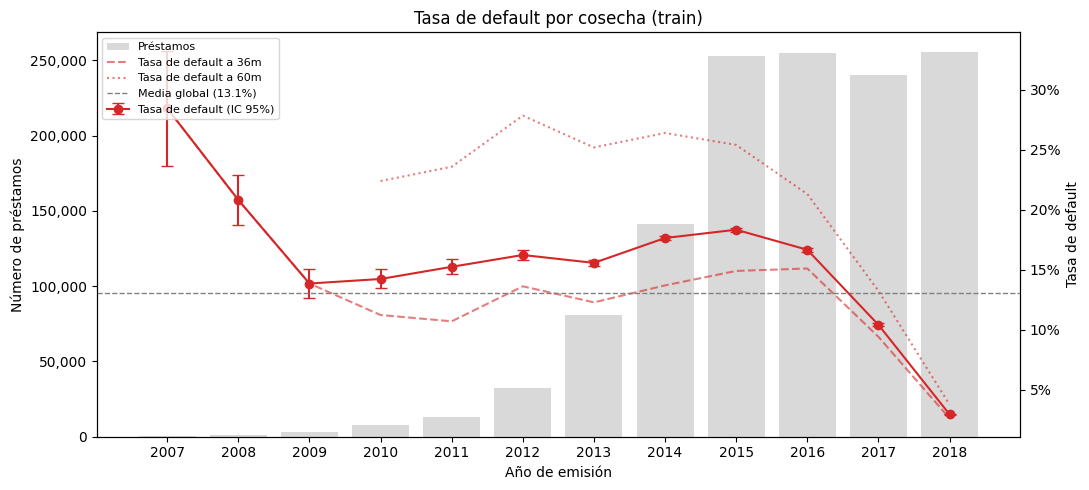

In [ ]:
# ===== Tasa de impago por cosecha (año de emisión) =====
año = X_train["issue_date_year"].astype(int)

tabla_cosecha = y_train.groupby(año).agg(n="size", tasa_default="mean")
tabla_cosecha["ic95_±"] = 1.96 * np.sqrt(tabla_cosecha["tasa_default"] * (1 - tabla_cosecha["tasa_default"])
                                         / tabla_cosecha["n"])
tabla_cosecha["ic95_inf"] = tabla_cosecha["tasa_default"] - tabla_cosecha["ic95_±"]
tabla_cosecha["ic95_sup"] = tabla_cosecha["tasa_default"] + tabla_cosecha["ic95_±"]
tabla_cosecha["pct_cartera"] = tabla_cosecha["n"] / tabla_cosecha["n"].sum()

# Tasa de impago por cosecha y plazo
por_plazo = (y_train.groupby([año, X_train["loan_term_months"].astype(int)]).mean()
             .unstack().add_prefix("tasa_").add_suffix("m"))
tabla_cosecha = tabla_cosecha.join(por_plazo)

display(tabla_cosecha.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "ic95_±": "{:.2%}",
                                    "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}", "pct_cartera": "{:.2%}",
                                    **{c: "{:.2%}" for c in por_plazo.columns}}))

# ----- Gráfico: número de préstamos (barras) y tasa de impago (líneas) por cosecha -----
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(tabla_cosecha.index, tabla_cosecha["n"], color="#d9d9d9", label="Préstamos")
ax1.set_xlabel("Año de emisión")
ax1.set_ylabel("Número de préstamos")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))

ax2 = ax1.twinx()
ax2.errorbar(tabla_cosecha.index, tabla_cosecha["tasa_default"], yerr=tabla_cosecha["ic95_±"],
             fmt="-o", capsize=4, color="tab:red", label="Tasa de default (IC 95%)")
for c, estilo in zip(por_plazo.columns, ["--", ":"]):
    ax2.plot(tabla_cosecha.index, tabla_cosecha[c], estilo, color="tab:red", alpha=0.6,
             label=f"Tasa de default a {c.split('_')[1]}")
ax2.axhline(y_train.mean(), color="grey", linestyle="--", lw=1, label=f"Media global ({y_train.mean():.1%})")
ax2.set_ylabel("Tasa de default")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

lineas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
etiquetas = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax2.legend(lineas, etiquetas, loc="upper left", fontsize=8)
ax1.set_xticks(tabla_cosecha.index)
plt.title("Tasa de default por cosecha (train)")
plt.tight_layout()
plt.show()

La tabla y el gráfico muestran la tasa de default observada en train por año de emisión (cosecha), con su intervalo de confianza al 95 %, desglosada por plazo, junto con el volumen de préstamos de cada año.

* **Volumen muy concentrado en las cosechas recientes.** El número de préstamos crece de forma sostenida hasta 2015 y se estabiliza en torno a 250.000 préstamos anuales: las cosechas 2015–2018 suponen casi el 80 % de train, mientras que 2007–2009 apenas llegan al 0,4 %.

* **2007–2008: tasas muy altas pero poco fiables.** Son las cosechas con mayor tasa de default (28,5 % y 20,8 %), coincidiendo con la crisis financiera y los primeros años de Lending Club, pero con muy pocos préstamos (341 y 1.456), de ahí sus amplios intervalos de confianza. Su peso en la cartera es despreciable.

* **2009–2016: tasa estable, entre el 14 % y el 18 %.** Es el periodo en el que los préstamos han tenido tiempo de completar su vida (o casi), por lo que la tasa observada se aproxima a la tasa de default real de cada cosecha. Se aprecia una ligera tendencia al alza hasta el máximo de 2015 (18,3 %).

* **El plazo multiplica el riesgo.** En todas las cosechas, los préstamos a 60 meses (disponibles desde 2010) tienen una tasa de default muy superior a los de 36 meses: entre un 21 % y un 28 % frente a un 11–15 % en el periodo estable. Esto confirma lo visto en el análisis de `loan_term_months`.

* **2017–2018: caída por censura, no por mejor calidad crediticia.** La tasa de default cae al 10,4 % en 2017 y al 3,0 % en 2018. Esta caída no indica que esos préstamos sean mejores: los datos se cortan en una fecha fija y los préstamos más recientes llevan poco tiempo vivos, de modo que muchos de los que acabarán impagando todavía no lo han hecho . La caída es más pronunciada en los préstamos a 60 meses, que son los que más vida les queda por delante.

**Implicaciones para la modelización:**
* El target de PD es, por tanto, el default **observado hasta la fecha de corte**, no el default a lo largo de toda la vida del préstamo.
* Dentro del reto esto no es un problema: train, validación y test proceden de una partición aleatoria del mismo periodo y tienen la misma mezcla de cosechas. En un uso real, en cambio, el modelo se aplicaría a préstamos nuevos con un año de emisión fuera del rango de entrenamiento y el efecto de la cosecha no sería extrapolable.

#### dept_paym_income_ratio


A continuación, analizamos la variable `dept_paym_income_ratio`, la cual mide el ratio de deuda-ingresos sin contar hipotecas ni el préstamo que da lugar al registro de cada una de las filas de nuestra matriz de datos. Por tanto, esta variable se calcula con la deuda que el prestatario ya tenía antes de la concesión del préstamo.

In [ ]:
X_train.dept_paym_income_ratio.describe()

,dept_paym_income_ratio
count,1.283785e+06
mean,1.809802e+01
std,8.427064e+00
min,0.000000e+00
25%,1.178000e+01
50%,1.761000e+01
75%,2.405000e+01
max,4.996000e+01


<Axes: >

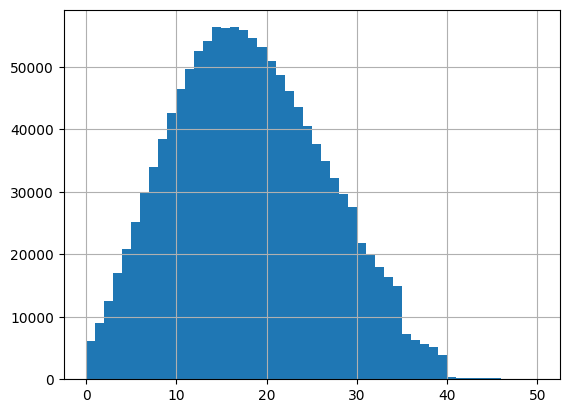

In [ ]:
X_train.dept_paym_income_ratio.hist(bins=50)

En primer lugar, los valores obtenidos en la tabla que describe aspectos básicos sobre la distribición de
`dept_paym_income_ratio` nos indican que esta viene registrada en porcentaje.

En segundo lugar, el histograma nos muetsra que se trata de una variable muy simétrica y con distribución aproximadamente normal.

Además tenemos que ningún préstamo supera un ratio deuda-ingresos del 50%, lo cual puede ser debido a políticas de admisión de Lending Club.

A continuación, estudiamos la tasa de impago por ventiles de esta variable como viene siendo habitual a lo largo del notebook.

Número de grupos: 20


,n,tasa_default,mediana,ic95_±,ic95_inf,ic95_sup
ventil,,,,,,
"(-0.001, 4.93]","64,200",9.83%,3.27,0.23%,9.60%,10.07%
"(4.93, 7.24]","64,300",9.76%,6.19,0.23%,9.53%,9.99%
"(7.24, 8.98]","64,184",10.01%,8.16,0.23%,9.78%,10.25%
"(8.98, 10.46]","64,104",10.50%,9.75,0.24%,10.26%,10.74%
"(10.46, 11.78]","64,523",10.82%,11.14,0.24%,10.58%,11.06%
"(11.78, 13.0]","63,947",11.00%,12.41,0.24%,10.76%,11.25%
"(13.0, 14.18]","64,285",11.44%,13.60,0.25%,11.20%,11.69%
"(14.18, 15.32]","64,235",11.58%,14.76,0.25%,11.33%,11.83%
"(15.32, 16.46]","64,238",12.28%,15.90,0.25%,12.03%,12.53%


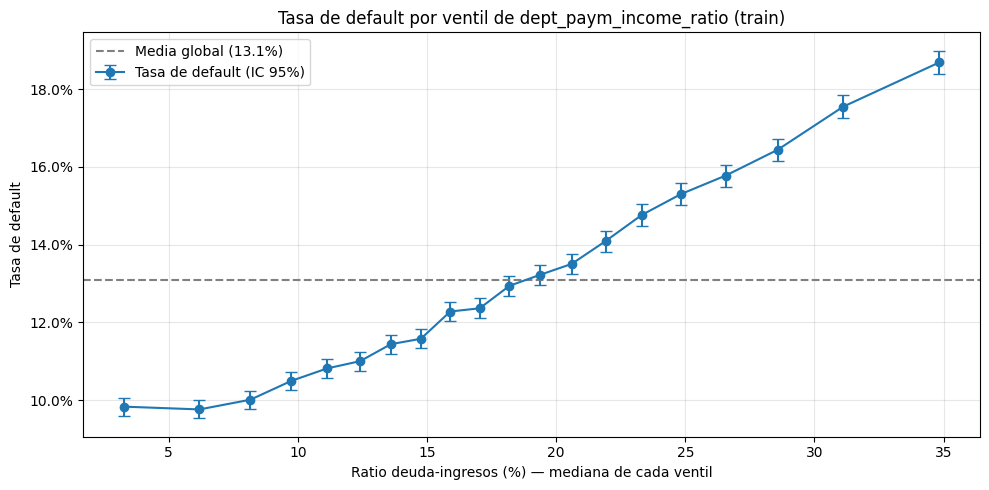

In [ ]:
# ===== dept_paym_income_ratio: tasa de impago por ventiles del ratio deuda-ingresos =====
dti= X_train["dept_paym_income_ratio"]
ventil = pd.qcut(dti, q=20, duplicates="drop")

tabla_dti = (
    pd.DataFrame({"ventil": ventil, "y": y_train, "x": dti})
    .groupby("ventil", observed=True)
    .agg(n=("y", "size"), tasa_default=("y", "mean"), mediana=("x", "median"))
)
tabla_dti["ic95_±"] = 1.96 * np.sqrt(tabla_dti["tasa_default"] * (1 - tabla_dti["tasa_default"]) / tabla_dti["n"])
tabla_dti["ic95_inf"] = tabla_dti["tasa_default"] - tabla_dti["ic95_±"]
tabla_dti["ic95_sup"] = tabla_dti["tasa_default"] + tabla_dti["ic95_±"]

print(f"Número de grupos: {len(tabla_dti)}")
display(tabla_dti.style.format({"n": "{:,}", "tasa_default": "{:.2%}", "mediana": "{:.2f}",
                                "ic95_±": "{:.2%}", "ic95_inf": "{:.2%}", "ic95_sup": "{:.2%}"}))

# ----- Gráfico -----
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(tabla_dti["mediana"], tabla_dti["tasa_default"], yerr=tabla_dti["ic95_±"],
            fmt="-o", capsize=4, label="Tasa de default (IC 95%)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label=f"Media global ({y_train.mean():.1%})")
ax.set_xlabel("Ratio deuda-ingresos (%) — mediana de cada ventil")
ax.set_ylabel("Tasa de default")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.set_title("Tasa de default por ventil de dept_paym_income_ratio (train)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En el gráfico observamos una relación clara entre la tasa de impago y el ratio deuda-ingresos: a mayor ratio, mayor tasa de impago.

Dicha relación es fuertemente lineal a partir del tercer ventil de `dept_paym_income_ratio`.


## **Análisis de multicolinealidad**

En primer lugar tomamos una muestra aleatoria de las filas de train de un tamaño suficiente para medir asociaciones entre variables a la vez que ahorramos espacio en memoria y tiempo de cálculo.

In [ ]:
muestra = X_train.sample(200_000, random_state=SEED)  # suficiente para medir asociaciones

Filas con datos del bloque: 119,066


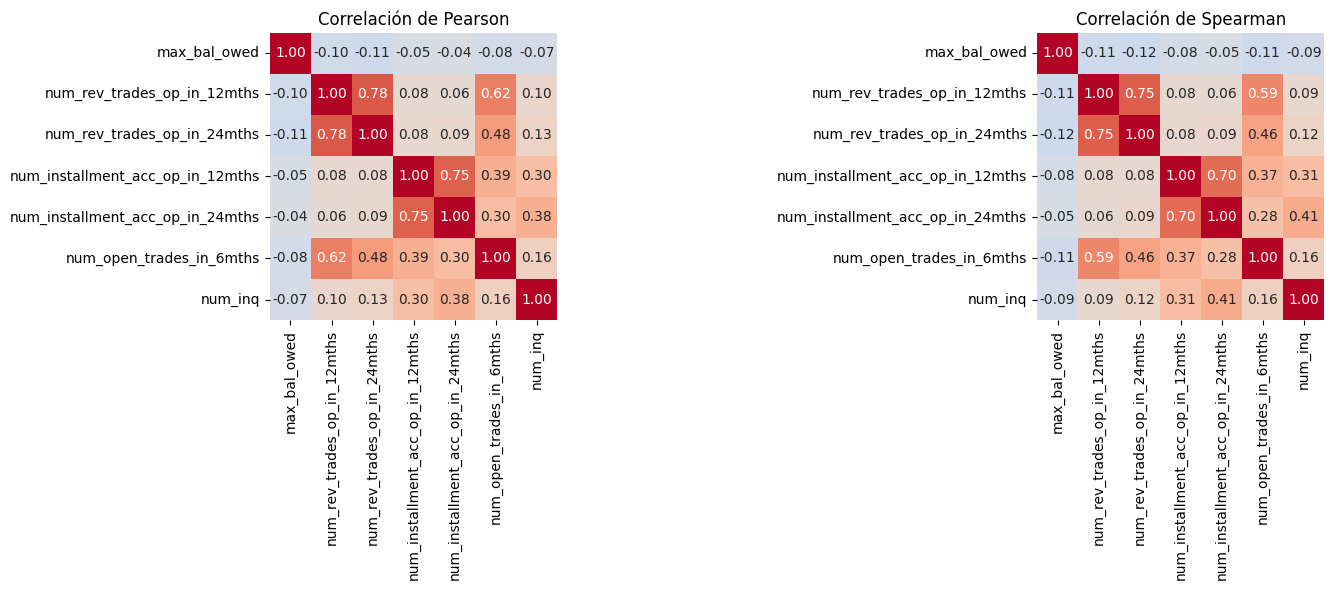

num_rev_trades_op_in_12mths         3.29
num_rev_trades_op_in_24mths         2.58
num_installment_acc_op_in_12mths    2.50
num_installment_acc_op_in_24mths    2.44
num_open_trades_in_6mths            2.00
num_inq                             1.19
max_bal_owed                        1.02
Name: VIF, dtype: float64
num_rev_trades_op_in_12mths > num_rev_trades_op_in_24mths: 0 filas incoherentes
num_installment_acc_op_in_12mths > num_installment_acc_op_in_24mths: 0 filas incoherentes


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

bloque_nulos_no_tratados = [
    "max_bal_owed",
    "num_rev_trades_op_in_12mths",
    "num_rev_trades_op_in_24mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "num_open_trades_in_6mths",
    "num_inq",
]
datos = muestra[bloque_nulos_no_tratados].dropna()
print(f"Filas con datos del bloque: {len(datos):,}")

# 1) Matrices de correlación: Pearson (lineal) y Spearman (por rangos, más robusta
#    para recuentos asimétricos y valores extremos)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(datos.corr(method=metodo), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

# 2) VIF: cuánto se infla la varianza de cada coeficiente por su relación con el resto
X_vif = add_constant(datos)
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=bloque_nulos_no_tratados, name="VIF",
).sort_values(ascending=False)
print(vif.round(2))

# 3) Coherencia de las variables anidadas: lo abierto en 12 meses no puede superar lo abierto en 24
for v12, v24 in [("num_rev_trades_op_in_12mths", "num_rev_trades_op_in_24mths"),
                 ("num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths")]:
    print(f"{v12} > {v24}: {(datos[v12] > datos[v24]).sum():,} filas incoherentes")

Aunque dentro de los rangos aceptables, `num_rev_trades_op_in_12mths` es la que mayor VIF muestra. Además está altamente correlada con `num_rev_trades_op_in_24mths`, por lo que decidimos quedarnos con esta y eliminar `num_rev_trades_op_in_12mths`.

Filas con datos del bloque: 119,066


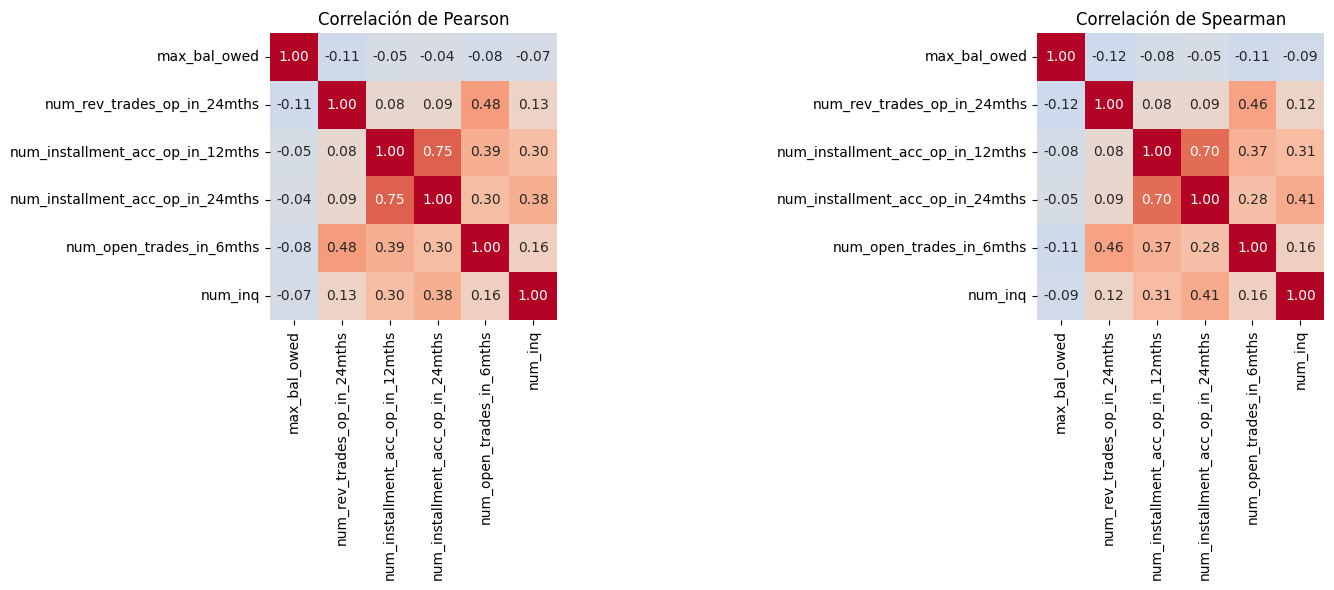

num_installment_acc_op_in_12mths    2.47
num_installment_acc_op_in_24mths    2.44
num_open_trades_in_6mths            1.55
num_rev_trades_op_in_24mths         1.35
num_inq                             1.19
max_bal_owed                        1.02
Name: VIF, dtype: float64


In [ ]:
bloque_nulos_no_tratados = [
    "max_bal_owed",
    "num_rev_trades_op_in_24mths",
    "num_installment_acc_op_in_12mths",
    "num_installment_acc_op_in_24mths",
    "num_open_trades_in_6mths",
    "num_inq",
]
datos = muestra[bloque_nulos_no_tratados].dropna()
print(f"Filas con datos del bloque: {len(datos):,}")

# 1) Matrices de correlación: Pearson (lineal) y Spearman (por rangos, más robusta
#    para recuentos asimétricos y valores extremos)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(datos.corr(method=metodo), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

# 2) VIF: cuánto se infla la varianza de cada coeficiente por su relación con el resto
X_vif = add_constant(datos)
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=bloque_nulos_no_tratados, name="VIF",
).sort_values(ascending=False)
print(vif.round(2))

De las variables que quedan volvemos a observar la misma dinámica pero ahora con `num_installment_acc_op_in_12mths` y `num_installment_acc_op_in_24mths`. Siguiendo un razonamiento análogo al anterior, nos quedamos con `num_installment_acc_op_in_24mths` y eliminamos la otra.

Filas con datos del bloque: 119,066


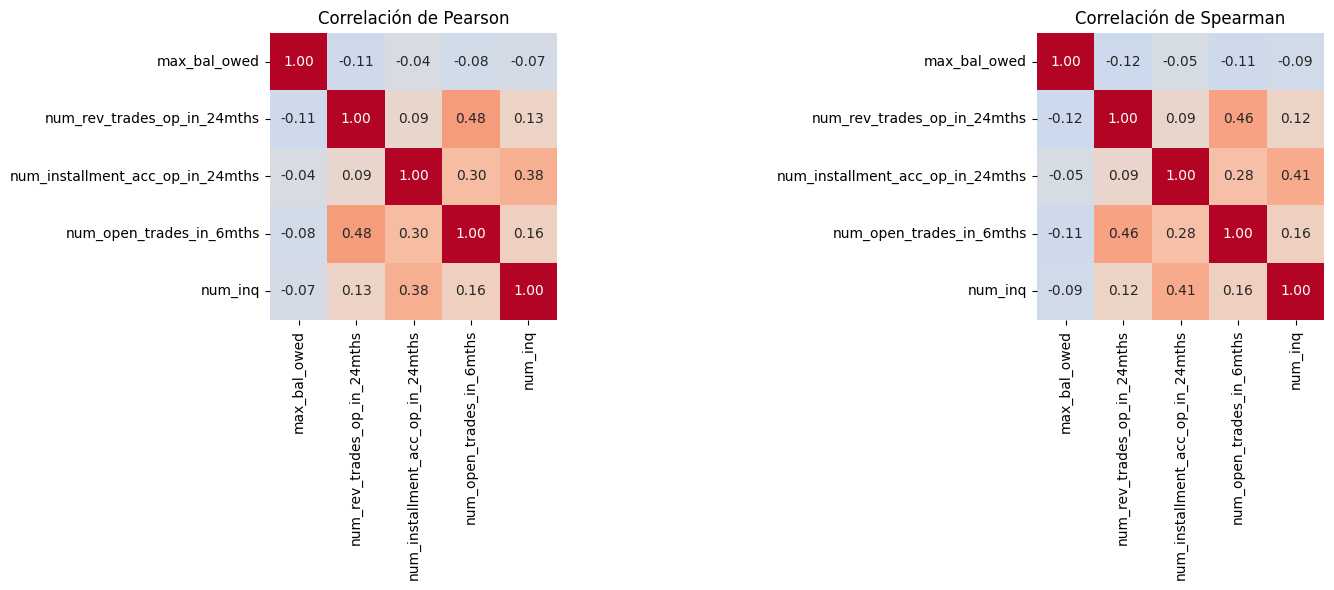

num_open_trades_in_6mths            1.43
num_rev_trades_op_in_24mths         1.33
num_installment_acc_op_in_24mths    1.27
num_inq                             1.19
max_bal_owed                        1.02
Name: VIF, dtype: float64


In [ ]:
bloque_nulos_no_tratados = [
    "max_bal_owed",
    "num_rev_trades_op_in_24mths",
    "num_installment_acc_op_in_24mths",
    "num_open_trades_in_6mths",
    "num_inq",
]
datos = muestra[bloque_nulos_no_tratados].dropna()
print(f"Filas con datos del bloque: {len(datos):,}")

# 1) Matrices de correlación: Pearson (lineal) y Spearman (por rangos, más robusta
#    para recuentos asimétricos y valores extremos)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(datos.corr(method=metodo), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

# 2) VIF: cuánto se infla la varianza de cada coeficiente por su relación con el resto
X_vif = add_constant(datos)
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=bloque_nulos_no_tratados, name="VIF",
).sort_values(ascending=False)
print(vif.round(2))


Extendemos ahora el análisis de multicolinealidad al resto de variables.

In [ ]:
vars_sin_nulos = [
    # ===== Originación =====
    # Características del préstamo
    "funded_amnt", "loan_term_months", "interest_rate", "monthly_payment", "loan_purpose",
    "initial_list_status", "disbursement_method", "issue_date_month", "issue_date_year",
    # Perfil del prestatario
    "home_ownership_status", "verification_status",
    "dept_paym_income_ratio",
    # Localización geográfica
    "addr_state", "region_code",
    # Historial crediticio
    "earliest_cr_line_month", "earliest_cr_line_year", "num_open_credit_lines",
    "tot_num_credit_lines", "num_derogatory_pub_rec",
    # Morosidad previa
    "num_30+_delinq_in_2yrs", "mths_since_last_delinq", "mths_since_recent_revol_delinq",
    "mths_since_recent_bankcard_delinq",
    # Crédito revolving y endeudamiento
    "total_credit_revolving_bal", "used_credit_share",
    # Consultas de crédito
    "num_inq_in_6mths",

    # ===== Creadas =====
    "annual_income_log", "emp_length_cat", "emp_tipo", "emp_ambito",
    "credit_history_months", "never_delinq", "never_revol_delinq", "never_bankcard_delinq",
    "mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat","num_inq_in_7_12mths"
]
print(len(vars_sin_nulos))

37


Separamos ahora las variables que no tienen nulos en numéricas y categóricas.

In [ ]:
CATEGORICAS = [c for c in vars_sin_nulos if X_train[c].dtype == "object"]
NUMERICAS = [c for c in vars_sin_nulos if c not in CATEGORICAS]

Estudiamos las correlaciones y el VIF.




**Consideraciones sobre los cáluclos:**

El VIF necesita filas completas (sin nulos), porque se calcula con regresiones de cada variable sobre todas las demás a la vez. Si incluimos las variables del bloque con nulos estructurales, debemos quedarnos solo con las filas donde hay dato, lo que elimina parte de la muestra. Por eso hacemos dos cálculos:

* **VIF_sin_bloque:** mide la multicolinealidad entre las variables que existen para toda la cartera, usando todos los préstamos (sin incluir las variables con nulos estructurales).
* **VIF_con_bloque:** mide la multicolinealidad incluyendo también las variables del bloque, pero solo sobre los préstamos recientes (solo usa datos a partir de noviembre de 2015).

Además, por cómo se define el VIF tenemos que:
* $VIF=1$ : Ausencia de multicolinealidad
* $1< VIF < 5$: Multicolinealidad baja o moderada
* $5 \leq VIF < 10$: Multicolinealidad alta
* $VIF \geq 10$: Multicolinealidad muy alta

### Primera iteración

En esta primera iteración solo analizamos las variables numéricas.

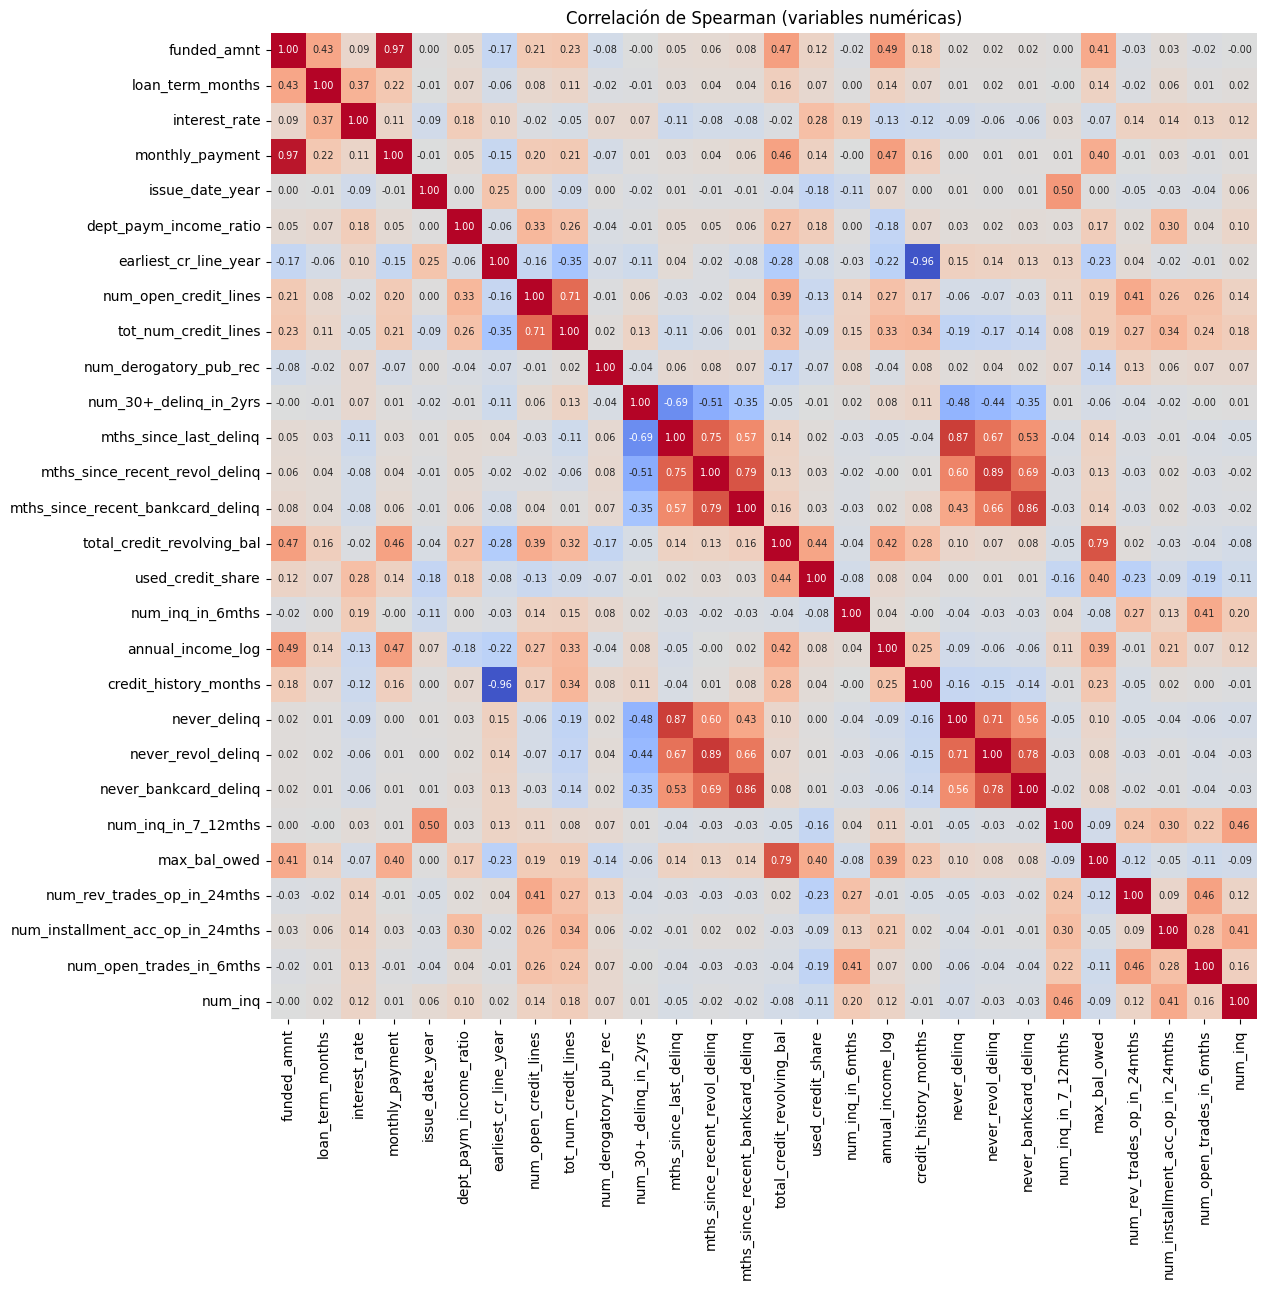

,var_1,var_2,spearman
0,funded_amnt,monthly_payment,0.97
1,earliest_cr_line_year,credit_history_months,-0.96
9,mths_since_recent_revol_delinq,never_revol_delinq,0.89
5,mths_since_last_delinq,never_delinq,0.87
12,mths_since_recent_bankcard_delinq,never_bankcard_delinq,0.86
13,total_credit_revolving_bal,max_bal_owed,0.79
7,mths_since_recent_revol_delinq,mths_since_recent_bankcard_delinq,0.79
15,never_revol_delinq,never_bankcard_delinq,0.78
4,mths_since_last_delinq,mths_since_recent_revol_delinq,0.75
14,never_delinq,never_revol_delinq,0.71


,VIF_sin_bloque,VIF_con_bloque
earliest_cr_line_year,383.85,386.46
credit_history_months,368.21,378.60
funded_amnt,51.36,49.00
monthly_payment,44.21,42.53
mths_since_recent_revol_delinq,13.54,13.36
never_revol_delinq,12.55,11.91
mths_since_recent_bankcard_delinq,8.87,8.87
never_bankcard_delinq,9.00,8.65
mths_since_last_delinq,7.88,7.70
never_delinq,6.14,5.89


In [ ]:
EXCLUIDAS = {"num_installment_acc_op_in_12mths", "num_rev_trades_op_in_12mths"}
BLOQUE_NULOS = [v for v in bloque_nulos_no_tratados if v not in EXCLUIDAS]
NUMERICAS_TODAS = NUMERICAS + BLOQUE_NULOS

# ===== 1) Matriz de correlación de Spearman (eliminación por pares) =====
corr = muestra[NUMERICAS_TODAS].corr(method="spearman")

plt.figure(figsize=(15, 13))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar=False, annot_kws={"size": 7})
plt.title("Correlación de Spearman (variables numéricas)")
plt.tight_layout()
plt.show()

# ===== 2) Pares con correlación alta =====
UMBRAL = 0.6
pares = [
    {"var_1": a, "var_2": b, "spearman": corr.loc[a, b]}
    for i, a in enumerate(NUMERICAS_TODAS) for b in NUMERICAS_TODAS[i + 1:]
    if abs(corr.loc[a, b]) > UMBRAL
]
display(pd.DataFrame(pares).sort_values("spearman", key=abs, ascending=False)
        .style.format({"spearman": "{:.2f}"}))

# ===== 3) VIF: sin el bloque (toda la muestra) y con el bloque (solo préstamos con datos de buró) =====
def calcular_vif(datos):
    X_vif = add_constant(datos.astype(float))
    return pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                     index=datos.columns)

vif = pd.DataFrame({
    "VIF_sin_bloque": calcular_vif(muestra[NUMERICAS]),
    "VIF_con_bloque": calcular_vif(muestra[NUMERICAS_TODAS].dropna()),
}).sort_values("VIF_con_bloque", ascending=False)

display(vif.style.format("{:.2f}", na_rep="—")
        .background_gradient(cmap="Reds", vmin=1, vmax=10))

Correlaciones:
* `funded_amnt` y `monthly_payment`: muestran una correlación de Spearman de 0.97 (muy alta). Cuanto mayor es el préstamo concedido, mayor es el pago mensual para saldar la deuda. Además, `monthly_payment` se determina a partir de `funded_amt` (cuantía total del préstamo), `interest_rate`(interés del préstamo) y `loan_term_months`(plazo en meses). Con lo cual, **eliminamos `monthly_payment`.**
*  `earliest_cr_line_year` y 	`credit_history_months`: muestran una correlación de Spearman de -0.96 (muy alta). Esto era de esperar ya que `credit_history_months` se crea a partir de `earliest_cr_line_year`. Además, cuanto más antigua es la primera línea de crédito abierta (cuanto menor es su valor), el historial es más amplio (mayor número de meses), lo cual es totalmente congruente con la correlación negativa que observamos. En este caso, consideramos que aporta más valor la amplitud del histórico que la fecha de la primera apertura de una línea de crédito, con lo cual **eliminamos `earliest_cr_line_year`**. Consecuentemente, también eliminamos **`earliest_cr_line_month`** (la cual es categórica y por eso no nos aparece en esta parte del análisis)
* `mths_since_recent_revol_delinq` y	`never_revol_delinq`: muestran una correlación de Spearman de 0.89 (muy alta). En este caso interesaría tratar estas variables para así poder mantener su información, pues `never_revol_delinq` actúa como flag que distingue entre valores imputados (eran nulos en el dataset original) y datos con registros reales. Algo análogo ocurrirá con el resto de variables de "delinq". La decisión más simple es quedarnos solo con `mths_since_last_delinq` (mayor justificación abajo), por tanto **eliminamos `mths_since_recent_revol_delinq` y `mths_since_recent_bankcard_delinq`, junto con sus respectivos flags `never_revol_delinq` y `never_bankcard_delinq`.**

* `total_credit_revolving_bal` y 	`max_bal_owed`:

* `num_open_credit_lines` y	`tot_num_credit_lines`:

* `num_30+_delinq_in_2yrs` y	`mths_since_last_delinq`:

Dejamos el análisis del resto de variables para una segunda iteración de este mismo estudio.


A continuación se analizan en detalle las variables `mths_since_last_delinq`, `mths_since_recent_revol_delinq` y `mths_since_recent_bankcard_delinq`.

Fusionamos los intervalos para los cuales no hay evidencia de que presenten diferencias en cuanto a tasa de impago y analizamos si las variables `mths_since_recent_revol_delinq` y `mths_since_recent_bankcard_delinq` aportan algo más a la hora de predecir PD que solo `mths_since_last_delinq`.

In [ ]:
# =====================================================================
# ¿Aportan las variables de morosidad revolving y de tarjeta algo más que mths_since_last_delinq?
# Todo con train. Los tramos de las dos variables descartadas se construyen solo para esta comparación.
# =====================================================================
from scipy.stats import chi2_contingency
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss

VARS_DELINQ = {"mths_since_last_delinq": "never_delinq",
               "mths_since_recent_revol_delinq": "never_revol_delinq",
               "mths_since_recent_bankcard_delinq": "never_bankcard_delinq"}
TRAMOS_DELINQ = {
    "mths_since_last_delinq": ([0, 6, 18, 36, 60, 72, 84], ["0-6", "6-18", "18-36", "36-60", "60-72", "72-84"]),
    "mths_since_recent_revol_delinq": ([0, 6, 18, 36, 48, 60, 84], ["0-6", "6-18", "18-36", "36-48", "48-60", "60-84"]),
    "mths_since_recent_bankcard_delinq": ([0, 6, 18, 36, 48, 60, 84], ["0-6", "6-18", "18-36", "36-48", "48-60", "60-84"]),
}

def en_tramos(df, var):
    cortes, etiquetas = TRAMOS_DELINQ[var]
    cat = pd.cut(df[var], bins=cortes, labels=etiquetas, include_lowest=True).astype("object")
    cat[df[VARS_DELINQ[var]] == 1] = "sin retraso registrado"
    return cat

tramos = pd.DataFrame({v: en_tramos(X_train, v) for v in VARS_DELINQ}, index=X_train.index)

# ----- 1) Anidamiento: el último retraso en cualquier cuenta es igual o más reciente que el de revolving/tarjeta -----
print("1) Coherencia del anidamiento (préstamos con ambos retrasos registrados):")
for v in ["mths_since_recent_revol_delinq", "mths_since_recent_bankcard_delinq"]:
    ambos = (X_train["never_delinq"] == 0) & (X_train[VARS_DELINQ[v]] == 0)
    ok = (X_train.loc[ambos, "mths_since_last_delinq"] <= X_train.loc[ambos, v]).mean()
    sin_general = ((X_train["never_delinq"] == 1) & (X_train[VARS_DELINQ[v]] == 0)).sum()
    print(f"   {v}: mths_since_last_delinq ≤ {v} en el {ok:.2%} | "
          f"con retraso en {v.split('_')[3]} pero sin retraso general: {sin_general:,}")

# ----- 2) Asociación entre las versiones en tramos (V de Cramér) -----
def v_cramer(a, b):
    t = pd.crosstab(a, b)
    chi2, n = chi2_contingency(t, correction=False)[0], t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

print("\n2) V de Cramér con mths_since_last_delinq:")
for v in ["mths_since_recent_revol_delinq", "mths_since_recent_bankcard_delinq"]:
    print(f"   {v}: {v_cramer(tramos['mths_since_last_delinq'], tramos[v]):.3f}")

# ----- 3) Poder predictivo incremental (logística con los tramos, validación cruzada de 5 bloques) -----
muestra_idx = X_train.sample(min(300_000, len(X_train)), random_state=SEED).index
y_m = y_train.loc[muestra_idx].to_numpy()
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def evaluar(variables):
    X_dum = pd.get_dummies(tramos.loc[muestra_idx, variables], drop_first=True, dtype=float)
    p = cross_val_predict(LogisticRegression(max_iter=1000), X_dum, y_m, cv=cv, method="predict_proba")[:, 1]
    return {"AUC": roc_auc_score(y_m, p), "log_loss": log_loss(y_m, p)}

comparacion = pd.DataFrame({
    "solo mths_since_last_delinq": evaluar(["mths_since_last_delinq"]),
    "las tres variables": evaluar(list(VARS_DELINQ)),
}).T
comparacion.loc["diferencia"] = comparacion.iloc[1] - comparacion.iloc[0]
print("\n3) Poder predictivo sobre el impago (fuera de muestra):")
display(comparacion.style.format({"AUC": "{:.4f}", "log_loss": "{:.5f}"}))

1) Coherencia del anidamiento (préstamos con ambos retrasos registrados):
   mths_since_recent_revol_delinq: mths_since_last_delinq ≤ mths_since_recent_revol_delinq en el 99.39% | con retraso en revol pero sin retraso general: 700
   mths_since_recent_bankcard_delinq: mths_since_last_delinq ≤ mths_since_recent_bankcard_delinq en el 99.41% | con retraso en bankcard pero sin retraso general: 477

2) V de Cramér con mths_since_last_delinq:
   mths_since_recent_revol_delinq: 0.631
   mths_since_recent_bankcard_delinq: 0.463

3) Poder predictivo sobre el impago (fuera de muestra):


,AUC,log_loss
solo mths_since_last_delinq,0.5156,0.38827
las tres variables,0.5178,0.38823
diferencia,0.0021,-0.00004


En primer lugar, vemos que hay un pequeño porcentaje de préstamos en la cartera de train que presentan incongruencias en cuanto a la anidación de estas variables: todo préstamo con retraso en cuenta revolving o crédito debería mostrar retraso en la variable que engloba todo tipo de retrasos.

En segundo lugar, observamos valores moderados para la V de Cramer de ambas variables con respecto de `mths_since_last_delinq`.

Finalmente se realizan dos regresiones logísticas para precir PD mediante validación cruzada con 5 bloques. La primera regresión solo usa la variable `mths_since_last_delinq` y la segunda usa las tres variables involucradas en este análisis.

En la tabla de resultados observamos que incluir las tres variables aporta una mejora en log-loss del orden de $10^{-5}$ y una ligera mejora en cuanto a capacidad de ordenar.

La magnitud de estas mejoras no compensa la posible inestabilidad de los modelos causada por inluir variables con elevada multicolinealidad, por tanto, concluimos que es suficiente con mantener la variable `mths_since_last_delinq` y eliminar tanto `mths_since_recent_revol_delinq` como `mths_since_recent_bankcard_delinq`. Asímismo, se eliminan también sus correspondientes flags `never_revol_delinq` y `never_bankcard_delinq`.

In [ ]:
# Variable final: mths_since_last_delinq en tramos (la única de las tres que se conserva)
for df in (X_train, X_val, X_test):
    df["mths_since_last_delinq_cat"] = en_tramos(df, "mths_since_last_delinq")

orden = ["sin retraso registrado"] + TRAMOS_DELINQ["mths_since_last_delinq"][1]
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df['mths_since_last_delinq_cat'].isna().sum()} nulos en mths_since_last_delinq_cat")

print("\n4) Tasa de default por tramo de mths_since_last_delinq_cat (train):")
display(y_train.groupby(X_train["mths_since_last_delinq_cat"]).agg(n="size", tasa_default="mean")
        .reindex(orden).style.format({"n": "{:,}", "tasa_default": "{:.2%}"}))

train: 0 nulos en mths_since_last_delinq_cat
val: 0 nulos en mths_since_last_delinq_cat
test: 0 nulos en mths_since_last_delinq_cat

4) Tasa de default por tramo de mths_since_last_delinq_cat (train):


,n,tasa_default
mths_since_last_delinq_cat,,
sin retraso registrado,"654,430",12.44%
0-6,"49,400",15.22%
6-18,"134,891",14.43%
18-36,"177,989",13.61%
36-60,"165,643",13.25%
60-72,"61,289",13.56%
72-84,"40,143",13.00%


In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns=["monthly_payment"], inplace=True)
    df.drop(columns=["earliest_cr_line_year"], inplace=True)
    df.drop(columns=["earliest_cr_line_month"], inplace=True)
    df.drop(columns=["mths_since_recent_revol_delinq"], inplace=True)
    df.drop(columns=["mths_since_recent_bankcard_delinq"], inplace=True)
    df.drop(columns=["never_revol_delinq"],inplace=True)
    df.drop(columns=["never_bankcard_delinq"],inplace=True)
    df.drop(columns=["num_installment_acc_op_in_12mths"],inplace=True)
    df.drop(columns=["num_rev_trades_op_in_12mths"],inplace=True)

### Segunda iteración

En esta iteración volvemos a hacer el análisis de las variables numéricas no eliminadas en la iteración anterior y añadimos el análisis de las variables categóricas.

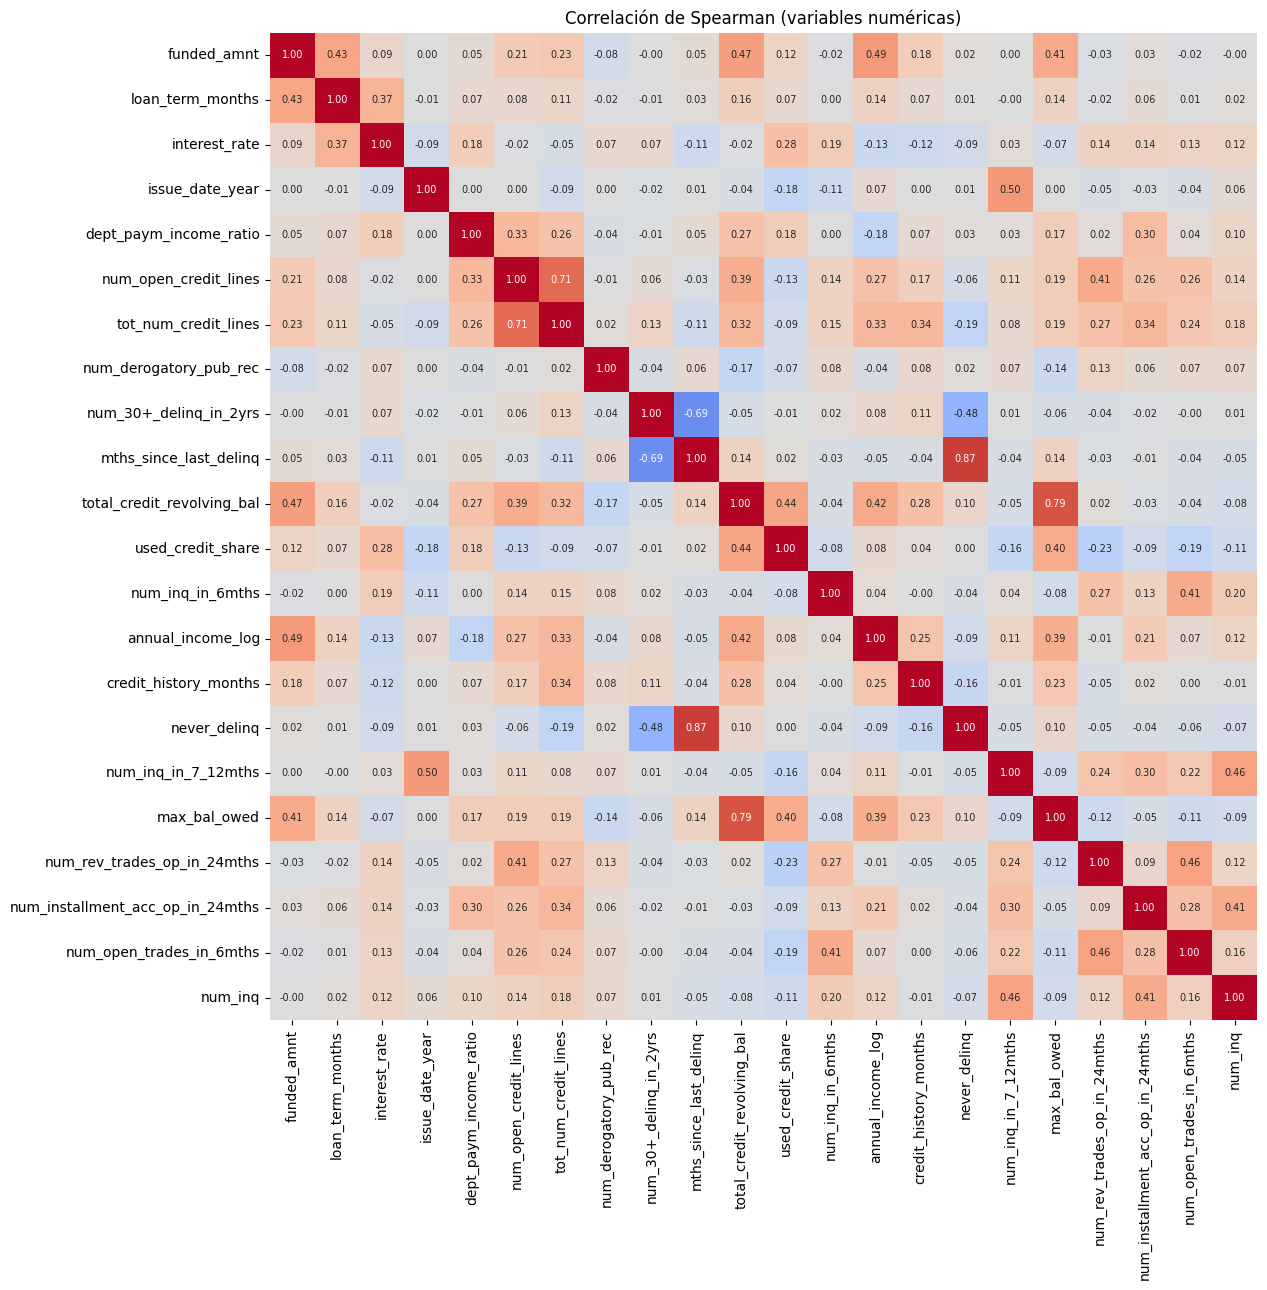

,var_1,var_2,spearman
2,mths_since_last_delinq,never_delinq,0.87
3,total_credit_revolving_bal,max_bal_owed,0.79
0,num_open_credit_lines,tot_num_credit_lines,0.71
1,num_30+_delinq_in_2yrs,mths_since_last_delinq,-0.69


,VIF_sin_bloque,VIF_con_bloque
mths_since_last_delinq,4.22,4.05
never_delinq,3.39,3.28
num_open_credit_lines,2.29,2.80
tot_num_credit_lines,2.41,2.67
annual_income_log,1.88,2.09
num_rev_trades_op_in_24mths,—,1.79
max_bal_owed,—,1.73
total_credit_revolving_bal,1.41,1.72
funded_amnt,1.67,1.68
num_open_trades_in_6mths,—,1.62


In [ ]:
EXCLUIDAS = {"grade","num_installment_acc_op_in_12mths", "num_rev_trades_op_in_12mths","monthly_payment",
             "earliest_cr_line_year","mths_since_recent_revol_delinq","mths_since_recent_bankcard_delinq",
             "mths_since_recent_revol_delinq_cat","mths_since_recent_bankcard_delinq_cat","never_revol_delinq","never_bankcard_delinq"}

NUMERICAS_FILTRADAS = [v for v in NUMERICAS if v not in EXCLUIDAS]
BLOQUE_NULOS = [v for v in bloque_nulos_no_tratados if v not in EXCLUIDAS]
NUMERICAS_TODAS = NUMERICAS_FILTRADAS + BLOQUE_NULOS

# ===== 1) Matriz de correlación de Spearman (eliminación por pares) =====
corr = muestra[NUMERICAS_TODAS].corr(method="spearman")

plt.figure(figsize=(15, 13))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar=False, annot_kws={"size": 7})
plt.title("Correlación de Spearman (variables numéricas)")
plt.tight_layout()
plt.show()

# ===== 2) Pares con correlación alta =====
UMBRAL = 0.6
pares = [
    {"var_1": a, "var_2": b, "spearman": corr.loc[a, b]}
    for i, a in enumerate(NUMERICAS_TODAS) for b in NUMERICAS_TODAS[i + 1:]
    if abs(corr.loc[a, b]) > UMBRAL
]
display(pd.DataFrame(pares).sort_values("spearman", key=abs, ascending=False)
        .style.format({"spearman": "{:.2f}"}))

# ===== 3) VIF: sin el bloque (toda la muestra) y con el bloque (solo préstamos con datos de buró) =====
def calcular_vif(datos):
    X_vif = add_constant(datos.astype(float))
    return pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                     index=datos.columns)

vif = pd.DataFrame({
    "VIF_sin_bloque": calcular_vif(muestra[NUMERICAS_FILTRADAS]),
    "VIF_con_bloque": calcular_vif(muestra[NUMERICAS_TODAS].dropna()),
}).sort_values("VIF_con_bloque", ascending=False)

display(vif.style.format("{:.2f}", na_rep="—")
        .background_gradient(cmap="Reds", vmin=1, vmax=10))

Aunque persisten algunos pares de variables con correlación de Spearman alta, tras la segunda iteración ningún VIF supera 5, es decir, ninguna variable queda explicada en gran medida por el conjunto de las demás. Solo `mths_since_last_delinq` y `never_delinq` se acercan a ese umbral, lo que es esperable porque el flag se construye a partir de los nulos de la primera. Con una multicolinealidad moderada, la capacidad predictiva de los modelos no se ve comprometida, aunque en los modelos lineales las varianzas de los coeficientes de las variables correlacionadas serán mayores y su interpretación individual menos precisa. En los modelos basados en árboles, la correlación solo afecta al reparto de la importancia entre variables. Por ello, todas continúan siendo candidatas.

De esta manera, por ahora tenemos que las variables numéricas a utilizar en los modelos son:


**Analizadas**

1. `interest_rate`
2. `loan_term_months`
3. `dept_paym_income_ratio`
4. `funded_amnt`
5. `num_derogatory_pub_rec`
6. `annual_income_log`
7. `mths_since_last_delinq`
8. `never_delinq`
9. `num_inq_in_6mths`
10. `num_inq_in_7_12mths`
11. `num_30+_delinq_in_2yrs`

**Prioridad media (sin analizar)**

12. `num_open_credit_lines`
13. `tot_num_credit_lines`

**Analizadas parcialmente (falta su relación con el default)**

14. `credit_history_months`
15. `issue_date_year`
16. `total_credit_revolving_bal`
17. `used_credit_share`
18. `num_open_trades_in_6mths`
19. `num_installment_acc_op_in_24mths`
20. `num_rev_trades_op_in_24mths`
21. `max_bal_owed`
22. `num_inq`


Estudiamos las correlaciones entre variables categóricas.

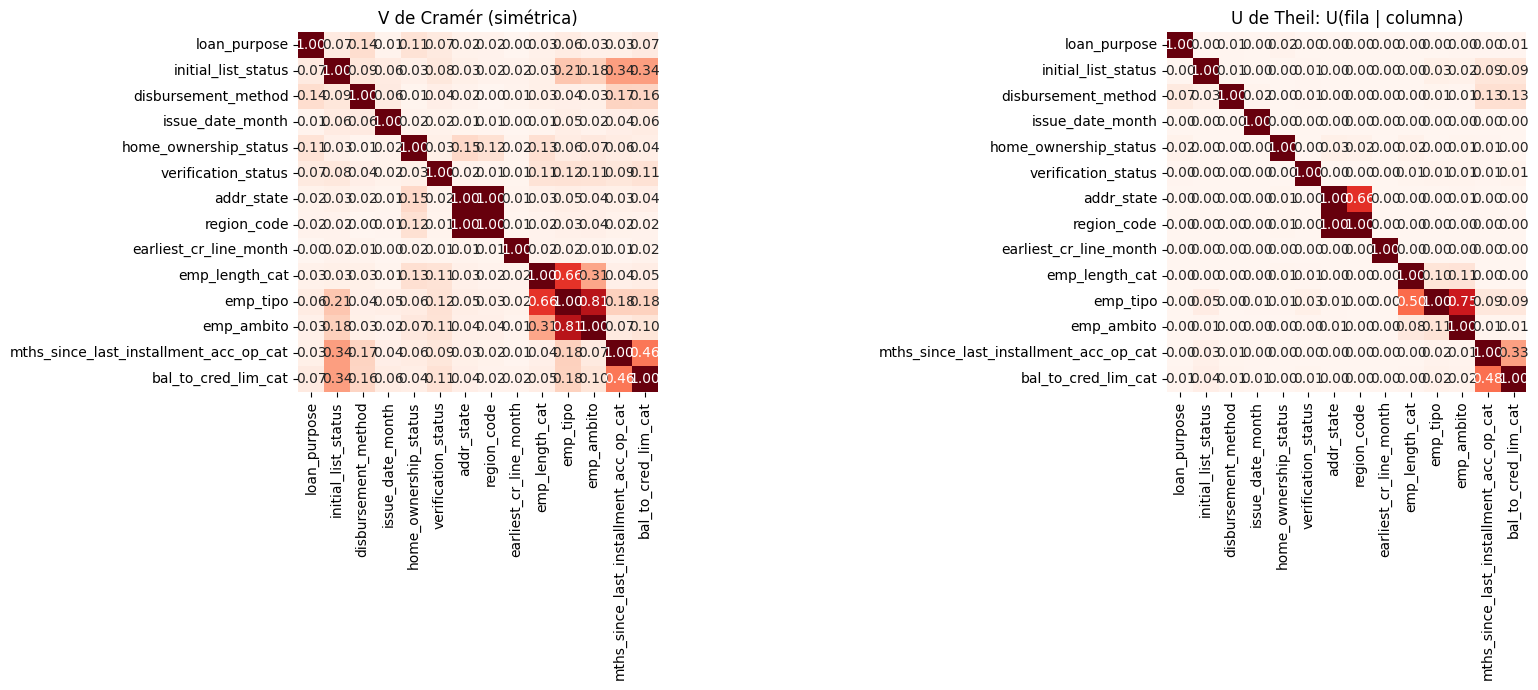

In [ ]:
from scipy.stats import chi2_contingency, entropy

def v_cramer(x, y):
    """V de Cramér con corrección de sesgo (Bergsma, 2013)."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    r, k = tabla.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))

def u_theil(x, y):
    """U(x|y): proporción de la incertidumbre de x que se elimina al conocer y."""
    h_x = entropy(x.value_counts(normalize=True))
    if h_x == 0:
        return 1.0
    p_y = y.value_counts(normalize=True)
    h_x_dado_y = sum(p_y[v] * entropy(x[y == v].value_counts(normalize=True)) for v in p_y.index)
    return (h_x - h_x_dado_y) / h_x

cramer = pd.DataFrame(1.0, index=CATEGORICAS, columns=CATEGORICAS)
theil = pd.DataFrame(1.0, index=CATEGORICAS, columns=CATEGORICAS)
for a in CATEGORICAS:
    for b in CATEGORICAS:
        if a != b:
            theil.loc[a, b] = u_theil(muestra[a].astype(str), muestra[b].astype(str))
            if a < b:
                cramer.loc[a, b] = cramer.loc[b, a] = v_cramer(muestra[a], muestra[b])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cramer, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, square=True, cbar=False, ax=axes[0])
axes[0].set_title("V de Cramér (simétrica)")
sns.heatmap(theil, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, square=True, cbar=False, ax=axes[1])
axes[1].set_title("U de Theil: U(fila | columna)")
plt.tight_layout()
plt.show()

In [ ]:
UMBRAL = 0.6

pares = []
for i, a in enumerate(CATEGORICAS):
    for b in CATEGORICAS[i + 1:]:
        v = cramer.loc[a, b]
        u_ab, u_ba = theil.loc[a, b], theil.loc[b, a]
        if UMBRAL < v < 0.999 or max(u_ab, u_ba) > UMBRAL:
            pares.append({"var_1": a, "var_2": b, "V_cramer": v,
                          "U(var_1 | var_2)": u_ab, "U(var_2 | var_1)": u_ba})

resultado = pd.DataFrame(pares)
if resultado.empty:
    print(f"Ningún par con V de Cramér entre {UMBRAL} y 1 y U de Theil superior a {UMBRAL}")
else:
    display(resultado.sort_values("V_cramer", ascending=False).style.format(
        {"V_cramer": "{:.2f}", "U(var_1 | var_2)": "{:.2f}", "U(var_2 | var_1)": "{:.2f}"}))

,var_1,var_2,V_cramer,U(var_1 | var_2),U(var_2 | var_1)
0,addr_state,region_code,1.00,0.66,1.00
2,emp_tipo,emp_ambito,0.81,0.75,0.11
1,emp_length_cat,emp_tipo,0.66,0.10,0.50


Observamos que `emp_tipo` y `emp_ambito` tienen una V de Cramér de 0,81. Además, $U(\text{emp_tipo } | \text{ emp_ambito}) = 0.75$, lo que quiere decir que conocer el ámbito profesional elimina el 75% de la incertidumbre sobre el tipo de registro. Es un resultado esperable, ya que ambas variables se construyen a partir de la misma clasificación de `emp_title`: las categorías "desconocido", "puesto_sin_sector" y "empresa_sin_sector" de `emp_ambito` determinan por sí mismas el tipo de registro, y la mayoría de los ámbitos con sector corresponden a puestos de trabajo. La información propia de `emp_tipo` se limita a distinguir, dentro de cada sector, los registros que son nombres de empresa, que representan una parte muy pequeña de la cartera. Por ello, **se elimina `emp_tipo` del modelo y se mantiene `emp_ambito`**, que contiene la mayor parte de su información y además aporta el sector de actividad.

Al eliminar esta variable, ya no tendremos problemas de correlación con `emp_length_cat`.

Por otro lado, observamos que `addr_state` y `region_code` tienen una V de cramer de 1, lo que indica una correlación perfecta y era de esperar por naturaleza: `addr_state` determina completamente `region_code`. Esto queda claro con el valor $U(\text{region_code } | \text{ addr_state})=1$, pues conocer el valor de `addr_state` elimina toda la incertidumbre sobre `region_code`. Por tanto, eliminamos **`region_code` del modelo y mantenemos `addr_state`**.

In [ ]:
for df in (X_train, X_val, X_test):
    df.drop(columns=["emp_tipo"], inplace=True)
    df.drop(columns=["region_code"], inplace=True)


De esta manera, las variables categóricas candidatas a utilizar en los modelos son:


**Analizadas**

1. `emp_length_cat`
2. `mths_since_last_installment_acc_op_cat`
3. `bal_to_cred_lim_cat`
4. `mths_since_last_delinq_cat`
5. `addr_state`
6. `home_ownership_status`
7. `loan_purpose`

**Prioridad alta (sin analizar)**

8. `verification_status`

**Prioridad media (sin analizar)**

9. `initial_list_status`
10. `disbursement_method`
11. `issue_date_month`

**Analizadas parcialmente (falta su relación con el default)**

12. `emp_ambito`



Con esto quedan solucionados los problemas de correlación entre variables categóricas.

 A continuación realizamos un **análisis mixto entre variables categóricas y numéricas**.

 Para este análisis se usa la razón de correlación $\eta^2$, que mide qué parte de la variabilidad de una variable numérica se explica por las categorías de una categórica. Esta razón va de 0 (toda la variabilidad está dentro de los grupos. Las medias de todas las categorías son iguales, así que conocer la categoría no dice nada sobre la variable numérica.) a 1 (toda la variabilidad está entre los grupos. Dentro de cada categoría, todos los valores son idénticos, así que conocer la categoría determina exactamente el valor de la numérica.).

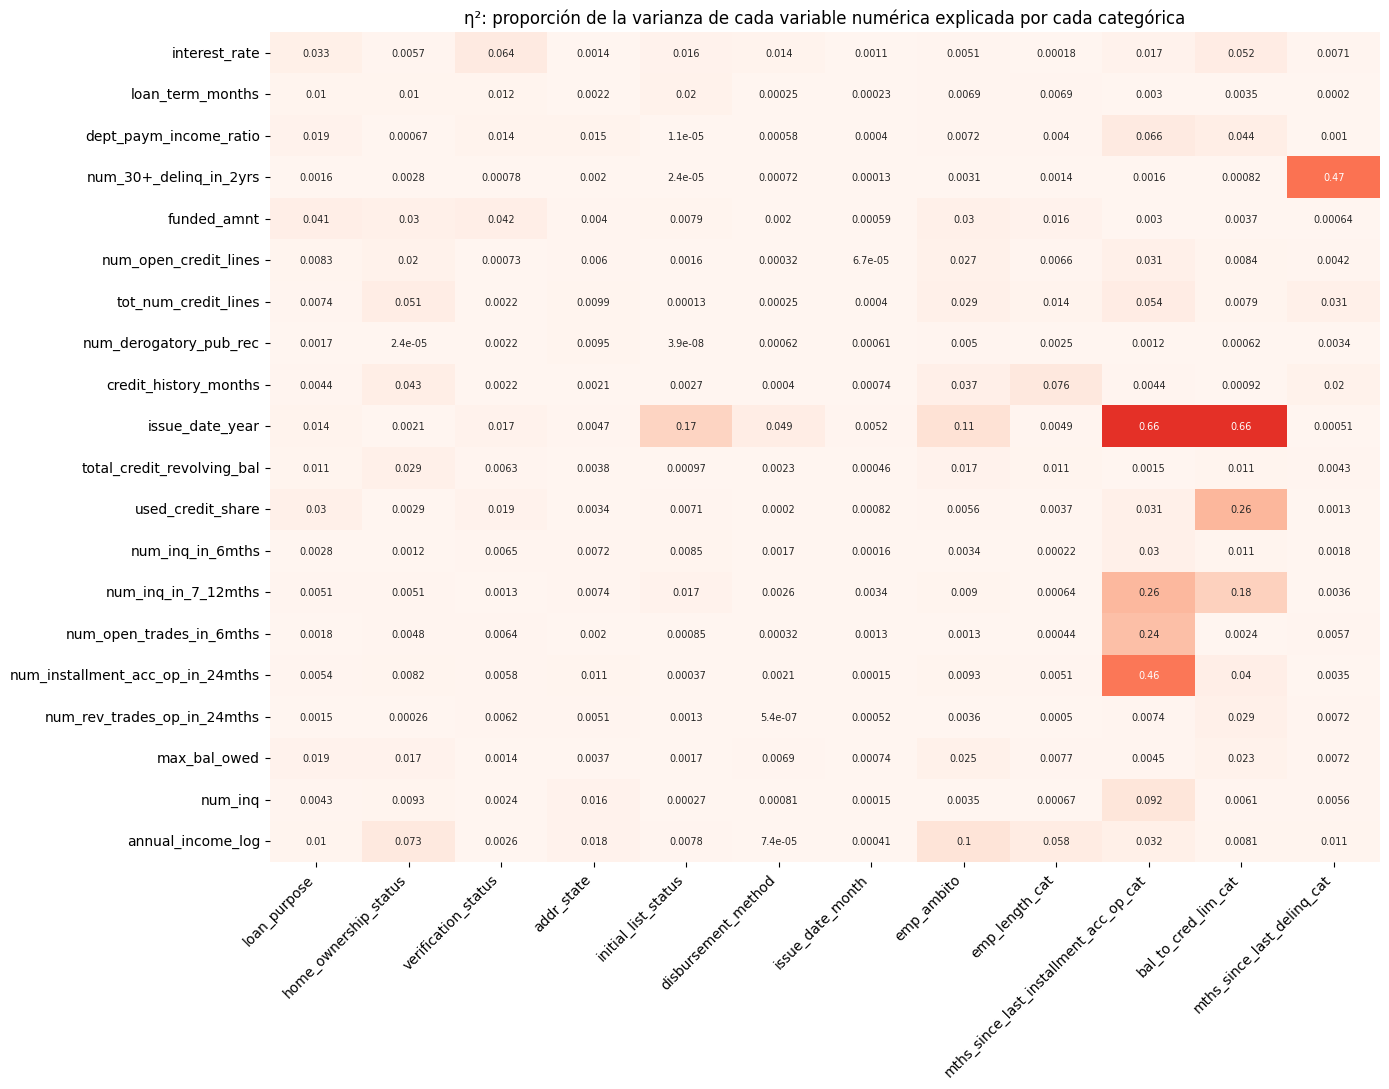

,numerica,categorica,eta2 (% varianza explicada)
2,issue_date_year,bal_to_cred_lim_cat,66.3%
1,issue_date_year,mths_since_last_installment_acc_op_cat,66.1%
0,num_30+_delinq_in_2yrs,mths_since_last_delinq_cat,47.3%
5,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op_cat,46.1%
3,used_credit_share,bal_to_cred_lim_cat,26.5%
4,num_inq_in_7_12mths,mths_since_last_installment_acc_op_cat,26.0%


In [ ]:
NUMERICAS_FINAL = [
    "interest_rate", "loan_term_months", "dept_paym_income_ratio", "num_30+_delinq_in_2yrs",
    "funded_amnt", "num_open_credit_lines", "tot_num_credit_lines", "num_derogatory_pub_rec",
    "credit_history_months", "issue_date_year", "total_credit_revolving_bal", "used_credit_share",
    "num_inq_in_6mths", "num_inq_in_7_12mths", "num_open_trades_in_6mths",
    "num_installment_acc_op_in_24mths", "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq",
    "annual_income_log",
]
CATEGORICAS_FINAL = [
    "loan_purpose", "home_ownership_status", "verification_status", "addr_state",
    "initial_list_status", "disbursement_method", "issue_date_month", "emp_ambito",
    "emp_length_cat", "mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat",
    "mths_since_last_delinq_cat",
]

muestra = X_train.sample(200_000, random_state=SEED)

def eta_cuadrado(categorica, numerica):
    """Proporción de la varianza de la numérica explicada por las categorías."""
    mask = numerica.notna()  # eliminación por pares (variables del bloque con nulos)
    categorica, numerica = categorica[mask], numerica[mask]

    media_global = numerica.mean()
    media_grupo = numerica.groupby(categorica).transform("mean")

    var_total = ((numerica - media_global) ** 2).sum()
    var_entre = ((media_grupo - media_global) ** 2).sum()
    return var_entre / var_total

eta2 = pd.DataFrame(
    {c: [eta_cuadrado(muestra[c].astype(str), muestra[n]) for n in NUMERICAS_FINAL]
     for c in CATEGORICAS_FINAL},
    index=NUMERICAS_FINAL,
)

# Mapa de calor de η² (proporción de varianza explicada)
plt.figure(figsize=(14, 11))
sns.heatmap(eta2, annot=True, fmt=".2", cmap="Reds", vmin=0, vmax=1, cbar=False, annot_kws={"size": 7})
plt.title("η²: proporción de la varianza de cada variable numérica explicada por cada categórica")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pares con asociación alta
UMBRAL_ETA2 = 0.25          # la categórica explica al menos un 25 % de la varianza de la numérica
pares = pd.DataFrame([
    {"numerica": n, "categorica": c, "eta2 (% varianza explicada)": eta2.loc[n, c]}
    for n in NUMERICAS_FINAL for c in CATEGORICAS_FINAL if eta2.loc[n, c] > UMBRAL_ETA2
])
if pares.empty:
    print(f"Ningún par supera η² = {UMBRAL_ETA2:.0%}")
else:
    display(pares.sort_values("eta2 (% varianza explicada)", ascending=False)
            .style.format({"eta2 (% varianza explicada)": "{:.1%}"}))

Tenemos que `issue_date_year` y `bal_to_cred_lim_cat` presentan un $\eta^2$ de 0,663 (la categórica explica el 66,3% de la varianza del año de emisión). Esta relación es debida a la construcción de la variable: la categoría "sin registro" identifica los préstamos emitidos antes de diciembre de 2015, por lo que separa casi por completo las cosechas anteriores y posteriores a esa fecha. El resto de categorías, que miden la utilización del crédito, no guardan relación con el año.

Para `mths_since_last_installment_acc_op_cat` ocurre exactamente lo mismo con respecto a `issue_date_year`.

# 2.ANÁLISIS DE WOE / IV

A continuación calculamos el WoE (Weight of Evidence) y el IV (Information Value) de cada variable teniendo en cuenta las siguientes consideracione:
* Las variables numéricas continuas se agrupan en 20 tramos por cuantiles.
* Variables numéricas con pocos valores distintos: cada valor es su propio tramo para el cálculo.
* Los nulos forman un tramo propio.
* Cada categoría de cada variable categórica forma un tramo. Además, las que tengan menos de 500 préstamos se agrupan en "otros" evitando inflar el IV.

El IV se calcula con todo train, ya que es una medida descriptiva utilizada solo para seleccionar variables y no entra como dato en los modelos.

En cambio, las columnas WoE, que sí son variables de entrada de los modelo, se calculan fuera de muestra mediante un KFold con 5 bloques. De esta manera, evitamos usar el target de cada préstamo para el cálculo del valor WoE asociado a su categoría correspondiente.

,tipo,n_tramos,IV,poder_predictivo
variable,,,,
interest_rate,numérica,20,0.459,fuerte
issue_date_year,numérica,12,0.370,fuerte
num_rev_trades_op_in_24mths,numérica,9,0.137,media
bal_to_cred_lim_cat,categórica,6,0.127,media
num_open_trades_in_6mths,numérica,19,0.124,media
mths_since_last_installment_acc_op_cat,categórica,12,0.118,media
num_installment_acc_op_in_24mths,numérica,7,0.116,media
max_bal_owed,numérica,21,0.109,media
num_inq,numérica,6,0.107,media


train: 0 nulos en las columnas WoE
val: 0 nulos en las columnas WoE
test: 0 nulos en las columnas WoE
train: 0 nulos en las columnas WoE
val: 0 nulos en las columnas WoE
test: 0 nulos en las columnas WoE


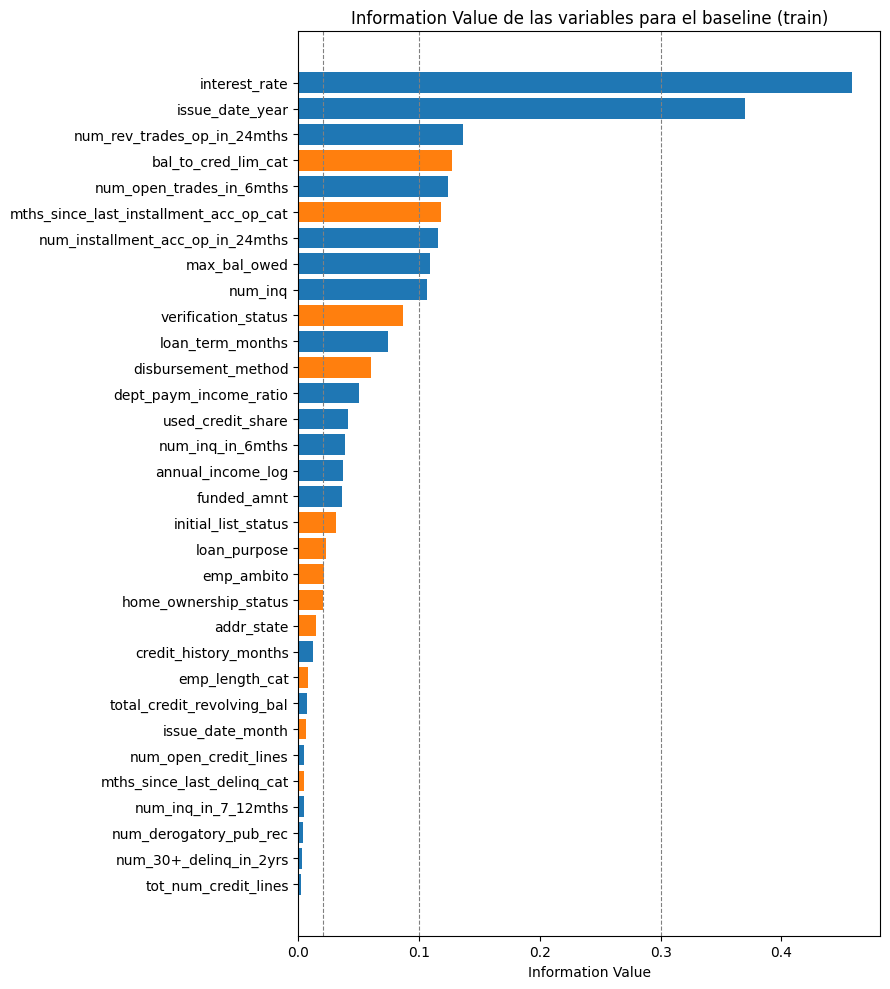

In [ ]:
NUM = [
    "interest_rate", "loan_term_months", "dept_paym_income_ratio", "num_30+_delinq_in_2yrs",
    "funded_amnt", "num_open_credit_lines", "tot_num_credit_lines", "num_derogatory_pub_rec",
    "credit_history_months", "issue_date_year", "total_credit_revolving_bal", "used_credit_share",
    "num_inq_in_6mths", "num_inq_in_7_12mths", "num_open_trades_in_6mths",
    "num_installment_acc_op_in_24mths", "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq",
    "annual_income_log"
]
CAT = [
    "loan_purpose", "home_ownership_status", "verification_status", "addr_state",
    "initial_list_status", "disbursement_method", "issue_date_month", "emp_ambito",
    "emp_length_cat", "mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat",
    "mths_since_last_delinq_cat"
]

MIN_N = 500   # categorías con menos préstamos se agrupan en "otros"
N_TRAMOS = 20        # número de tramos para las numéricas continuas       # número de tramos para las numéricas continuas

def tramos_variable(x, es_categorica):
    """Asigna cada observación a un tramo (como texto). Los nulos forman su propio tramo."""
    if es_categorica:
        t = x.astype(str)
        frec = t.value_counts()
        t = t.where(t.isin(frec[frec >= MIN_N].index), "otros")
    elif x.nunique() <= Q:
        t = x.astype(str)                                   # pocos valores: uno por tramo
    else:
        _, bordes = pd.qcut(x.dropna(), q=N_TRAMOS, duplicates="drop", retbins=True)
        bordes[0], bordes[-1] = -np.inf, np.inf
        t = pd.cut(x, bins=bordes).astype(str)
    return t.where(x.notna(), "nulo")

def woe_iv(tramos, y, suavizado=0.5):
    """WoE por tramo e IV total."""
    t = pd.crosstab(tramos, y)
    malos, buenos = t[1] + suavizado, t[0] + suavizado
    pct_malos, pct_buenos = malos / malos.sum(), buenos / buenos.sum()
    tabla = pd.DataFrame({
        "n": t[0] + t[1],
        "tasa_default": t[1] / (t[0] + t[1]),
        "woe": np.log(pct_buenos / pct_malos),
    })
    iv = ((pct_buenos - pct_malos) * tabla["woe"]).sum()
    return tabla, iv

def poder_predictivo(iv):
    if iv < 0.02: return "no predictiva"
    if iv < 0.1:  return "débil"
    if iv < 0.3:  return "media"
    if iv < 0.5:  return "fuerte"
    return "muy fuerte (revisar)"

# ===== Cálculo del WoE y el IV de todas las variables (SOLO con train) =====
TABLAS_WOE, resumen = {}, []
for var, es_cat in [(v, False) for v in NUM] + [(v, True) for v in CAT]:
    tramos = tramos_variable(X_train[var], es_cat)
    tabla, iv = woe_iv(tramos, y_train)
    TABLAS_WOE[var] = tabla
    resumen.append({"variable": var, "tipo": "categórica" if es_cat else "numérica",
                    "n_tramos": len(tabla), "IV": iv, "poder_predictivo": poder_predictivo(iv)})

resumen_iv = pd.DataFrame(resumen).set_index("variable").sort_values("IV", ascending=False)
display(resumen_iv.style.format({"IV": "{:.3f}"}).background_gradient(subset="IV", cmap="Reds"))

# ===== Columnas WoE de las categóricas =====
from sklearn.model_selection import KFold

WOE_FUERA_DE_MUESTRA = True     # True: WoE de train con KFold
N_BLOQUES_WOE = 5

def aplicar_woe(x, tabla):
    """Asigna a cada valor el WoE de su categoría en la tabla. Las categorías pequeñas o no vistas
    van a "otros"; si "otros" no existe en la tabla, reciben WoE 0 (riesgo medio)."""
    valores = x.astype(str).where(x.notna(), "nulo")
    valores = valores.where(valores.isin(tabla.index), "otros")
    return valores.map(tabla["woe"]).fillna(0).astype("float32")

def woe_train_fuera_de_muestra(X, y, columnas, seed):
    """WoE de train fuera de muestra: cada préstamo recibe el WoE de su categoría estimado con
    los otros bloques, de modo que su propio impago no interviene en su valor."""
    woe = pd.DataFrame(index=X.index, columns=[f"{c}_woe" for c in columnas], dtype="float32")
    for i_aj, i_ap in KFold(N_BLOQUES_WOE, shuffle=True, random_state=seed).split(X):
        i_aj, i_ap = X.index[i_aj], X.index[i_ap]
        for c in columnas:
            tabla_bloque, _ = woe_iv(tramos_variable(X.loc[i_aj, c], True), y.loc[i_aj])
            woe.loc[i_ap, f"{c}_woe"] = aplicar_woe(X.loc[i_ap, c], tabla_bloque).to_numpy()
    return woe.astype("float32")

# Val y test: tablas calculadas con todo train
for df in (X_val, X_test):
    for c in CAT:
        df[f"{c}_woe"] = aplicar_woe(df[c], TABLAS_WOE[c])

# Train: fuera de muestra (o con las tablas de todo train si se desactiva la opción)
if WOE_FUERA_DE_MUESTRA:
    X_train[[f"{c}_woe" for c in CAT]] = woe_train_fuera_de_muestra(X_train, y_train, CAT, SEED)
else:
    for c in CAT:
        X_train[f"{c}_woe"] = aplicar_woe(X_train[c], TABLAS_WOE[c])

WOE_COLS = [f"{c}_woe" for c in CAT]
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df[WOE_COLS].isna().sum().sum()} nulos en las columnas WoE")

WOE_COLS = [f"{c}_woe" for c in CAT]
for nombre, df in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre}: {df[WOE_COLS].isna().sum().sum()} nulos en las columnas WoE")

# ===== Gráfico =====
plt.figure(figsize=(9, 10))
colores = resumen_iv["tipo"].map({"numérica": "tab:blue", "categórica": "tab:orange"})
plt.barh(resumen_iv.index[::-1], resumen_iv["IV"][::-1], color=colores[::-1])
for umbral in [0.02, 0.1, 0.3]:
    plt.axvline(umbral, color="grey", linestyle="--", linewidth=0.8)
plt.xlabel("Information Value")
plt.title("Information Value de las variables para el baseline (train)")
plt.tight_layout()
plt.show()

Como era de esperar, tenemos que la variable con mayor poder predictivo es
`interest_rate`. En segundo lugar se encuentra `issue_date_year`, cuya explicación vuelve a ser la separación de cosechas. Además, detectamos que entre las variables con mayor poder predictivo predominan aquella con componente temporal como `num_rev_trades_op_in_24mths`, `num_open_trades_in_6mths`, `mths_since_last_installment_acc_op_cat` y `num_installment_acc_op_in_24mths`.

Por otro lado tenemos las variables con menor poder predictivo, aquellas con $IV < 0.02$. Sin embargo, hay que tener en cuenta que $IV$ mide la relación de cada variable con default por separado, con lo que no mide poder predictivo con respecto a interacciones entre variables. Es por ello que se hace necesario un análisis más profundo antes de descartar variables con bajo $IV$.





# 3.MODELIZACIÓN

##  PD (Probability of Default)

### Modelo Baseline: Logistic Regression

#### Tratamiento del nulo estructural en el modelo

Los préstamos emitidos antes de diciembre de 2015 carecen de la información del bloque de buró reciente, ya que Lending Club no recogía estas variables hasta esa fecha. En el modelo, este nulo estructural afecta a 7 variables, que comparten exactamente las mismas observaciones nulas:

* **5 numéricas:** `num_open_trades_in_6mths`, `num_installment_acc_op_in_24mths`, `num_rev_trades_op_in_24mths`, `max_bal_owed` y `num_inq`.
* **2 categóricas:** `bal_to_cred_lim_cat` y `mths_since_last_installment_acc_op_cat`, en su categoría "sin_registro".

Para recoger esta información una sola vez, se crea el indicador `buro_sin_registro`, que vale 1 cuando todas las variables numéricas del bloque son nulas. Sobre él se apoya el tratamiento del resto:

* **Variables numéricas:** los nulos se imputan con la mediana de train. El indicador permite al modelo distinguir los valores imputados de los observados.
* **Variables categóricas:** la categoría `sin_registro` se excluye de la creación de dummies, de modo que las observaciones sin registro tienen todas sus dummies a 0. Su efecto queda recogido por el indicador.

Este enfoque evita la multicolinealidad perfecta que se produciría si la categoría `sin_registro` generase una dummy en cada una de las dos variables categóricas, ya que ambas serían idénticas entre sí. Además, cada coeficiente tiene una interpretación clara: el indicador mide el efecto de no disponer de información de buró reciente, y las dummies de cada variable miden el efecto de sus tramos únicamente en los préstamos que sí disponen de ella.

Cabe destacar que el indicador está fuertemente asociado a la fecha de emisión, ya que identifica las cosechas anteriores a diciembre de 2015. Su efecto en el modelo refleja, por tanto, en parte la madurez de esas cosechas, que han tenido más tiempo para que se observen sus impagos.

#### Primera Regresión Logística (todas las variables)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

# ===== 1) Variables del modelo =====
NUM_MODELO = [
    # Fuerte
    "interest_rate", "issue_date_year",
    # Media
    "num_rev_trades_op_in_24mths", "num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
    "max_bal_owed", "num_inq",
    # Débil
    "loan_term_months", "dept_paym_income_ratio", "used_credit_share", "num_inq_in_6mths",
    "annual_income_log", "funded_amnt",
    # No predictiva
    "credit_history_months", "total_credit_revolving_bal", "num_open_credit_lines",
    "num_inq_in_7_12mths", "num_derogatory_pub_rec", "num_30+_delinq_in_2yrs", "tot_num_credit_lines",
]

CAT_MODELO = [
    # Media
    "bal_to_cred_lim_cat", "mths_since_last_installment_acc_op_cat",
    # Débil
    "verification_status", "disbursement_method", "initial_list_status", "loan_purpose",
    "emp_ambito", "home_ownership_status",
    # No predictiva
    "addr_state", "emp_length_cat", "issue_date_month", "mths_since_last_delinq_cat",
]

CAT_CON_SIN_REGISTRO = ["mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat"]
BLOQUE = ["num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
          "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq"]
SIN_REGISTRO = "sin_registro"   # etiqueta de los nulos estructurales en las variables categóricas

# Copias con solo las columnas necesarias: X_train, X_val y X_test no se modifican
def copia_modelo(df):
    d = df[NUM_MODELO + CAT_MODELO].copy()
    d["buro_sin_registro"] = d[BLOQUE].isna().all(axis=1).astype(int)
    return d

tr, va = copia_modelo(X_train), copia_modelo(X_val)
NUM = NUM_MODELO + ["buro_sin_registro"]

# ===== 2) Parámetros aprendidos SOLO con train =====
MEDIANAS_BLOQUE = tr[BLOQUE].median()
tr_num = tr[NUM].fillna(MEDIANAS_BLOQUE)
MEDIAS, DESV = tr_num.mean(), tr_num.std()
del tr_num

MIN_N = 500  # categorías con menos préstamos en train se agrupan en "otros"
CATEGORIAS, REFERENCIA = {}, {}
for c in CAT_MODELO:
    frec = tr[c].astype(str).value_counts()
    if c in CAT_CON_SIN_REGISTRO:
        frec = frec.drop(SIN_REGISTRO)         # se recoge en buro_sin_registro
    validas = frec[frec >= MIN_N].index.tolist()
    CATEGORIAS[c] = validas + (["otros"] if (frec < MIN_N).any() else [])
    REFERENCIA[c] = validas[0]                 # la más frecuente

# ===== 3) Transformación (misma para todas las muestras) =====
def preparar(d):
    num = ((d[NUM].fillna(MEDIANAS_BLOQUE) - MEDIAS) / DESV).astype("float32")
    partes = [num]
    for c in CAT_MODELO:
        valores = d[c].astype(str)
        valores = valores.where(valores.isin(CATEGORIAS[c]) | (valores == SIN_REGISTRO), "otros")
        cat = pd.Categorical(valores, categories=CATEGORIAS[c])  # sin_registro queda fuera: todas a 0
        dummies = pd.get_dummies(cat, prefix=c, dtype="uint8").set_index(d.index)
        partes.append(dummies.drop(columns=f"{c}_{REFERENCIA[c]}"))
    return pd.concat(partes, axis=1)

X_train_lr, X_val_lr = preparar(tr), preparar(va)
del tr, va

# Comprobaciones
assert list(X_train_lr.columns) == list(X_val_lr.columns)
assert not X_train_lr.isna().any().any()
assert not [c for c in X_train_lr.columns if SIN_REGISTRO in c and c != "buro_sin_registro"]
print(f"Columnas del modelo: {X_train_lr.shape[1]}")
print(f"buro_sin_registro activo en train: {(X_train_lr['buro_sin_registro'] > 0).sum():,}")
print(f"Categorías de referencia: {REFERENCIA}")

# ===== 4) Entrenamiento =====
modelo = LogisticRegression(max_iter=2000, random_state=SEED)
modelo.fit(X_train_lr, y_train)

# ===== 5) Evaluación en validación =====
pd_val = modelo.predict_proba(X_val_lr)[:, 1]
auc = roc_auc_score(y_val, pd_val)
print(f"\nAUC: {auc:.4f} | Gini: {2 * auc - 1:.4f} | Log-loss: {log_loss(y_val, pd_val):.4f} | "
      f"Brier: {brier_score_loss(y_val, pd_val):.4f}")
print(f"PD media predicha: {pd_val.mean():.2%} | Tasa de default observada: {y_val.mean():.2%}")

calib = (pd.DataFrame({"pd": pd_val, "y": y_val.values})
         .assign(decil=lambda d: pd.qcut(d["pd"], 10, labels=range(1, 11)))
         .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean")))
calib.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}"})

# pd_media= media de la probabilidad predicha por decil

Columnas del modelo: 155
buro_sin_registro activo en train: 519,876
Categorías de referencia: {'bal_to_cred_lim_cat': '50-75', 'mths_since_last_installment_acc_op_cat': '3-6', 'verification_status': 'Source Verified', 'disbursement_method': 'Cash', 'initial_list_status': 'w', 'loan_purpose': 'debt_consolidation', 'emp_ambito': 'puesto_sin_sector', 'home_ownership_status': 'MORTGAGE', 'addr_state': 'CA', 'emp_length_cat': '10+ years', 'issue_date_month': 'Oct', 'mths_since_last_delinq_cat': 'sin retraso registrado'}

AUC: 0.7287 | Gini: 0.4574 | Log-loss: 0.3483 | Brier: 0.1045
PD media predicha: 13.09% | Tasa de default observada: 13.01%


,n,pd_media,tasa_real
decil,,,
1,"42,793",2.23%,1.28%
2,"42,793",4.34%,3.56%
3,"42,793",6.05%,5.57%
4,"42,793",7.74%,7.81%
5,"42,793",9.55%,9.95%
6,"42,792",11.63%,12.20%
7,"42,793",14.19%,15.16%
8,"42,793",17.58%,18.52%
9,"42,793",22.74%,23.31%


Obtenemos un AUC de 0.7287 y una log-loss de 0.3484, métricas aceptables para ser el primer modelo considerado pero que esperamos mejorar mediante la consideración de otros modelos.

Cabe destacar la PD media predicha es de 13.09%, mientras que la tasa de impago observada es del 13.01% y si nos fijamos en la tabla por deciles, el modelo sobreestima la tasa real en 4 de ellos.

#### Segunda Regresión Logística (variables WOE)

A continuación entrenamos el mismo modelo cambiando la codificación de las variables categóricas: en vez de usar dummies usamos su codificación mediante WoE calculada anteriormente.

Observar que esto reduce drásticamente el número de variables del modelo.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

WOE_MODELO = [f"{c}_woe" for c in CAT_MODELO]
BLOQUE_USADO = [v for v in BLOQUE if v in NUM_MODELO]
NUM = NUM_MODELO + ["buro_sin_registro"]

def numericas(df):
    """Numéricas del modelo más el flag de nulo estructural (sobre una copia)."""
    d = df[NUM_MODELO].copy()
    d["buro_sin_registro"] = df[BLOQUE].isna().all(axis=1).astype(int)
    return d

# ===== 1) Parámetros de las numéricas, aprendidos SOLO con train =====
num_tr = numericas(X_train)
MEDIANAS_BLOQUE = num_tr[BLOQUE_USADO].median()
num_tr = num_tr.fillna(MEDIANAS_BLOQUE)
MEDIAS, DESV = num_tr.mean(), num_tr.std()
del num_tr

# ===== 2) Matriz del modelo: numéricas estandarizadas + columnas WoE =====
def preparar(df):
    num = ((numericas(df).fillna(MEDIANAS_BLOQUE) - MEDIAS) / DESV).astype("float32")
    return pd.concat([num, df[WOE_MODELO]], axis=1)

X_train_woe, X_val_woe = preparar(X_train), preparar(X_val)

assert list(X_train_woe.columns) == list(X_val_woe.columns)
assert not X_train_woe.isna().any().any()
print(f"Columnas del modelo: {X_train_woe.shape[1]}")

# ===== 3) Entrenamiento =====
modelo_woe = LogisticRegression(max_iter=2000, random_state=SEED)
modelo_woe.fit(X_train_woe, y_train)

# ===== 4) Evaluación en validación =====
pd_val_woe = modelo_woe.predict_proba(X_val_woe)[:, 1]
auc_woe = roc_auc_score(y_val, pd_val_woe)
print(f"\nAUC: {auc_woe:.4f} | Gini: {2 * auc_woe - 1:.4f} | Log-loss: {log_loss(y_val, pd_val_woe):.4f} | "
      f"Brier: {brier_score_loss(y_val, pd_val_woe):.4f}")
print(f"PD media predicha: {pd_val_woe.mean():.2%} | Tasa de default observada: {y_val.mean():.2%}")

calib_woe = (pd.DataFrame({"pd": pd_val_woe, "y": y_val.values})
             .assign(decil=lambda d: pd.qcut(d["pd"], 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean")))
calib_woe.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}"})

Columnas del modelo: 33

AUC: 0.7251 | Gini: 0.4502 | Log-loss: 0.3495 | Brier: 0.1048
PD media predicha: 13.09% | Tasa de default observada: 13.01%


,n,pd_media,tasa_real
decil,,,
1,"42,793",2.39%,1.39%
2,"42,793",4.49%,3.63%
3,"42,793",6.16%,5.84%
4,"42,793",7.83%,7.78%
5,"42,793",9.62%,10.11%
6,"42,792",11.69%,12.35%
7,"42,793",14.21%,15.01%
8,"42,793",17.55%,18.46%
9,"42,793",22.60%,23.27%


In [ ]:
comparacion = pd.DataFrame({
    "dummies": [roc_auc_score(y_val, pd_val), log_loss(y_val, pd_val)],
    "woe": [auc_woe, log_loss(y_val, pd_val_woe)],
}, index=["AUC", "log-loss"])
display(comparacion.style.format("{:.5f}"))

# Coeficientes de las variables WoE
pd.Series(modelo_woe.coef_[0], index=X_train_woe.columns).filter(like="_woe").sort_values().round(3)

,dummies,woe
AUC,0.72870,0.72509
log-loss,0.34826,0.34950


,0
issue_date_month_woe,-1.234
addr_state_woe,-0.985
home_ownership_status_woe,-0.823
emp_length_cat_woe,-0.707
disbursement_method_woe,-0.611
mths_since_last_delinq_cat_woe,-0.571
emp_ambito_woe,-0.487
bal_to_cred_lim_cat_woe,-0.371
verification_status_woe,-0.289
loan_purpose_woe,-0.251


Por un lado, observamos que las métricas en cuanto a AUC y log-loss son muy similares en ambos modelos.

Por otro lado, el signo de los coeficientes asociados a la gran mayoría de las variables WoE es negativo como era de esperar: a mayor porcentaje de préstamos buenos con respecto de préstamos malos en cada una de las categorías originales estas, mayor es su valor WoE asociado y esto supone una reducción en las odds de impago ($\frac{p}{1-p}$, donde $p$ representa la probabilidad de default).

La única variable que presenta un coeficiente positivo es `initial_list_status_woe`, lo cual resulta bastante contraintuitivo. Según el modelo, cuanto mayor es la proporción relativa de préstamos buenos frente a malos en una categoría de `initial_list_status`, mayores son las odds de impago : manteniendo constantes el resto de variables, un aumento de una unidad en el WoE de esta variable multiplica las odds por $e^{0,213} \approx 1,237$. Es decir, el riesgo relativo de pertenecer a la clase de los que impagan frente a los que no impagan aumenta un 23,7%.


In [ ]:
def error_calibracion(pd_pred, y):
    """Por decil de PD: |PD media - tasa real| y si la PD media supera a la tasa real."""
    tabla = (pd.DataFrame({"pd": pd_pred, "y": np.asarray(y)})
             .assign(decil=lambda d: pd.qcut(d["pd"], 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(pd_media=("pd", "mean"), tasa_real=("y", "mean")))
    tabla["dif_abs"] = (tabla["pd_media"] - tabla["tasa_real"]).abs()
    tabla["sobrestima"] = tabla["pd_media"] > tabla["tasa_real"]
    return tabla, tabla["dif_abs"].sum(), tabla["sobrestima"].sum()

tabla_dum, error_dum, sobre_dum = error_calibracion(pd_val, y_val)
tabla_woe, error_woe, sobre_woe = error_calibracion(pd_val_woe, y_val)

comparacion = pd.DataFrame({
    "suma_dif_abs": [error_dum, error_woe],
    "media_dif_abs": [error_dum / 10, error_woe / 10],
    "deciles_sobrestimados": [sobre_dum, sobre_woe],
}, index=["dummies", "woe"])
display(comparacion.style.format({"suma_dif_abs": "{:.2%}", "media_dif_abs": "{:.2%}",
                                  "deciles_sobrestimados": "{:d} de 10"}))

# Detalle por decil de los dos modelos
pd.concat({"dummies": tabla_dum, "woe": tabla_woe}, axis=1).style.format(
    {c: "{:.2%}" for c in [(m, v) for m in ["dummies", "woe"] for v in ["pd_media", "tasa_real", "dif_abs"]]})

,suma_dif_abs,media_dif_abs,deciles_sobrestimados
dummies,7.82%,0.78%,4 de 10
woe,7.95%,0.79%,5 de 10


Observamos que el modelo con variables WoE tiene un rendimiendo ligeramente inferior que el modelo con variables dummies. Sin embargo, **su mayor simplicidad e interpretabilidad justifica quedarnos con este como baseline.**

Además, tenemos que el modelo con variables WoE sobreestima la tasa de default en 5 de los 10 deciles, mientras que el modelo con dummies solo lo hace en 4. Teniendo en cuenta que debemos calcular la ECL con sesgo conservador, esto es otro punto a favor de decantarnos por el modelo con variables WoE.

#### Tercera Regresión Logística (WOE + Solo Variables Predictivas)

Entrenamos ahora el mismo modelo pero eliminando las variables con menor poder predictivo ($IV < 0.02$).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

# ===== 1) Variables del modelo =====
NUM_MODELO_SOLO_PREDICTIVAS = [
    # Fuerte
    "interest_rate", "issue_date_year",
    # Media
    "num_rev_trades_op_in_24mths", "num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
    "max_bal_owed", "num_inq",
    # Débil
    "loan_term_months", "dept_paym_income_ratio", "used_credit_share", "num_inq_in_6mths",
    "annual_income_log", "funded_amnt",
]
CAT_MODELO_SOLO_PREDICTIVAS = [
    # Media
    "bal_to_cred_lim_cat", "mths_since_last_installment_acc_op_cat",
    # Débil
    "verification_status", "disbursement_method", "initial_list_status", "loan_purpose",
    "emp_ambito", "home_ownership_status",
]

WOE_PRED = [f"{c}_woe" for c in CAT_MODELO_SOLO_PREDICTIVAS]
BLOQUE_PRED = [v for v in BLOQUE if v in NUM_MODELO_SOLO_PREDICTIVAS]
NUM_PRED = NUM_MODELO_SOLO_PREDICTIVAS + ["buro_sin_registro"]

def numericas_pred(df):
    """Numéricas del modelo más el flag de nulo estructural (sobre una copia)."""
    d = df[NUM_MODELO_SOLO_PREDICTIVAS].copy()
    d["buro_sin_registro"] = df[BLOQUE].isna().all(axis=1).astype(int)
    return d

# ===== 2) Parámetros de las numéricas, aprendidos SOLO con train =====
num_tr = numericas_pred(X_train)
MEDIANAS_PRED = num_tr[BLOQUE_PRED].median()
num_tr = num_tr.fillna(MEDIANAS_PRED)
MEDIAS_PRED, DESV_PRED = num_tr.mean(), num_tr.std()
del num_tr

# ===== 3) Matriz del modelo: numéricas estandarizadas + columnas WoE =====
def preparar_pred(df):
    num = ((numericas_pred(df).fillna(MEDIANAS_PRED) - MEDIAS_PRED) / DESV_PRED).astype("float32")
    return pd.concat([num, df[WOE_PRED]], axis=1)

X_train_pred, X_val_pred = preparar_pred(X_train), preparar_pred(X_val)

assert list(X_train_pred.columns) == list(X_val_pred.columns)
assert not X_train_pred.isna().any().any()
print(f"Columnas del modelo: {X_train_pred.shape[1]}")

# ===== 4) Entrenamiento =====
modelo_woe_pred = LogisticRegression(max_iter=2000, random_state=SEED)
modelo_woe_pred.fit(X_train_pred, y_train)

# ===== 5) Evaluación en validación =====
pd_val_pred = modelo_woe_pred.predict_proba(X_val_pred)[:, 1]
auc_pred = roc_auc_score(y_val, pd_val_pred)
print(f"\nAUC: {auc_pred:.4f} | Gini: {2 * auc_pred - 1:.4f} | Log-loss: {log_loss(y_val, pd_val_pred):.4f} | "
      f"Brier: {brier_score_loss(y_val, pd_val_pred):.4f}")
print(f"PD media predicha: {pd_val_pred.mean():.2%} | Tasa de default observada: {y_val.mean():.2%}")

calib_pred = (pd.DataFrame({"pd": pd_val_pred, "y": y_val.values})
              .assign(decil=lambda d: pd.qcut(d["pd"], 10, labels=range(1, 11)))
              .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean")))
calib_pred.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}"})

Columnas del modelo: 22

AUC: 0.7189 | Gini: 0.4379 | Log-loss: 0.3515 | Brier: 0.1052
PD media predicha: 13.10% | Tasa de default observada: 13.01%


,n,pd_media,tasa_real
decil,,,
1,"42,793",2.56%,1.52%
2,"42,793",4.72%,3.90%
3,"42,793",6.39%,6.21%
4,"42,793",8.02%,7.93%
5,"42,793",9.77%,10.20%
6,"42,792",11.77%,12.29%
7,"42,793",14.21%,15.24%
8,"42,793",17.45%,18.10%
9,"42,793",22.34%,22.91%


In [ ]:
for nombre, pred in [("todas", pd_val_woe), ("solo predictivas", pd_val_pred)]:
    _, error, sobre = error_calibracion(pred, y_val)
    print(f"{nombre:<17} log-loss: {log_loss(y_val, pred):.5f} | AUC: {roc_auc_score(y_val, pred):.4f} | "
          f"error calibración: {error:.2%} | deciles sobrestimados: {sobre}/10")

todas             log-loss: 0.34950 | AUC: 0.7251 | error calibración: 7.95% | deciles sobrestimados: 5/10
solo predictivas  log-loss: 0.35154 | AUC: 0.7189 | error calibración: 7.32% | deciles sobrestimados: 5/10


Eliminar las variables con bajo poder predictivo según $IV$ empeora mínimamente en cuanto a log-loss y AUC pero mejora en error de calibración y mantiene el número de deciles sobreestimados. Además, reducir variables simplifica el modelo. Por tanto, concluimos que no incluir las variables del grupo "no predictivas" es preferible.

Comparamos ahora las métricas obtenidas en train y val por esta tercera regresión logística.

In [ ]:
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, roc_curve

def metricas(y, pd_pred):
    y = np.asarray(y)
    auc = roc_auc_score(y, pd_pred)
    fpr, tpr, _ = roc_curve(y, pd_pred)
    calib = (pd.DataFrame({"pd": pd_pred, "y": y})
             .assign(decil=lambda d: pd.qcut(d["pd"], 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(pd_media=("pd", "mean"), tasa_real=("y", "mean")))
    calib["sobrestima"] = calib["pd_media"] > calib["tasa_real"]
    return {
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": (tpr - fpr).max(),
        "log_loss": log_loss(y, pd_pred),
        "Brier": brier_score_loss(y, pd_pred),
        "PD_media": pd_pred.mean(),
        "tasa_real": y.mean(),
        "error_calibracion": (calib["pd_media"] - calib["tasa_real"]).abs().sum(),
        "deciles_sobrestimados": int(calib["sobrestima"].sum()),
    }, calib

pd_train_woe_pred = modelo_woe_pred.predict_proba(X_train_pred)[:, 1]
pd_val_woe_pred = modelo_woe_pred.predict_proba(X_val_pred)[:, 1]

met_train, calib_train = metricas(y_train, pd_train_woe_pred)
met_val, calib_val = metricas(y_val, pd_val_woe_pred)

comparacion = pd.DataFrame({"train": met_train, "val": met_val})
comparacion["diferencia"] = comparacion["val"] - comparacion["train"]
display(comparacion.style.format("{:.4f}"))

# Calibración por deciles en ambas muestras
calib_ambas = pd.concat({"train": calib_train, "val": calib_val}, axis=1)
columnas_pct = [c for c in calib_ambas.columns if c[1] in ("pd_media", "tasa_real")]
calib_ambas.style.format("{:.2%}", subset=columnas_pct)

,train,val,diferencia
AUC,0.7171,0.7189,0.0018
Gini,0.4342,0.4379,0.0036
KS,0.3156,0.3186,0.0030
log_loss,0.3535,0.3515,-0.0020
Brier,0.1059,0.1052,-0.0007
PD_media,0.1310,0.1310,0.0000
tasa_real,0.1309,0.1301,-0.0008
error_calibracion,0.0779,0.0732,-0.0047
deciles_sobrestimados,4.0000,5.0000,1.0000


Las métricas de discriminación y calibración son prácticamente iguales en train y validación (diferencia de 0,002 en el AUC), por lo que **no hay indicios de sobreajuste.** La ligera ventaja de validación se debe a la variabilidad del muestreo; además, **la log-loss y el Brier no son estrictamente comparables** entre muestras, al depender de su tasa de default, aunque en este caso dicha tasa en ambos conjuntos es prácticamente idéntica. La tabla de calibración muestra el mismo patrón en ambas muestras: **el modelo sobrestima el riesgo en los deciles extremos e infraestima en los deciles 5 a 9**. Al repetirse en las dos muestras, se trata de un **sesgo sistemático del modelo**, que se puede corregir mediante recalibración.

*Se hizo un estudio paralelo con modelos de Regresión Logística que implementan regularizaciones L1 y L2 (grid search con 25 combinaciones de parámetros) y ninguno de los modelos estimados superó a este.*

### Modelos basados en árboles

#### Linear Tree

Comenzamos con un Linear Tree con las mismas variables que nuestra última regresión logística. Anteriormente vimos como el modelo de regresión logística tenía sesgo:  sobrestimaba el riesgo en los deciles extremos e infraestimaba en los deciles 5 a 9.

Esto se debe a que la relación entre default y las variables explicativas no es lineal si tomamos toda la cartera en su conjunto. Sin embargo, dicha relación puede ser aproximadamente lineal en ciertos segmentos de la cartera. Por tanto, valoramos ahora un modelo Linear Tree, pues este primero calcula un árbol de decisión que consigue capturar las relaciones no lineales y separar la cartera en segmentos a los que posteriormente se les aplica una regresión logística.

In [ ]:
import time
!pip install linear-tree
from lineartree import LinearTreeClassifier
from sklearn.linear_model import LogisticRegression

# ===== 1) Muestra de train para una primera prueba (subir a len(X_train_pred) cuando conozcas el tiempo) =====
N_LT = 200_000
idx = X_train_pred.sample(N_LT, random_state=SEED).index
X_lt, y_lt = X_train_pred.loc[idx], y_train.loc[idx]

# ===== 2) Entrenamiento (mismas matrices que la tercera regresión logística) =====
model_lt_1 = LinearTreeClassifier(
    base_estimator=LogisticRegression(max_iter=1000),  # regresión logística ajustada en cada nodo
    criterion="crossentropy",    # elige los cortes minimizando la log-loss de los modelos de cada lado
    max_depth=6,                 # profundidad máxima del árbol
    min_samples_split=6,         # mínimo de observaciones para dividir un nodo interno
    min_samples_leaf=0.1,        # cada hoja con al menos el 10% de las observaciones: como máximo 10 hojas
    max_bins=20,                 # puntos de corte candidatos por variable continua
    min_impurity_decrease=0.0,   # mejora mínima de la impureza para hacer una división
    n_jobs=-1,
)
inicio = time.time()
model_lt_1.fit(X_lt, y_lt)
print(f"Entrenamiento con {N_LT:,} préstamos: {time.time() - inicio:.0f} s")

# ===== 3) Evaluación en train (muestra) y validación =====
pd_train_lt1 = model_lt_1.predict_proba(X_lt)[:, 1]
pd_val_lt1 = model_lt_1.predict_proba(X_val_pred)[:, 1]

met_train, calib_train = metricas(y_lt, pd_train_lt1)
met_val_lt1, calib_val = metricas(y_val, pd_val_lt1)

formatos = {"PD_media": "{:.2%}", "tasa_real": "{:.2%}", "error_calibracion": "{:.2%}",
            "deciles_sobrestimados": "{:.0f}"}
comparacion = pd.DataFrame({"train": met_train, "val": met_val_lt1})
comparacion["diferencia"] = comparacion["val"] - comparacion["train"]
print("Métricas del modelo en train y val:")
display(comparacion.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

calib_ambas = pd.concat({"train": calib_train, "val": calib_val}, axis=1)
columnas_pct = [c for c in calib_ambas.columns if c[1] in ("pd_media", "tasa_real")]
display(calib_ambas.style.format("{:.2%}", subset=columnas_pct))

# ===== 4) Comparación con la regresión logística =====
print("\nComparación con la regresión logística:")
met_lr, _ = metricas(y_val, modelo_woe_pred.predict_proba(X_val_pred)[:, 1])
comp = pd.DataFrame({"regresión logística": met_lr, "linear tree (un árbol)": met_val_lt1})
display(comp.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

# ===== 5) Estructura del árbol: segmentos y número de préstamos en cada hoja =====
hojas = model_lt_1.summary(feature_names=list(X_train_pred.columns), only_leaves=True)
for id_hoja, info in hojas.items():
    print(f"Hoja {id_hoja}: {info['samples']:,} préstamos")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



Entrenamiento con 200,000 préstamos: 205 s


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



Métricas del modelo en train y val:


,train,val,diferencia
AUC,0.7484,0.7482,-0.0001
Gini,0.4967,0.4964,-0.0003
KS,0.3652,0.3659,0.0007
log_loss,0.3431,0.3403,-0.0028
Brier,0.1038,0.1026,-0.0011
PD_media,13.19%,13.17%,-0.02%
tasa_real,13.19%,13.01%,-0.19%
error_calibracion,1.95%,2.32%,0.36%
deciles_sobrestimados,5,7,2



Comparación con la regresión logística:


,regresión logística,linear tree (un árbol)
AUC,0.7189,0.7482
Gini,0.4379,0.4964
KS,0.3186,0.3659
log_loss,0.3515,0.3403
Brier,0.1052,0.1026
PD_media,13.10%,13.17%
tasa_real,13.01%,13.01%
error_calibracion,7.32%,2.32%
deciles_sobrestimados,5,7


Hoja 5: 23,429 préstamos
Hoja 7: 28,024 préstamos
Hoja 8: 25,402 préstamos
Hoja 9: 20,110 préstamos
Hoja 10: 25,578 préstamos
Hoja 13: 26,059 préstamos
Hoja 14: 23,489 préstamos
Hoja 12: 27,909 préstamos


Observar que **este modelo mejora al baseline tanto en log-loss como en AUC**. Además, **consigue mejorar la calibración**, que es lo que buscábamos, a pesar de que tiene un sesgo a sobreestimar la tasa de default por deciles. En principio esto no debería ser un problema ya que debemos estimar ECL con sesgo conservador.



##### Optimización de hiperparámetros mediante Optuna

A continuación, optimizamos los siguientes hiperparámetros:
* **max_depth**: profundidad máxima del árbol.
* **min_samples_leaf**: observaciones mínimas por hoja.
* **max_bins**: número máximo de contenedores en los que se discretizan las variables continuas.
* **C**: término de penalización inversamente proporcional a la regularización aplicada en los modelos de las hojas.
* **min_impurity_decrease**: umbral mínimo de ganancia que tiene que aportar la división de un nodo para realizarse.

Para ello usamos Optuna, un algoritmo de optimización bayesiana que explora el espacio de parámetros proponiendo aquellos con mayor probabilidad de minimizar la log-loss.

Dado que en train tenemos más de un millón de filas, lanzar el optimizador con todas ellas tardaría demasiado. Por tanto, realizamos lo siguiente:
1. Tomamos una muestra aleatoria estratificada de train con 200.000 filas.
2. La muestra se divide en 3 bloques con la misma tasa de impago cada uno. Los bloques son los mismos para todos los ensayos.
3. Optuna propone una combinación de hiperparámetros y realizamos un KFold Cross Validation con los 3 bloques de datos.
4. El valor del ensayo es la media de la log-loss de las predicciones sobre cada uno de los bloques cuando se han entrenado con los otros dos restantes.
5. Tras cada bloque, la log-loss media acumulada del ensayo se compara con la mediana de los ensayos anteriores en ese mismo paso, de manera que esta sirva como criterio de parada: si la log-loss es superior (peor), el ensayo se abandona sin evaluar los bloques restantes. Los 5 primeros ensayos nunca se detienen, para disponer de una mediana de referencia.
6. El primer ensayo es la configuración inicial del modelo, como referencia. A partir de ahí, Optuna usa los resultados de los ensayos anteriores para proponer nuevas combinaciones en las zonas más prometedoras.
7. El mejor ensayo es el de menor log-loss media en validación cruzada. Con sus hiperparámetros se reentrena el modelo con todo train. El conjunto de validación no se usa en ningún momento de la búsqueda.

In [ ]:
"""
# ===== Optuna para el Linear Tree de PD (validación cruzada dentro de train) =====

import os
os.environ["PYTHONWARNINGS"] = "ignore"        # silencia también los avisos de los procesos paralelos
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import optuna
from lineartree import LinearTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_BUSQUEDA = 200_000      # préstamos de train usados en la búsqueda
N_FOLDS = 3
N_TRIALS = 30

# Muestra estratificada de train y bloques de la validación cruzada (fijos para todos los ensayos)
y_tr_np = np.asarray(y_train).astype(int).ravel()
idx_b, _ = train_test_split(np.arange(len(y_tr_np)), train_size=N_BUSQUEDA, stratify=y_tr_np, random_state=SEED)
X_b, y_b = X_train_pred.iloc[idx_b], y_tr_np[idx_b]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_b, y_b))

def crear_linear_tree(p):
    return LinearTreeClassifier(base_estimator=LogisticRegression(C=p["C"], max_iter=1000),
                                criterion="crossentropy", max_depth=p["max_depth"],
                                min_samples_leaf=p["min_samples_leaf"], max_bins=p["max_bins"],
                                min_impurity_decrease=p["min_impurity_decrease"], n_jobs=-1)

def objetivo(trial):
    p = {"max_depth": trial.suggest_int("max_depth", 2, 10),
         "min_samples_leaf": trial.suggest_float("min_samples_leaf", 0.01, 0.20, log=True),
         "max_bins": trial.suggest_int("max_bins", 10, 40, step=5),
         "C": trial.suggest_float("C", 1e-3, 10.0, log=True),
         "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 1e-6, 1e-2, log=True)}
    perdidas = []
    for k, (i_fit, i_ev) in enumerate(FOLDS):
        m = crear_linear_tree(p).fit(X_b.iloc[i_fit], y_b[i_fit])
        prob = np.clip(m.predict_proba(X_b.iloc[i_ev])[:, 1], 1e-6, 1 - 1e-6)
        perdidas.append(log_loss(y_b[i_ev], prob))
        trial.report(np.mean(perdidas), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(perdidas)

estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                              pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
estudio.enqueue_trial({"max_depth": 6, "min_samples_leaf": 0.1, "max_bins": 20, "C": 1.0,
                       "min_impurity_decrease": 1e-6})            # configuración actual, como referencia
estudio.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=True)

# 5 mejores ensayos y mejores hiperparámetros
display(estudio.trials_dataframe(attrs=("number", "value", "params", "state"))
        .query("state == 'COMPLETE'").sort_values("value").head(5))
print(f"Log-loss CV · configuración actual: {estudio.trials[0].value:.5f} | mejor: {estudio.best_value:.5f}")
BEST_PARAMS_LT = estudio.best_params
print("BEST_PARAMS_LT =", BEST_PARAMS_LT)
"""

*La optimización mediante Optuna se realizó en local y duró aproximadamente 4 horas. A continuación se muestra una tabla con los 10 mejores ensayos*.

| Ensayo | Log-loss CV | `max_depth` | `min_samples_leaf` | `max_bins` | `C` | `min_impurity_decrease` | Hojas medias |
|---:|---:|---:|---:|---:|---:|---:|---:|
| **2** | **0,342527** | **3** | **0,011901** | **40** | **0,253782** | **0,000680** | **8,00** |
| 23 | 0,342592 | 7 | 0,102701 | 30 | 0,544252 | 0,000001 | 7,67 |
| 15 | 0,342606 | 7 | 0,092410 | 30 | 1,394117 | 0,000026 | 8,00 |
| 24 | 0,342611 | 7 | 0,098010 | 25 | 1,299355 | 0,000015 | 7,67 |
| 0 *(configuración inicial)* | 0,342627 | 6 | 0,100000 | 20 | 1,000000 | 0,000001 | 7,67 |
| 22 | 0,342655 | 10 | 0,096698 | 25 | 0,708408 | 0,000003 | 7,67 |
| 4 | 0,342666 | 3 | 0,024879 | 25 | 0,053429 | 0,000015 | 8,00 |
| 16 | 0,342676 | 4 | 0,064562 | 40 | 0,091138 | 0,000593 | 9,33 |
| 19 | 0,342734 | 3 | 0,011010 | 40 | 0,030480 | 0,000674 | 6,00 |
| 9 | 0,342804 | 3 | 0,044080 | 10 | 4,337921 | 0,000011 | 7,67 |

*Log-loss media en validación cruzada estratificada de 3 bloques sobre 150.000 préstamos de train. "Hojas medias" es el número medio de hojas del árbol en los 3 bloques. En negrita, el ensayo ganador.*

La combinación óptima de hiperparámetros encontrada por este estudio es la siguiente:
| Hiperparámetro | Valor óptimo | Qué controla |
|---|---|---|
| `max_depth` | 3 | Profundidad máxima del árbol |
| `min_samples_leaf` | 0,0119 (≈ 1,2 % de la muestra) | Tamaño mínimo de cada hoja |
| `max_bins` | 40 | Puntos de corte candidatos por variable |
| `C` | 0,2538 | Inversa de la regularización L2 de la logística de cada hoja |
| `min_impurity_decrease` | 0,00068 | Mejora mínima de log-loss para aceptar una división |


*Log-loss media en validación cruzada (3 bloques, 200.000 préstamos de train): 0,342527.*

A continuación, entrenamos el modelo usando todo el train y la combinación de hiperparámetros óptima encontrada.

In [ ]:
"""
# ===== Linear Tree de PD con los hiperparámetros óptimos de Optuna =====
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings
warnings.filterwarnings("ignore")
import time
from lineartree import LinearTreeClassifier
from sklearn.linear_model import LogisticRegression

BEST_PARAMS_LT = {"max_depth": 3, "min_samples_leaf": 0.011900590783184251, "max_bins": 40,
                  "C": 0.2537815508265665, "min_impurity_decrease": 0.0006796578090758161}

t0 = time.time()
modelo_lt_opt = LinearTreeClassifier(
    base_estimator=LogisticRegression(C=BEST_PARAMS_LT["C"], max_iter=1000),
    criterion="crossentropy",
    max_depth=BEST_PARAMS_LT["max_depth"],
    min_samples_leaf=BEST_PARAMS_LT["min_samples_leaf"],
    max_bins=BEST_PARAMS_LT["max_bins"],
    min_impurity_decrease=BEST_PARAMS_LT["min_impurity_decrease"],
    n_jobs=-1,
).fit(X_train_pred, np.asarray(y_train).astype(int).ravel())
print(f"Entrenamiento: {(time.time() - t0) / 60:.1f} min | hojas: {len(modelo_lt_opt.summary(only_leaves=True))}")

# ----- Comparación en validación con la tercera regresión logística -----
pd_val_logistica = modelo_woe_pred.predict_proba(X_val_pred)[:, 1]          # <- tercera regresión logística
pd_val_lt_opt = modelo_lt_opt.predict_proba(X_val_pred)[:, 1]

met_log, calib_log = metricas(y_val, pd_val_logistica)
met_lt, calib_lt = metricas(y_val, pd_val_lt_opt)

comparacion_lt = pd.DataFrame({"regresión logística": met_log,
                               "linear tree optimizado": met_lt}).T.round(5)
display(comparacion_lt)
"""

*El modelo se entrenó en local y se carga desde el siguiente fichero.*

In [ ]:
   import joblib
   modelo_lt_opt = joblib.load("/content/drive/MyDrive/Proyectos Data Science/modelo_lt_optuna.joblib")

In [ ]:
# ----- Comparación en validación con la tercera regresión logística -----
pd_val_logistica = modelo_woe_pred.predict_proba(X_val_pred)[:, 1]          # <- tercera regresión logística
pd_val_lt_opt = modelo_lt_opt.predict_proba(X_val_pred)[:, 1]

met_log, calib_log = metricas(y_val, pd_val_logistica)
met_lt, calib_lt = metricas(y_val, pd_val_lt_opt)

comparacion_lt = pd.DataFrame({"regresión logística": met_log,
                               "linear tree optimizado": met_lt}).T.round(5)
display(comparacion_lt.T)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



,regresión logística,linear tree optimizado
AUC,0.71893,0.74885
Gini,0.43787,0.49771
KS,0.31857,0.36748
log_loss,0.35154,0.34004
Brier,0.10522,0.10257
PD_media,0.13101,0.13095
tasa_real,0.13008,0.13008
error_calibracion,0.07325,0.01474
deciles_sobrestimados,5.00000,6.00000


Observamos que el  linear tree optimizado mejora bastante a la regresión logística en cuanto a AUC y log-loss, por tanto concluimos que este es el mejor modelo encontrado para PD hasta el momento.

#### LightGBM

Valoramos ahora modelos LightGBM con el objetivo de continuar mejorando la calibración obtenida hasta el momento. Estudiaremos además si añadir una regresión en cada hoja de cada árbol mejora la calibración del modelo frente a un LightGBM estándar.

Realizamos una primera prueba usando el conjunto de validación para early stopping. Sin embargo, cabe recalcar que a la hora de optimizar hiperparámteros y entrenar el modelo LightGBM óptimo se guardará un 10% de train para early stopping. De esta manera, el modelo no aprende nada del conjunto de validación y este queda exclusivamente para la selección de modelos y la calibración final.

In [ ]:
import lightgbm as lgb

# ===== 1) Entrenamiento (mismas matrices que la tercera regresión logística) =====
model_gbm_lt_1 = lgb.LGBMClassifier(
    linear_tree=True,        # un modelo lineal en cada hoja, en lugar de una constante
    linear_lambda=1.0,       # regularización L2 de los modelos lineales de las hojas
    n_estimators=2000,       # máximo de árboles; el early stopping decide cuántos usar
    learning_rate=0.05,
    num_leaves=15,           # pocas hojas: cada una tiene su propio modelo lineal
    min_child_samples=1000,  # mínimo de préstamos por hoja, para que cada modelo lineal sea estable
    subsample=0.5, subsample_freq=1,   # cada árbol usa un 50% de train
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
)
model_gbm_lt_1.fit(
    X_train_pred, y_train,
    eval_set=[(X_val_pred, y_val)], eval_metric="binary_logloss",
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)
print(f"Árboles usados: {model_gbm_lt_1.best_iteration_}")

# ===== 2) Evaluación en train y validación =====
pd_train_gbm_lt_1 = model_gbm_lt_1.predict_proba(X_train_pred)[:, 1]
pd_val_gbm_lt_1 = model_gbm_lt_1.predict_proba(X_val_pred)[:, 1]

met_train, calib_train = metricas(y_train, pd_train_gbm_lt_1)
met_val, calib_val = metricas(y_val, pd_val_gbm_lt_1)

formatos = {"PD_media": "{:.2%}", "tasa_real": "{:.2%}", "error_calibracion": "{:.2%}",
            "deciles_sobrestimados": "{:.0f}"}
comparacion = pd.DataFrame({"train": met_train, "val": met_val})
comparacion["diferencia"] = comparacion["val"] - comparacion["train"]
display(comparacion.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

calib_ambas = pd.concat({"train": calib_train, "val": calib_val}, axis=1)
columnas_pct = [c for c in calib_ambas.columns if c[1] in ("pd_media", "tasa_real")]
display(calib_ambas.style.format("{:.2%}", subset=columnas_pct))

# ===== 3) Comparación con la regresión logística =====
met_lr, _ = metricas(y_val, modelo_woe_pred.predict_proba(X_val_pred)[:, 1])
comp = pd.DataFrame({"regresión logística": met_lr, "LightGBM + Linear Tree": met_val})
display(comp.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.339222
[200]	valid_0's binary_logloss: 0.338091
[300]	valid_0's binary_logloss: 0.337742
[400]	valid_0's binary_logloss: 0.337554
[500]	valid_0's binary_logloss: 0.33736
[600]	valid_0's binary_logloss: 0.337267
[700]	valid_0's binary_logloss: 0.337174
[800]	valid_0's binary_logloss: 0.337134
[900]	valid_0's binary_logloss: 0.337094
Early stopping, best iteration is:
[926]	valid_0's binary_logloss: 0.337066
Árboles usados: 926


,train,val,diferencia
AUC,0.7622,0.7555,-0.0067
Gini,0.5244,0.5111,-0.0133
KS,0.3848,0.3759,-0.0089
log_loss,0.3355,0.3371,0.0016
Brier,0.1016,0.1019,0.0003
PD_media,13.10%,13.00%,-0.09%
tasa_real,13.09%,13.01%,-0.08%
error_calibracion,3.13%,1.77%,-1.36%
deciles_sobrestimados,7,4,-3


,regresión logística,LightGBM + Linear Tree
AUC,0.7189,0.7555
Gini,0.4379,0.5111
KS,0.3186,0.3759
log_loss,0.3515,0.3371
Brier,0.1052,0.1019
PD_media,13.10%,13.00%
tasa_real,13.01%,13.01%
error_calibracion,7.32%,1.77%
deciles_sobrestimados,5,4


Observamos que este modelo mejora bastante a la regresión logística:
reducimos la log-loss de un 0.3515 a un 0.3371
y aumentamos el AUC de un 0.7189 a un 0.7555, lo que se traduce en una reducción del error de calibración. Además, observamos que en validación no se repite el sesgo que tenía la regresión logística.

Cabe destacar que obtenemos métricas muy parecidas en train y val, por lo que podemos decir que hay bajo riesgo de overfitting.


Estimamos el mismo modelo pero sin ajustar la regresión logística en cada hoja. De esta manera podremos comparar si dicho ajuste aporta valor al modelo o no.

In [2]:
import lightgbm as lgb

# ===== 1) Entrenamiento (mismas matrices y parámetros, sin árboles lineales) =====
model_gbm = lgb.LGBMClassifier(
    n_estimators=2000,       # máximo de árboles; el early stopping decide cuántos usar
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=1000,  # mínimo de préstamos por hoja
    subsample=0.5, subsample_freq=1,   # cada árbol usa un 50% de train
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
)
model_gbm.fit(
    X_train_pred, y_train,
    eval_set=[(X_val_pred, y_val)], eval_metric="binary_logloss",
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)
print(f"Árboles usados: {model_gbm.best_iteration_}")

# ===== 2) Evaluación en train y validación =====
pd_train_gbm = model_gbm.predict_proba(X_train_pred)[:, 1]
pd_val_gbm = model_gbm.predict_proba(X_val_pred)[:, 1]

met_train, calib_train = metricas(y_train, pd_train_gbm)
met_val_gbm, calib_val = metricas(y_val, pd_val_gbm)

formatos = {"PD_media": "{:.2%}", "tasa_real": "{:.2%}", "error_calibracion": "{:.2%}",
            "deciles_sobrestimados": "{:.0f}"}
comparacion = pd.DataFrame({"train": met_train, "val": met_val_gbm})
comparacion["diferencia"] = comparacion["val"] - comparacion["train"]
display(comparacion.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

calib_ambas = pd.concat({"train": calib_train, "val": calib_val}, axis=1)
columnas_pct = [c for c in calib_ambas.columns if c[1] in ("pd_media", "tasa_real")]
display(calib_ambas.style.format("{:.2%}", subset=columnas_pct))

# ===== 3) Comparación de los tres modelos en validación =====
met_lr, _ = metricas(y_val, modelo_woe_pred.predict_proba(X_val_pred)[:, 1])
met_gbm_lt_1, _ = metricas(y_val, pd_val_gbm_lt_1)
comp = pd.DataFrame({"regresión logística": met_lr, "LightGBM + Linear Tree": met_gbm_lt_1,
                     "LightGBM estándar": met_val_gbm})
display(comp.apply(lambda fila: fila.map(formatos.get(fila.name, "{:.4f}").format), axis=1))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.339866
[200]	valid_0's binary_logloss: 0.338367
[300]	valid_0's binary_logloss: 0.337945
[400]	valid_0's binary_logloss: 0.337661
[500]	valid_0's binary_logloss: 0.3375
[600]	valid_0's binary_logloss: 0.337373
[700]	valid_0's binary_logloss: 0.337288
[800]	valid_0's binary_logloss: 0.337203
[900]	valid_0's binary_logloss: 0.337136
[1000]	valid_0's binary_logloss: 0.337111
[1100]	valid_0's binary_logloss: 0.337058
[1200]	valid_0's binary_logloss: 0.337027
[1300]	valid_0's binary_logloss: 0.336997
Early stopping, best iteration is:
[1312]	valid_0's binary_logloss: 0.336991
Árboles usados: 1312


,train,val,diferencia
AUC,0.7623,0.7557,-0.0066
Gini,0.5245,0.5114,-0.0132
KS,0.3850,0.3754,-0.0096
log_loss,0.3354,0.3370,0.0016
Brier,0.1016,0.1019,0.0003
PD_media,13.09%,13.03%,-0.06%
tasa_real,13.09%,13.01%,-0.08%
error_calibracion,2.91%,1.64%,-1.27%
deciles_sobrestimados,7,5,-2


,regresión logística,LightGBM + Linear Tree,LightGBM estándar
AUC,0.7189,0.7555,0.7557
Gini,0.4379,0.5111,0.5114
KS,0.3186,0.3759,0.3754
log_loss,0.3515,0.3371,0.3370
Brier,0.1052,0.1019,0.1019
PD_media,13.10%,13.00%,13.03%
tasa_real,13.01%,13.01%,13.01%
error_calibracion,7.32%,1.77%,1.64%
deciles_sobrestimados,5,4,5


Obtenemos métricas prácticamente idénticas en validación salvo en calibración: **LightGBM estándar está mejor calibrado que LightGBM + Linear Tree.**

*En una primera versión de este notebook de desarrollo obteníamos justamente lo contrario y se decidió optimizar únicamente LightGBM + Linear Tree. Al cambiar la forma de construir las variables WoE en train obtenemos que el modelo con mejor calibración es el LightGBM estándar. Por tanto, decidimos optimizar ambos modelos para así aprovechar el Optuna ya realizado sobre el LightGBM + Linear Tree y comparamos ambas optimizaciones para tomar la decisión final a cerca del modelo seleccionado para PD.*

##### Optimización de hiperparámetros mediante Optuna

A continuación, optimizamos los siguientes hiperparámetros:
* **learning_rate**: tamaño del paso en el descenso del gradiente estocástico.
* **num_leaves**: número máximo de hojas que puede tener cada árbol.
* **min_child_samples**: número mínimo de muestras que deben quedar en un nodo hijo final.
* **linear_lambda**:término de regularización L2 (Ridge) aplicado a los modelos lineales de las hojas finales. Regulariza los coeficientes asociados a las variables predictoras de los modelos lineales en las hojas.**Solo se considera cuando linear_tree=True.**
* **reg_lambda**: regularización L2 aplicada a la estructura general del árbol. Regulariza el valor base (intercepto) de la hoja.
* **subsample**: proporción de las filas con las que se entrena cada arbol. En cada paso del algoritmo dichas filas se seleccionan aleatoriamente.
* **colsample_bytree**: proporción de las variables disponibles que utiliza cada arbol. En cada paso del algoritmo dichas variables se seleccionan aleatoriamente.


Dado que en train tenemos más de un millón de filas, lanzar el optimizador con todas ellas tardaría demasiado. Por tanto, realizamos lo siguiente:
1. Tomamos una muestra aleatoria estratificada de train con el 30 % de sus filas.
2. La muestra se divide en 3 bloques con la misma tasa de impago cada uno. Los bloques son los mismos para todos los ensayos, de modo que las diferencias entre ensayos se deben solo a los hiperparámetros.
3. En cada ensayo, Optuna propone una combinación de hiperparámetros y se hace una validación cruzada con los 3 bloques: se entrena con dos y se evalúa en el tercero, rotando hasta que cada bloque ha sido evaluado una vez. El bloque que queda fuera se usa también para el early stopping (100 rondas sin mejora), que determina el número de árboles. Esto introduce un ligero sesgo optimista, pero es el mismo en todos los ensayos y no afecta a su comparación.
4. El valor del ensayo es la media de la log-loss de las predicciones sobre cada bloque, obtenidas con el modelo entrenado en los otros dos.
5. Poda: tras cada bloque, se compara la log-loss media acumulada del ensayo con la mediana de los ensayos anteriores en ese mismo paso. Si es superior (peor), el ensayo se abandona sin evaluar los bloques restantes. Los 5 primeros ensayos nunca se podan, para disponer de una mediana de referencia.
6. El primer ensayo es la configuración inicial del modelo, como referencia. A partir de ahí, el muestreador TPE de Optuna usa los resultados de los ensayos anteriores (también los podados) para proponer combinaciones en las zonas más prometedoras.
7. El mejor ensayo es el de menor log-loss media en validación cruzada. Con sus hiperparámetros se reentrena el modelo con todo train, reservando un 10 % de train para el early stopping. El conjunto de validación no se usa en ningún momento de la búsqueda.

###### Optimización de LightGBM + Linear Tree

In [ ]:
'''
# ===== Optuna para el LightGBM linear trees de PD (linear_tree=True) — ejecutado en local =====
import numpy as np
import pandas as pd
import optuna
import lightgbm as lgb
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

FRAC_BUSQUEDA = 0.3
N_FOLDS = 3
N_TRIALS = 40
ES_RONDAS = 100

# Muestra estratificada de train y bloques de la validación cruzada (fijos para todos los ensayos)
y_tr_np = np.asarray(y_train).astype(int).ravel()
idx_b, _ = train_test_split(np.arange(len(y_tr_np)), train_size=FRAC_BUSQUEDA, stratify=y_tr_np, random_state=SEED)
X_b, y_b = X_train_pred.iloc[idx_b], y_tr_np[idx_b]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_b, y_b))

PARAMS_BASE_GBM_LT = dict(objective="binary", linear_tree=True, n_estimators=4000, subsample_freq=1,
                          random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1)

def objetivo(trial):
    p = {**PARAMS_BASE_GBM_LT,
         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
         "num_leaves": trial.suggest_int("num_leaves", 7, 63, log=True),
         "min_child_samples": trial.suggest_int("min_child_samples", 200, 5000, log=True),
         "linear_lambda": trial.suggest_float("linear_lambda", 0.01, 100, log=True),
         "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
         "subsample": trial.suggest_float("subsample", 0.4, 1.0),
         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0)}
    perdidas, arboles = [], []
    for k, (i_fit, i_ev) in enumerate(FOLDS):
        m = lgb.LGBMClassifier(**p).fit(X_b.iloc[i_fit], y_b[i_fit], eval_set=[(X_b.iloc[i_ev], y_b[i_ev])],
                                        callbacks=[lgb.early_stopping(ES_RONDAS, verbose=False)])
        perdidas.append(log_loss(y_b[i_ev], m.predict_proba(X_b.iloc[i_ev], num_iteration=m.best_iteration_)[:, 1]))
        arboles.append(m.best_iteration_)
        trial.report(np.mean(perdidas), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("arboles_medios", float(np.mean(arboles)))
    return np.mean(perdidas)

estudio_gbm_lt = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                     pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
# Referencias: 0 = configuración inicial (gbm_lt_1); 1 = mejor ensayo de la búsqueda con WoE dentro de muestra
estudio_gbm_lt.enqueue_trial({"learning_rate": 0.05, "num_leaves": 15, "min_child_samples": 1000, "linear_lambda": 1.0,
                              "reg_lambda": 1e-3, "subsample": 0.5, "colsample_bytree": 0.8})
estudio_gbm_lt.enqueue_trial({"learning_rate": 0.010361, "num_leaves": 57, "min_child_samples": 363,
                              "linear_lambda": 36.890709, "reg_lambda": 0.001245, "subsample": 0.967926,
                              "colsample_bytree": 0.539114})
estudio_gbm_lt.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=True)

display(estudio_gbm_lt.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
        .query("state == 'COMPLETE'").sort_values("value").head(10))
BEST_PARAMS_GBM_LT = estudio_gbm_lt.best_params
print(f"Log-loss CV · inicial: {estudio_gbm_lt.trials[0].value:.5f} | "
      f"referencia anterior: {estudio_gbm_lt.trials[1].value:.5f} | mejor: {estudio_gbm_lt.best_value:.5f}")
print("BEST_PARAMS_GBM_LT =", BEST_PARAMS_GBM_LT)
'''

*La optimización se realizó en local y tardó aproximadamente 2 horas. A continuación se muestran los 10 mejores ensayos.*

| Ensayo | Log-loss CV | `learning_rate` | `num_leaves` | `min_child_samples` | `linear_lambda` | `reg_lambda` | `subsample` | `colsample_bytree` | Árboles medios |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **20** | **0,340144** | **0,011065** | **40** | **433** | **0,722345** | **0,001105** | **0,954297** | **0,449061** | **1005** |
| 26 | 0,340157 | 0,012572 | 23 | 426 | 0,839921 | 0,001011 | 0,894036 | 0,425689 | 1255 |
| 29 | 0,340163 | 0,018438 | 33 | 262 | 1,809309 | 0,001124 | 0,946257 | 0,411802 | 771 |
| 22 | 0,340174 | 0,013392 | 29 | 445 | 1,579468 | 0,005384 | 0,975052 | 0,474644 | 966 |
| 24 | 0,340186 | 0,013950 | 31 | 459 | 0,067633 | 0,005131 | 0,898328 | 0,420294 | 945 |
| 32 | 0,340187 | 0,013993 | 29 | 422 | 3,097943 | 0,001134 | 0,998034 | 0,421413 | 1046 |
| 12 | 0,340192 | 0,011192 | 36 | 396 | 85,993841 | 0,019430 | 0,952843 | 0,510564 | 1058 |
| 1 *(ensayo 38 de una búsqueda anterior)* | 0,340198 | 0,010361 | 57 | 363 | 36,890709 | 0,001245 | 0,967926 | 0,539114 | 983 |
| 38 | 0,340201 | 0,010441 | 50 | 496 | 3,425877 | 0,001241 | 0,987296 | 0,435016 | 1040 |
| 35 | 0,340204 | 0,016139 | 25 | 374 | 2,404819 | 0,006705 | 0,959361 | 0,440402 | 902 |

*Log-loss media en validación cruzada estratificada de 3 bloques sobre el 30 % de train. "Árboles medios" es el número medio de árboles elegido por el early stopping en los 3 bloques. En negrita, el ensayo ganador.*

A continuación, entrenamos el modelo usando todo el train y la combinación de hiperparámetros óptima encontrada. Además, se toma un 10% de train de forma aleatoria de manera que pueda utilizarse como conjunto out-of-bag para el early stopping.

In [ ]:
'''
# ===== LightGBM linear trees con los hiperparámetros óptimos (estudio de Optuna ejecutado en local) =====
# Reentrenamiento final con todo train (early stopping con un 10 % interno de train)
PARAMS_BASE_GBM_LT = dict(objective="binary", linear_tree=True, n_estimators=4000, subsample_freq=1,
                          random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1)
BEST_PARAMS_GBM_LT = {"learning_rate": 0.011064856929825496, "num_leaves": 40, "min_child_samples": 433,
                      "linear_lambda": 0.722345183521419, "reg_lambda": 0.0011047270150509982,
                      "subsample": 0.9542974508089956, "colsample_bytree": 0.4490608665367354}
ES_RONDAS = 100

y_tr_np = np.asarray(y_train).astype(int).ravel()
i_fit, i_es = train_test_split(np.arange(len(y_tr_np)), test_size=0.10, stratify=y_tr_np, random_state=SEED)
modelo_gbm_lt_opt = lgb.LGBMClassifier(**PARAMS_BASE_GBM_LT, **BEST_PARAMS_GBM_LT).fit(
    X_train_pred.iloc[i_fit], y_tr_np[i_fit], eval_set=[(X_train_pred.iloc[i_es], y_tr_np[i_es])],
    callbacks=[lgb.early_stopping(ES_RONDAS, verbose=False)])
print(f"Árboles: {modelo_gbm_lt_opt.best_iteration_}")

pd_val_gbm_lt_opt = modelo_gbm_lt_opt.predict_proba(X_val_pred, num_iteration=modelo_gbm_lt_opt.best_iteration_)[:, 1]
met_gbm_lt, calib_gbm_lt = metricas(y_val, pd_val_gbm_lt_opt)
display(pd.DataFrame({"LightGBM optimizado (linear_tree=True)": met_gbm_lt}).T.round(5))
'''

Cargamos el modelo entrenado en local y realizamos su comparación con la mejor regresión logística y el linear tree optimizado.

In [ ]:
# ===== LightGBM linear trees óptimo (entrenado en local) y comparación de modelos de PD en validación =====
import lightgbm as lgb

RUTA_MODELOS = "/content/drive/MyDrive/Proyectos Data Science/"
modelo_gbm_lt_opt = lgb.Booster(model_file=f"{RUTA_MODELOS}model_gbm_lt_optuna_oof.txt")
print(f"Árboles del modelo cargado: {modelo_gbm_lt_opt.num_trees()}")

pd_val_gbm_lt_opt = modelo_gbm_lt_opt.predict(X_val_pred)        # el Booster ya devuelve la probabilidad
pd_val_lt_opt = modelo_lt_opt.predict_proba(X_val_pred)[:, 1]    # linear tree optimizado
pd_val_logistica = modelo_woe_pred.predict_proba(X_val_pred)[:, 1]   # tercera regresión logística

met_gbm_lt, calib_gbm_lt = metricas(y_val, pd_val_gbm_lt_opt)
met_lt, calib_lt = metricas(y_val, pd_val_lt_opt)
met_log, calib_log = metricas(y_val, pd_val_logistica)

comparacion_pd = pd.DataFrame({"regresión logística": met_log,
                               "linear tree optimizado": met_lt,
                               "LightGBM linear trees optimizado": met_gbm_lt}).T.round(5)
display(comparacion_pd)

Árboles del modelo cargado: 2933


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



,AUC,Gini,KS,log_loss,Brier,PD_media,tasa_real,error_calibracion,deciles_sobrestimados
regresión logística,0.71893,0.43787,0.31857,0.35154,0.10522,0.13101,0.13008,0.07325,5.0
linear tree optimizado,0.74885,0.49771,0.36748,0.34004,0.10257,0.13095,0.13008,0.01474,6.0
LightGBM linear trees optimizado,0.75637,0.51275,0.37680,0.33660,0.10181,0.13021,0.13008,0.01707,5.0


Observamos que LightGBM + Linear Tree optimizado mejora en AUC y log-loss al Linear Tree optimizado. A pesar de empeorar ligeramente en cuanto a error de calibración (la diferencia es mínima: 0.0023), este continua sobreestimabdo la PD media, quedándose ahora más cerca de la tasa de impago real. Por tanto, **consideramos que el LightGBM + Linear Trees optimizado es el mejor modelo para PD hasta el momento.**

###### Optimización de LightGBM estándar

MISMO PROCESO QUE LA OPTIMIZACIÓN ANTERIOR
COMPARACIÓN FINAL DE LAS TRES OPTIMIZACIONES
DECISIÓN DE MODELO FINAL PARA PD

In [ ]:
'''
# ===== Optuna para el LightGBM estándar de PD (linear_tree=False) — ejecutado en local =====
import numpy as np
import pandas as pd
import optuna
import lightgbm as lgb
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

FRAC_BUSQUEDA = 0.3
N_FOLDS = 3
N_TRIALS = 40
ES_RONDAS = 100

# Muestra estratificada de train y bloques de la validación cruzada (fijos para todos los ensayos)
y_tr_np = np.asarray(y_train).astype(int).ravel()
idx_b, _ = train_test_split(np.arange(len(y_tr_np)), train_size=FRAC_BUSQUEDA, stratify=y_tr_np, random_state=SEED)
X_b, y_b = X_train_pred.iloc[idx_b], y_tr_np[idx_b]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_b, y_b))

PARAMS_BASE_GBM = dict(objective="binary", linear_tree=False, n_estimators=5000, subsample_freq=1,
                       random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1)

def objetivo(trial):
    p = {**PARAMS_BASE_GBM,
         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
         "num_leaves": trial.suggest_int("num_leaves", 7, 127, log=True),
         "min_child_samples": trial.suggest_int("min_child_samples", 200, 5000, log=True),
         "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
         "subsample": trial.suggest_float("subsample", 0.4, 1.0),
         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0)}
    perdidas, arboles = [], []
    for k, (i_fit, i_ev) in enumerate(FOLDS):
        m = lgb.LGBMClassifier(**p).fit(X_b.iloc[i_fit], y_b[i_fit], eval_set=[(X_b.iloc[i_ev], y_b[i_ev])],
                                        callbacks=[lgb.early_stopping(ES_RONDAS, verbose=False)])
        perdidas.append(log_loss(y_b[i_ev], m.predict_proba(X_b.iloc[i_ev], num_iteration=m.best_iteration_)[:, 1]))
        arboles.append(m.best_iteration_)
        trial.report(np.mean(perdidas), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("arboles_medios", float(np.mean(arboles)))
    return np.mean(perdidas)

estudio_gbm = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                  pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
estudio_gbm.enqueue_trial({"learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 1000,
                           "reg_lambda": 1e-3, "subsample": 0.8, "colsample_bytree": 0.8})   # referencia
estudio_gbm.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=True)

display(estudio_gbm.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
        .query("state == 'COMPLETE'").sort_values("value").head(10))
BEST_PARAMS_GBM = estudio_gbm.best_params
print(f"Log-loss CV · referencia: {estudio_gbm.trials[0].value:.5f} | mejor: {estudio_gbm.best_value:.5f}")
print("BEST_PARAMS_GBM =", BEST_PARAMS_GBM)
'''

*La optimización se realizó en local y tardó aproximadamente 1 hora. A continuación se muestran los 10 mejores ensayos.*

| Ensayo | Log-loss CV | `learning_rate` | `num_leaves` | `min_child_samples` | `reg_lambda` | `subsample` | `colsample_bytree` | Árboles medios |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **36** | **0,340184** | **0,015442** | **40** | **208** | **0,001013** | **0,944387** | **0,418047** | **919** |
| 12 | 0,340192 | 0,016146 | 39 | 323 | 0,002623 | 0,843317 | 0,424355 | 930 |
| 29 | 0,340197 | 0,013319 | 37 | 211 | 0,001128 | 0,831073 | 0,400651 | 1131 |
| 30 | 0,340204 | 0,018081 | 50 | 324 | 0,002912 | 0,912756 | 0,450535 | 728 |
| 37 | 0,340212 | 0,019888 | 31 | 361 | 0,004559 | 0,904623 | 0,434792 | 834 |
| 38 | 0,340217 | 0,012192 | 28 | 225 | 0,001444 | 0,848527 | 0,451466 | 1360 |
| 39 | 0,340235 | 0,017441 | 24 | 231 | 0,002404 | 0,925980 | 0,428120 | 1139 |
| 25 | 0,340236 | 0,010761 | 65 | 200 | 0,019229 | 0,752262 | 0,496340 | 927 |
| 33 | 0,340243 | 0,010118 | 43 | 334 | 0,014332 | 0,879132 | 0,501336 | 1172 |
| 28 | 0,340256 | 0,016758 | 40 | 266 | 0,002908 | 0,788117 | 0,402687 | 804 |

*Log-loss media en validación cruzada estratificada de 3 bloques sobre el 30 % de train. "Árboles medios" es el número medio de árboles elegido por el early stopping en los 3 bloques. En negrita, el ensayo ganador. La configuración de referencia (ensayo 0: 31 hojas, `learning_rate` 0,05, `min_child_samples` 1000, `subsample` y `colsample_bytree` 0,8) obtuvo 0,340687.*

A continuación, entrenamos el modelo usando todo el train y la combinación de hiperparámetros óptima encontrada. Además, se toma un 10% de train de forma aleatoria de manera que pueda utilizarse como conjunto out-of-bag para el early stopping.

In [ ]:
'''
# ===== Reentrenamiento final del LightGBM estándar con todo train (ejecutado en local) =====
# Early stopping con un 10 % de train reservado de forma aleatoria y estratificada
BEST_PARAMS_GBM = {"learning_rate": 0.015442168320935673, "num_leaves": 40, "min_child_samples": 208,
                   "reg_lambda": 0.0010133406281001406, "subsample": 0.9443870282737901,
                   "colsample_bytree": 0.41804698005714136}
PARAMS_BASE_GBM = dict(objective="binary", linear_tree=False, n_estimators=5000, subsample_freq=1,
                       random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1)

y_tr_np = np.asarray(y_train).astype(int).ravel()
i_fit, i_es = train_test_split(np.arange(len(y_tr_np)), test_size=0.10, stratify=y_tr_np, random_state=SEED)
modelo_gbm_opt = lgb.LGBMClassifier(**PARAMS_BASE_GBM, **BEST_PARAMS_GBM).fit(
    X_train_pred.iloc[i_fit], y_tr_np[i_fit], eval_set=[(X_train_pred.iloc[i_es], y_tr_np[i_es])],
    callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"Árboles: {modelo_gbm_opt.best_iteration_}")
modelo_gbm_opt.booster_.save_model("model_gbm_optuna_estandar_oof.txt", num_iteration=modelo_gbm_opt.best_iteration_)
'''

Cargamos el modelo entrenado en local y realizamos su comparación con la mejor regresión logística, linear tree optimizado y el LightGBM + Linear Tree optimizado.

In [ ]:
# ===== LightGBM estándar optimizado (entrenado en local) y comparación en validación =====
modelo_gbm_opt = lgb.Booster(model_file="/content/drive/MyDrive/Proyectos Data Science/model_gbm_optuna_estandar_oof.txt")
print(f"Árboles del modelo cargado: {modelo_gbm_opt.num_trees()}")

pd_val_gbm_opt = modelo_gbm_opt.predict(X_val_pred)        # el Booster ya devuelve la probabilidad
met_gbm, calib_gbm = metricas(y_val, pd_val_gbm_opt)

comparacion_pd = pd.DataFrame({"regresión logística": met_log,
                               "linear tree optimizado": met_lt,
                               "LightGBM linear trees optimizado": met_gbm_lt,
                               "LightGBM estándar optimizado": met_gbm}).T.round(5)
display(comparacion_pd)

Árboles del modelo cargado: 2184


,AUC,Gini,KS,log_loss,Brier,PD_media,tasa_real,error_calibracion,deciles_sobrestimados
regresión logística,0.71893,0.43787,0.31857,0.35154,0.10522,0.13101,0.13008,0.07325,5.0
linear tree optimizado,0.74885,0.49771,0.36748,0.34004,0.10257,0.13095,0.13008,0.01474,6.0
LightGBM linear trees optimizado,0.75637,0.51275,0.37680,0.33660,0.10181,0.13021,0.13008,0.01707,5.0
LightGBM estándar optimizado,0.75622,0.51245,0.37662,0.33669,0.10184,0.13016,0.13008,0.01633,4.0


Dado que las métricas de AUC y log-loss para ambos modelos LightGBM difieren a partir del tercer decimal y el estándar presenta un menor error de calibración, un menor número de árboles  y menor complejidad al no ajustar modelos lineales en las hojas finales de cada árbol, **concluimos que el modelo seleccionado para PD es el LightGBM estándar optimizado.**

### Explicabilidad del modelo seleccionado para PD

## EAD (Exposure at Default)

La EAD (Exposure at Default) representa cuánto dinero debe el prestatario en el momento en que deja de pagar y, por tanto, la cantidad que el banco tiene en riesgo cuando se produce el impago.

Los préstamos de Lending Club son préstamos a plazos amortizables: cuotas mensuales fijas que incluyen intereses y una parte del principal, de modo que la deuda va bajando hasta llegar a 0 al final del plazo.

Por ello, cuando un prestatario impaga, normalmente ya ha devuelto parte del principal en las cuotas pagadas hasta ese momento, y su deuda es inferior al importe concedido. La EAD depende, por tanto, de cuándo se produce el impago: cuanto antes, mayor es el principal pendiente. Como para un préstamo nuevo no se sabe si impagará ni en qué momento, la EAD debe estimarse.

Además, en el contexto regulatorio (IFRS 9, Basilea), la EAD es uno de los tres parámetros de riesgo obligatorios para calcular provisiones y capital, junto con la PD y la LGD.

En esta sección buscamos estimar la EAD. Para ello, primero calculamos la EAD observada de los préstamos que han impagado a partir de las variables de desempeño, que será el target del modelo. El modelo se construirá después únicamente con variables de originación, ya que son las únicas disponibles en el momento de conceder el préstamo.

In [ ]:
variables_desempeño=["remaining_princ_for_tot_amnt_fund","paym_rec_for_tot_amnt_fund","princ_rec","interest_rec","late_fees_rec"]
X_train[variables_desempeño].sample(5)

,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec
2069136,13266.65,9679.760000,6733.35,2946.41,0.0
1162603,0.00,7823.493310,6000.00,1823.49,0.0
1119257,0.00,17206.939176,15000.00,2206.94,0.0
1326566,3788.96,8135.950000,6211.04,1924.91,0.0
1226473,0.00,27020.257172,24000.00,3020.26,0.0


In [ ]:
# ===== 1) Comprobaciones sobre los impagos de train =====
malos = X_train.loc[y_train == 1, ["funded_amnt"] + variables_desempeño]
print(f"Impagos en train: {len(malos):,}")

# 1a) ¿Hay recobros? Diferencia entre el total cobrado y la suma de sus componentes
recobros = malos["paym_rec_for_tot_amnt_fund"] - (
    malos["princ_rec"] + malos["interest_rec"] + malos["late_fees_rec"])
print(f"\n[Recobros] impagos con diferencia > 1$: {(recobros > 1).mean():.2%} | "
      f"con diferencia < -1$: {(recobros < -1).mean():.2%}")
print(recobros.describe(percentiles=[0.5, 0.9, 0.99]).round(2))

# 1b) ¿El principal pendiente se conserva o se pasó a 0 al dar el préstamo por fallido?
pendiente_reconstruido = malos["funded_amnt"] - malos["princ_rec"]
print(f"\n[Principal pendiente] remaining_princ = 0: "
      f"{(malos['remaining_princ_for_tot_amnt_fund'] == 0).mean():.2%} | "
      f"remaining_princ ≈ funded − princ_rec: "
      f"{((malos['remaining_princ_for_tot_amnt_fund'] - pendiente_reconstruido).abs() < 1).mean():.2%}") # Porcentaje de impagos en los que remaining_princ coincide con el valor reconstruido, con una tolerancia de 1 $ para absorber redondeos.

# 1c) Coherencia: el principal cobrado no debería superar el importe concedido
print(f"\n[Coherencia] impagos con princ_rec > funded_amnt: "
      f"{(malos['princ_rec'] > malos['funded_amnt'] + 1).sum():,}")


Impagos en train: 168,075

[Recobros] impagos con diferencia > 1$: 61.72% | con diferencia < -1$: 0.00%
count    168075.00
mean       1077.30
std        1767.10
min          -0.01
50%         404.77
90%        2959.92
99%        7935.10
max       39859.55
dtype: float64

[Principal pendiente] remaining_princ = 0: 91.82% | remaining_princ ≈ funded − princ_rec: 8.22%

[Coherencia] impagos con princ_rec > funded_amnt: 0


* **Recobros:** en el 61,72 % de los impagos, el total cobrado (`paym_rec_for_tot_amnt_fund`) supera la suma de principal, intereses y comisiones por retraso cobrados. Esa diferencia corresponde a recobros posteriores al impago (mediana de 405 \$, media de 1077 \$) y la usaremos en el cálculo de la LGD. No hay ningún caso con diferencia negativa, así que las variables son coherentes entre sí.

* **Principal pendiente:** el 91,82 % de los impagos tiene `remaining_princ_for_tot_amnt_fund` = 0. Lo más probable es que Lending Club ponga el saldo a 0 cuando da el préstamo por fallido y lo pasa a pérdidas. El 8,22 % restante, seguramente impagos que aún no se habían pasado a fallido, conserva el saldo, y en esos casos coincide con `funded_amnt` − `princ_rec`. Por tanto, esta variable no sirve como EAD y **la reconstruimos como el importe concedido menos el principal cobrado.**

* **Coherencia:** no hay ningún registro en el que el principal cobrado (`princ_rec`) supere el importe concedido (`funded_amnt`), así que la reconstrucción nunca da una EAD negativa.

In [ ]:
def ead_observada(df):
    """Principal pendiente en el momento del impago: importe concedido − principal cobrado."""
    ead = (df["funded_amnt"] - df["princ_rec"]).clip(lower=0)
    return pd.DataFrame({"ead_obs": ead, "ead_pct": ead / df["funded_amnt"]}, index=df.index)

ead_train = ead_observada(malos)
print("\n===== EAD observada (impagos de train) =====")
print(ead_train["ead_obs"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(0))
print(ead_train["ead_pct"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3))
print(f"EAD% = 0: {(ead_train['ead_pct'] == 0).mean():.2%} | EAD% = 1: {(ead_train['ead_pct'] >= 0.999).mean():.2%}")


===== EAD observada (impagos de train) =====
count    168075.0
mean      11006.0
std        7711.0
min           0.0
5%         1597.0
25%        4891.0
50%        9346.0
75%       15354.0
95%       26743.0
max       40000.0
Name: ead_obs, dtype: float64
count    168075.000
mean          0.690
std           0.222
min           0.000
5%            0.243
25%           0.555
50%           0.739
75%           0.867
95%           0.960
max           1.000
Name: ead_pct, dtype: float64
EAD% = 0: 0.03% | EAD% = 1: 0.85%


Para los préstamos buenos, aquellos que no reportan impago hasta el momento de recogida de datos, no está definida la EAD ya que no se ha observado el impago. Por tanto, **el modelo para estimar la EAD únicamente se entrena con los préstamos malos, a pesar de que luego se aplique al conjunto completo de test.**

En la distrubución de la EAD observada en train encontramos que su mínimo valor es 0 \$, lo cual es bastante sospechoso teniendo en cuenta que estamos trabajando con préstamos que impagaron y, por tanto, la diferencia entre el principal concedido y el principal devuelto debería ser positiva para todos ellos.

In [ ]:
# ===== Impagos de train con EAD observada = 0 =====
idx_cero = ead_train.index[ead_train["ead_obs"] == 0]

casos_cero = malos.loc[idx_cero].assign(
    ead_obs=ead_train.loc[idx_cero, "ead_obs"],
    recobros=lambda d: d["paym_rec_for_tot_amnt_fund"]
                       - (d["princ_rec"] + d["interest_rec"] + d["late_fees_rec"]),
    princ_rec_menos_funded=lambda d: d["princ_rec"] - d["funded_amnt"],
)
# Contexto del préstamo (plazo y año de emisión), tomado de X_train
casos_cero = X_train.loc[idx_cero, ["loan_term_months", "issue_date_year"]].join(casos_cero)

print(f"Impagos con EAD = 0 en train: {len(casos_cero):,} ({len(casos_cero) / len(ead_train):.2%})")
print(f"  con recobros > 1$:            {(casos_cero['recobros'] > 1).sum():,}")
print(f"  con comisiones por mora > 0:  {(casos_cero['late_fees_rec'] > 0).sum():,}")
print(f"  con remaining_princ > 0:      {(casos_cero['remaining_princ_for_tot_amnt_fund'] > 0).sum():,}")

display(casos_cero.describe().T[["mean", "50%", "min", "max"]].round(1))
display(casos_cero.head(5))

Impagos con EAD = 0 en train: 52 (0.03%)
  con recobros > 1$:            4
  con comisiones por mora > 0:  36
  con remaining_princ > 0:      0


,mean,50%,min,max
loan_term_months,42.9,36.0,36.0,60.0
issue_date_year,2016.0,2016.0,2013.0,2018.0
funded_amnt,16105.3,15012.5,2000.0,35000.0
remaining_princ_for_tot_amnt_fund,0.0,0.0,0.0,0.0
paym_rec_for_tot_amnt_fund,20633.1,19828.3,2083.7,56876.7
princ_rec,16105.3,15012.5,2000.0,35000.0
interest_rec,4479.5,3131.7,83.7,21717.1
late_fees_rec,46.3,29.9,0.0,497.1
ead_obs,0.0,0.0,0.0,0.0
recobros,2.0,0.0,-0.0,38.7


,loan_term_months,issue_date_year,funded_amnt,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,ead_obs,recobros,princ_rec_menos_funded
733847,36,2016,7800,0.0,8802.599257,7800.0,972.60,30.00,0.0,-0.000743,0.0
1349506,36,2017,20000,0.0,23233.470834,20000.0,3200.52,32.95,0.0,0.000834,0.0
571127,36,2016,6100,0.0,8621.813031,6100.0,2491.81,30.00,0.0,0.003031,0.0
1537507,36,2017,29000,0.0,34896.460000,29000.0,5896.46,0.00,0.0,0.000000,0.0
707575,36,2016,10000,0.0,11486.988437,10000.0,1471.05,15.94,0.0,-0.001563,0.0


Lo más probable es que los impagos con EAD=0 llegaran a recuperarse por completo y dicha recuperación se añadiese a la variable `princ_rec` por error. Dado que el porcentaje de impagos en train para los que ocurre esto es despreciable, 52 de más de un millón, decidimos mantenerlos en el modelo sin que esto suponga un problema.Además, en el conjunto test también se espera que ocurra algo similar: un porcentaje mínimo de impagos con EAD=0.

Observar que la EAD en dólares (EAD$) se puede descomponer como

$$EAD\$ = \text{funded_amnt} \times EAD\%$$

donde $EAD\%\$ es el porcentaje del préstamo que queda por pagar en el momento del impago.

Entre los motivos por los cuales decidimos modelar EAD de esta manera se encuentran:
1. **La predicción siempre está en el rango coherente con la naturaleza de la variable a predecir.**

Dado que $EAD \% \in [0,1] $, se tiene que $EAD\$ \in [0,\text{funded_amnt}]$, es decir, la predicción del principal expuesto nunca supera al principal concedido.

Modelar directamente EAD como variable continua a través de una regresión lineal podría resultar en predicciones que superen el principal concedido, predicciones que serían incoherentes con la naturaleza de estas variables: en lo que respecta al principal concedido, un prestatario nunca deberá más del importe que le fue concedido originalmente. Debemos tener en cuenta que aquí estamos modelando la parte del principal que queda expuesta sin contar intereses ni otras vías por las cuales un préstamo genera cobros al prestatario.


2. **Separamos la dinámica de amortización del tamaño del préstamo.**

Lo que comparten préstamos de importes distintos no es la cantidad de dólares expuestos, sino la proporción del principal que queda pendiente al impagar, que depende de cuándo se produce el impago en la vida del préstamo (plazo, tipo de interés, perfil del prestatario...). Por ejemplo, dos préstamos de 1.000 \$ y 10.000 \$ que impagan en el mismo punto de su calendario de amortización tienen la misma $EAD\%$, aunque sus $EAD\$$ difieran en un factor 10.

Modelando $EAD\%$, el modelo aprende esa dinámica una sola vez para todos los importes, y el tamaño del préstamo entra después de forma exacta al multiplicar por `funded_amnt`. Si modeláramos $EAD\$$ directamente:
 * La relación con el importe es multiplicativa, y un modelo aditivo no la reproduce: el efecto de cada variable sobre los dólares expuestos depende del importe, por lo que haría falta una interacción de cada variable con `funded_amnt`.
 * La variabilidad del error crece con el importe (un préstamo grande puede desviarse miles de dólares; uno pequeño, como mucho su importe), de modo que el ajuste quedaría dominado por los préstamos grandes, a pesar de que su comportamiento de amortización no es distinto al de los pequeños.

### Variables

Todas las variables de originación son candidatas, no solo las usadas para PD: puede ser que variables con bajo poder predictivo para PD ahora sí importen.

Además, cabe destacar que ahora no tiene sentido introducir las variables WOE creadas anteriormente para modelar PD ya que estas se construían a partir de la relación con la tasa de impago.

In [ ]:
# ===== Variables candidatas para el modelo de EAD (solo originación, sin WoE) =====
NUM_EAD = [
    # Préstamo
    "funded_amnt", "interest_rate", "loan_term_months", "issue_date_year",
    # Capacidad de pago
    "annual_income_log", "dept_paym_income_ratio",
    # Historial de morosidad
    "num_30+_delinq_in_2yrs", "mths_since_last_delinq", "never_delinq", "num_derogatory_pub_rec",
    # Líneas de crédito y uso del revolving
    "num_open_credit_lines", "tot_num_credit_lines", "total_credit_revolving_bal",
    "used_credit_share", "credit_history_months",
    # Consultas de crédito
    "num_inq_in_6mths", "num_inq_in_7_12mths",
    # Bloque de buró (nulos estructurales antes de dic-2015)
    "num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq"
]

CAT_EAD = [
    "home_ownership_status", "verification_status", "loan_purpose", "addr_state",
    "initial_list_status", "disbursement_method", "issue_date_month",
    "emp_length_cat", "emp_ambito",
    "mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat",
    #Ahora sí se puede usar grade
    "grade"
]

# Versiones categóricas de dos numéricas: usar una u otra, nunca ambas en el mismo modelo
CAT_ALTERNATIVAS_EAD = {"mths_since_last_delinq": "mths_since_last_delinq_cat",
                        "num_derogatory_pub_rec": "num_derogatory_pub_rec_cat"}


In [ ]:
# Categorías fijadas con los impagos de train: validación y test usan exactamente las mismas
malos_train = X_train.loc[y_train == 1]
CATEGORIAS_EAD = {c: sorted(malos_train[c].dropna().unique()) for c in CAT_EAD}

def matriz_ead(df):
    """Matriz para LightGBM: numéricas sin imputar (NaN nativo) + categóricas como 'category'."""
    X = df[NUM_EAD].astype("float32").copy()
    for c in CAT_EAD:
        X[c] = pd.Categorical(df[c], categories=CATEGORIAS_EAD[c])   # categoría no vista en train -> NaN
    return X

# ===== Entrenamiento y evaluación del modelo: solo impagos (únicos con EAD observada) =====
X_train_EAD = matriz_ead(malos_train)
y_train_EAD = ead_observada(malos_train)["ead_pct"]

X_val_EAD = matriz_ead(X_val.loc[y_val == 1])               #para validar el modelo lo hacemos solo con aquellos para los que hay EAD observada
y_val_EAD = ead_observada(X_val.loc[y_val == 1])["ead_pct"]

# ===== Predicción para la ECL: todos los préstamos de la cartera =====
X_val_EAD_cartera = matriz_ead(X_val)    # para resolver los pesos de calibración sobre validación
X_test_EAD = matriz_ead(X_test)          # cartera de test completa

# EAD observada de los impagos de test: NO se usa para modelizar, solo para calcular la pérdida real al final
y_test_EAD = ead_observada(X_test.loc[y_test == 1])["ead_pct"]

# ===== Comprobaciones =====
for nombre, X, y in [("train", X_train_EAD, y_train_EAD), ("val", X_val_EAD, y_val_EAD)]:
    if len(y) == 0:
        print(f"{nombre}: sin muestra")
        continue
    print(f"{nombre:5s} -> X {X.shape} | índices alineados: {X.index.equals(y.index)} | "
          f"EAD% media {y.mean():.3f} en [{y.min():.3f}, {y.max():.3f}] | nulos en y: {y.isna().sum()}")
print(f"cartera val: {X_val_EAD_cartera.shape} | cartera test: {X_test_EAD.shape} | "
      f"impagos test con EAD observada: {len(y_test_EAD):,}")
print(f"Mismas columnas y tipos en todas: "
      f"{all(X.dtypes.equals(X_train_EAD.dtypes) for X in (X_val_EAD, X_val_EAD_cartera, X_test_EAD))}")
print("Nulos por columna (train, %):")
print((X_train_EAD.isna().mean() * 100).round(1)[lambda s: s > 0].sort_values(ascending=False))

train -> X (168075, 34) | índices alineados: True | EAD% media 0.690 en [0.000, 1.000] | nulos en y: 0
val   -> X (55666, 34) | índices alineados: True | EAD% media 0.689 en [0.000, 1.000] | nulos en y: 0
cartera val: (427929, 34) | cartera test: (427929, 34) | impagos test con EAD observada: 55,975
Mismas columnas y tipos en todas: True
Nulos por columna (train, %):
num_open_trades_in_6mths            53.9
num_installment_acc_op_in_24mths    53.9
num_rev_trades_op_in_24mths         53.9
max_bal_owed                        53.9
num_inq                             53.9
dtype: float64


Estudiamos la correlación de Spearman y Pearson entre cada variable numérica y la $EAD\%$. Además, añadimos al estudio la $\eta^2$ por ventiles, que mide qué proporción de la variabilidad de la target se explica sabiendo solo en qué ventil de la variable está cada préstamo.

In [ ]:
from scipy.stats import spearmanr, pearsonr

def eta2_ventiles(x, y, q=20):
    """Proporción de la varianza de y explicada por los ventiles de x (los nulos forman un grupo propio)."""
    grupos = pd.qcut(x, q, labels=False, duplicates="drop").astype("float").fillna(-1)
    medias = y.groupby(grupos).transform("mean")
    return ((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def spearman_validos(x, y):
    v = x.notna()
    return spearmanr(x[v], y[v])[0] if v.sum() > 30 else np.nan

plazo_train = X_train_EAD["loan_term_months"]
filas = []
for c in NUM_EAD:
    x_tr = X_train_EAD[c].astype("float64")
    v = x_tr.notna()
    filas.append({
        "variable": c,
        "eta2_ventiles": eta2_ventiles(x_tr, y_train_EAD),
        "spearman": spearman_validos(x_tr, y_train_EAD),
        "pearson": pearsonr(x_tr[v], y_train_EAD[v])[0],
        "spearman_36m": spearman_validos(x_tr[plazo_train == 36], y_train_EAD[plazo_train == 36]),
        "spearman_60m": spearman_validos(x_tr[plazo_train == 60], y_train_EAD[plazo_train == 60]),
        "pct_nulos": 1 - v.mean(),
    })

correlaciones_ead = (pd.DataFrame(filas)
                     .sort_values("eta2_ventiles", ascending=False)
                     .reset_index(drop=True))

columnas_corr = ["spearman", "pearson", "spearman_36m", "spearman_60m"]
display(correlaciones_ead.style
        .format({**{c: "{:+.3f}" for c in columnas_corr}, "eta2_ventiles": "{:.4f}", "pct_nulos": "{:.1%}"})
        .background_gradient(subset=["eta2_ventiles"], cmap="Blues")
        .bar(subset=columnas_corr, align="zero", color=["#d65f5f", "#5fba7d"]))

/tmp/ipykernel_1875/693281791.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(x[v], y[v])[0] if v.sum() > 30 else np.nan


,variable,eta2_ventiles,spearman,pearson,spearman_36m,spearman_60m,pct_nulos
0,issue_date_year,0.0991,+0.278,+0.255,+0.292,+0.378,0.0%
1,interest_rate,0.0951,+0.311,+0.305,+0.201,+0.261,0.0%
2,max_bal_owed,0.0535,+0.039,+0.044,+0.002,-0.039,53.9%
3,num_installment_acc_op_in_24mths,0.0528,+0.073,+0.067,+0.050,+0.050,53.9%
4,num_inq,0.0518,+0.066,+0.051,+0.062,+0.071,53.9%
5,num_open_trades_in_6mths,0.0513,+0.031,+0.030,+0.025,+0.049,53.9%
6,num_rev_trades_op_in_24mths,0.0511,-0.022,-0.012,-0.021,+0.011,53.9%
7,funded_amnt,0.0304,+0.164,+0.158,+0.008,+0.037,0.0%
8,num_inq_in_7_12mths,0.0176,+0.174,+0.130,+0.173,+0.268,0.0%
9,annual_income_log,0.0058,+0.074,+0.067,+0.014,+0.025,0.0%


Observamos que las variables que mayor correlación muestran con $EAD\%$ son `interest_rate`,`loan_term_months`,`issue_date_year`,`num_inq_in_7_12mths` y `funded_amnt`, todas ellas con correlación positiva. Por tanto, esperamos que estas variables tengan elevado poder predictivo, sobre todo en modelos lineales.

A continuación, las variables `annual_income_log`,`num_installment_acc_op_in_24mths` y `num_inq` también muestran correlaciones positivas, aunque más débiles que las anteriores.

El resto de variables presentan correlación casi nula con $EAD\%$ (tanto las correlaciones de Pearson y Spearman son inferiores a 0.05).

Por otro lado, las variables que mayor $\eta^2$ presentan son `issue_date_year` e `interest_rate`, las cuales explican más del 9,5% de la variabilidad de $EAD\%$ al agruparlas por ventiles.

A estas les siguen `max_bal_owed`, `num_installment_acc_op_in_24mths`, `num_inq`, `num_open_trades_in_6mths` y `num_rev_trades_op_in_24mths`,  cuyas agrupaciones por ventiles consiguen explicar aproximadamente el 5% de la variabilidad de la target.





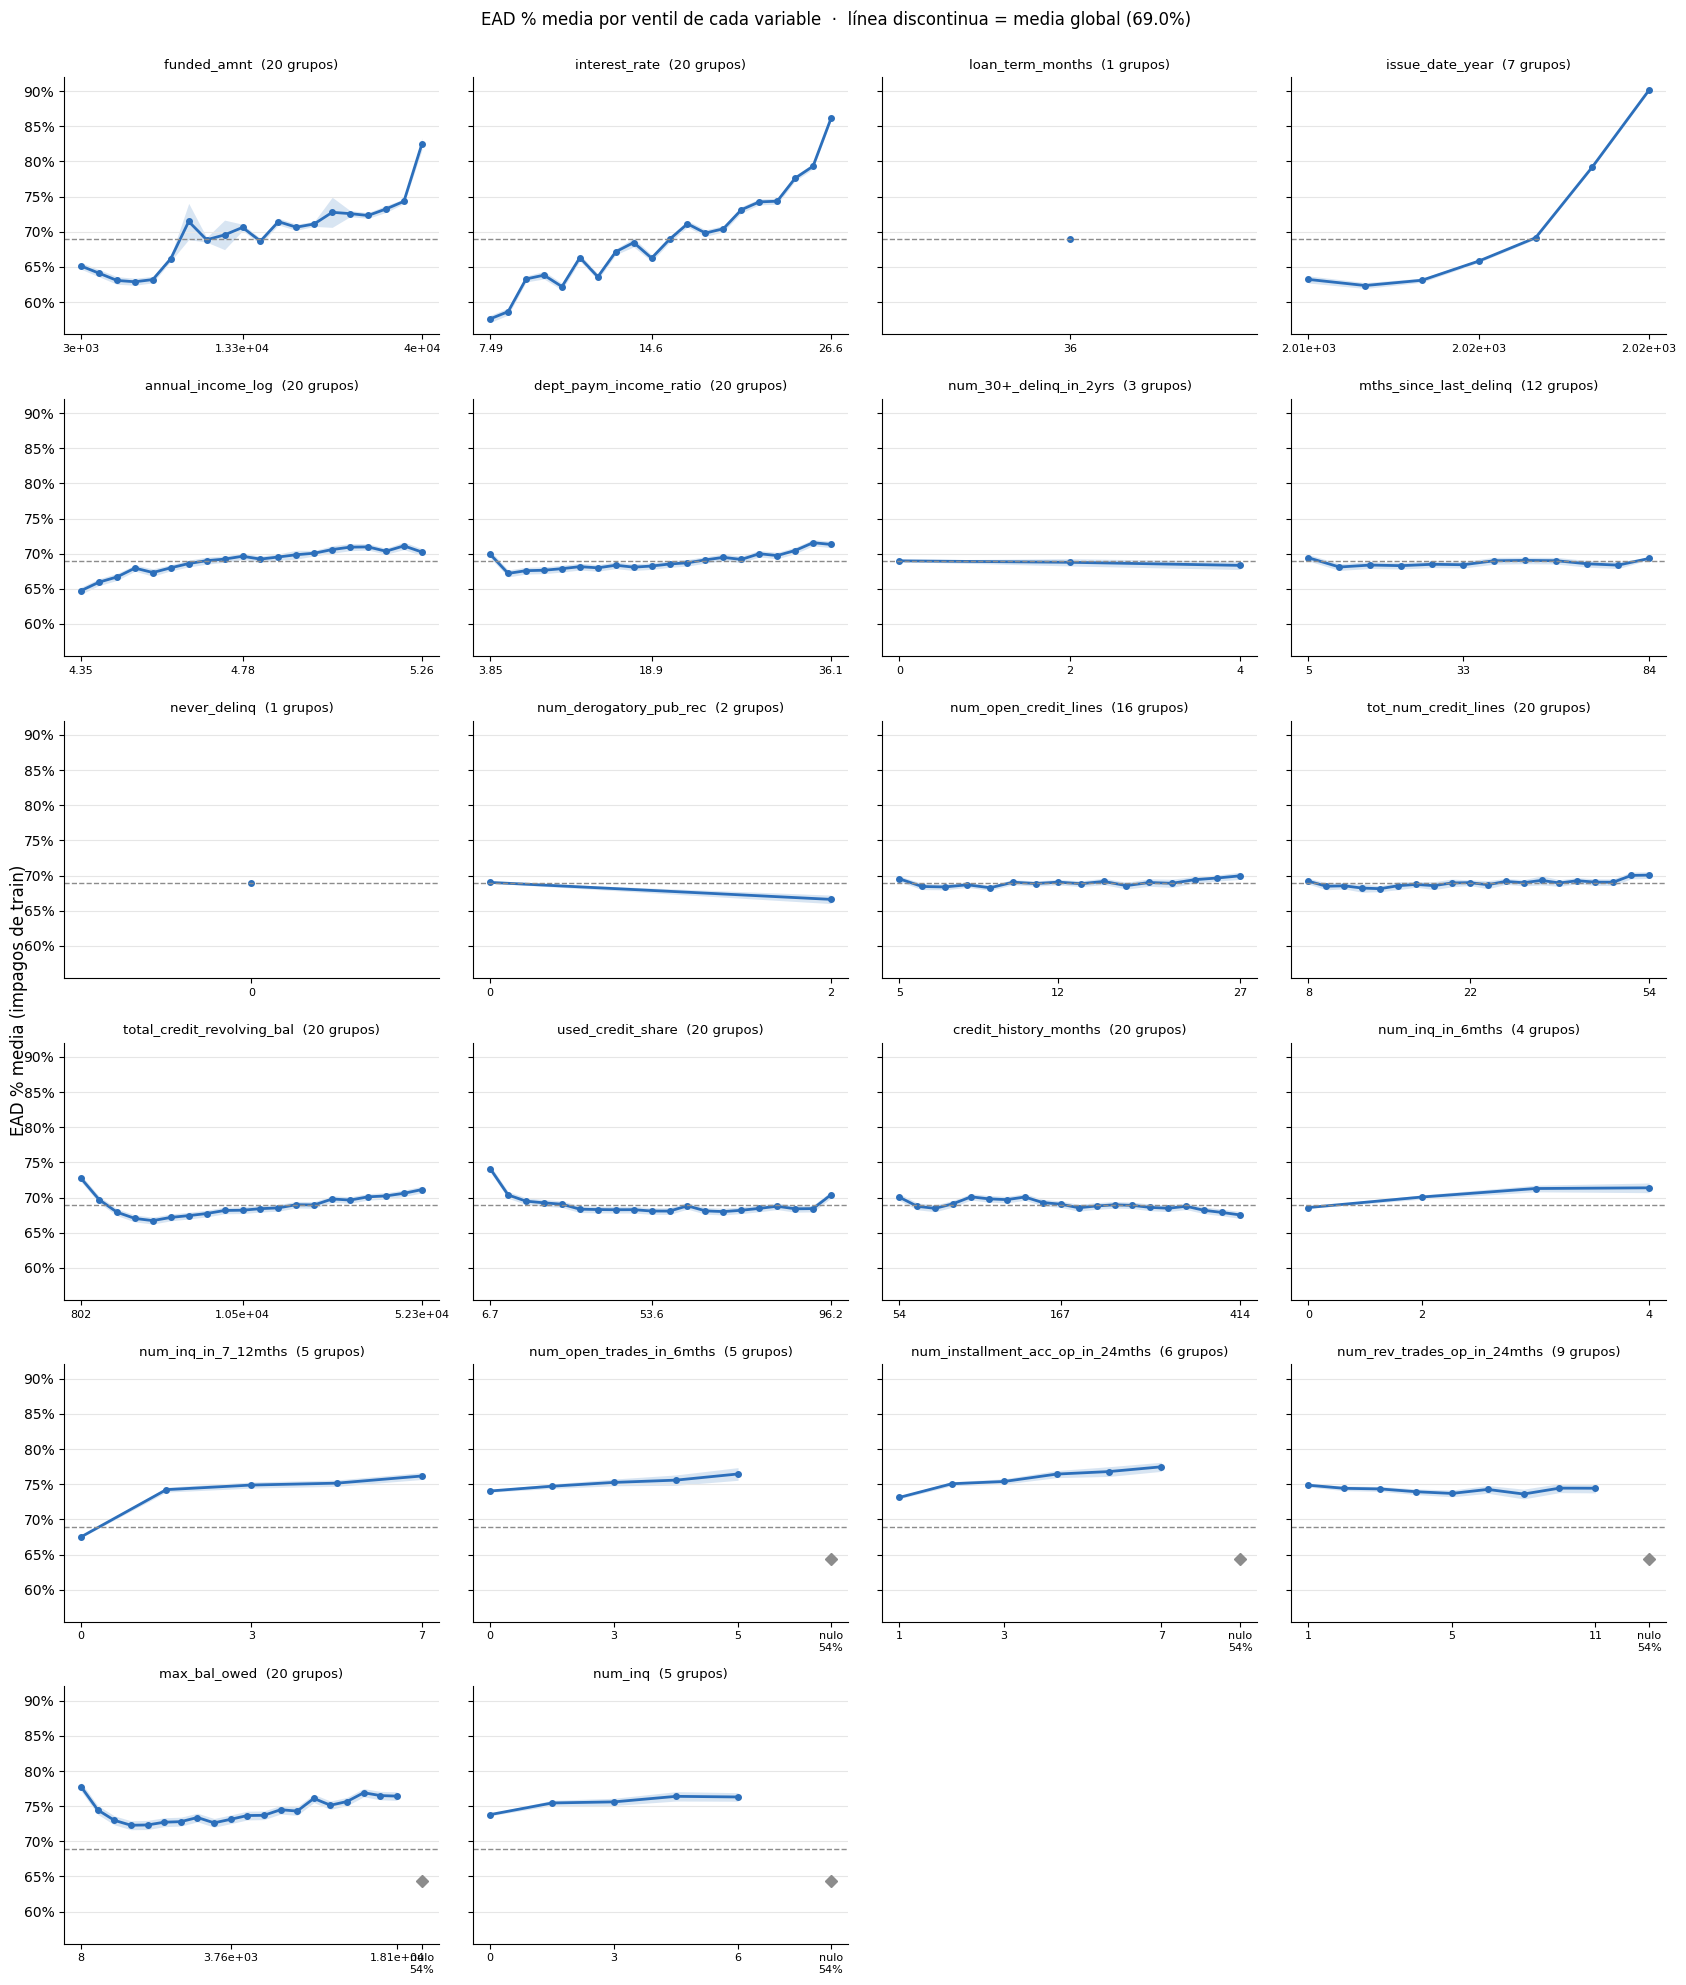

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

COLOR = "#2c6fbb"      # una sola serie por gráfica: un único color
GRIS = "#8c8c8c"

media_global = y_train_EAD.mean()
n_cols = 4
n_filas = int(np.ceil(len(NUM_EAD) / n_cols))
fig, ejes = plt.subplots(n_filas, n_cols, figsize=(4.3 * n_cols, 3.3 * n_filas), sharey=True)

ventiles_ead = {}
for ax, c in zip(ejes.flat, NUM_EAD):
    x = X_train_EAD[c].astype("float64")
    validos = x.notna()

    # Ventiles (con muchos valores repetidos salen menos de 20 grupos: duplicates="drop")
    grupos = pd.qcut(x[validos], 20, duplicates="drop")
    t = y_train_EAD[validos].groupby(grupos, observed=True).agg(n="size", media="mean", sd="std")
    t["valor_mediano"] = x[validos].groupby(grupos, observed=True).median()
    t["ic95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
    ventiles_ead[c] = t

    pos = np.arange(1, len(t) + 1)
    ax.fill_between(pos, t["media"] - t["ic95"], t["media"] + t["ic95"], color=COLOR, alpha=0.18, lw=0)
    ax.plot(pos, t["media"], color=COLOR, lw=2, marker="o", ms=4)

    # Etiquetas del eje x: valor mediano del primer, el central y el último grupo
    ticks = sorted({1, (len(t) + 1) // 2, len(t)})
    etiquetas = [f"{t['valor_mediano'].iloc[i - 1]:,.3g}" for i in ticks]

    # Los nulos, como un punto aparte a la derecha (relevante en el bloque de buró)
    if (~validos).any():
        x_nulo = len(t) + 1.5
        ax.plot(x_nulo, y_train_EAD[~validos].mean(), marker="D", color=GRIS, ms=6)
        ticks.append(x_nulo)
        etiquetas.append(f"nulo\n{(~validos).mean():.0%}")

    ax.axhline(media_global, color=GRIS, lw=1, ls="--")
    ax.set_xticks(ticks, etiquetas, fontsize=8)
    ax.set_title(f"{c}  ({len(t)} grupos)", fontsize=9.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)

for ax in ejes.flat[len(NUM_EAD):]:
    ax.set_visible(False)

fig.supylabel("EAD % media (impagos de train)")
fig.suptitle(f"EAD % media por ventil de cada variable  ·  línea discontinua = media global ({media_global:.1%})", y=1.0)
plt.tight_layout()
plt.savefig("ead_por_ventiles.png", dpi=150, bbox_inches="tight")
plt.show()

En este gráfico se muestra la media de $EAD\%$ por ventil de cada variable numérica, donde la línea discontinua muestra la media global.

En primer lugar, observamos que las variables que muestran un mayor cambio para la media de $EAD\%$ en función de sus ventiles son justamente la variables que mayores correlaciones mostraban en el análisis anterior. Además, la tendencia que observamos es aproximadamente monótona no decreciente, reflejando los valores de correlación positiva que obtuvimos.

Por otro lado, tenemos variables cuya gráfica es prácticamente horizontal, es decir, la media de $EAD\%$ es aproximadamente constante a lo largo de los ventiles de estas. Por tanto, estas variables tendrán bajo poder predictivo por sí solas y solo aportaran al modelo en caso de haber interacciones con otras variables.

Finalmente, cabe destacar que para las variables `loan_term_months`y `never_delinq` solo vemos un punto ya que ambas variables solo toman dos valores distintos a pesar de estar consideradas como numéricas.

Estudiamos ahora el ratio de correlación $\eta^2$ de las variables categóricas frente a la $EAD\%$.

Recordar que $\eta^2$ es el $R^2$ de una regresión lineal por mínimos cuadrados de la $EAD\%$ sobre las dummies de las categorías de cada variable.
Así mismo, $\eta^2$ ajustado sería el $R^2$ ajustado.

In [ ]:
def eta2_cat(g, y):
    """η² y η² ajustada de un target continuo y sobre una variable categórica g."""
    medias = y.groupby(g).transform("mean")
    eta2 = ((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    n, k = len(y), g.nunique()
    return eta2, 1 - (1 - eta2) * (n - 1) / (n - k)

def con_nulos(s):
    """Los nulos pasan a ser una categoría propia."""
    return s.astype(object).fillna("(nulo)")

plazo_train = X_train_EAD["loan_term_months"]
filas = []
for c in CAT_EAD:
    g_tr = con_nulos(X_train_EAD[c])
    eta2, eta2_aj = eta2_cat(g_tr, y_train_EAD)
    filas.append({
        "variable": c,
        "categorias": g_tr.nunique(),
        "eta2": eta2, "eta2_ajustada": eta2_aj,
        "eta2_36m": eta2_cat(g_tr[plazo_train == 36], y_train_EAD[plazo_train == 36])[0],
        "eta2_60m": eta2_cat(g_tr[plazo_train == 60], y_train_EAD[plazo_train == 60])[0],
        "n_categoria_min": g_tr.value_counts().min(),
        "pct_nulos": X_train_EAD[c].isna().mean(),
    })

asociacion_cat_ead = pd.DataFrame(filas).sort_values("eta2_ajustada", ascending=False).reset_index(drop=True)
display(asociacion_cat_ead.style
        .format({"eta2": "{:.4f}", "eta2_ajustada": "{:.4f}", "eta2_36m": "{:.4f}", "eta2_60m": "{:.4f}",
                 "n_categoria_min": "{:,}", "pct_nulos": "{:.1%}"})
        .background_gradient(subset=["eta2_ajustada"], cmap="Blues"))

,variable,categorias,eta2,eta2_ajustada,eta2_36m,eta2_60m,n_categoria_min,pct_nulos
0,grade,35,0.0831,0.0829,0.0350,0.0398,376,0.0%
1,mths_since_last_installment_acc_op_cat,12,0.0527,0.0527,0.0612,0.1193,"2,471",0.0%
2,bal_to_cred_lim_cat,6,0.0514,0.0514,0.0605,0.1187,"1,166",0.0%
3,initial_list_status,2,0.0088,0.0088,0.0004,0.0157,"67,958",0.0%
4,loan_purpose,14,0.0049,0.0048,0.0080,0.0057,60,0.0%
5,emp_ambito,25,0.0043,0.0042,0.0019,0.0076,573,0.0%
6,verification_status,3,0.0035,0.0035,0.0019,0.0005,"37,667",0.0%
7,disbursement_method,2,0.0017,0.0017,0.0022,0.0021,"1,040",0.0%
8,emp_length_cat,10,0.0013,0.0012,0.0016,0.0032,"6,295",0.0%
9,issue_date_month,12,0.0012,0.0011,0.0016,0.0018,"11,366",0.0%


In [ ]:
# η² de grade dentro de cada ventil de interest_rate: ¿explica algo que el tipo de interés no explique ya?
ventiles_tipo = pd.qcut(X_train_EAD["interest_rate"], 20, labels=False, duplicates="drop")
grade_tr = con_nulos(X_train_EAD["grade"])
eta2_dentro = [eta2_cat(grade_tr[ventiles_tipo == v], y_train_EAD[ventiles_tipo == v])[0]
               for v in sorted(ventiles_tipo.dropna().unique())]
print(f"η² de grade (global): {eta2_cat(grade_tr, y_train_EAD)[0]:.4f}")
print(f"η² por ventiles de interest_rate: {eta2_ventiles(X_train_EAD['interest_rate'].astype(float), y_train_EAD):.4f}")
print(f"η² media de grade dentro de cada ventil de interest_rate: {np.mean(eta2_dentro):.4f}")

η² de grade (global): 0.0831
η² por ventiles de interest_rate: 0.0951
η² media de grade dentro de cada ventil de interest_rate: 0.0402


Observamos que la variable que mayor variabilidad de la $EAD\%$ explica entre las categóricas es `grade`, con un 8.31% de varianza explicada. Sin embargo, recordemos que `grade` está muy relacionada con `interest_rate`, ya que Lending Club fija el tipo de interés a partir del sub-grade. De hecho, `interest_rate`, agrupada en ventiles, explica por sí sola un 9.51 % de la varianza de la $EAD\%$, algo más que `grade`.

Al calcular la media del $\eta^2$ de `grade` sobre cada ventil de `interest_rate` obtenemos un valor de 0.0402, lo cual nos dice que entre préstamos con tipo de interés parecido, `grade` consigue explicar en media un 4% de la varianza de $EAD\%$, la mitad de lo que conseguía de forma global. Por tanto, concluimos que `grade` sí aporta información adicional.

Incluir las dos en un modelo lineal afectaría a su estabilidad debido a la alta colinealidad que presentan estas variables. Sin embargo, para modelos basádos en árboles esto no afectaría a la calidad de las predicciones pero sí a sus interpretaciones.

A continuación añadimos a este análisis la variable `issue_date_year` para estudiar si `grade` sigue explicando variabilidad de la target una vez conocidas `interest_rate` e `issue_date_year`.

Para ello, estudiamos la variación que sufre el $R^2$ de una regresión lineal cuya target es $EAD\%$ en función de cuáles de las variables `grade`, `issue_date_year` e `interest_rate` se combinen para predecirla.

In [ ]:
ventil_tipo = pd.qcut(X_train_EAD["interest_rate"], 20, labels=False, duplicates="drop").astype("Int64").astype(str)
anio = X_train_EAD["issue_date_year"].astype("Int64").astype(str)
grade_tr = con_nulos(X_train_EAD["grade"]).astype(str)

def r2_grupos(clave):
    """R² de un modelo con una media distinta para cada combinación de categorías (= η² de la combinación)."""
    return eta2_cat(clave, y_train_EAD)[0]

r2_v = r2_grupos(ventil_tipo)
r2_vg = r2_grupos(ventil_tipo + "_" + grade_tr)
r2_va = r2_grupos(ventil_tipo + "_" + anio)
r2_vag = r2_grupos(ventil_tipo + "_" + anio + "_" + grade_tr)

print(f"Incremento de grade con interacción, sobre interest_rate:        {r2_vg - r2_v:+.4f}")
print(f"Incremento de grade con interacción, sobre interest_rate × año:  {r2_vag - r2_va:+.4f}")
print(f"Combinaciones usadas: ventil×grade = {(ventil_tipo + grade_tr).nunique()} | "
      f"ventil×año×grade = {(ventil_tipo + anio + grade_tr).nunique()}")

Incremento de grade con interacción, sobre interest_rate:        +0.0337
Incremento de grade con interacción, sobre interest_rate × año:  +0.0054
Combinaciones usadas: ventil×grade = 261 | ventil×año×grade = 774


El análisis de la variación del $R^2$ al considerar interacciones con los ventiles de `interest_rate` refuerza la conclusión obtenida anteriormente a partir de la $\eta^2$: entre préstamos con un tipo de interés similar, añadir la información de `grade` explica un 3.37 % adicional de la variabilidad de la $EAD\%$.

Sin embargo, al considerar también las interacciones con el año de emisión, la información de `grade` se vuelve redundante: el $R^2$ solo aumenta en 0.0054, y parte de ese aumento se debe al elevado número de combinaciones consideradas.

Por tanto, concluimos que es suficiente con incluir en los modelos las variables `interest_rate` e `issue_date_year` y descartamos `grade`, siempre que el modelo pueda captar la interacción entre ambas, como ocurre con los modelos basados en árboles. En un modelo lineal habría que añadir explícitamente el término de interacción `interest_rate` × `issue_date_year`.

### Métricas


Las métricas a considerar a la hora de modelar $EAD\%$ son las siguientes.

Notación: para cada impago $j$ del conjunto evaluado ($n$ préstamos), $y_j$ es la $EAD\%$ observada, $\hat{y}_j$ la predicha y $F_j$ el importe concedido (`funded_amnt`). La $EAD$ en dólares es $EAD_j = y_j \cdot F_j$ (real) y $\widehat{EAD}_j = \hat{y}_j \cdot F_j$ (predicha).

**Precisión en porcentaje**

- **MAE (%)**, error absoluto medio: $\frac{1}{n}\sum_j |y_j - \hat{y}_j|$. Es el error típico de la predicción en puntos porcentuales de $EAD\%$. Por ejemplo, un MAE del 15 % significa que, de media, la predicción se equivoca en 15 puntos de la fracción pendiente.
- **RMSE (%)**, raíz del error cuadrático medio: $\sqrt{\frac{1}{n}\sum_j (y_j - \hat{y}_j)^2}$. Penaliza más los errores grandes. Si es mucho mayor que el MAE, el modelo comete errores grandes en algunos préstamos.
- **$R^2$**: $1 - \frac{\sum_j (y_j - \hat{y}_j)^2}{\sum_j (y_j - \bar{y})^2}$. Proporción de la varianza de la $EAD\%$ que explica el modelo. Vale 0 para un modelo que predice siempre la media, así que mide cuánto mejora el modelo respecto a no usar ninguna variable.

**Precisión en dólares**

- **MAE (\$)**: $\frac{1}{n}\sum_j |EAD_j - \widehat{EAD}_j|$. Es el error medio en dólares. Es la métrica más cercana a la evaluación del reto, que se hace sobre la $ECL$ en dólares: un error de 1 punto en un préstamo de 40 000 \$ cuesta 400 \$, y en uno de 1 000 \$ solo 10 \$. Dos modelos con el mismo MAE en porcentaje pueden diferir en dólares si uno se equivoca más en los préstamos grandes.

**Sesgo y calibración**

- **EAD total predicha / real**: $\frac{\sum_j \widehat{EAD}_j}{\sum_j EAD_j}$. Indica si el modelo sobrestima (mayor que 1) o infraestima (menor que 1) la exposición total de la cartera. Es la métrica más directamente ligada a la $ECL$ total del reto, y por el sesgo conservador interesa que quede en 1 o ligeramente por encima.
- **Error de calibración**: los préstamos se ordenan por la $EAD\%$ predicha y se dividen en deciles. En cada decil se compara la $EAD\%$ media predicha con la observada, y se suman las diferencias en valor absoluto. Un modelo puede acertar en el total y aun así sobrestimar en unos grupos e infraestimar en otros; esta métrica lo detecta.
- **Préstamos infraestimados**: proporción de impagos con $\widehat{EAD}_j < EAD_j$. Es informativa, pero no tiene por qué ser inferior al 10 %: la restricción del reto se aplica a la ECL completa ($PD \times LGD \times EAD$) y se gestiona en la capa final de calibración, no en cada modelo por separado.

Todas las métricas se calculan en validación. Para elegir modelo nos fijamos principalmente en el **MAE en dólares** y en el **cociente EAD total predicha / real**, que son las más cercanas a cómo se evaluará la $ECL$. Las métricas en porcentaje sirven para entender el comportamiento del modelo y compararlo con los modelos de referencia.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas_ead(y_pct, pred_pct, funded):
    """Métricas de la EAD en % y en $, más calibración por deciles de la predicción."""
    y_pct = np.asarray(y_pct, dtype=float)
    pred_pct = np.clip(np.asarray(pred_pct, dtype=float), 0, 1)
    funded = np.asarray(funded, dtype=float)
    ead_real, ead_pred = y_pct * funded, pred_pct * funded
    calib = (pd.DataFrame({"pred": pred_pct, "real": y_pct})
             .assign(decil=lambda d: pd.qcut(d["pred"], 10, labels=False, duplicates="drop"))
             .groupby("decil").agg(pred_media=("pred", "mean"), real_media=("real", "mean")))
    return {"MAE_%": mean_absolute_error(y_pct, pred_pct),
            "RMSE_%": np.sqrt(mean_squared_error(y_pct, pred_pct)),
            "R2_%": r2_score(y_pct, pred_pct),
            "MAE_$": mean_absolute_error(ead_real, ead_pred),
            "EAD_total_pred/real": ead_pred.sum() / ead_real.sum(),
            "error_calibracion": (calib["pred_media"] - calib["real_media"]).abs().sum(),
            "infraestimados": (ead_pred < ead_real).mean()}

formatos_ead = {"MAE_%": "{:.2%}", "RMSE_%": "{:.2%}", "R2_%": "{:.4f}", "MAE_$": "{:,.0f}",
                "EAD_total_pred/real": "{:.4f}", "error_calibracion": "{:.2%}", "infraestimados": "{:.1%}"}

def tabla_ead(resultados):
    return pd.DataFrame(resultados).apply(lambda f: f.map(formatos_ead.get(f.name, "{:.4f}").format), axis=1)

funded_train_EAD = X_train_EAD["funded_amnt"]
funded_val_EAD = X_val_EAD["funded_amnt"]

### Modelo trivial: Media global de $EAD\%$

El modelo más sencillo que se puede plantear es aquel que asigna a cada préstamo la media global de $EAD\%$ observada en train y, por tanto, este será nuestro baseline.

Descartaremos todo modelo que no mejore a este.


In [ ]:
# Modelo 0: media global de train
media_global_ead = y_train_EAD.mean()
print(f"EAD% media de los impagos de train: {media_global_ead:.2%}")

pred_train_m0 = np.full(len(y_train_EAD), media_global_ead)
pred_val_m0 = np.full(len(y_val_EAD), media_global_ead)

display(tabla_ead({"train": metricas_ead(y_train_EAD, pred_train_m0, funded_train_EAD),
                   "val": metricas_ead(y_val_EAD, pred_val_m0, funded_val_EAD)}))

# Tabla donde se irán acumulando los modelos (en validación)
resultados_ead = {"0. media global": metricas_ead(y_val_EAD, pred_val_m0, funded_val_EAD)}

EAD% media de los impagos de train: 68.95%


,train,val
MAE_%,18.08%,18.11%
RMSE_%,22.19%,22.22%
R2_%,0.0000,-0.0000
MAE_$,"2,753","2,762"
EAD_total_pred/real,0.9720,0.9718
error_calibracion,0.00%,0.00%
infraestimados,58.2%,58.0%


Como era de esperar, este modelo obtiene métricas bastante pobres.

Observar que el error de calibración es $0$ ya que los deciles se ordenan por las predicciones y todas las predicciones son la media global, por tanto, la diferencia de la predicción media por decil a la media global es nula para cada decil. Además, como apuntábamos anteriormente obtenenemos un $R^2=0$.

### Modelo 1: Media por segmentos (tipo de interés × año de emisión)

Para este modelo simplemente consideramos las dos variables que mayor poder predictivo mostraron en el análisis exploratorio previo: `interest_rate` e `issue_date_year`.

Dividimos los impagos de train en segmentos según el ventil de su tipo de interés y su año de emisión, las dos variables que más varianza de la $EAD\%$ explican, y predecimos para cada préstamo la $EAD\%$ media de su segmento.

Este es el enfoque clásico de la $EAD$ en banca (modelos por *pools*), y al cruzar ambas variables recoge además su interacción: el efecto del tipo de interés sobre la $EAD\%$ cambia según el año de emisión.

In [ ]:
# Modelo 1: media de la EAD% por ventil de interest_rate × año de emisión (aprendida en train)
MIN_N_SEGMENTO = 200   # segmentos con menos impagos usan la media de su año
N_TRAMOS_TIPO = 20     # ventiles, como en el análisis de η²

# Cortes de los ventiles de interest_rate calculados en train (los extremos se abren para cubrir valores nuevos)
_, CORTES_TIPO = pd.qcut(X_train_EAD["interest_rate"], N_TRAMOS_TIPO, retbins=True, duplicates="drop")
CORTES_TIPO[0], CORTES_TIPO[-1] = -np.inf, np.inf

def segmento_ead(X):
    ventil = pd.cut(X["interest_rate"], CORTES_TIPO, labels=False).astype(int) + 1
    return (X["issue_date_year"].astype(int).astype(str) + "_v" + ventil.astype(str).str.zfill(2)).rename("segmento")

stats_seg = y_train_EAD.groupby(segmento_ead(X_train_EAD)).agg(n="size", media="mean")
media_seg = stats_seg.loc[stats_seg["n"] >= MIN_N_SEGMENTO, "media"]
media_anio = y_train_EAD.groupby(X_train_EAD["issue_date_year"].astype(int)).mean()

def predecir_segmentos(X):
    pred = segmento_ead(X).map(media_seg)
    respaldo = X["issue_date_year"].astype(int).map(media_anio)   # segmento pequeño o no visto en train
    return pred.fillna(respaldo).fillna(media_global_ead).to_numpy()

pred_train_m1 = predecir_segmentos(X_train_EAD)
pred_val_m1 = predecir_segmentos(X_val_EAD)

print(f"Segmentos en train: {len(stats_seg)} | con al menos {MIN_N_SEGMENTO} impagos: {len(media_seg)} "
      f"({stats_seg.loc[media_seg.index, 'n'].sum() / len(y_train_EAD):.1%} de los impagos)")
display(tabla_ead({"train": metricas_ead(y_train_EAD, pred_train_m1, funded_train_EAD),
                   "val": metricas_ead(y_val_EAD, pred_val_m1, funded_val_EAD)}))

# ===== Tabla de segmentos: EAD% media por año (filas) y ventil de tipo de interés (columnas) =====
print("\n")
print("Tabla de predicciones:")
print("\n")
tabla_seg = (stats_seg.reset_index()
             .assign(año=lambda d: d["segmento"].str.split("_").str[0],
                     ventil_tipo=lambda d: d["segmento"].str.split("_").str[1])
             .pivot(index="año", columns="ventil_tipo", values="media"))
display(tabla_seg.style.format("{:.1%}", na_rep="–").background_gradient(cmap="Blues", axis=None))

# ===== Comparación acumulada en validación =====
resultados_ead["1. tipo de interés × año"] = metricas_ead(y_val_EAD, pred_val_m1, funded_val_EAD)
display(tabla_ead(resultados_ead))

Segmentos en train: 224 | con al menos 200 impagos: 129 (97.0% de los impagos)


,train,val
MAE_%,15.74%,15.82%
RMSE_%,19.90%,20.02%
R2_%,0.1954,0.1884
MAE_$,"2,341","2,349"
EAD_total_pred/real,0.9837,0.9844
error_calibracion,0.12%,2.97%
infraestimados,56.6%,57.0%




Tabla de predicciones:




ventil_tipo,v01,v02,v03,v04,v05,v06,v07,v08,v09,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20
año,,,,,,,,,,,,,,,,,,,,
2007,27.2%,75.4%,50.9%,72.8%,69.2%,72.1%,66.9%,58.9%,56.1%,79.7%,64.2%,68.6%,58.2%,61.2%,–,–,–,–,–,–
2008,44.5%,54.9%,68.6%,58.0%,61.9%,72.9%,67.9%,59.8%,60.2%,60.9%,68.4%,63.1%,72.2%,62.2%,68.4%,67.7%,–,–,–,–
2009,47.9%,61.1%,62.2%,57.9%,64.9%,64.4%,69.5%,63.9%,63.5%,64.6%,72.7%,67.6%,62.8%,73.4%,62.1%,75.5%,62.0%,27.9%,–,–
2010,49.4%,62.5%,59.1%,65.6%,57.6%,70.4%,62.8%,65.2%,68.1%,65.2%,67.0%,67.5%,68.4%,71.8%,65.3%,68.3%,77.6%,75.8%,–,–
2011,57.8%,54.2%,57.9%,60.4%,62.3%,60.9%,65.0%,67.3%,59.3%,66.9%,62.6%,66.3%,67.0%,67.9%,70.3%,73.2%,75.8%,73.8%,79.4%,–
2012,53.3%,56.7%,55.2%,58.1%,57.0%,60.5%,58.9%,59.2%,59.4%,60.9%,61.9%,61.8%,64.8%,62.4%,63.8%,67.9%,69.0%,71.1%,73.2%,–
2013,50.6%,52.2%,53.8%,51.8%,54.6%,58.3%,55.6%,56.7%,57.0%,59.1%,60.2%,62.1%,64.5%,64.2%,63.8%,63.4%,65.4%,70.4%,73.2%,76.3%
2014,49.1%,52.0%,53.3%,58.3%,55.0%,56.2%,59.3%,58.6%,60.4%,61.1%,63.0%,64.0%,65.1%,66.2%,67.4%,68.5%,69.2%,73.3%,75.1%,79.2%
2015,51.8%,54.2%,58.1%,57.9%,59.7%,61.6%,62.8%,64.8%,65.3%,64.4%,66.9%,66.0%,68.8%,71.5%,73.1%,75.0%,75.8%,78.5%,80.5%,83.2%


,0. media global,1. tipo de interés × año
MAE_%,18.11%,15.82%
RMSE_%,22.22%,20.02%
R2_%,-0.0000,0.1884
MAE_$,"2,762","2,349"
EAD_total_pred/real,0.9718,0.9844
error_calibracion,0.00%,2.97%
infraestimados,58.0%,57.0%


En la tabla se muestran la media de $EAD\%$ para cada combinación año-decil aprendida en train, con lo que el modelo predice en base a esta y bajo las siguientes consideraciones:
*  **Predice con la media del segmento:** si el segmento existe en train y tiene al menos 200 impagos.
* **Predice con la media del año de emisión:** si el segmento no existe en train (una casilla vacía) o tiene menos de 200 impagos.
* **Predice con la media global:** solo si el año del préstamo no aparece en train. Tener en cuenta que con un split aleatorio es prácticamente imposible que se de esta situación.

En cuanto a las métricas, destacamos que este modelo consigue reducir el $MAE(\$)$ en comparación con el obtenido con el modelo trivial, así como aumentar el $R^2$ hasta un valor de 0,1884.

Sin embargo, estas métricas se pueden mejorar mucho más, lo que motiva continuar buscando modelos que ofrezcan un mejor rendimiento.

### Modelo 2: Regresión logística fraccional

La $EAD\%$ es una variable continua acotada en $[0,1]$, con observaciones en ambos extremos. Para modelizarla mediante un modelo lineal generalizado empleamos una **regresión logística fraccional** (Papke y Wooldridge, 1996), que especifica únicamente la media condicionada mediante la función logística:

$$\mathbb{E}[EAD\% \mid \mathbf{x}] = \frac{1}{1 + e^{-\mathbf{x}^\top\boldsymbol{\beta}}}$$

**Qué tiene en común con la regresión logística:**

 El modelo y el algoritmo de estimación son los mismos: los coeficientes se obtienen maximizando la log-verosimilitud de Bernoulli, como si la variable respuesta fuera binaria.

**Qué la diferencia:**

- **Interpretación de la predicción:** En la regresión logística, la predicción es la probabilidad de que $y = 1$. Aquí es la $EAD\%$ media esperada para los préstamos con ese perfil, no una probabilidad.
- **Justificación del método:** Aunque la $EAD\%$ no es binaria, la verosimilitud de Bernoulli alcanza su máximo justo en la media verdadera. Por eso los coeficientes son consistentes siempre que la media esté bien especificada (es decir, que exista $\beta_0$ tal que $\mathbb{E}[EAD\% \mid \mathbf{x}] = sigmoid(\mathbf{x}^\top\boldsymbol{\beta}_0)$), sin necesidad de suponer ninguna distribución para la $EAD\%$.
- **Errores estándar:** La varianza de una variable fraccional es menor que la de una Bernoulli, así que los errores estándar habituales no son válidos. Usamos errores estándar robustos (matriz sándwich).

**Por qué este modelo.**

 Las predicciones quedan siempre en $[0,1]$ y admite directamente los impagos con $EAD\%$ igual a 0 o a 1, sin eliminarlos ni transformarlos. Frente a la regresión lineal, las predicciones no salen del intervalo $[0,1]$.


**Forma de proceder.**

Ajustamos la regresión logística fraccional con todas las variables candidatas para la EAD (`NUM_EAD` y `CAT_EAD`) excepto `grade`, cuya información recogen el tipo de interés y el año de emisión, como vimos en el análisis anterior. A partir de este modelo completo, trataremos de simplificarlo eliminando las variables que menos aporten a la predicción.

- **Tipo de interés y año de emisión** entran junto con su interacción: el año se incluye como variable categórica y la interacción permite que el efecto del tipo de interés cambie de un año a otro.
- **Importe concedido** (`funded_amnt`) entra en logaritmo. Su distribución es muy asimétrica (de unos 1 000 \$ a 40 000 \$, con la mayoría de préstamos en la parte baja), y en escala original los préstamos muy grandes tendrían un peso desproporcionado en la estimación. Además, lo relevante es la diferencia relativa entre importes: pasar de $2 000 \$$ a $4 000 \$$ supone un cambio mayor en el perfil del préstamo que pasar de $30 000 \$$ a $32000 \$$.
- **Resto de variables numéricas:** se imputan con la mediana de train, llevan un indicador de nulo y se estandarizan con la media y la desviación típica de train. Las variables que comparten exactamente el mismo patrón de nulos, como las del bloque de buró, usan un único indicador para evitar colinealidad perfecta.
- **Variables categóricas:** en lugar de crear una dummy por categoría, cada categoría se sustituye por la $EAD\%$ media observada en ella. Es una codificación análoga a la WoE que usamos en la PD, pero construida con el target de la EAD, y reduce cada variable categórica a una sola columna numérica. Para que sea fiable:
    - las categorías con pocos impagos se acercan a la media global mediante suavizado: $\frac{n \cdot \bar{y}_{cat} + m \cdot \bar{y}}{n + m}$, con $m = 100$.
    - en train, la codificación se calcula fuera de muestra (en 5 bloques), de modo que la $EAD\%$ de cada préstamo no interviene en su propio valor codificado. En validación y test se usa la media calculada con todo train.
    - una categoría que no aparezca en train recibe la media global.

In [ ]:
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# ===== Variables =====
NUM_GLM = [c for c in NUM_EAD if c not in ("interest_rate", "issue_date_year", "funded_amnt")] + ["funded_amnt_log"]
CAT_GLM = [c for c in CAT_EAD if c != "grade"]
SUAVIZADO_TE = 100     # m: peso de la media global en categorías con pocos impagos
ALFA = 0.05            # nivel de significación global (corrección de Bonferroni)

# Bloque de nulos estructurales

BLOQUE_BURO = ["num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
               "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq"]

# ===== Codificación por la EAD% media de cada categoría (target encoding suavizado) =====
def con_nulos_str(s):
    return s.astype(object).where(s.notna(), "(nulo)").astype(str)

def ajustar_te(x, y, m=SUAVIZADO_TE):
    """Media suavizada de y por categoría: (n·media + m·media_global) / (n + m)."""
    media_global = y.mean()
    stats = y.groupby(x).agg(["sum", "count"])
    return (stats["sum"] + m * media_global) / (stats["count"] + m), media_global

def aplicar_te(x, mapa, media_global):
    return x.map(mapa).fillna(media_global).astype(float)        # categoría no vista -> media global

cats_tr = {c: con_nulos_str(X_train_EAD[c]) for c in CAT_GLM}

# Train: codificación fuera de muestra (5 bloques), para que cada préstamo no use su propia EAD%
TE_TRAIN = pd.DataFrame(index=X_train_EAD.index, columns=[f"te_{c}" for c in CAT_GLM], dtype=float)
for idx_ajuste, idx_aplica in KFold(5, shuffle=True, random_state=SEED).split(X_train_EAD):
    i_aj, i_ap = X_train_EAD.index[idx_ajuste], X_train_EAD.index[idx_aplica]
    for c in CAT_GLM:
        mapa, mg = ajustar_te(cats_tr[c].loc[i_aj], y_train_EAD.loc[i_aj])
        TE_TRAIN.loc[i_ap, f"te_{c}"] = aplicar_te(cats_tr[c].loc[i_ap], mapa, mg).to_numpy()

# Validación y test: codificación con todo train
MAPAS_TE = {c: ajustar_te(cats_tr[c], y_train_EAD) for c in CAT_GLM}

def te_completo(X):
    return pd.DataFrame({f"te_{c}": aplicar_te(con_nulos_str(X[c]), *MAPAS_TE[c]) for c in CAT_GLM}, index=X.index)

# ===== Numéricas: imputación, indicadores de nulo y estandarización aprendidos en train =====
def numericas_glm(X):
    d = X[["interest_rate"] + [c for c in NUM_GLM if c != "funded_amnt_log"]].astype(float).copy()
    d["funded_amnt_log"] = np.log(X["funded_amnt"].astype(float))
    return d

num_tr = numericas_glm(X_train_EAD)
MEDIANAS_GLM = num_tr.median()

# Un indicador por patrón de nulos distinto, y ninguno si equivale a una binaria existente (o a su complementaria)
binarias_tr = [num_tr[c].fillna(-1).astype(int) for c in num_tr.columns
               if set(num_tr[c].dropna().unique()) <= {0, 1}]
GRUPOS_NULOS, patrones_vistos = [], []
for c in num_tr.columns:
    nulos = num_tr[c].isna()
    if not nulos.any() or any(nulos.equals(p) for p in patrones_vistos):
        continue
    n_int = nulos.astype(int)
    if any(n_int.equals(b) or n_int.equals(1 - b) for b in binarias_tr):
        continue
    patrones_vistos.append(nulos)
    GRUPOS_NULOS.append(("nulo_bloque_buro" if c in BLOQUE_BURO else f"nulo_{c}", c))

MODA_AÑO = X_train_EAD["issue_date_year"].astype(int).astype(str).mode()[0]
NIVELES_AÑO = [MODA_AÑO] + sorted(a for a in X_train_EAD["issue_date_year"].astype(int).astype(str).unique()
                                    if a != MODA_AÑO)      # el primer nivel es la referencia: el año más frecuente

def datos_glm(X, te, y=None):
    """Numéricas imputadas, indicadores de nulo, categóricas codificadas (te) y año."""
    num = numericas_glm(X)
    d = pd.concat([num.fillna(MEDIANAS_GLM), te], axis=1)
    for nombre, c in GRUPOS_NULOS:
        d[nombre] = num[c].isna().astype(float)
    año = X["issue_date_year"].astype(int).astype(str)
    d["año"] = año.where(año.isin(NIVELES_AÑO), MODA_AÑO)
    if y is not None:
        d["ead_pct"] = y
    return d

datos_tr = datos_glm(X_train_EAD, TE_TRAIN, y_train_EAD)
COLS_ESTANDAR = list(num_tr.columns) + list(TE_TRAIN.columns)
MEDIAS_GLM = datos_tr[COLS_ESTANDAR].mean()
DESV_GLM = datos_tr[COLS_ESTANDAR].std().replace(0, 1)       # columnas constantes: se centran pero no se escalan

def estandarizar(d):
    d = d.copy()
    d[COLS_ESTANDAR] = (d[COLS_ESTANDAR] - MEDIAS_GLM) / DESV_GLM
    return d

datos_tr = estandarizar(datos_tr)
datos_va = estandarizar(datos_glm(X_val_EAD, te_completo(X_val_EAD)))

# ===== Fórmula y ajuste con errores estándar robustos =====
terminos = (["interest_rate * C(año, levels=NIVELES_AÑO)"]
            + [f"Q('{c}')" for c in NUM_GLM]
            + [nombre for nombre, _ in GRUPOS_NULOS]
            + list(TE_TRAIN.columns))
FORMULA_EAD = "ead_pct ~ " + " + ".join(terminos)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # aviso esperado: target no binario (regresión fraccional)
    modelo_ead_rl = smf.glm(FORMULA_EAD, data=datos_tr, family=sm.families.Binomial()).fit(cov_type="HC0")  #cov_type="HC0" para usar errores estándar robustos
print(f"Convergió: {modelo_ead_rl.converged} | parámetros estimados: {len(modelo_ead_rl.params)}")

pred_train_m2 = modelo_ead_rl.predict(datos_tr).to_numpy()
pred_val_m2 = modelo_ead_rl.predict(datos_va).to_numpy()

display(tabla_ead({"train": metricas_ead(y_train_EAD, pred_train_m2, funded_train_EAD),
                   "val": metricas_ead(y_val_EAD, pred_val_m2, funded_val_EAD)}))

# ===== Coeficientes con p-valores e intervalos ajustados por Bonferroni =====
coefs = modelo_ead_rl.summary2().tables[1].drop(index="Intercept", errors="ignore")
m_contrastes = len(coefs)                                   # todos los coeficientes salvo la constante
z_crit = norm.ppf(1 - ALFA / (2 * m_contrastes))            # valor crítico corregido (en lugar de 1,96)

tabla_coefs = pd.DataFrame({
    "coef": coefs["Coef."],
    "error_std": coefs["Std.Err."],
    "z": coefs["z"],
    "p_valor_bonferroni": multipletests(coefs["P>|z|"], alpha=ALFA, method="bonferroni")[1],
    "ic_inf_bonferroni": coefs["Coef."] - z_crit * coefs["Std.Err."],
    "ic_sup_bonferroni": coefs["Coef."] + z_crit * coefs["Std.Err."],
})
tabla_coefs["significativo"] = tabla_coefs["p_valor_bonferroni"] < ALFA

print(f"Contrastes: {m_contrastes} | valor crítico z: {z_crit:.2f} | "
      f"significativos tras Bonferroni: {tabla_coefs['significativo'].sum()} de {m_contrastes}")

# Variables ordenadas por tamaño del efecto (sin las dummies de año ni la interacción, que se cuentan pero no se muestran)
tabla_vars = tabla_coefs.loc[[i for i in tabla_coefs.index if not i.startswith(("C(", "interest_rate:"))]]
display(tabla_vars.reindex(tabla_vars["coef"].abs().sort_values(ascending=False).index)
        .style.format({"coef": "{:+.4f}", "error_std": "{:.4f}", "z": "{:+.2f}", "p_valor_bonferroni": "{:.2e}",
                       "ic_inf_bonferroni": "{:+.4f}", "ic_sup_bonferroni": "{:+.4f}"}))

# ===== Comparación acumulada en validación =====
resultados_ead["2. logística fraccional"] = metricas_ead(y_val_EAD, pred_val_m2, funded_val_EAD)
display(tabla_ead(resultados_ead))

Convergió: True | parámetros estimados: 56


,train,val
MAE_%,15.06%,15.14%
RMSE_%,19.20%,19.32%
R2_%,0.2513,0.2445
MAE_$,"2,205","2,216"
EAD_total_pred/real,0.9998,1.0004
error_calibracion,5.98%,7.10%
infraestimados,55.5%,55.2%


Contrastes: 55 | valor crítico z: 3.32 | significativos tras Bonferroni: 32 de 55


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
nulo_bloque_buro,+0.3378,0.0639,+5.28,7.01e-06,+0.1257,+0.5499,True
interest_rate,+0.2776,0.0055,+50.83,0.00e+00,+0.2595,+0.2957,True
Q('loan_term_months'),+0.2737,0.0029,+94.41,0.00e+00,+0.2641,+0.2833,True
te_bal_to_cred_lim_cat,+0.1308,0.0260,+5.03,2.67e-05,+0.0446,+0.2171,True
te_mths_since_last_installment_acc_op_cat,+0.0575,0.0161,+3.57,1.95e-02,+0.0041,+0.1109,True
Q('num_open_credit_lines'),-0.0558,0.0036,-15.38,1.14e-51,-0.0679,-0.0438,True
Q('tot_num_credit_lines'),+0.0479,0.0037,+13.05,3.41e-37,+0.0358,+0.0601,True
Q('used_credit_share'),-0.0376,0.0028,-13.40,3.50e-39,-0.0469,-0.0283,True
Q('num_inq_in_6mths'),+0.0323,0.0027,+12.02,1.57e-31,+0.0234,+0.0413,True
Q('never_delinq'),+0.0300,0.0042,+7.08,7.76e-11,+0.0160,+0.0441,True


,0. media global,1. tipo de interés × año,2. logística fraccional
MAE_%,18.11%,15.82%,15.14%
RMSE_%,22.22%,20.02%,19.32%
R2_%,-0.0000,0.1884,0.2445
MAE_$,"2,762","2,349","2,216"
EAD_total_pred/real,0.9718,0.9844,1.0004
error_calibracion,0.00%,2.97%,7.10%
infraestimados,58.0%,57.0%,55.2%


Observamos que el $MAE\$$ y el $R^2$ mejoran con respecto al modelo de la media por segmentos. Sin embargo, empeora bastante en cuanto a error de calibración.

Si nos fijamos en la tabla que contiene los coeficientes, en esta se muestran también los p-valores y los intervalos de confianza ajustados por Bonferroni. Gracias a estos podemos distinguir entre variables significativas y no significarivas: aquellas con un p-valor ajustado inferior a 0.05 son significativas, pues hay evidencia estadística suficiente para asumir que su coeficiente asociado es distinto de cero.

Debemos tener en cuenta que el año de referencia es 2015,los coeficientes están en escala logit y las variables numéricas están estandarizadas, así que cada coeficiente es el efecto de aumentar la variable en una desviación típica.

**Variables significativas (19)**

| Variable | Coef. | IC Bonferroni | Efecto sobre $EAD\%$ |
|---|---|---|---|
| `nulo_bloque_buro` | +0.338 | [+0.126, +0.550] | ↑ |
| `interest_rate` (pendiente en 2015) | +0.278 | [+0.260, +0.296] | ↑ |
| `loan_term_months` | +0.274 | [+0.264, +0.283] | ↑ |
| `te_bal_to_cred_lim_cat` | +0.131 | [+0.045, +0.217] | ↑ |
| `te_mths_since_last_installment_acc_op_cat` | +0.058 | [+0.004, +0.111] | ↑ |
| `num_open_credit_lines` | −0.056 | [−0.068, −0.044] | ↓ |
| `tot_num_credit_lines` | +0.048 | [+0.036, +0.060] | ↑ |
| `used_credit_share` | −0.038 | [−0.047, −0.028] | ↓ |
| `num_inq_in_6mths` | +0.032 | [+0.023, +0.041] | ↑ |
| `never_delinq` | +0.030 | [+0.016, +0.044] | ↑ |
| `max_bal_owed` | +0.028 | [+0.018, +0.038] | ↑ |
| `te_issue_date_month` | +0.026 | [+0.019, +0.034] | ↑ |
| `te_emp_length_cat` | +0.022 | [+0.014, +0.031] | ↑ |
| `num_derogatory_pub_rec` | −0.022 | [−0.030, −0.014] | ↓ |
| `te_loan_purpose` | +0.019 | [+0.011, +0.027] | ↑ |
| `te_addr_state` | +0.019 | [+0.012, +0.027] | ↑ |
| `dept_paym_income_ratio` | +0.017 | [+0.008, +0.027] | ↑ |
| `credit_history_months` | −0.017 | [−0.026, −0.008] | ↓ |
| `num_rev_trades_op_in_24mths` | −0.012 | [−0.021, −0.003] | ↓ |


**Variables no significativas (14)**

`annual_income_log`, `num_installment_acc_op_in_24mths`, `total_credit_revolving_bal`, `te_initial_list_status`, `te_home_ownership_status`, `te_disbursement_method`, `log_importe`, `te_emp_ambito`, `num_30+_delinq_in_2yrs`, `mths_since_last_delinq`, `te_verification_status`, `num_inq`, `num_open_trades_in_6mths`, `num_inq_in_7_12mths`.

Las variables con prefijo `te_` son categóricas codificadas con *target encoding* (media de $EAD\%$ suavizada).


**Variables no significativas:** `annual_income_log`, `num_installment_acc_op_in_24mths`, `total_credit_revolving_bal`, `initial_list_status`, `home_ownership_status`, `disbursement_method`, `funded_amnt_log`, `emp_ambito`, `num_30+_delinq_in_2yrs`, `mths_since_last_delinq`, `verification_status`, `num_inq`, `num_open_trades_in_6mths` y `num_inq_in_7_12mths`.

El efecto del año y de la interacción `interest_rate × año` se analiza aparte, con la tabla de años y el contraste de Wald que se muestran a continuación.


In [ ]:
import re

# ===== Términos del año de emisión y de su interacción con el tipo de interés =====
def nombre_anio(termino):
    m = re.match(r"interest_rate:C\(anio.*\)\[T\.(\d+)\]", termino)
    if m:
        return f"interest_rate × año {m.group(1)}"
    m = re.match(r"C\(anio.*\)\[T\.(\d+)\]", termino)
    return f"año {m.group(1)}" if m else termino

terminos_anio = [t for t in tabla_coefs.index
                 if t.startswith("C(anio") or t.startswith("interest_rate:") or t == "interest_rate"]
display(tabla_coefs.loc[terminos_anio].rename(index=nombre_anio)
        .style.format({"coef": "{:+.4f}", "error_std": "{:.4f}", "z": "{:+.2f}", "p_valor_bonferroni": "{:.2e}",
                       "ic_inf_bonferroni": "{:+.4f}", "ic_sup_bonferroni": "{:+.4f}"}))
print(f"Año de referencia: {NIVELES_AÑO[0]}")

# ===== Contraste de Wald conjunto (con errores robustos): ¿aporta cada bloque en su conjunto? =====
wald = modelo_ead_rl.wald_test_terms(skip_single=False, scalar=True).table
bloques = wald.loc[[t for t in wald.index if "anio" in t or t == "interest_rate"]]
display(bloques.rename(index={t: ("interest_rate × año (interacción)" if t.startswith("interest_rate:")
                                  else "año de emisión" if t.startswith("C(anio") else t) for t in bloques.index})
        .style.format({"statistic": "{:,.1f}", "pvalue": "{:.2e}"}))

,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
interest_rate,+0.2776,0.0055,+50.83,0.00e+00,+0.2595,+0.2957,True
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2007]",-0.2285,0.1870,-1.22,1.00e+00,-0.8487,+0.3916,False
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2008]",-0.0918,0.1206,-0.76,1.00e+00,-0.4920,+0.3084,False
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2009]",-0.0631,0.1020,-0.62,1.00e+00,-0.4014,+0.2751,False
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2010]",-0.0420,0.0527,-0.80,1.00e+00,-0.2168,+0.1328,False
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2011]",-0.1503,0.0283,-5.31,6.09e-06,-0.2443,-0.0564,True
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2012]",-0.1575,0.0174,-9.05,8.04e-18,-0.2153,-0.0998,True
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2013]",-0.1055,0.0117,-8.99,1.42e-17,-0.1444,-0.0665,True
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2014]",-0.0636,0.0088,-7.23,2.67e-11,-0.0928,-0.0344,True
"interest_rate:C(año, levels=NIVELES_AÑO)[T.2016]",-0.0178,0.0067,-2.67,4.13e-01,-0.0400,+0.0043,False


Año de referencia: 2015


,statistic,pvalue,df_constraint
interest_rate,"2,584.0",0.00e+00,1


En el modelo se tomó 2015 como año de referencia de `issue_date_year`, por ser el año con más préstamos impagados en train. Así, cada coeficiente de año se interpreta como una diferencia respecto a 2015, en escala logit.

En la tabla, las interacciones `interest_rate × año` de los años hasta 2010 no son significativas de forma individual (con corrección de Bonferroni). Esto no implica que esos años tengan la misma pendiente que 2015: en esos cortes hay pocos préstamos y las estimaciones son poco precisas. Del año 2011 en adelante, en cambio, todas las interacciones salvo la de 2016 son significativas, lo que indica que la relación entre el tipo de interés y $EAD\%$ en esos años difiere de la de 2015.

En conjunto, el contraste de Wald de la interacción rechaza que la pendiente sea la misma en todos los años, siendo este independiente del año que se tome como referencia.

Con todo esto, podemos considerar ahora otra regresión logística fraccional que incluya:
* La interacción `interest_rate`x`issue_date_year`
* Todas las variables significativas
* De las variables no significativas: `annual_income_log`,`funded_amnt_log` y `mths_since_last_delinq`.

### Modelo 3: Regresión logística fraccional reducida

In [ ]:
# ===== Modelo 3: regresión logística fraccional reducida =====
# Reutiliza lo construido en la celda del modelo 2: datos_tr, datos_va (ya estandarizados),
# NIVELES_AÑO, GRUPOS_NULOS, ALFA, tabla_ead, metricas_ead, resultados_ead y modelo_ead_rl.

# Numéricas significativas + las tres no significativas que se mantienen por criterio de negocio
NUM_M3 = ["loan_term_months", "num_open_credit_lines", "tot_num_credit_lines", "used_credit_share",
          "num_inq_in_6mths", "never_delinq", "max_bal_owed", "num_derogatory_pub_rec",
          "dept_paym_income_ratio", "credit_history_months", "num_rev_trades_op_in_24mths",
          # no significativas que se mantienen
          "annual_income_log", "funded_amnt_log", "mths_since_last_delinq"]

TE_M3 = ["te_bal_to_cred_lim_cat", "te_mths_since_last_installment_acc_op_cat", "te_issue_date_month",
         "te_emp_length_cat", "te_loan_purpose", "te_addr_state"]

NULOS_M3 = ["nulo_bloque_buro"]

faltan = [c for c in NUM_M3 + TE_M3 + NULOS_M3 if c not in datos_tr.columns]
assert not faltan, f"Columnas que no están en datos_tr: {faltan}"

terminos_m3 = (["interest_rate * C(año, levels=NIVELES_AÑO)"]
               + [f"Q('{c}')" for c in NUM_M3] + NULOS_M3 + TE_M3)
FORMULA_EAD_M3 = "ead_pct ~ " + " + ".join(terminos_m3)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # aviso esperado: target no binario (regresión fraccional)
    modelo_ead_rl_red = smf.glm(FORMULA_EAD_M3, data=datos_tr, family=sm.families.Binomial()).fit(cov_type="HC0")
print(f"Convergió: {modelo_ead_rl_red.converged} | parámetros: {len(modelo_ead_rl_red.params)} "
      f"(modelo 2: {len(modelo_ead_rl.params)})")

pred_train_m3 = modelo_ead_rl_red.predict(datos_tr).to_numpy()
pred_val_m3 = modelo_ead_rl_red.predict(datos_va).to_numpy()

# ===== ¿Se pueden quitar las variables eliminadas? Wald conjunto sobre el modelo 2 =====
# H0: todos los coeficientes eliminados valen 0 (con errores robustos HC0; válido para cuasi-verosimilitud)
eliminados = [p for p in modelo_ead_rl.params.index if p not in modelo_ead_rl_red.params.index]
R = np.zeros((len(eliminados), len(modelo_ead_rl.params)))
for i, p in enumerate(eliminados):
    R[i, modelo_ead_rl.params.index.get_loc(p)] = 1
wald = modelo_ead_rl.wald_test(R, scalar=True)
print(f"\nCoeficientes eliminados ({len(eliminados)}): {eliminados}")
print(f"Wald conjunto: W = {float(wald.statistic):.2f}, gl = {len(eliminados)}, p-valor = {float(wald.pvalue):.3g}")

# ===== Coeficientes con Bonferroni (mismo formato que el modelo 2) =====
coefs = modelo_ead_rl_red.summary2().tables[1].drop(index="Intercept", errors="ignore")
m_contrastes = len(coefs)
z_crit = norm.ppf(1 - ALFA / (2 * m_contrastes))

tabla_coefs_m3 = pd.DataFrame({
    "coef": coefs["Coef."],
    "error_std": coefs["Std.Err."],
    "z": coefs["z"],
    "p_valor_bonferroni": multipletests(coefs["P>|z|"], alpha=ALFA, method="bonferroni")[1],
    "ic_inf_bonferroni": coefs["Coef."] - z_crit * coefs["Std.Err."],
    "ic_sup_bonferroni": coefs["Coef."] + z_crit * coefs["Std.Err."],
})
tabla_coefs_m3["significativo"] = tabla_coefs_m3["p_valor_bonferroni"] < ALFA

print(f"\nContrastes: {m_contrastes} | valor crítico z: {z_crit:.2f} | "
      f"significativos tras Bonferroni: {tabla_coefs_m3['significativo'].sum()} de {m_contrastes}")

tabla_vars_m3 = tabla_coefs_m3.loc[[i for i in tabla_coefs_m3.index if not i.startswith(("C(", "interest_rate:"))]]
display(tabla_vars_m3.reindex(tabla_vars_m3["coef"].abs().sort_values(ascending=False).index)
        .style.format({"coef": "{:+.4f}", "error_std": "{:.4f}", "z": "{:+.2f}", "p_valor_bonferroni": "{:.2e}",
                       "ic_inf_bonferroni": "{:+.4f}", "ic_sup_bonferroni": "{:+.4f}"}))

# ===== Métricas: train vs val del modelo 3, y comparación acumulada en validación =====
display(tabla_ead({"train": metricas_ead(y_train_EAD, pred_train_m3, funded_train_EAD),
                   "val": metricas_ead(y_val_EAD, pred_val_m3, funded_val_EAD)}))

resultados_ead["3. logística fraccional reducida"] = metricas_ead(y_val_EAD, pred_val_m3, funded_val_EAD)
display(tabla_ead(resultados_ead))

Convergió: True | parámetros: 45 (modelo 2: 56)

Coeficientes eliminados (11): ["Q('num_30+_delinq_in_2yrs')", "Q('total_credit_revolving_bal')", "Q('num_inq_in_7_12mths')", "Q('num_open_trades_in_6mths')", "Q('num_installment_acc_op_in_24mths')", "Q('num_inq')", 'te_home_ownership_status', 'te_verification_status', 'te_initial_list_status', 'te_disbursement_method', 'te_emp_ambito']
Wald conjunto: W = 29.09, gl = 11, p-valor = 0.00219

Contrastes: 44 | valor crítico z: 3.25 | significativos tras Bonferroni: 33 de 44


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
nulo_bloque_buro,+0.3817,0.0616,+6.20,2.53e-08,+0.1813,+0.5821,True
interest_rate,+0.2752,0.0054,+51.26,0.00e+00,+0.2577,+0.2926,True
Q('loan_term_months'),+0.2750,0.0028,+97.96,0.00e+00,+0.2658,+0.2841,True
te_bal_to_cred_lim_cat,+0.1332,0.0260,+5.13,1.30e-05,+0.0486,+0.2178,True
te_mths_since_last_installment_acc_op_cat,+0.0829,0.0128,+6.46,4.52e-09,+0.0412,+0.1246,True
Q('num_open_credit_lines'),-0.0546,0.0036,-15.30,3.51e-51,-0.0662,-0.0430,True
Q('tot_num_credit_lines'),+0.0486,0.0036,+13.43,1.70e-39,+0.0368,+0.0603,True
Q('used_credit_share'),-0.0365,0.0027,-13.41,2.25e-39,-0.0453,-0.0276,True
Q('num_inq_in_6mths'),+0.0319,0.0026,+12.10,4.45e-32,+0.0233,+0.0404,True
Q('max_bal_owed'),+0.0298,0.0028,+10.54,2.40e-24,+0.0206,+0.0390,True


,train,val
MAE_%,15.06%,15.15%
RMSE_%,19.20%,19.32%
R2_%,0.2511,0.2442
MAE_$,"2,205","2,216"
EAD_total_pred/real,0.9997,1.0004
error_calibracion,6.10%,7.30%
infraestimados,55.5%,55.2%


,0. media global,1. tipo de interés × año,2. logística fraccional,3. logística fraccional reducida
MAE_%,18.11%,15.82%,15.14%,15.15%
RMSE_%,22.22%,20.02%,19.32%,19.32%
R2_%,-0.0000,0.1884,0.2445,0.2442
MAE_$,"2,762","2,349","2,216","2,216"
EAD_total_pred/real,0.9718,0.9844,1.0004,1.0004
error_calibracion,0.00%,2.97%,7.10%,7.30%
infraestimados,58.0%,57.0%,55.2%,55.2%


Las métricas resultan muy similares a las obtenidas en la regresión anterior y con esta ganamos en simplicidad, por tanto **nos quedamos con la regresión logística fraccional reducida como modelo lineal referente para EAD.**



### Modelo seleccionado: análisis de EAD esperada

A continuación, analizamos los resultados de combinar el modelo seleccionado para PD con esta regresión logística fraccional, modelo actual para EAD, en cuanto a la EAD esperada en el conjunto de validación con todos los préstamos, tanto impagados como no impagados.

In [ ]:
# ===== Modelo 3 aplicado a TODA la cartera de validación (impagos y no impagos) =====
# Para los préstamos sin impago no existe EAD observada: su exposición real es 0 porque no impagaron.
# Por eso no se mide el error préstamo a préstamo, sino la exposición ESPERADA PD·EAD frente a la REALIZADA y·EAD,
# que es justo como entra la EAD en el ECL.

# --- Predicción de EAD% en toda la cartera (mismo pipeline que en train: TE con todo train + estandarización) ---
datos_cartera = estandarizar(datos_glm(X_val_EAD_cartera, te_completo(X_val_EAD_cartera)))
ead_pct_cartera = pd.Series(modelo_ead_rl_red.predict(datos_cartera).to_numpy(), index=X_val_EAD_cartera.index)

funded_cartera = X_val_EAD_cartera["funded_amnt"].astype(float)
y_cartera = (y_val["y"] if isinstance(y_val, pd.DataFrame) else y_val).loc[X_val_EAD_cartera.index].astype(int)

pd_cartera = pd_val_final.loc[X_val_EAD_cartera.index].astype(float)    # PD del modelo final (LightGBM estándar)

# EAD real en dólares: la observada en los impagos y 0 en el resto
ead_real_usd = pd.Series(0.0, index=X_val_EAD_cartera.index)
ead_val_pct = y_val_EAD["ead_pct"] if isinstance(y_val_EAD, pd.DataFrame) else y_val_EAD
ead_real_usd.loc[ead_val_pct.index] = (ead_val_pct * funded_cartera.loc[ead_val_pct.index]).to_numpy()

cartera = pd.DataFrame({
    "y": y_cartera,
    "pd": pd_cartera,
    "año": X_val_EAD_cartera["issue_date_year"].astype(int),
    "funded": funded_cartera,
    "ead_pct_pred": ead_pct_cartera,
    "ead_usd_pred": ead_pct_cartera * funded_cartera,
    "ead_usd_pred_m0": media_global_ead * funded_cartera,          # modelo 0 como referencia
    "ead_usd_real": ead_real_usd,
})
cartera["esperada"] = cartera["pd"] * cartera["ead_usd_pred"]       # PD·EAD (modelo 3)
cartera["esperada_m0"] = cartera["pd"] * cartera["ead_usd_pred_m0"] # PD·EAD (modelo 0)
cartera["realizada"] = cartera["y"] * cartera["ead_usd_real"]       # y·EAD real

# --- 1. ¿Coherencia de las predicciones fuera de los impagos? ---
print("EAD% predicha según si el préstamo impagó o no (validación completa):")
display(cartera.groupby("y")["ead_pct_pred"].describe(percentiles=[.05, .5, .95])
        .rename(index={0: "no impago", 1: "impago"}).style.format("{:.3f}"))

COLS_M3 = [c for c in COLS_ESTANDAR if c in ["interest_rate"] + NUM_M3 + TE_M3]


# --- 2. Exposición esperada vs realizada en el total de la cartera ---
tot_real = cartera["realizada"].sum()
resumen = pd.DataFrame({
    "exposición esperada ($)": [cartera["esperada_m0"].sum(), cartera["esperada"].sum()],
    "exposición realizada ($)": [tot_real, tot_real],
}, index=["modelo 0 (media)", "modelo 3 (logística reducida)"])
resumen["esperada / realizada"] = resumen["exposición esperada ($)"] / resumen["exposición realizada ($)"]
print("Comparación de EAD($) realizada y esperada para los modelos 0 y 3:")
display(resumen.style.format({"exposición esperada ($)": "{:,.0f}", "exposición realizada ($)": "{:,.0f}",
                              "esperada / realizada": "{:.4f}"}))

# --- 3. Calibración por deciles de PD y por año ---
def tabla_exposicion(grupo):
    t = cartera.groupby(grupo, observed=True).agg(
        n=("y", "size"), pd_media=("pd", "mean"), tasa_impago=("y", "mean"),
        ead_pct_pred=("ead_pct_pred", "mean"),
        esperada=("esperada", "sum"), esperada_m0=("esperada_m0", "sum"), realizada=("realizada", "sum"))
    t["ratio_m3"] = t["esperada"] / t["realizada"]
    t["ratio_m0"] = t["esperada_m0"] / t["realizada"]
    return t.style.format({"n": "{:,}", "pd_media": "{:.3f}", "tasa_impago": "{:.3f}", "ead_pct_pred": "{:.3f}",
                           "esperada": "{:,.0f}", "esperada_m0": "{:,.0f}", "realizada": "{:,.0f}",
                           "ratio_m3": "{:.3f}", "ratio_m0": "{:.3f}"})

cartera["decil_pd"] = pd.qcut(cartera["pd"], 10, labels=False, duplicates="drop") + 1
print("\nPor deciles de PD:")
display(tabla_exposicion("decil_pd"))
print("\nPor año de originación:")
display(tabla_exposicion("año"))

# --- 4. Referencia para la restricción del reto (≤10% de préstamos infraestimados) ---
infra = (cartera["esperada"] < cartera["realizada"]).mean()
print(f"\nPréstamos con PD·EAD < y·EAD real: {infra:.2%} "
      f"(tasa de impago en validación: {cartera['y'].mean():.2%})")

EAD% predicha según si el préstamo impagó o no (validación completa):


,count,mean,std,min,5%,50%,95%,max
y,,,,,,,,
no impago,372263.000,0.702,0.138,0.259,0.499,0.707,0.922,0.993
impago,55666.000,0.690,0.112,0.063,0.521,0.697,0.878,0.998


Comparación de EAD($) realizada y esperada para los modelos 0 y 3:


,exposición esperada ($),exposición realizada ($),esperada / realizada
modelo 0 (media),"596,830,822","613,875,201",0.9722
modelo 3 (logística reducida),"614,351,472","613,875,201",1.0008



Por deciles de PD:


,n,pd_media,tasa_impago,ead_pct_pred,esperada,esperada_m0,realizada,ratio_m3,ratio_m0
decil_pd,,,,,,,,,
1,"42,793",0.009,0.007,0.848,"4,910,673","3,982,732","3,731,671",1.316,1.067
2,"42,793",0.026,0.023,0.762,"12,384,337","11,165,013","10,441,675",1.186,1.069
3,"42,793",0.047,0.044,0.699,"20,283,886","19,800,998","18,391,755",1.103,1.077
4,"42,793",0.069,0.069,0.666,"28,363,003","28,729,728","28,598,275",0.992,1.005
5,"42,793",0.092,0.094,0.650,"37,087,694","38,237,978","37,941,454",0.977,1.008
6,"42,792",0.119,0.119,0.646,"47,139,096","48,818,301","47,676,188",0.989,1.024
7,"42,793",0.150,0.152,0.649,"60,949,508","62,857,327","61,512,674",0.991,1.022
8,"42,793",0.189,0.191,0.660,"79,939,562","81,203,888","79,522,941",1.005,1.021
9,"42,793",0.244,0.247,0.684,"115,183,530","113,096,630","117,460,967",0.981,0.963



Por año de originación:


,n,pd_media,tasa_impago,ead_pct_pred,esperada,esperada_m0,realizada,ratio_m3,ratio_m0
año,,,,,,,,,
2007,118,0.252,0.246,0.623,"181,073","195,541","177,148",1.022,1.104
2008,464,0.211,0.226,0.625,"580,577","629,195","674,570",0.861,0.933
2009,"1,096",0.140,0.140,0.636,"986,308","1,046,553","1,021,419",0.966,1.025
2010,"2,562",0.143,0.138,0.605,"2,477,247","2,641,693","2,201,907",1.125,1.200
2011,"4,276",0.149,0.150,0.611,"5,654,881","5,820,128","5,643,742",1.002,1.031
2012,"10,641",0.161,0.160,0.597,"16,714,580","17,723,464","16,191,389",1.032,1.095
2013,"27,037",0.155,0.157,0.585,"42,158,387","45,174,122","41,866,206",1.007,1.079
2014,"46,978",0.175,0.175,0.589,"83,239,542","88,349,826","82,590,070",1.008,1.070
2015,"83,937",0.182,0.182,0.613,"164,651,035","167,300,985","164,572,182",1.000,1.017



Préstamos con PD·EAD < y·EAD real: 12.80% (tasa de impago en validación: 13.01%)


En primer lugar, observamos que la mediana de EAD% para los préstamos no impagados es de 0.707. Era de esperar que el modelo no consiga predecir EAD% cercana  a cero para préstamos no impagados y que esta se acerque a la de los impagados ya que el modelo no ha sido entrenado con los perfiles de préstamos impagados, como también era de esperar mayor varianza de predicciones en estos préstamos no impagados.

En segundo lugar observamos que este último modelo combinado con el modelo seleccionado para PD consigue estimar la EAD\$ esperada con un error de apenas 476271\$ a la alza (error relativo muy bajo: $8\times 10^{-4}$) , lo cual mantiene el sesgo conservador al sobreestimar ligeramente.

A pesar de que la regresión logística fraccional reducida (modelo 3) seguramente no sea el modelo más potente en cuanto a $MAE$, $R^2$ y $\text{error de calibración}$ de los modelos existentes en el estado del arte (modelos de bagging, boosting, etc.), **su simpleza y su gran rendimiento al combinarlo con el modelo de PD son suficientes para justificar quedarnos con este como modelo final para EAD.**

### Explicabilidad del modelo seleccionado para EAD

## LGD (Loss Given Default)


La LGD (Loss Given Default) es la proporción de la exposición en el momento del impago que finalmente se pierde. Es decir, lo que no se recupera después del impago:

$$LGD_j = \frac{\text{pérdida}_j}{EAD_j} = \frac{EAD_j - \text{recuperaciones}_j}{EAD_j} = 1 - \text{tasa de recuperación}_j$$

Solo está definida para los préstamos que impagan.

Para poder calcular la $LGD$ observada, target de los modelos que implementaremos en esta sección, necesitamos:
* **EAD observada:** ya la tenemos calculada en la sección anterior como `funded_amnt` − `princ_rec`.
* **Recuperaciones:** lo cobrado después del impago. En nuestro dataset no aparecen como columna propia. Lo calculamos como la diferencia entre el total cobrado y la suma de sus componentes:

$$\text{recuperaciones}_j = \texttt{paym_rec}_j - (\texttt{princ_rec}_j + \texttt{interest_rec}_j + \texttt{late_fees_rec}_j)$$

donde
* **paym_rec**: es el total cobrado. Incluye los pagos ordinarios (parte del principal + intereses + comisiones por demora) y los recobros posteriores, los cuales se aislan restando las siguientes variables.
* **princ_rec**: es el principal cobrado antes del impago sin incluir intereses.
* **interest_rec**: son los intereses cobrados.
* **late_fees_rec**: son las comisiones por demora.

Para comprobar que la fórmula para las recuperaciones es correcta, veamos que $ \texttt{paym_rec}_j = \texttt{princ_rec}_j + \texttt{interest_rec}_j + \texttt{late_fees_rec}_j$ para los préstamos que no impagaron.


In [ ]:
for df in (X_train, X_val, X_test):
  df.rename(columns={"paym_rec_for_tot_amnt_fund": "paym_rec"},inplace=True)

r = X_train[["paym_rec", "princ_rec", "interest_rec", "late_fees_rec"]].astype(float)
dif = r["paym_rec"] - r[["princ_rec", "interest_rec", "late_fees_rec"]].sum(axis=1)
y_tr = (y_train["y"] if isinstance(y_train, pd.DataFrame) else y_train).astype(int)

print(pd.DataFrame({
    "% con |diferencia| > 1$": (dif.abs() > 1).groupby(y_tr.to_numpy()).mean(),
    "% con late_fees_rec > 0": (r["late_fees_rec"] > 0).groupby(y_tr.to_numpy()).mean(),
}).rename(index={0: "no impago", 1: "impago"}))

           % con |diferencia| > 1$  % con late_fees_rec > 0
no impago                 0.000000                 0.021951
impago                    0.617171                 0.139634


La tabla nos muestra que la igualdad es cierta para los préstamos que no impagaron y que el 62,7% de préstamos con impago presentan recobros como ya vimos anteriormente.
Además, hay préstamos no impagados a los cuales se les corbraron comisiones por demora, por tanto podemos asumir que estas se cobran antes de que el préstamo se de por fallido y se le considere impagado.

De esta manera, confirmamos que la fórmula para las recuperaciones planteada arriba es correcta.

A continuación calculamos la LGD observada teniendo en cuenta las siguientes consideraciones:

* **Recuperaciones:** se obtienen como $\text{paym_rec} - (\text{princ_rec} + \text{interest_rec} + \text{late_fees_rec})$. Los valores negativos, que solo pueden deberse a redondeos, se recortan a $0$.
* **Sin recuperaciones fuera de los impagos:** en los préstamos que no impagaron, la recuperación se fija en $0$, ya que no hay recobro posible.
* **Pérdida observada:** $L_j = y_j \cdot \max(EAD_j - \text{recuperación}_j,\ 0)$, que vale $0$ en los préstamos que no impagaron. Es la pérdida real que se usará después para calibrar el ECL.
* **Si recuperación > EAD, la LGD se recorta a $0$**, ya que no es coherente una LGD negativa. Del mismo modo, la LGD queda acotada en $[0, 1]$.
* **Impagos con EAD = 0:** la LGD es una indeterminación $0/0$ y se deja como valor no definido. Estos préstamos no se excluyen por atípicos: se quedan fuera del entrenamiento de la LGD porque en ellos no existe target. En la ECL real no influyen porque su pérdida es $0$ sea cual sea la LGD.
* **Sin descuento ni costes de recobro.** En la práctica regulatoria y contable (Basilea, IFRS 9), la LGD se calcula con el valor actual de las recuperaciones en la fecha del impago, descontadas normalmente al tipo de interés efectivo del préstamo, y netas de los costes de recobro (gestión, servicios jurídicos, agencias de cobro). El dataset solo proporciona el importe total recuperado, sin las fechas de cada cobro ni los costes asociados, por lo que la LGD se calcula con las recuperaciones en valor nominal. Este supuesto sobrestima el valor de lo recuperado y, por tanto, infraestima la LGD y la ECL: va en sentido opuesto al sesgo conservador que buscamos, pero es inevitable con los datos disponibles. Por ejemplo, $3.000 \$$ recuperados dos años después del impago de una exposición de $10.000 \$$ dan una LGD nominal del 70 %, mientras que descontados al 12 % anual la LGD sería de aproximadamente el 76 %.

,train,val
impagos,1.680750e+05,5.566600e+04
EAD = 0 (LGD indefinida),5.200000e+01,1.300000e+01
recuperación > EAD (LGD recortada a 0),5.510000e+02,1.950000e+02
% con recuperación > 0,6.686479e-01,6.662595e-01
% LGD = 1,3.499402e-01,3.527573e-01
% LGD = 0,3.392393e-03,3.575728e-03
% 0 < LGD < 1,6.466674e-01,6.436670e-01
LGD media,9.015997e-01,9.017722e-01
LGD mediana,9.028249e-01,9.030002e-01
LGD ponderada por EAD,9.022571e-01,9.025837e-01


count    168023.000
mean          0.902
std           0.130
min           0.000
5%            0.619
10%           0.786
25%           0.859
50%           0.903
75%           1.000
90%           1.000
95%           1.000
max           1.000
Name: lgd, dtype: float64


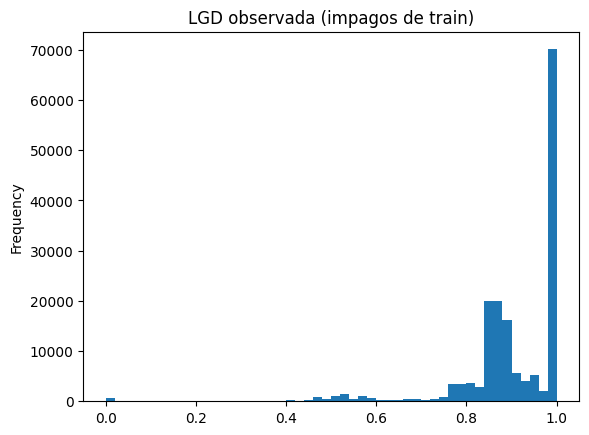

In [ ]:
# ===== Recuperaciones, EAD, LGD y pérdida observadas =====
def lgd_observada(X, y):
    """Variables observadas por préstamo. La LGD solo existe en los impagos con EAD > 0."""
    y = np.asarray(y["y"] if isinstance(y, pd.DataFrame) else y).astype(int).ravel()
    d = X[["funded_amnt", "paym_rec", "princ_rec", "interest_rec", "late_fees_rec"]].astype(float)

    o = pd.DataFrame(index=X.index)
    o["y"] = y
    o["ead"] = (d["funded_amnt"] - d["princ_rec"]).clip(lower=0)
    o["recuperacion"] = (d["paym_rec"] - d[["princ_rec", "interest_rec", "late_fees_rec"]].sum(axis=1)).clip(lower=0)
    o.loc[o["y"] == 0, "recuperacion"] = 0.0                              # fuera de los impagos no hay recobros
    o["perdida"] = o["y"] * (o["ead"] - o["recuperacion"]).clip(lower=0)  # L_j (en $)
    o["lgd"] = np.where((o["y"] == 1) & (o["ead"] > 0),
                        (o["perdida"] / o["ead"].where(o["ead"] > 0)).clip(0, 1), np.nan)
    return o

lgd_obs_train = lgd_observada(X_train, y_train)
lgd_obs_val = lgd_observada(X_val, y_val)

# ===== Resumen de la LGD observada en los impagos =====
def resumen_lgd(o):
    imp = o[o["y"] == 1]
    lgd = imp["lgd"].dropna()
    return pd.Series({
        "impagos": len(imp),
        "EAD = 0 (LGD indefinida)": int((imp["ead"] == 0).sum()),
        "recuperación > EAD (LGD recortada a 0)": int(((imp["recuperacion"] > imp["ead"]) & (imp["ead"] > 0)).sum()),
        "% con recuperación > 0": (imp["recuperacion"] > 0).mean(),
        "% LGD = 1": (lgd == 1).mean(),
        "% LGD = 0": (lgd == 0).mean(),
        "% 0 < LGD < 1": ((lgd > 0) & (lgd < 1)).mean(),
        "LGD media": lgd.mean(),
        "LGD mediana": lgd.median(),
        "LGD ponderada por EAD": imp["perdida"].sum() / imp["ead"].sum(),
        "pérdida total ($)": imp["perdida"].sum(),
    })

display(pd.DataFrame({"train": resumen_lgd(lgd_obs_train), "val": resumen_lgd(lgd_obs_val)}))

# Distribución de la LGD en los impagos de train (excluidos los 0/0)
lgd_tr = lgd_obs_train.loc[lgd_obs_train["y"] == 1, "lgd"].dropna()
print(lgd_tr.describe(percentiles=[.05, .1, .25, .5, .75, .9, .95]).round(3))
lgd_tr.plot.hist(bins=50, title="LGD observada (impagos de train)");

La LGD observada en train tiene una distribución muy asimétrica y concentra la mayor parte de su masa en los valores altos, cerca de 1: el percentil 5 ya se encuentra en valor 0.619, con lo que hay muy pocos préstamos con LGD inferior a 0.6 y la mediana se encuentra en el valor  0.902, con lo cual el 50% de los préstamos impagados presentan una LGD observada superior a 0.902.

El modelo de LGD se entrena con los préstamos impagados de train que tienen una EAD observada estrictamente positiva, ya que en el resto la LGD no está definida (0/0). Por eso, las matrices de entrenamiento y validación se construyen a partir de las de la EAD, que ya contienen solo los impagos y se filtran para quedarse con los préstamos con EAD > 0. No se excluye ningún préstamo por ser atípico: los descartados son aquellos en los que el target no existe. Para predecir sobre toda la cartera se usan las mismas matrices que en la EAD.

In [ ]:
# ===== Matrices para LGD: impagos con EAD observada > 0 =====
assert X_train_EAD.index.isin(lgd_obs_train.index).all() and X_val_EAD.index.isin(lgd_obs_val.index).all()

idx_train_LGD = X_train_EAD.index[lgd_obs_train.loc[X_train_EAD.index, "ead"].to_numpy() > 0]
idx_val_LGD = X_val_EAD.index[lgd_obs_val.loc[X_val_EAD.index, "ead"].to_numpy() > 0]

X_train_LGD = X_train_EAD.loc[idx_train_LGD]
X_val_LGD = X_val_EAD.loc[idx_val_LGD]
y_train_LGD = lgd_obs_train.loc[idx_train_LGD, "lgd"].rename("lgd")
y_val_LGD = lgd_obs_val.loc[idx_val_LGD, "lgd"].rename("lgd")

# Para predecir sobre toda la cartera se usan las mismas matrices que en la EAD
X_val_LGD_cartera = X_val_EAD_cartera
X_test_LGD = X_test_EAD

assert y_train_LGD.notna().all() and y_val_LGD.notna().all()
print(f"Train: {len(X_train_EAD):,} impagos -> {len(X_train_LGD):,} con EAD > 0 "
      f"({len(X_train_EAD) - len(X_train_LGD)} descartados)")
print(f"Val:   {len(X_val_EAD):,} impagos -> {len(X_val_LGD):,} con EAD > 0 "
      f"({len(X_val_EAD) - len(X_val_LGD)} descartados)")

Train: 168,075 impagos -> 168,023 con EAD > 0 (52 descartados)
Val:   55,666 impagos -> 55,653 con EAD > 0 (13 descartados)


Observamos que en validación se descartan 13 préstamos, que representan el 0.02%de los impagos de validación, y en train se descartan 52 préstamos, que representan el 0.03% de los impagos en train.

### Variables

Como en el caso de EAD, todas las variables de originación son candidatas a ser utilizadas, no solo las usadas para PD o EAD: puede ser que variables con bajo poder predictivo para estas variables respuesta ahora sí tengan importancia.


In [ ]:
# Variables candidatas para el modelo de LGD
NUM_LGD = [
    # Préstamo
    "funded_amnt", "interest_rate", "loan_term_months", "issue_date_year",
    # Capacidad de pago
    "annual_income_log", "dept_paym_income_ratio",
    # Historial de morosidad
    "num_30+_delinq_in_2yrs", "mths_since_last_delinq", "never_delinq", "num_derogatory_pub_rec",
    # Líneas de crédito y uso del revolving
    "num_open_credit_lines", "tot_num_credit_lines", "total_credit_revolving_bal",
    "used_credit_share", "credit_history_months",
    # Consultas de crédito
    "num_inq_in_6mths", "num_inq_in_7_12mths",
    # Bloque de buró (nulos estructurales antes de dic-2015)
    "num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq"
]

CAT_LGD = [
    "home_ownership_status", "verification_status", "loan_purpose", "addr_state",
    "initial_list_status", "disbursement_method", "issue_date_month",
    "emp_length_cat", "emp_ambito",
    "mths_since_last_installment_acc_op_cat", "bal_to_cred_lim_cat","mths_since_last_delinq_cat","num_derogatory_pub_rec_cat",
    #Ahora sí se puede usar grade
    "grade"
]

# Versiones categóricas de dos numéricas: usar una u otra, nunca ambas en el mismo modelo
CAT_ALTERNATIVAS_LGD = {"mths_since_last_delinq": "mths_since_last_delinq_cat",
                        "num_derogatory_pub_rec": "num_derogatory_pub_rec_cat"}

In [ ]:
# Las añadimos ya que estas variables no estaban en X_train_EAD y X_val_EAD
NUEVAS_CAT_LGD = [c for c in CAT_LGD if c not in X_train_LGD.columns]   # las dos _cat nuevas
for c in NUEVAS_CAT_LGD:
    categorias = sorted(X_train.loc[X_train_LGD.index, c].dropna().unique())   # aprendidas en los impagos de train
    X_train_LGD[c] = pd.Categorical(X_train.loc[X_train_LGD.index, c], categories=categorias)
    X_val_LGD[c] = pd.Categorical(X_val.loc[X_val_LGD.index, c], categories=categorias)
    X_val_LGD_cartera = X_val_LGD_cartera.assign(**{c: pd.Categorical(X_val.loc[X_val_LGD_cartera.index, c], categories=categorias)})
    X_test_LGD = X_test_LGD.assign(**{c: pd.Categorical(X_test.loc[X_test_LGD.index, c], categories=categorias)})
print("Añadidas:", NUEVAS_CAT_LGD)

Añadidas: ['mths_since_last_delinq_cat', 'num_derogatory_pub_rec_cat']


A continuación repetimos el análisis realizado en la sección de $EAD$, ahora para estudiar la relación de las variables explicativas disponibles con la variable respuesta $LGD$.

In [ ]:
plazo_train_lgd = X_train_LGD["loan_term_months"]
lgd1_train = (y_train_LGD == 1).astype(float)          # indicador de "sin recobro"

filas = []
for c in NUM_LGD:
    x_tr = X_train_LGD[c].astype("float64")
    v = x_tr.notna()
    filas.append({
        "variable": c,
        "eta2_ventiles": eta2_ventiles(x_tr, y_train_LGD),
        "spearman": spearman_validos(x_tr, y_train_LGD),
        "pearson": pearsonr(x_tr[v], y_train_LGD[v])[0],
        "spearman_36m": spearman_validos(x_tr[plazo_train_lgd == 36], y_train_LGD[plazo_train_lgd == 36]),
        "spearman_60m": spearman_validos(x_tr[plazo_train_lgd == 60], y_train_LGD[plazo_train_lgd == 60]),
        "spearman_lgd1": spearman_validos(x_tr, lgd1_train),
        "pct_nulos": 1 - v.mean(),
    })

correlaciones_lgd = (pd.DataFrame(filas)
                     .sort_values("eta2_ventiles", ascending=False)
                     .reset_index(drop=True))

columnas_corr = ["spearman", "pearson", "spearman_36m", "spearman_60m", "spearman_lgd1"]
display(correlaciones_lgd.style
        .format({**{c: "{:+.3f}" for c in columnas_corr}, "eta2_ventiles": "{:.4f}", "pct_nulos": "{:.1%}"})
        .background_gradient(subset=["eta2_ventiles"], cmap="Blues")
        .bar(subset=columnas_corr, align="zero", color=["#d65f5f", "#5fba7d"]))

/tmp/ipykernel_1875/693281791.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(x[v], y[v])[0] if v.sum() > 30 else np.nan


,variable,eta2_ventiles,spearman,pearson,spearman_36m,spearman_60m,spearman_lgd1,pct_nulos
0,issue_date_year,0.0541,+0.311,+0.176,+0.332,+0.285,+0.369,0.0%
1,num_installment_acc_op_in_24mths,0.0340,-0.066,-0.051,-0.064,-0.070,-0.056,53.9%
2,num_rev_trades_op_in_24mths,0.0335,-0.053,-0.028,-0.049,-0.063,-0.047,53.9%
3,num_open_trades_in_6mths,0.0335,-0.052,-0.039,-0.047,-0.064,-0.046,53.9%
4,max_bal_owed,0.0333,-0.018,-0.017,-0.020,-0.010,-0.017,53.9%
5,num_inq,0.0331,-0.014,-0.004,-0.012,-0.020,-0.008,53.9%
6,num_inq_in_7_12mths,0.0076,+0.169,+0.085,+0.178,+0.154,+0.192,0.0%
7,tot_num_credit_lines,0.0026,-0.049,-0.047,-0.050,-0.048,-0.033,0.0%
8,interest_rate,0.0025,-0.074,-0.005,-0.063,-0.108,-0.043,0.0%
9,used_credit_share,0.0020,-0.072,-0.042,-0.074,-0.069,-0.080,0.0%


Observamos que las variables que mayor correlación muestran con  $LGD$  son `issue_date_year` y `num_inq_in_7_12mths` ambas con correlación positiva. Por tanto, esperamos que estas variables tengan elevado poder predictivo, sobre todo en modelos lineales.

El resto de variables presentan correlaciones muy bajas con $LGD$ .

Por otro lado, la variable que mayor  $\eta^2$  presenta es `issue_date_year`, la cual explica el 5,41% de la variabilidad de  $LGD$  al agruparla por ventiles. A esta la siguen `num_installment_acc_op_in_24mths`,`num_rev_trades_op_in_24mths`,`num_open_trades_in_6mths`,`max_bal_owed` y `num_inq`, las cuales consiguen explicar entre un 3,31% y un 3,4% de la misma.

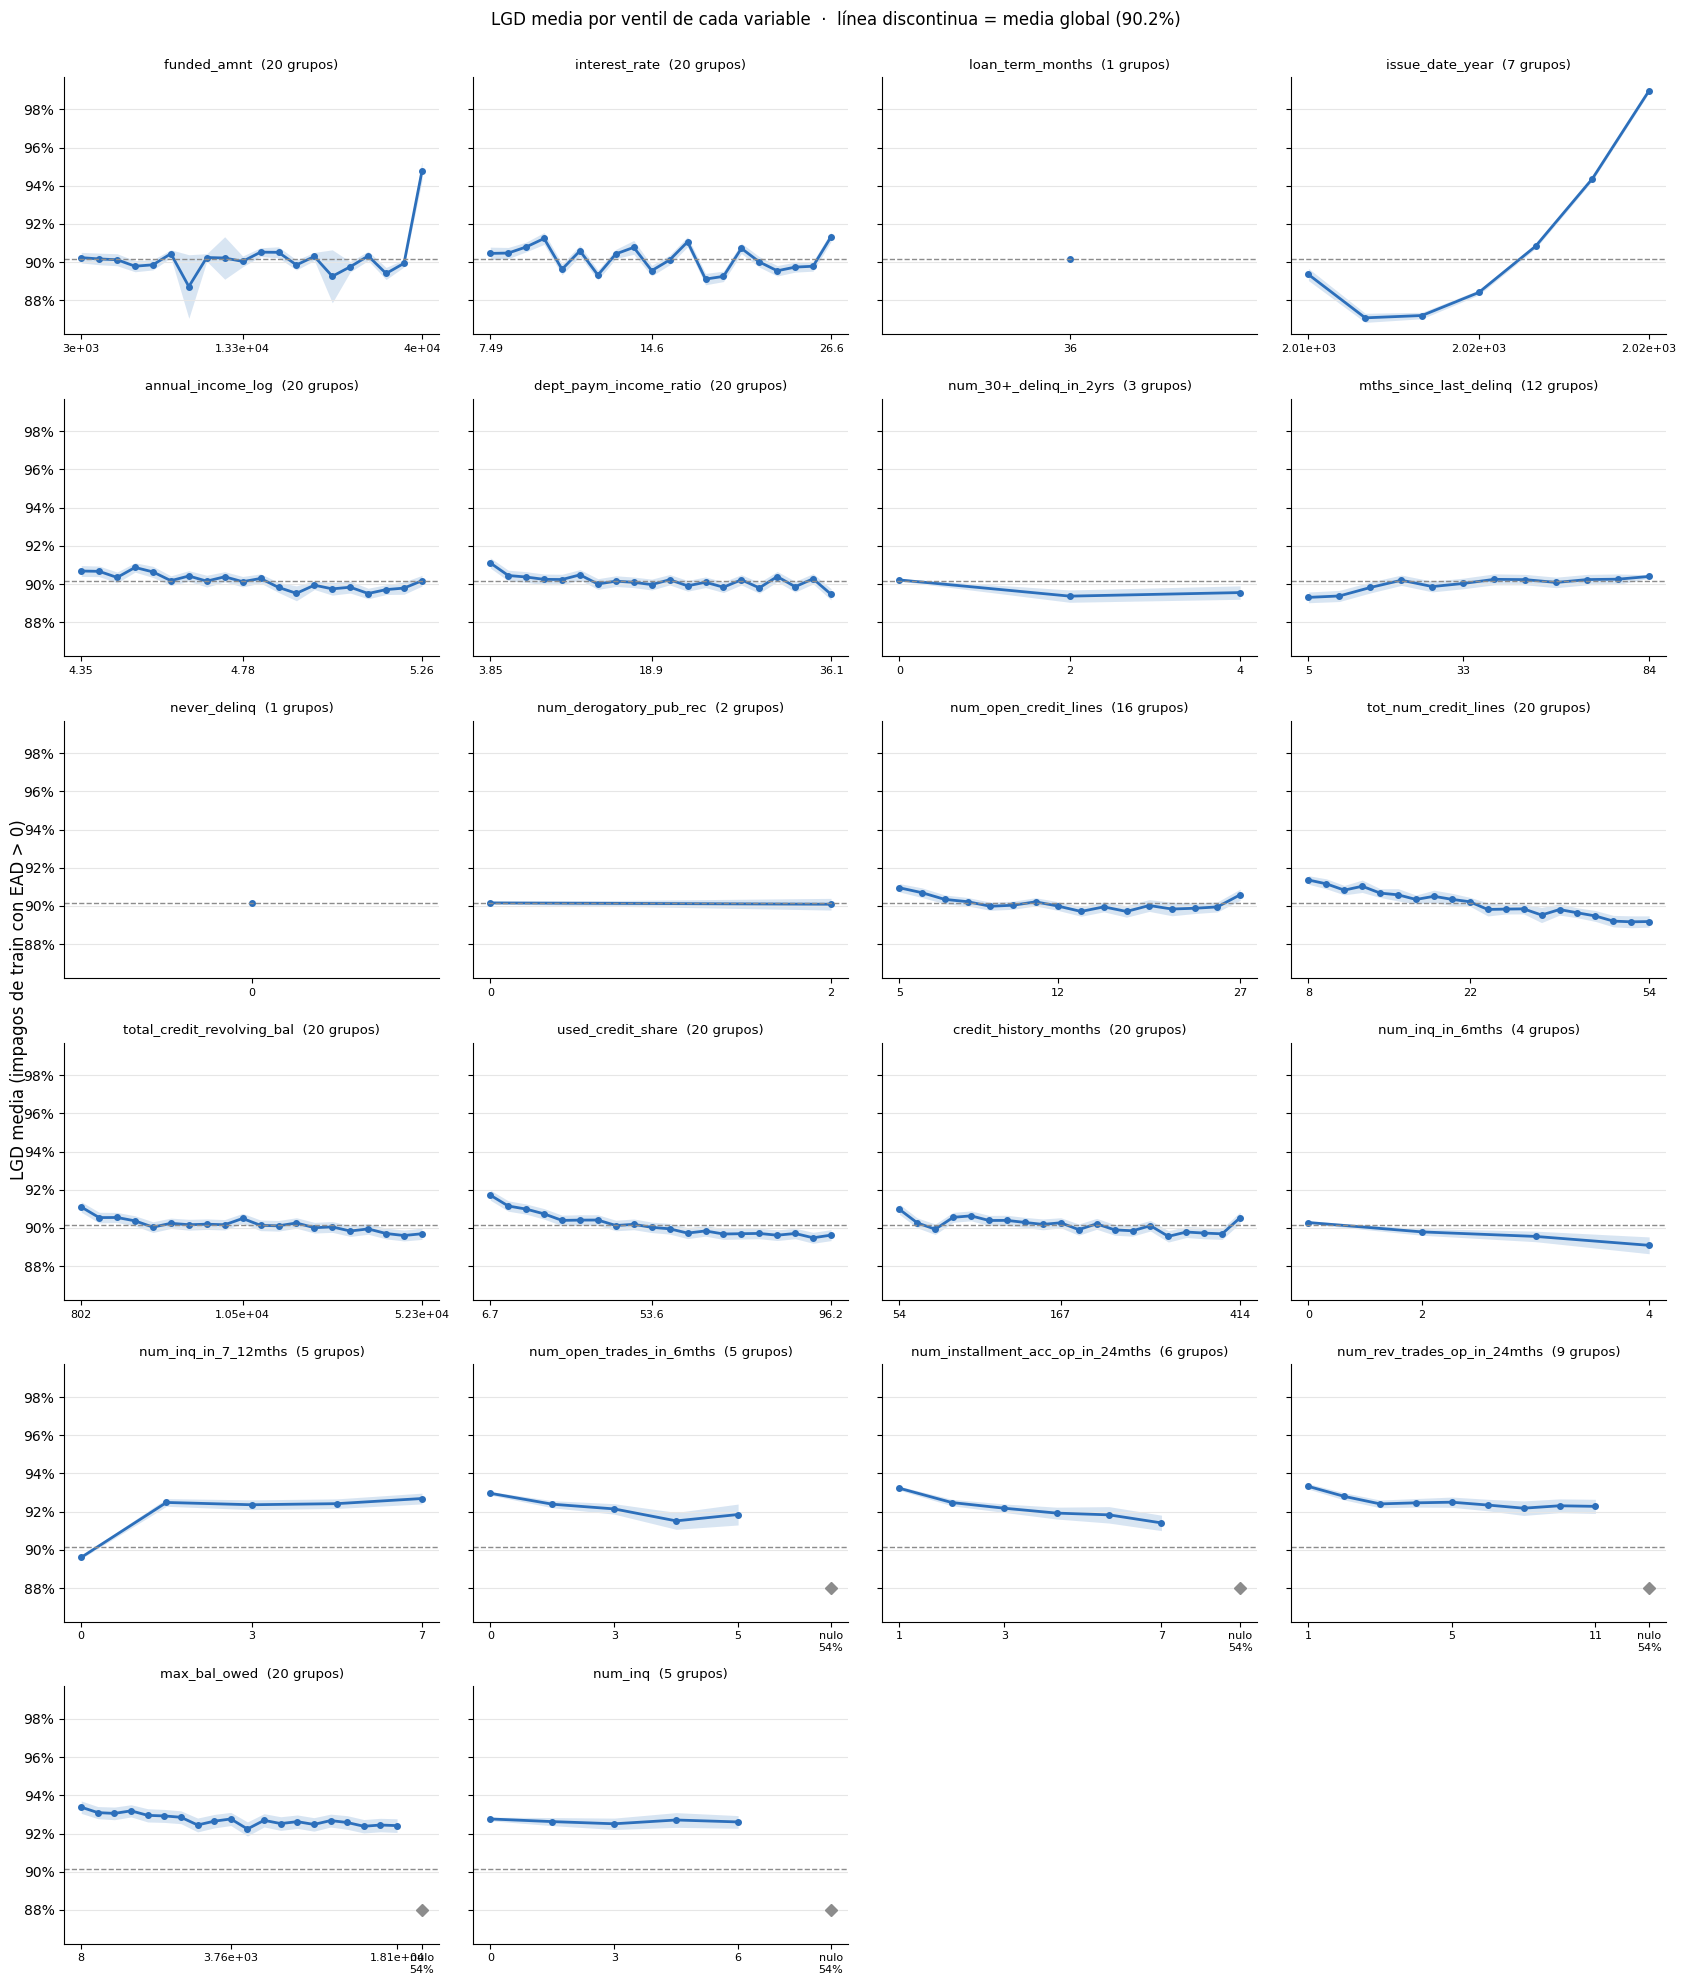

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

COLOR = "#2c6fbb"      # una sola serie por gráfica: un único color
GRIS = "#8c8c8c"

media_global_lgd_tr = y_train_LGD.mean()
n_cols = 4
n_filas = int(np.ceil(len(NUM_LGD) / n_cols))
fig, ejes = plt.subplots(n_filas, n_cols, figsize=(4.3 * n_cols, 3.3 * n_filas), sharey=True)

ventiles_lgd = {}
for ax, c in zip(ejes.flat, NUM_LGD):
    x = X_train_LGD[c].astype("float64")
    validos = x.notna()

    # Ventiles (con muchos valores repetidos salen menos de 20 grupos: duplicates="drop")
    grupos = pd.qcut(x[validos], 20, duplicates="drop")
    t = y_train_LGD[validos].groupby(grupos, observed=True).agg(n="size", media="mean", sd="std")
    t["valor_mediano"] = x[validos].groupby(grupos, observed=True).median()
    t["ic95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
    ventiles_lgd[c] = t

    pos = np.arange(1, len(t) + 1)
    ax.fill_between(pos, t["media"] - t["ic95"], t["media"] + t["ic95"], color=COLOR, alpha=0.18, lw=0)
    ax.plot(pos, t["media"], color=COLOR, lw=2, marker="o", ms=4)

    # Etiquetas del eje x: valor mediano del primer, el central y el último grupo
    ticks = sorted({1, (len(t) + 1) // 2, len(t)})
    etiquetas = [f"{t['valor_mediano'].iloc[i - 1]:,.3g}" for i in ticks]

    # Los nulos, como un punto aparte a la derecha (relevante en el bloque de buró)
    if (~validos).any():
        x_nulo = len(t) + 1.5
        ax.plot(x_nulo, y_train_LGD[~validos].mean(), marker="D", color=GRIS, ms=6)
        ticks.append(x_nulo)
        etiquetas.append(f"nulo\n{(~validos).mean():.0%}")

    ax.axhline(media_global_lgd_tr, color=GRIS, lw=1, ls="--")
    ax.set_xticks(ticks, etiquetas, fontsize=8)
    ax.set_title(f"{c}  ({len(t)} grupos)", fontsize=9.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)

for ax in ejes.flat[len(NUM_LGD):]:
    ax.set_visible(False)

fig.supylabel("LGD media (impagos de train con EAD > 0)")
fig.suptitle(f"LGD media por ventil de cada variable  ·  línea discontinua = media global ({media_global_lgd_tr:.1%})", y=1.0)
plt.tight_layout()
plt.savefig("lgd_por_ventiles.png", dpi=150, bbox_inches="tight")
plt.show()

En este gráfico se muestra la media de $LGD$ por ventil de cada variable numérica, donde la línea discontinua muestra la media global.

En primer lugar, observamos que la variable que muestra un mayor cambio para la media de $LGD$ en función de sus ventiles es justamente la variable que mayor correlación mostraba en el análisis anterior(`issue_date_year`). Además, la tendencia que observamos es aproximadamente monótona no decreciente, reflejando la correlación positiva que mostraba el análisis anterior.

Por otro lado, tenemos variables cuyas gráficas presentan muchos picos, reflejando que el cambio que sufe $LGD$ a lo largo de sus ventiles se aleja mucho de la linealidad, y otras variables cuyas gráficas sí son aproximadamente lineales y, por tanto, se espera de ellas un buen rendimiento como variables predictoras en modelos lineales.

Estudiamos ahora el cuadrado del ratio de correlación, $\eta^2$, de las variables categóricas frente a la $LGD$.


In [ ]:
plazo_train_lgd = X_train_LGD["loan_term_months"]
lgd1_train = (y_train_LGD == 1).astype(float)          # indicador de "sin recobro"

filas = []
for c in CAT_LGD:
    g_tr = con_nulos(X_train_LGD[c])
    eta2, eta2_aj = eta2_cat(g_tr, y_train_LGD)
    filas.append({
        "variable": c,
        "categorias": g_tr.nunique(),
        "eta2": eta2, "eta2_ajustada": eta2_aj,
        "eta2_36m": eta2_cat(g_tr[plazo_train_lgd == 36], y_train_LGD[plazo_train_lgd == 36])[0],
        "eta2_60m": eta2_cat(g_tr[plazo_train_lgd == 60], y_train_LGD[plazo_train_lgd == 60])[0],
        "eta2_lgd1": eta2_cat(g_tr, lgd1_train)[0],
        "n_categoria_min": g_tr.value_counts().min(),
        "pct_nulos": X_train_LGD[c].isna().mean(),
    })

asociacion_cat_lgd = pd.DataFrame(filas).sort_values("eta2_ajustada", ascending=False).reset_index(drop=True)
display(asociacion_cat_lgd.style
        .format({"eta2": "{:.4f}", "eta2_ajustada": "{:.4f}", "eta2_36m": "{:.4f}", "eta2_60m": "{:.4f}",
                 "eta2_lgd1": "{:.4f}", "n_categoria_min": "{:,}", "pct_nulos": "{:.1%}"})
        .background_gradient(subset=["eta2_ajustada"], cmap="Blues"))

,variable,categorias,eta2,eta2_ajustada,eta2_36m,eta2_60m,eta2_lgd1,n_categoria_min,pct_nulos
0,mths_since_last_installment_acc_op_cat,12,0.0340,0.0340,0.0384,0.0304,0.0842,"2,470",0.0%
1,bal_to_cred_lim_cat,6,0.0339,0.0338,0.0384,0.0300,0.0845,"1,164",0.0%
2,addr_state,51,0.0047,0.0044,0.0049,0.0055,0.0073,2,0.0%
3,initial_list_status,2,0.0033,0.0033,0.0014,0.0081,0.0138,"67,938",0.0%
4,emp_ambito,25,0.0031,0.0030,0.0034,0.0039,0.0169,573,0.0%
5,emp_length_cat,10,0.0017,0.0017,0.0023,0.0013,0.0046,"6,292",0.0%
6,verification_status,3,0.0008,0.0008,0.0002,0.0056,0.0025,"37,658",0.0%
7,grade,35,0.0010,0.0008,0.0008,0.0055,0.0043,376,0.0%
8,home_ownership_status,4,0.0008,0.0008,0.0009,0.0011,0.0005,60,0.0%
9,mths_since_last_delinq_cat,7,0.0007,0.0007,0.0010,0.0005,0.0006,"5,217",0.0%


Observamos que la variables categóricas que mayor $\eta^2$ presentan son `mths_since_last_installment_acc_op_cat`  y `bal_to_cred_lim_cat`,las cuales explican ambas aproximadamente un 3,4% de la variabilidad de $LGD$.

Además, las variables `mths_since_last_delinq_cat` y `num_derogatory_pub_rec_cat` muestran un mayor $\eta^2$ como categóricas que como numéricas, luego en caso de añadirlas a los modelos consideraremos su versión categórica (a pesar de que las categorías de estas variables se crearon en función de la tasa de impago).

Finalmente, cabe destacar que, al contrario de lo que ocurría con la $EAD\%$, ahora `grade` no parece tener relevancia.

### Métricas

Las métricas a considerar a la hora de modelar la $LGD$ son las siguientes.

Notación: para cada impago $j$ del conjunto evaluado ($n$ préstamos con $EAD > 0$), $y_j$ es la $LGD$ observada, $\hat{y}_j$ la predicha y $E_j$ la $EAD$ observada en dólares. La pérdida en dólares es $L_j = y_j \cdot E_j$ (real) y $\hat{L}_j = \hat{y}_j \cdot E_j$ (predicha). En las métricas en dólares se usa la $EAD$ **observada** y no la predicha, para que el error medido sea solo el de la $LGD$ y no se mezcle con el del modelo de $EAD$.

**Precisión en porcentaje**

- **MAE**, error absoluto medio: $\frac{1}{n}\sum_j |y_j - \hat{y}_j|$. Es el error típico de la predicción en puntos de $LGD$. Por ejemplo, un MAE de 0.15 significa que, de media, la predicción se equivoca en 15 puntos de la fracción perdida.
- **RMSE**, raíz del error cuadrático medio: $\sqrt{\frac{1}{n}\sum_j (y_j - \hat{y}_j)^2}$. Penaliza más los errores grandes. Si es mucho mayor que el MAE, el modelo comete errores grandes en algunos préstamos, típicamente en los de LGD baja, que son pocos y están alejados de la masa de la distribución.
- **MAPE**, error porcentual absoluto medio: $\frac{1}{n'}\sum_{j:\,y_j>0} \left|\frac{y_j - \hat{y}_j}{y_j}\right|$. Es el error relativo a la $LGD$ observada. Se excluyen los préstamos con $LGD = 0$, en los que no está definido, y por eso se promedia sobre $n'$ préstamos. Pesa mucho los errores en préstamos con LGD baja, así que se usa solo como referencia.
- **$R^2$**: $1 - \frac{\sum_j (y_j - \hat{y}_j)^2}{\sum_j (y_j - \bar{y})^2}$. Proporción de la varianza de la $LGD$ que explica el modelo. Vale 0 para un modelo que predice siempre la media.

**Precisión en dólares**

- **MAE de la pérdida (\$)**: $\frac{1}{n}\sum_j |L_j - \hat{L}_j| = \frac{1}{n}\sum_j E_j\,|y_j - \hat{y}_j|$. Es el error medio en dólares de pérdida. Es la métrica más cercana a la evaluación del reto, que se hace sobre la $ECL$ en dólares: un error de 10 puntos de $LGD$ en un préstamo con 20 000 \$ de exposición cuesta 2 000 \$, y en uno con 1 000 \$, solo 100 \$.

**Sesgo y calibración**

- **LGD media predicha y real**: permiten ver de un vistazo si el modelo está desplazado respecto a la media observada.
- **Pérdida total predicha / real**: $\frac{\sum_j \hat{L}_j}{\sum_j L_j}$. Indica si el modelo sobrestima (mayor que 1) o infraestima (menor que 1) la pérdida total de los impagos. Es la métrica más directamente ligada a la $ECL$ total del reto, y por el sesgo conservador interesa que quede en 1 o ligeramente por encima. A diferencia de la LGD media, pondera cada préstamo por su exposición: si la $LGD$ está correlacionada con la $EAD$, un modelo puede acertar la LGD media y fallar la pérdida total.
- **Error de calibración**: los préstamos se ordenan por la $LGD$ predicha y se dividen en deciles. En cada decil se compara la $LGD$ media predicha con la observada, y se promedian las diferencias en valor absoluto. Un modelo puede acertar en el total y aun así sobrestimar en unos grupos e infraestimar en otros; esta métrica lo detecta. Para un modelo constante solo hay un grupo y vale 0 por construcción.
- **Préstamos infraestimados**: proporción de impagos con $\hat{y}_j < y_j$. Es informativa, pero no tiene por qué ser inferior al 10 %: la restricción del reto se aplica a la ECL completa ($PD \times LGD \times EAD$) y se gestionrá al final.

Todas las métricas se calculan en validación. Para elegir modelo nos fijamos principalmente en el **MAE de la pérdida en dólares** y en el **cociente pérdida total predicha / real**, que son las más cercanas a cómo se evaluará la $ECL$. Las métricas en porcentaje sirven para entender el comportamiento del modelo y compararlo con los modelos de referencia.

In [ ]:
# ===== Métricas para LGD =====
def metricas_lgd(y, pred, ead):
    """y: LGD observada, pred: LGD predicha, ead: EAD observada en $ (para pasar el error a pérdida)."""
    y = np.asarray(y, dtype=float).ravel()
    pred = np.asarray(pred, dtype=float).ravel()
    ead = np.asarray(ead, dtype=float).ravel()
    err = pred - y
    no_cero = y > 0.01        # excluye LGD nulas o residuales (redondeos de recuperación ≈ EAD)
    # Calibración: error medio entre predicción y realidad en deciles de la predicción
    grupos = pd.qcut(pd.Series(pred).rank(method="first"), 10, labels=False) if np.unique(pred).size > 1 \
             else pd.Series(np.zeros(len(pred)))
    cal = pd.DataFrame({"g": grupos.to_numpy(), "y": y, "p": pred}).groupby("g").agg(y=("y", "mean"), p=("p", "mean"))
    return {
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAPE (sin LGD=0)": np.abs(err[no_cero] / y[no_cero]).mean(),
        "R²": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "LGD media pred": pred.mean(),
        "LGD media real": y.mean(),
        "MAE pérdida ($)": np.abs(err * ead).mean(),
        "pérdida total pred / real": (pred * ead).sum() / (y * ead).sum(),
        "error calibración": np.abs(cal["p"] - cal["y"]).mean(),
        "% infraestimados": (pred < y).mean(),
    }

def tabla_lgd(resultados):
    t = pd.DataFrame(resultados).T
    return t.style.format({
        "MAE": "{:.4f}", "RMSE": "{:.4f}", "MAPE (sin LGD=0)": "{:.2%}", "R²": "{:+.4f}",
        "LGD media pred": "{:.4f}", "LGD media real": "{:.4f}", "MAE pérdida ($)": "{:,.0f}",
        "pérdida total pred / real": "{:.4f}", "error calibración": "{:.4f}", "% infraestimados": "{:.1%}"})

# EAD observada de los impagos con EAD > 0, para las métricas en dólares
ead_train_LGD = lgd_obs_train.loc[X_train_LGD.index, "ead"]
ead_val_LGD = lgd_obs_val.loc[X_val_LGD.index, "ead"]

### Modelo trivial: Media global de $LGD$

Como en el caso de la $EAD$, el modelo más sencillo que se puede plantear es aquel que asigna a cada préstamo la media global de  $LGD$  observada en train, con lo que este volverá a ser nuestro baseline.

In [ ]:
# ===== Modelo 0: media global de la LGD observada en train =====
media_global_lgd = float(y_train_LGD.mean())
print(f"LGD media en los impagos de train: {media_global_lgd:.4f}")

pred_train_lgd_m0 = np.full(len(y_train_LGD), media_global_lgd)
pred_val_lgd_m0 = np.full(len(y_val_LGD), media_global_lgd)

display(tabla_lgd({"train": metricas_lgd(y_train_LGD, pred_train_lgd_m0, ead_train_LGD),
                   "val": metricas_lgd(y_val_LGD, pred_val_lgd_m0, ead_val_LGD)}))

# Comparación acumulada en validación (se irán añadiendo los siguientes modelos)
resultados_lgd = {"0. media global": metricas_lgd(y_val_LGD, pred_val_lgd_m0, ead_val_LGD)}
display(tabla_lgd(resultados_lgd))

LGD media en los impagos de train: 0.9016


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
train,0.0881,0.1299,12.06%,+0.0000,0.9016,0.9016,929,0.9993,0.0000,50.6%
val,0.0883,0.1304,11.92%,-0.0000,0.9016,0.9018,930,0.9989,0.0002,50.7%


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
0. media global,0.0883,0.1304,11.92%,-0.0000,0.9016,0.9018,930,0.9989,0.0002,50.7%


A diferencia de lo que ocurría con los baselines anteriores, este modelo trivial consigue un MAE y un error de calibración bastante aceptables considerando su sencillez. Esto es debido a que el percentil 50 es  0.903, el percentil 75 ya se sitúa en el valor límite 1.00 y estamos prediciendo con la media cuyo valor es 0.9016.

### Modelo 1: Regresión logística fraccional

Proponemos ahora un modelo de regresión logística fraccional cuya construcción se hace de forma totalmente análoga a la realizada para modelar $EAD$.

In [ ]:
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# ===== Modelo 1 de LGD: regresión logística fraccional con todas las variables candidatas =====
# Todos los objetos llevan sufijo _LGD para no pisar los del modelo de EAD (se necesitan después en el ECL).

SUAVIZADO_TE = 100     # m: peso de la media global en categorías con pocos impagos
ALFA = 0.05            # nivel de significación global (corrección de Bonferroni)

# Numéricas: todas las de NUM_LGD salvo issue_date_year (entra como categórica), con el importe en logaritmo
# y sin las que se usan en su versión categórica
NUM_GLM_LGD = [c for c in NUM_LGD
               if c not in ("issue_date_year", "funded_amnt") and c not in CAT_ALTERNATIVAS_LGD] + ["funded_amnt_log"]
CAT_GLM_LGD = list(CAT_LGD)    # incluye grade y las versiones _cat de mths_since_last_delinq y num_derogatory_pub_rec

BLOQUE_BURO = ["num_open_trades_in_6mths", "num_installment_acc_op_in_24mths",
               "num_rev_trades_op_in_24mths", "max_bal_owed", "num_inq"]

# ===== Target encoding suavizado (media de LGD por categoría) =====
def con_nulos_str(s):
    return s.astype(object).where(s.notna(), "(nulo)").astype(str)

def ajustar_te(x, y, m=SUAVIZADO_TE):
    """Media suavizada de y por categoría: (n·media + m·media_global) / (n + m)."""
    media_global = y.mean()
    stats = y.groupby(x).agg(["sum", "count"])
    return (stats["sum"] + m * media_global) / (stats["count"] + m), media_global

def aplicar_te(x, mapa, media_global):
    return x.map(mapa).fillna(media_global).astype(float)        # categoría no vista -> media global

cats_tr_lgd = {c: con_nulos_str(X_train_LGD[c]) for c in CAT_GLM_LGD}

# Train: codificación fuera de muestra (5 bloques), para que cada préstamo no use su propia LGD
TE_TRAIN_LGD = pd.DataFrame(index=X_train_LGD.index, columns=[f"te_{c}" for c in CAT_GLM_LGD], dtype=float)
for idx_ajuste, idx_aplica in KFold(5, shuffle=True, random_state=SEED).split(X_train_LGD):
    i_aj, i_ap = X_train_LGD.index[idx_ajuste], X_train_LGD.index[idx_aplica]
    for c in CAT_GLM_LGD:
        mapa, mg = ajustar_te(cats_tr_lgd[c].loc[i_aj], y_train_LGD.loc[i_aj])
        TE_TRAIN_LGD.loc[i_ap, f"te_{c}"] = aplicar_te(cats_tr_lgd[c].loc[i_ap], mapa, mg).to_numpy()

# Validación, cartera y test: codificación con todos los impagos de train
MAPAS_TE_LGD = {c: ajustar_te(cats_tr_lgd[c], y_train_LGD) for c in CAT_GLM_LGD}

def te_completo_lgd(X):
    return pd.DataFrame({f"te_{c}": aplicar_te(con_nulos_str(X[c]), *MAPAS_TE_LGD[c]) for c in CAT_GLM_LGD},
                        index=X.index)

# ===== Numéricas: imputación, indicadores de nulo y estandarización aprendidos en train =====
def numericas_glm_lgd(X):
    d = X[[c for c in NUM_GLM_LGD if c != "funded_amnt_log"]].astype(float).copy()
    d["funded_amnt_log"] = np.log(X["funded_amnt"].astype(float))
    return d

num_tr_lgd = numericas_glm_lgd(X_train_LGD)
MEDIANAS_GLM_LGD = num_tr_lgd.median()

# Un indicador por patrón de nulos distinto, y ninguno si equivale a una binaria existente (o a su complementaria)
binarias_tr = [num_tr_lgd[c].fillna(-1).astype(int) for c in num_tr_lgd.columns
               if set(num_tr_lgd[c].dropna().unique()) <= {0, 1}]
GRUPOS_NULOS_LGD, patrones_vistos = [], []
for c in num_tr_lgd.columns:
    nulos = num_tr_lgd[c].isna()
    if not nulos.any() or any(nulos.equals(p) for p in patrones_vistos):
        continue
    n_int = nulos.astype(int)
    if any(n_int.equals(b) or n_int.equals(1 - b) for b in binarias_tr):
        continue
    patrones_vistos.append(nulos)
    GRUPOS_NULOS_LGD.append(("nulo_bloque_buro" if c in BLOQUE_BURO else f"nulo_{c}", c))

# Año como categórica; referencia = año con más impagos en train
años_tr = X_train_LGD["issue_date_year"].astype(int).astype(str)
MODA_AÑO_LGD = años_tr.mode()[0]
NIVELES_AÑO_LGD = [MODA_AÑO_LGD] + sorted(a for a in años_tr.unique() if a != MODA_AÑO_LGD)

def datos_glm_lgd(X, te, y=None):
    """Numéricas imputadas, indicadores de nulo, categóricas codificadas (te) y año."""
    num = numericas_glm_lgd(X)
    d = pd.concat([num.fillna(MEDIANAS_GLM_LGD), te], axis=1)
    for nombre, c in GRUPOS_NULOS_LGD:
        d[nombre] = num[c].isna().astype(float)
    año = X["issue_date_year"].astype(int).astype(str)
    d["año"] = año.where(año.isin(NIVELES_AÑO_LGD), MODA_AÑO_LGD)    # año no visto en train -> referencia
    if y is not None:
        d["lgd"] = np.asarray(y, dtype=float)
    return d

datos_tr_lgd = datos_glm_lgd(X_train_LGD, TE_TRAIN_LGD, y_train_LGD)
COLS_ESTANDAR_LGD = list(num_tr_lgd.columns) + list(TE_TRAIN_LGD.columns)
MEDIAS_GLM_LGD = datos_tr_lgd[COLS_ESTANDAR_LGD].mean()
DESV_GLM_LGD = datos_tr_lgd[COLS_ESTANDAR_LGD].std().replace(0, 1)

def estandarizar_lgd(d):
    d = d.copy()
    d[COLS_ESTANDAR_LGD] = (d[COLS_ESTANDAR_LGD] - MEDIAS_GLM_LGD) / DESV_GLM_LGD
    return d

datos_tr_lgd = estandarizar_lgd(datos_tr_lgd)
datos_va_lgd = estandarizar_lgd(datos_glm_lgd(X_val_LGD, te_completo_lgd(X_val_LGD)))

# ===== Fórmula y ajuste con errores estándar robustos =====
terminos_lgd = (["C(año, levels=NIVELES_AÑO_LGD)"]                  # año categórico, sin interacción
                + [f"Q('{c}')" for c in NUM_GLM_LGD]
                + [nombre for nombre, _ in GRUPOS_NULOS_LGD]
                + list(TE_TRAIN_LGD.columns))
FORMULA_LGD = "lgd ~ " + " + ".join(terminos_lgd)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # aviso esperado: target no binario (regresión fraccional)
    modelo_lgd_rl = smf.glm(FORMULA_LGD, data=datos_tr_lgd, family=sm.families.Binomial()).fit(cov_type="HC0")
print(f"Convergió: {modelo_lgd_rl.converged} | parámetros estimados: {len(modelo_lgd_rl.params)}")

pred_train_lgd_m1 = modelo_lgd_rl.predict(datos_tr_lgd).to_numpy()
pred_val_lgd_m1 = modelo_lgd_rl.predict(datos_va_lgd).to_numpy()

display(tabla_lgd({"train": metricas_lgd(y_train_LGD, pred_train_lgd_m1, ead_train_LGD),
                   "val": metricas_lgd(y_val_LGD, pred_val_lgd_m1, ead_val_LGD)}))

# ===== Coeficientes con p-valores e intervalos ajustados por Bonferroni =====
coefs = modelo_lgd_rl.summary2().tables[1].drop(index="Intercept", errors="ignore")
m_contrastes = len(coefs)
z_crit = norm.ppf(1 - ALFA / (2 * m_contrastes))

tabla_coefs_lgd = pd.DataFrame({
    "coef": coefs["Coef."],
    "error_std": coefs["Std.Err."],
    "z": coefs["z"],
    "p_valor_bonferroni": multipletests(coefs["P>|z|"], alpha=ALFA, method="bonferroni")[1],
    "ic_inf_bonferroni": coefs["Coef."] - z_crit * coefs["Std.Err."],
    "ic_sup_bonferroni": coefs["Coef."] + z_crit * coefs["Std.Err."],
})
tabla_coefs_lgd["significativo"] = tabla_coefs_lgd["p_valor_bonferroni"] < ALFA

print(f"Contrastes: {m_contrastes} | valor crítico z: {z_crit:.2f} | "
      f"significativos tras Bonferroni: {tabla_coefs_lgd['significativo'].sum()} de {m_contrastes}")

formato_coefs = {"coef": "{:+.4f}", "error_std": "{:.4f}", "z": "{:+.2f}", "p_valor_bonferroni": "{:.2e}",
                 "ic_inf_bonferroni": "{:+.4f}", "ic_sup_bonferroni": "{:+.4f}"}

# Variables ordenadas por tamaño del efecto (sin las dummies de año, que se muestran aparte)
tabla_vars_lgd = tabla_coefs_lgd.loc[[i for i in tabla_coefs_lgd.index if not i.startswith("C(")]]
display(tabla_vars_lgd.reindex(tabla_vars_lgd["coef"].abs().sort_values(ascending=False).index)
        .style.format(formato_coefs))

# Año: coeficientes individuales (diferencia de nivel frente al año de referencia) y contraste de Wald del bloque
print(f"Año de referencia: {MODA_AÑO_LGD}")
display(tabla_coefs_lgd.loc[[i for i in tabla_coefs_lgd.index if i.startswith("C(")]].style.format(formato_coefs))
wald_lgd = modelo_lgd_rl.wald_test_terms(skip_single=False, scalar=True).table
display(wald_lgd.loc[[i for i in wald_lgd.index if "año" in i]])

# ===== Comparación acumulada en validación =====
resultados_lgd["1. logística fraccional"] = metricas_lgd(y_val_LGD, pred_val_lgd_m1, ead_val_LGD)
display(tabla_lgd(resultados_lgd))

Convergió: True | parámetros estimados: 46


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
train,0.0822,0.1255,11.35%,+0.0676,0.9016,0.9016,849,1.0029,0.0010,59.1%
val,0.0823,0.1260,11.19%,+0.0667,0.9016,0.9018,851,1.0025,0.0020,59.4%


Contrastes: 45 | valor crítico z: 3.26 | significativos tras Bonferroni: 20 de 45


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
nulo_bloque_buro,+0.1899,0.0878,+2.16,1.00e+00,-0.0963,+0.4762,False
te_mths_since_last_installment_acc_op_cat,+0.1007,0.0317,+3.18,6.73e-02,-0.0027,+0.2042,False
Q('loan_term_months'),+0.0992,0.0044,+22.50,1.91e-110,+0.0848,+0.1136,True
te_addr_state,+0.0973,0.0038,+25.72,3.17e-144,+0.0849,+0.1096,True
Q('interest_rate'),-0.0714,0.0059,-12.02,1.18e-31,-0.0908,-0.0521,True
Q('annual_income_log'),-0.0597,0.0051,-11.65,1.03e-29,-0.0764,-0.0430,True
Q('num_open_credit_lines'),+0.0596,0.0052,+11.35,3.21e-28,+0.0425,+0.0767,True
Q('tot_num_credit_lines'),-0.0563,0.0052,-10.75,2.56e-25,-0.0734,-0.0392,True
te_emp_ambito,+0.0389,0.0041,+9.46,1.41e-19,+0.0255,+0.0523,True
te_bal_to_cred_lim_cat,+0.0382,0.0311,+1.23,1.00e+00,-0.0632,+0.1397,False


Año de referencia: 2015


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
"C(año, levels=NIVELES_AÑO_LGD)[T.2007]",+0.3944,0.2698,+1.46,1.00e+00,-0.4854,+1.2743,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2008]",+0.3136,0.1622,+1.93,1.00e+00,-0.2153,+0.8425,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2009]",+0.3058,0.1277,+2.39,7.50e-01,-0.1107,+0.7222,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2010]",+0.2103,0.0650,+3.23,5.49e-02,-0.0017,+0.4224,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2011]",+0.2071,0.0393,+5.27,5.99e-06,+0.0791,+0.3352,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2012]",+0.0575,0.0208,+2.77,2.53e-01,-0.0102,+0.1252,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2013]",-0.0690,0.0134,-5.13,1.30e-05,-0.1128,-0.0251,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2014]",-0.0990,0.0103,-9.66,2.01e-20,-0.1325,-0.0656,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2016]",+0.2294,0.0296,+7.74,4.33e-13,+0.1328,+0.3260,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2017]",+0.7572,0.0308,+24.57,1.11e-131,+0.6567,+0.8577,True


,statistic,pvalue,df_constraint
"C(año, levels=NIVELES_AÑO_LGD)",3654.489359,0.0,11


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
0. media global,0.0883,0.1304,11.92%,-0.0000,0.9016,0.9018,930,0.9989,0.0002,50.7%
1. logística fraccional,0.0823,0.1260,11.19%,+0.0667,0.9016,0.9018,851,1.0025,0.0020,59.4%


En primer lugar, observamos que con la regresión logística fraccional conseguimos mejorar ligeramente el baseline: reducimos el MAE en 0.006 lo que supone una reducción del MAE de la pérdida en dólares de 79\$, aumentamos el $R^2$ y conseguimos un cociente de pérdida total predicha entre real ligeramente superior a 1.00 como estamos tratando de conseguir con todos lo modelos.

En segundo lugar, tras calcular los p-valores ajustados por Bonferroni obtenemos 20 de 45 variables significativas, de las cuales 6 se corresponden con las dummies asociadas al año de emisión.

A continuación, planteamos una regresión logística fraccional incluyendo únicamente las variables significativas.

### Modelo 2: Regresión logística fraccional reducida

In [ ]:
# ===== Modelo 2 de LGD: regresión logística fraccional reducida =====
# Reutiliza lo construido en la celda del modelo 1 de LGD: datos_tr_lgd, datos_va_lgd (ya estandarizados),
# NIVELES_AÑO_LGD, MODA_AÑO_LGD, ALFA, modelo_lgd_rl, metricas_lgd, tabla_lgd, resultados_lgd.

# Variables significativas tras Bonferroni en el modelo 1 (más el año, significativo como bloque)
NUM_LGD_M2 = ["loan_term_months", "interest_rate", "annual_income_log", "num_open_credit_lines",
              "tot_num_credit_lines", "funded_amnt_log", "num_rev_trades_op_in_24mths", "max_bal_owed"]

TE_LGD_M2 = ["te_addr_state", "te_emp_ambito", "te_home_ownership_status", "te_verification_status",
             "te_emp_length_cat", "te_num_derogatory_pub_rec_cat"]

faltan = [c for c in NUM_LGD_M2 + TE_LGD_M2 if c not in datos_tr_lgd.columns]
assert not faltan, f"Columnas que no están en datos_tr_lgd: {faltan}"

terminos_lgd_m2 = (["C(año, levels=NIVELES_AÑO_LGD)"]
                   + [f"Q('{c}')" for c in NUM_LGD_M2] + TE_LGD_M2)
FORMULA_LGD_M2 = "lgd ~ " + " + ".join(terminos_lgd_m2)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # aviso esperado: target no binario (regresión fraccional)
    modelo_lgd_rl_red = smf.glm(FORMULA_LGD_M2, data=datos_tr_lgd, family=sm.families.Binomial()).fit(cov_type="HC0")
print(f"Convergió: {modelo_lgd_rl_red.converged} | parámetros: {len(modelo_lgd_rl_red.params)} "
      f"(modelo 1: {len(modelo_lgd_rl.params)})")

pred_train_lgd_m2 = modelo_lgd_rl_red.predict(datos_tr_lgd).to_numpy()
pred_val_lgd_m2 = modelo_lgd_rl_red.predict(datos_va_lgd).to_numpy()

# ===== ¿Se pueden quitar las variables eliminadas? Wald conjunto sobre el modelo 1 =====
# H0: todos los coeficientes eliminados valen 0 (con errores robustos HC0, válido para cuasi-verosimilitud)
eliminados = [p for p in modelo_lgd_rl.params.index if p not in modelo_lgd_rl_red.params.index]
R = np.zeros((len(eliminados), len(modelo_lgd_rl.params)))
for i, p in enumerate(eliminados):
    R[i, modelo_lgd_rl.params.index.get_loc(p)] = 1
wald = modelo_lgd_rl.wald_test(R, scalar=True)
print(f"\nCoeficientes eliminados ({len(eliminados)}): {eliminados}")
print(f"Wald conjunto: W = {float(wald.statistic):.2f}, gl = {len(eliminados)}, p-valor = {float(wald.pvalue):.3g}")

# ===== Coeficientes con Bonferroni (mismo formato que el modelo 1) =====
coefs = modelo_lgd_rl_red.summary2().tables[1].drop(index="Intercept", errors="ignore")
m_contrastes = len(coefs)
z_crit = norm.ppf(1 - ALFA / (2 * m_contrastes))

tabla_coefs_lgd_m2 = pd.DataFrame({
    "coef": coefs["Coef."],
    "error_std": coefs["Std.Err."],
    "z": coefs["z"],
    "p_valor_bonferroni": multipletests(coefs["P>|z|"], alpha=ALFA, method="bonferroni")[1],
    "ic_inf_bonferroni": coefs["Coef."] - z_crit * coefs["Std.Err."],
    "ic_sup_bonferroni": coefs["Coef."] + z_crit * coefs["Std.Err."],
})
tabla_coefs_lgd_m2["significativo"] = tabla_coefs_lgd_m2["p_valor_bonferroni"] < ALFA

print(f"\nContrastes: {m_contrastes} | valor crítico z: {z_crit:.2f} | "
      f"significativos tras Bonferroni: {tabla_coefs_lgd_m2['significativo'].sum()} de {m_contrastes}")

formato_coefs = {"coef": "{:+.4f}", "error_std": "{:.4f}", "z": "{:+.2f}", "p_valor_bonferroni": "{:.2e}",
                 "ic_inf_bonferroni": "{:+.4f}", "ic_sup_bonferroni": "{:+.4f}"}

tabla_vars_lgd_m2 = tabla_coefs_lgd_m2.loc[[i for i in tabla_coefs_lgd_m2.index if not i.startswith("C(")]]
display(tabla_vars_lgd_m2.reindex(tabla_vars_lgd_m2["coef"].abs().sort_values(ascending=False).index)
        .style.format(formato_coefs))

print(f"Año de referencia: {MODA_AÑO_LGD}")
display(tabla_coefs_lgd_m2.loc[[i for i in tabla_coefs_lgd_m2.index if i.startswith("C(")]].style.format(formato_coefs))
wald_lgd_m2 = modelo_lgd_rl_red.wald_test_terms(skip_single=False, scalar=True).table
display(wald_lgd_m2.loc[[i for i in wald_lgd_m2.index if "año" in i]])

# ===== Métricas: train vs val del modelo 2, y comparación acumulada en validación =====
display(tabla_lgd({"train": metricas_lgd(y_train_LGD, pred_train_lgd_m2, ead_train_LGD),
                   "val": metricas_lgd(y_val_LGD, pred_val_lgd_m2, ead_val_LGD)}))

resultados_lgd["2. logística fraccional reducida"] = metricas_lgd(y_val_LGD, pred_val_lgd_m2, ead_val_LGD)
display(tabla_lgd(resultados_lgd))

Convergió: True | parámetros: 26 (modelo 1: 46)

Coeficientes eliminados (20): ["Q('dept_paym_income_ratio')", "Q('num_30+_delinq_in_2yrs')", "Q('never_delinq')", "Q('total_credit_revolving_bal')", "Q('used_credit_share')", "Q('credit_history_months')", "Q('num_inq_in_6mths')", "Q('num_inq_in_7_12mths')", "Q('num_open_trades_in_6mths')", "Q('num_installment_acc_op_in_24mths')", "Q('num_inq')", 'nulo_bloque_buro', 'te_loan_purpose', 'te_initial_list_status', 'te_disbursement_method', 'te_issue_date_month', 'te_mths_since_last_installment_acc_op_cat', 'te_bal_to_cred_lim_cat', 'te_mths_since_last_delinq_cat', 'te_grade']
Wald conjunto: W = 109.49, gl = 20, p-valor = 2.44e-14

Contrastes: 25 | valor crítico z: 3.09 | significativos tras Bonferroni: 22 de 25


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
Q('loan_term_months'),+0.0979,0.0043,+22.95,3.51e-115,+0.0848,+0.1111,True
te_addr_state,+0.0977,0.0038,+25.83,9.00e-146,+0.0861,+0.1094,True
Q('tot_num_credit_lines'),-0.0659,0.0049,-13.46,6.71e-40,-0.0810,-0.0507,True
Q('interest_rate'),-0.0659,0.0042,-15.77,1.18e-54,-0.0788,-0.0530,True
Q('annual_income_log'),-0.0582,0.0045,-12.93,7.57e-37,-0.0722,-0.0443,True
Q('num_open_credit_lines'),+0.0563,0.0050,+11.28,4.09e-28,+0.0409,+0.0718,True
te_emp_ambito,+0.0389,0.0041,+9.48,6.59e-20,+0.0262,+0.0516,True
Q('funded_amnt_log'),+0.0276,0.0048,+5.73,2.51e-07,+0.0127,+0.0425,True
te_home_ownership_status,+0.0250,0.0036,+6.92,1.12e-10,+0.0138,+0.0362,True
te_verification_status,+0.0239,0.0037,+6.46,2.62e-09,+0.0125,+0.0353,True


Año de referencia: 2015


,coef,error_std,z,p_valor_bonferroni,ic_inf_bonferroni,ic_sup_bonferroni,significativo
"C(año, levels=NIVELES_AÑO_LGD)[T.2007]",+0.4079,0.2699,+1.51,1.00e+00,-0.4261,+1.2420,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2008]",+0.3335,0.1606,+2.08,9.47e-01,-0.1629,+0.8298,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2009]",+0.3304,0.1275,+2.59,2.39e-01,-0.0637,+0.7245,False
"C(año, levels=NIVELES_AÑO_LGD)[T.2010]",+0.2367,0.0647,+3.66,6.39e-03,+0.0367,+0.4367,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2011]",+0.2296,0.0387,+5.93,7.42e-08,+0.1100,+0.3492,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2012]",+0.0718,0.0201,+3.57,8.93e-03,+0.0096,+0.1339,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2013]",-0.0595,0.0129,-4.61,9.94e-05,-0.0994,-0.0196,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2014]",-0.1001,0.0101,-9.94,7.09e-22,-0.1312,-0.0689,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2016]",+0.3037,0.0098,+30.99,1.75e-209,+0.2734,+0.3340,True
"C(año, levels=NIVELES_AÑO_LGD)[T.2017]",+0.8367,0.0127,+66.03,0.00e+00,+0.7975,+0.8759,True


,statistic,pvalue,df_constraint
"C(año, levels=NIVELES_AÑO_LGD)",8164.96885,0.0,11


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
train,0.0822,0.1255,11.35%,+0.0670,0.9016,0.9016,850,1.0029,0.0012,59.0%
val,0.0824,0.1260,11.20%,+0.0661,0.9016,0.9018,852,1.0025,0.0019,59.3%


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
0. media global,0.0883,0.1304,11.92%,-0.0000,0.9016,0.9018,930,0.9989,0.0002,50.7%
1. logística fraccional,0.0823,0.1260,11.19%,+0.0667,0.9016,0.9018,851,1.0025,0.0020,59.4%
2. logística fraccional reducida,0.0824,0.1260,11.20%,+0.0661,0.9016,0.9018,852,1.0025,0.0019,59.3%


La logistica fraccional reducida empeora ligeramente en $MAE$ y $R^2$, pero las diferencias que encontramos en estas métricas son insignificantes al ser del orden de $10^-4$. En cuanto al MAE de la pérdida en dólares y el cociente pérdida total predicha entre real nos quedamos igual. **Con todo esto y teniendo en cuenta que la regresión logística fraccional reducida es más simple, consideramos que de los tres modelos actualmente es el preferible.**

### Modelo 3: Linear Tree

Nos planteamos ahora si un modelo tipo Linear Tree , donde primero se genera un árbol de decisión y luego se ajusta una regresión logística fraccional en cada hoja final, mejora sustancialmente el mejor modelo actual.

In [ ]:
from sklearn.tree import DecisionTreeRegressor, export_text

# ===== Modelo 3 de LGD: árbol de segmentación + regresión logística fraccional en cada hoja =====
# - El árbol (CART, criterio de error cuadrático sobre la LGD) ve todas las variables y define segmentos.
# - En cada hoja se ajusta una logística fraccional con las variables del modelo reducido (modelo 2).
# Reutiliza de las celdas anteriores: datos_tr_lgd, datos_va_lgd, X_train_LGD, X_val_LGD, COLS_ESTANDAR_LGD,
# GRUPOS_NULOS_LGD, NUM_LGD_M2, TE_LGD_M2, metricas_lgd, tabla_lgd, resultados_lgd, SEED.

# --- Matriz del árbol: todas las numéricas y te_ (ya imputadas), indicadores de nulo y el año como número ---
COLS_ARBOL_LGD = COLS_ESTANDAR_LGD + [nombre for nombre, _ in GRUPOS_NULOS_LGD]

def matriz_arbol_lgd(datos, X):
    m = datos[COLS_ARBOL_LGD].copy()
    m["issue_date_year"] = X["issue_date_year"].astype(float).to_numpy()
    return m

A_tr_lgd = matriz_arbol_lgd(datos_tr_lgd, X_train_LGD)
A_va_lgd = matriz_arbol_lgd(datos_va_lgd, X_val_LGD)

VARS_HOJA_LGD = NUM_LGD_M2 + TE_LGD_M2          # variables de la regresión de cada hoja (más el año categórico)

# --- Regresión logística fraccional de una hoja ---
def ajustar_glm_hoja(d):
    """Ajusta la logística fraccional en los préstamos de una hoja. Quita las variables constantes en la hoja
    (p. ej. loan_term_months si el árbol ha cortado por el plazo) y usa como referencia el año más frecuente."""
    años = d["año"]
    moda = años.mode()[0]
    niveles = [moda] + sorted(a for a in años.unique() if a != moda)
    cols = [c for c in VARS_HOJA_LGD if d[c].std() > 1e-8]
    terminos = ([f"C(año, levels={niveles!r})"] if len(niveles) > 1 else []) + [f"Q('{c}')" for c in cols]
    formula = "lgd ~ " + (" + ".join(terminos) if terminos else "1")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        modelo = smf.glm(formula, data=d, family=sm.families.Binomial()).fit(cov_type="HC0")
    return {"modelo": modelo, "niveles": niveles, "moda": moda, "media": float(d["lgd"].mean())}

def predecir_hoja(h, d):
    if h["modelo"] is None:                                   # hoja en la que la regresión no convergió
        return np.full(len(d), h["media"])
    d = d.copy()
    d["año"] = d["año"].where(d["año"].isin(h["niveles"]), h["moda"])   # año no visto en la hoja -> su referencia
    return h["modelo"].predict(d).to_numpy()

# --- Árbol + regresiones ---
def ajustar_arbol_glm(max_depth, min_hoja):
    arbol = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_hoja, random_state=SEED)
    arbol.fit(A_tr_lgd, y_train_LGD)
    hojas_tr = arbol.apply(A_tr_lgd)
    modelos = {}
    for h in np.unique(hojas_tr):
        d = datos_tr_lgd[hojas_tr == h]
        try:
            modelos[h] = ajustar_glm_hoja(d)
            if not modelos[h]["modelo"].converged:
                modelos[h]["modelo"] = None
        except Exception:
            modelos[h] = {"modelo": None, "niveles": [], "moda": None, "media": float(d["lgd"].mean())}
    return arbol, modelos

def predecir_arbol_glm(arbol, modelos, datos, A):
    hojas = arbol.apply(A)
    pred = np.empty(len(datos))
    for h in np.unique(hojas):
        pred[hojas == h] = predecir_hoja(modelos[h], datos[hojas == h])
    return pred

# ===== Búsqueda pequeña de la profundidad y el tamaño mínimo de hoja (en validación) =====
filas = []
for max_depth in [1, 2, 3]:
    for min_hoja in [5000, 10000, 20000]:
        arbol, modelos = ajustar_arbol_glm(max_depth, min_hoja)
        m = metricas_lgd(y_val_LGD, predecir_arbol_glm(arbol, modelos, datos_va_lgd, A_va_lgd), ead_val_LGD)
        filas.append({"max_depth": max_depth, "min_hoja": min_hoja, "hojas": arbol.get_n_leaves(),
                      "hojas sin regresión": sum(v["modelo"] is None for v in modelos.values()),
                      "MAE pérdida ($)": m["MAE pérdida ($)"], "MAE": m["MAE"],
                      "pérdida total pred / real": m["pérdida total pred / real"]})
busqueda_arbol_lgd = pd.DataFrame(filas).sort_values("MAE pérdida ($)").reset_index(drop=True)
display(busqueda_arbol_lgd.style.format({"MAE pérdida ($)": "{:,.0f}", "MAE": "{:.4f}",
                                         "pérdida total pred / real": "{:.4f}"}))

# ===== Modelo final con la mejor combinación =====
MAX_DEPTH_LGD = int(busqueda_arbol_lgd.loc[0, "max_depth"])
MIN_HOJA_LGD = int(busqueda_arbol_lgd.loc[0, "min_hoja"])
arbol_lgd, modelos_hoja_lgd = ajustar_arbol_glm(MAX_DEPTH_LGD, MIN_HOJA_LGD)
print(f"Elegido: max_depth = {MAX_DEPTH_LGD}, min_samples_leaf = {MIN_HOJA_LGD}, hojas = {arbol_lgd.get_n_leaves()}\n")
print(export_text(arbol_lgd, feature_names=list(A_tr_lgd.columns), decimals=3))

pred_train_lgd_m3 = predecir_arbol_glm(arbol_lgd, modelos_hoja_lgd, datos_tr_lgd, A_tr_lgd)
pred_val_lgd_m3 = predecir_arbol_glm(arbol_lgd, modelos_hoja_lgd, datos_va_lgd, A_va_lgd)

# --- Resumen por hoja y coeficientes de cada regresión ---
hojas_tr = arbol_lgd.apply(A_tr_lgd)
hojas_va = arbol_lgd.apply(A_va_lgd)
resumen_hojas = pd.DataFrame({
    "n_train": pd.Series(hojas_tr).value_counts(),
    "LGD media train": pd.Series(np.asarray(y_train_LGD)).groupby(hojas_tr).mean(),
    "n_val": pd.Series(hojas_va).value_counts(),
    "LGD media val": pd.Series(np.asarray(y_val_LGD)).groupby(hojas_va).mean(),
    "LGD pred val": pd.Series(pred_val_lgd_m3).groupby(hojas_va).mean(),
}).rename_axis("hoja")
display(resumen_hojas.style.format({"n_train": "{:,.0f}", "n_val": "{:,.0f}", "LGD media train": "{:.4f}",
                                    "LGD media val": "{:.4f}", "LGD pred val": "{:.4f}"}))

coefs_hojas = pd.DataFrame({f"hoja {h}": v["modelo"].params for h, v in modelos_hoja_lgd.items()
                            if v["modelo"] is not None})
display(coefs_hojas.loc[[i for i in coefs_hojas.index if not i.startswith("C(")]]
        .style.format("{:+.4f}", na_rep="—").background_gradient(axis=None, cmap="RdBu_r", vmin=-0.3, vmax=0.3))

# ===== Métricas y comparación acumulada en validación =====
display(tabla_lgd({"train": metricas_lgd(y_train_LGD, pred_train_lgd_m3, ead_train_LGD),
                   "val": metricas_lgd(y_val_LGD, pred_val_lgd_m3, ead_val_LGD)}))

resultados_lgd["3. árbol + logística fraccional"] = metricas_lgd(y_val_LGD, pred_val_lgd_m3, ead_val_LGD)
display(tabla_lgd(resultados_lgd))

,max_depth,min_hoja,hojas,hojas sin regresión,MAE pérdida ($),MAE,pérdida total pred / real
0,3,5000,7,0,849,0.0821,1.0026
1,1,5000,2,0,852,0.0823,1.0025
2,1,20000,2,0,852,0.0823,1.0025
3,1,10000,2,0,852,0.0823,1.0025
4,3,10000,7,0,852,0.0823,1.0026
5,3,20000,5,0,852,0.0823,1.0026
6,2,5000,4,0,853,0.0823,1.0026
7,2,20000,3,0,853,0.0823,1.0026
8,2,10000,4,0,853,0.0823,1.0026


Elegido: max_depth = 3, min_samples_leaf = 5000, hojas = 7

|--- issue_date_year <= 2016.500
|   |--- issue_date_year <= 2015.500
|   |   |--- loan_term_months <= 0.224
|   |   |   |--- value: [0.873]
|   |   |--- loan_term_months >  0.224
|   |   |   |--- value: [0.889]
|   |--- issue_date_year >  2015.500
|   |   |--- te_addr_state <= 0.752
|   |   |   |--- value: [0.905]
|   |   |--- te_addr_state >  0.752
|   |   |   |--- value: [0.928]
|--- issue_date_year >  2016.500
|   |--- issue_date_year <= 2017.500
|   |   |--- te_initial_list_status <= -0.207
|   |   |   |--- value: [0.954]
|   |   |--- te_initial_list_status >  -0.207
|   |   |   |--- value: [0.940]
|   |--- issue_date_year >  2017.500
|   |   |--- value: [0.990]



,n_train,LGD media train,n_val,LGD media val,LGD pred val
hoja,,,,,
3,"52,021",0.8732,"17,296",0.8732,0.8733
4,"40,955",0.8887,"13,399",0.8885,0.8886
6,"36,458",0.9051,"12,240",0.9049,0.9053
7,"6,014",0.9282,"2,022",0.9241,0.9280
10,"6,923",0.9540,"2,323",0.9579,0.9545
11,"18,092",0.9398,"5,957",0.9421,0.9395
12,"7,560",0.9899,"2,416",0.9917,0.9899


,hoja 3,hoja 4,hoja 6,hoja 7,hoja 10,hoja 11,hoja 12
Intercept,+1.8900,+2.2154,+2.3019,+2.2596,+3.1006,+2.7615,+4.6045
Q('annual_income_log'),-0.0502,-0.0731,-0.0409,-0.0696,-0.0786,-0.0599,-0.0781
Q('funded_amnt_log'),-0.0020,+0.0187,+0.0666,+0.0119,+0.1120,+0.0604,+0.2012
Q('interest_rate'),-0.0473,-0.0657,-0.0753,-0.1215,-0.0918,-0.1379,+0.0586
Q('loan_term_months'),—,—,+0.0904,+0.1016,+0.0093,+0.0684,-0.2269
Q('max_bal_owed'),+0.0346,-0.0336,-0.0284,-0.0363,-0.0257,-0.0172,+0.0185
Q('num_open_credit_lines'),+0.0483,+0.0526,+0.0617,+0.1042,+0.1309,+0.0517,+0.0380
Q('num_rev_trades_op_in_24mths'),+0.0056,-0.0349,-0.0185,-0.0389,+0.0234,-0.0262,+0.0451
Q('te_addr_state'),+0.0937,+0.0885,+0.0763,+0.1791,+0.1749,+0.0529,+0.1671
Q('te_emp_ambito'),+0.0384,+0.0350,+0.0410,+0.0481,+0.0659,+0.0290,-0.1144


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
train,0.0820,0.1253,11.32%,+0.0702,0.9016,0.9016,847,1.0030,0.0009,58.9%
val,0.0821,0.1258,11.17%,+0.0686,0.9016,0.9018,849,1.0026,0.0024,59.1%


,MAE,RMSE,MAPE (sin LGD=0),R²,LGD media pred,LGD media real,MAE pérdida ($),pérdida total pred / real,error calibración,% infraestimados
0. media global,0.0883,0.1304,11.92%,-0.0000,0.9016,0.9018,930,0.9989,0.0002,50.7%
1. logística fraccional,0.0823,0.1260,11.19%,+0.0667,0.9016,0.9018,851,1.0025,0.0020,59.4%
2. logística fraccional reducida,0.0824,0.1260,11.20%,+0.0661,0.9016,0.9018,852,1.0025,0.0019,59.3%
3. árbol + logística fraccional,0.0821,0.1258,11.17%,+0.0686,0.9016,0.9018,849,1.0026,0.0024,59.1%


A través de un pequeño grid search sobre $\text{max_depth}\in \{1,2,3\}$ y $\text{min_samples_leaf}\in \{5 000, 10 000, 20 000\}$ obtenemos que la combinación que minimiza el MAE de la pérdida en dólares es $\text{max_depth}=3$ y $\text{min_samples_leaf}=5000$, resultando en 7 hojas sobre las cuales hacer las regresiones.

La ligera mejora en métricas con respecto al modelo anterior no compensa la complejidad añadida, por tanto descartamos este modelo.

### Modelo seleccionado: análisis de LGD esperada

A continuación, analizamos los resultados de combinar el modelo seleccionado para PD con la regresión logística fraccional reducida (modelo 2), que es el modelo candidato actual para LGD, en cuanto a la LGD esperada en el conjunto de validación con todos los préstamos, tanto impagados como no impagados. Además, analizamos la ECL predicha al combinar el modelo candidato para LGD con los modelos seleccionados para PD y EAD.

In [ ]:
# ===== Modelo 2 de LGD combinado con los modelos de PD y EAD en toda la cartera de validación =====
# a) PD × LGD: tasa de pérdida esperada PD·LGD frente a la realizada y·LGD_real (no interviene la EAD).
# b) PD × EAD × LGD: ECL sin calibrar frente a la pérdida real L_j.
# En ambos casos se compara el modelo 0 (media global) con el modelo 2 de LGD; PD y EAD son las mismas.
datos_cartera_lgd = estandarizar_lgd(datos_glm_lgd(X_val_LGD_cartera, te_completo_lgd(X_val_LGD_cartera)))
lgd_cartera = pd.Series(modelo_lgd_rl_red.predict(datos_cartera_lgd).to_numpy(), index=X_val_LGD_cartera.index)
y_cartera = lgd_obs_val.loc[lgd_cartera.index, "y"]
idx = lgd_cartera.index
datos_cartera_ead = estandarizar(datos_glm(X_val_EAD_cartera, te_completo(X_val_EAD_cartera)))
ead_usd_pred = (modelo_ead_rl_red.predict(datos_cartera_ead).to_numpy()
                * X_val_EAD_cartera["funded_amnt"].astype(float).to_numpy())

pdl = pd.DataFrame({
    "y": y_cartera.astype(int),
    "pd": pd_val_final.loc[idx].astype(float),
    "lgd_pred": lgd_cartera,
    "lgd_real": lgd_obs_val.loc[idx, "lgd"].fillna(0.0),        # 0 en no impagos e impagos con EAD = 0
    "ead_usd_pred": pd.Series(ead_usd_pred, index=X_val_EAD_cartera.index).loc[idx],
    "perdida": lgd_obs_val.loc[idx, "perdida"],                   # L_j real
}, index=idx)

# a) PD × LGD
tot_real = (pdl["y"] * pdl["lgd_real"]).sum()
resumen_pdl = pd.DataFrame({
    "PD·LGD esperada": [(pdl["pd"] * media_global_lgd).sum(), (pdl["pd"] * pdl["lgd_pred"]).sum()],
    "y·LGD realizada": [tot_real, tot_real],
}, index=["modelo 0 (media)", "modelo 2 (logística reducida)"])
resumen_pdl["esperada / realizada"] = resumen_pdl["PD·LGD esperada"] / resumen_pdl["y·LGD realizada"]
print("a) Tasa de pérdida esperada (PD·LGD) frente a la realizada (y·LGD):")
display(resumen_pdl.style.format({"PD·LGD esperada": "{:,.1f}", "y·LGD realizada": "{:,.1f}",
                                  "esperada / realizada": "{:.4f}"}))

# b) PD × EAD × LGD = ECL sin calibrar
ecl_m0 = pdl["pd"] * pdl["ead_usd_pred"] * media_global_lgd
ecl_m2 = pdl["pd"] * pdl["ead_usd_pred"] * pdl["lgd_pred"]
tot_perdida = pdl["perdida"].sum()
resumen_ecl = pd.DataFrame({
    "ECL predicha ($)": [ecl_m0.sum(), ecl_m2.sum()],
    "pérdida real ($)": [tot_perdida, tot_perdida],
    "% préstamos infraestimados": [(ecl_m0 < pdl["perdida"]).mean(), (ecl_m2 < pdl["perdida"]).mean()],
}, index=["modelo 0 (media)", "modelo 2 (logística reducida)"])
resumen_ecl.insert(2, "predicha / real", resumen_ecl["ECL predicha ($)"] / resumen_ecl["pérdida real ($)"])
print("\nb) ECL sin calibrar (PD·EAD·LGD) frente a la pérdida real:")
display(resumen_ecl.style.format({"ECL predicha ($)": "{:,.0f}", "pérdida real ($)": "{:,.0f}",
                                  "predicha / real": "{:.4f}", "% préstamos infraestimados": "{:.2%}"}))




a) Tasa de pérdida esperada (PD·LGD) frente a la realizada (y·LGD):


,PD·LGD esperada,y·LGD realizada,esperada / realizada
modelo 0 (media),"50,217.2","50,186.3",1.0006
modelo 2 (logística reducida),"50,241.4","50,186.3",1.0011



b) ECL sin calibrar (PD·EAD·LGD) frente a la pérdida real:


,ECL predicha ($),pérdida real ($),predicha / real,% préstamos infraestimados
modelo 0 (media),"553,899,121","554,073,730",0.9997,12.72%
modelo 2 (logística reducida),"556,174,269","554,073,730",1.0038,12.73%


Observamos que el modelo trivial rinde ligeramente mejor al combinarlo con el modelo de PD para predecir la pérdida esperada, a pesar de que el modelo 2 rinde mejor que el trivial en cuanto a LGD se trata.

Si combinamos los tres modelos para predecir la ECL, el modelo 2 mejora al modelo trivial ya que, presentando ambos errores relativos de predicción del orden de $10^{-3}$ y $10^{-4}$ respectivamente, el modelo 2 sobreestima la ECL total, lo cual se ajusta al sesgo conservador que estamos buscando para el modelo final de ECL.

Con todo esto, consideramos que **la regresión logística fraccional reducida (modelo 2) tiene la complejidad justa y el rendimiento suficiente para ser el modelo seleccionado para LGD.**

### Explicabilidad del modelo seleccionado para LGD

## Resumen modelos finales seleccionados para PD, EAD y LGD


La $ECL$ de cada préstamo se estima como el producto de tres modelos entrenados por separado, todos con variables de originación únicamente:

$$\widehat{ECL}_j = \widehat{PD}_j \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j, \qquad \widehat{EAD}_j = \text{funded_amnt}_j \cdot \widehat{EAD\%}_j$$

### PD: LightGBM estándar optimizado

* **Población y target:** todos los préstamos de train; target binario de impago.
* **Variables:** numéricas estandarizadas, indicador `buro_sin_registro` y WoE de las 8 categóricas, calculado fuera de muestra en train (KFold de 5 bloques). Sin variables de desempeño ni `grade`.
* **Hiperparámetros** (Optuna, 40 ensayos, log-loss en validación cruzada estratificada de 3 bloques sobre el 30 % de train): `learning_rate` = 0.0154, `num_leaves` = 40, `min_child_samples` = 208, `reg_lambda` = 0.0010, `subsample` = 0.944, `colsample_bytree` = 0.418.
* **Entrenamiento final:** todo train, con early stopping (100 rondas) sobre un 10 % estratificado de train → 2.184 árboles. El conjunto de validación no interviene en el entrenamiento.

| AUC | Gini | KS | Log-loss | Brier | PD media | Tasa real | Error calibración | Deciles sobrestimados |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.7562 | 0.5125 | 0.3766 | 0.3367 | 0.1018 | 13.02 % | 13.01 % | 0.0163 | 4 de 10 |



### EAD: regresión logística fraccional reducida

* **Población y target:** impagos de train; target $EAD\% = (\text{funded_amnt} - \text{princ_rec}) / \text{funded_amnt} \in [0, 1]$.
* **Variables:** interacción `interest_rate` × año de emisión, 14 numéricas (11 significativas tras Bonferroni y 3 mantenidas por criterio de negocio), 6 categóricas con target encoding suavizado ($m = 100$, fuera de muestra en train) e indicador de nulo del bloque de buró. 45 parámetros.
* **Estimación:** cuasi-verosimilitud binomial con errores estándar robustos (HC0).

| MAE % | RMSE % | R² | MAE \$ | EAD total pred / real | Error calibración | % infraestimados | PD·EAD esperada / realizada (cartera) |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 15.15 % | 19.32 % | 0.2442 | 2.216 $ | 1.0004 | 7.30 % | 55.2 % | 1.0008 |

### LGD: regresión logística fraccional reducida

* **Población y target:** impagos de train con $EAD > 0$; target $LGD = \text{pérdida} / EAD \in [0, 1]$, calculada con las recuperaciones nominales (sin descuento ni costes de recobro).
* **Variables:** año de emisión como dummies (referencia 2015), 8 numéricas y 6 categóricas con target encoding suavizado ($m = 100$, fuera de muestra en train), todas significativas tras Bonferroni. 26 parámetros.
* **Estimación:** cuasi-verosimilitud binomial con errores estándar robustos (HC0).

| MAE | RMSE | MAPE (sin LGD = 0) | R² | LGD media pred \ real | MAE pérdida \$ | Pérdida total pred / real | Error calibración | \% infraestimados |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.0824 | 0.1260 | 11.20 % | 0.0661 | 0.9016 \ 0.9018 | 852 \$ | 1.0025 | 0.0019 | 59.3 % |


### Combinación de los tres modelos (validación completa, sin calibrar)

| ECL predicha | Pérdida real | ECL predicha / real | % préstamos infraestimados |
|---:|---:|---:|---:|
| 556.174.269 \$ | 554.073.730 \$ | 1.0038 | 12.73 % |

*Métricas de EAD y LGD sobre los impagos de validación (los únicos con target observado); métricas de PD y de la combinación sobre toda la validación.* La combinación cumple la restricción del total con un margen del 0.38 %, pero no la de cobertura (12.73 % de préstamos infraestimados frente al 10 % permitido), que se resuelve en la calibración final.

# 4.CALIBRACIÓN

## Predicciones sobre validación de los tres modelos seleccionados

Realizamos las pridicciones de ECL sobre cada préstamo de la cartera de validación. Estas predicciones son la base para la calibración final, cuyo objetivo es minimizar la ECL total predicha verificando las dos restricciones del reto.

In [ ]:
# ===== Cartera de validación con las predicciones de los tres modelos seleccionados =====
# PD: LightGBM estándar optimizado | EAD: logística fraccional reducida | LGD: logística fraccional reducida
idx = X_val_EAD_cartera.index
assert X_val_LGD_cartera.index.equals(idx) and lgd_obs_val.index.equals(idx)

ead_pct_val = modelo_ead_rl_red.predict(
    estandarizar(datos_glm(X_val_EAD_cartera, te_completo(X_val_EAD_cartera)))).to_numpy()
lgd_val = modelo_lgd_rl_red.predict(
    estandarizar_lgd(datos_glm_lgd(X_val_LGD_cartera, te_completo_lgd(X_val_LGD_cartera)))).to_numpy()

cartera_val = pd.DataFrame({
    "y": lgd_obs_val["y"].astype(int),
    "pd": pd_val_final.loc[idx].to_numpy(),
    "funded": X_val_EAD_cartera["funded_amnt"].astype(float),
    "ead_usd_pred": ead_pct_val * X_val_EAD_cartera["funded_amnt"].astype(float).to_numpy(),
    "lgd_pred": lgd_val,
    "perdida": lgd_obs_val["perdida"],          # pérdida real L_j: 0 en los no impagos
}, index=idx)
cartera_val["ecl_pred"] = cartera_val["pd"] * cartera_val["lgd_pred"] * cartera_val["ead_usd_pred"]

print(f"Cartera de validación: {len(cartera_val):,} préstamos | impagos: {cartera_val['y'].sum():,}")
print(f"ECL predicha: {cartera_val['ecl_pred'].sum():,.0f} $ | pérdida real: {cartera_val['perdida'].sum():,.0f} $")

Cartera de validación: 427,929 préstamos | impagos: 55,666
ECL predicha: 556,174,269 $ | pérdida real: 554,073,730 $


## Primer diagnóstico de la ECL estimada sobre validación

A continuación se realiza un primer diagnóstico de la ECL estimada sobre todos los préstamos del conjunto de validación. Se comprobarán las siguientes restricciones:
* **El $ECL$ estimado tiene que ser mayor al “$ECL$ real”**.
* **$ECL_j$ estimado puede ser menor al “$ECL_j$ real” para un máximo del 10% de la cartera**.

Esperamos que la primera restricción se cumpla sin necesidad de aplicar ningún factor de corrección a las predicciones ya que los modelos para $PD$, $EAD$ y $LGD$ se han construido de forma conservadora, de manera que cada uno sobreestime ligeramente sus propias predicciones.

Sin embargo, las segunda restricción no se cumplirá sin aplicar algún reajuste a las predicciones casi con total seguridad: en validación tenemos un 13.01% de impagos, para los cuales la $LGD$ predicha es $\hat{PD}\times \hat{LGD} \times\hat{EAD}$, con $\hat{PD} < 1$ para la mayoría, mientras que la $LGD$ real es $ LGD \times EAD$ reales. Para que se cumpla la segunda restricción $\hat{LGD}$ y $\hat{EAD}$ deberían compensar el efecto de $\hat{PD}$ sobreestimando lo suficiente para más del 23% de los impagos (el 23% de los impagos representa aproximadamente el 3% del total en validación que es lo que hay que conseguir rebajar).



In [ ]:
print(f"Cartera de validación: {len(cartera_val):,} préstamos | impagos: {cartera_val['y'].sum():,}")
print(f"ECL predicha: {cartera_val['ecl_pred'].sum():,.0f} $")
print(f"ECL real: {cartera_val['perdida'].sum():,.0f} $")
print(f"Provisiones: {cartera_val['ecl_pred'].sum()-cartera_val['perdida'].sum():,.0f}")

cv = cartera_val
infra = cv["ecl_pred"] < cv["perdida"]
print(f"Infraestimados: {infra.mean():.2%} de la cartera (límite: 10%)")
print(f"  · entre los impagos:    {infra[cv['y'] == 1].mean():.2%}")
print(f"  · entre los no impagos: {infra[cv['y'] == 0].mean():.2%}")
print(f"  · impagos con pérdida real = 0 (EAD = 0 o recobro total): {((cv['y'] == 1) & (cv['perdida'] == 0)).sum():,}")

# ===== Diagnóstico del nivel 0: factor único c que haría falta para cada restricción =====
r = cv["perdida"] / cv["ecl_pred"]                     # factor que necesita cada préstamo para quedar cubierto
c_total = cv["perdida"].sum() / cv["ecl_pred"].sum()    # restricción 1: ECL total ≥ pérdida total
c_cobertura = np.quantile(r, 0.90, method="higher")     # restricción 2: ≥ 90% de préstamos cubiertos
print(f"\nFactor necesario para la restricción del total:     {c_total:.4f}")
print(f"Factor necesario para la restricción del 90 %:      {c_cobertura:.4f}")
print(f"ECL total con el factor de cobertura: {c_cobertura * cv['ecl_pred'].sum():,.0f} $ "
      f"({c_cobertura * cv['ecl_pred'].sum() / cv['perdida'].sum():.2f} veces la pérdida real)")

# ===== Dónde están los impagos más baratos de cubrir: factor r_j por deciles de PD =====
imp = cv[cv["y"] == 1].assign(r=r[cv["y"] == 1])
imp["decil_pd"] = pd.qcut(cv["pd"], 10, labels=False, duplicates="drop").loc[imp.index] + 1
display(imp.groupby("decil_pd").agg(impagos=("r", "size"), pd_media=("pd", "mean"),
                                    r_mediana=("r", "median"), r_p25=("r", lambda s: s.quantile(.25)))
        .style.format({"impagos": "{:,}", "pd_media": "{:.3f}", "r_mediana": "{:.2f}", "r_p25": "{:.2f}"}))

Cartera de validación: 427,929 préstamos | impagos: 55,666
ECL predicha: 556,174,269 $
ECL real: 554,073,730 $
Provisiones: 2,100,540
Infraestimados: 12.73% de la cartera (límite: 10%)
  · entre los impagos:    97.86%
  · entre los no impagos: 0.00%
  · impagos con pérdida real = 0 (EAD = 0 o recobro total): 212

Factor necesario para la restricción del total:     0.9962
Factor necesario para la restricción del 90 %:      2.9376
ECL total con el factor de cobertura: 1,633,809,726 $ (2.95 veces la pérdida real)


,impagos,pd_media,r_mediana,r_p25
decil_pd,,,,
1,293,0.012,86.69,69.26
2,976,0.027,36.55,29.83
3,"1,890",0.047,20.67,17.09
4,"2,944",0.069,14.56,11.77
5,"4,010",0.093,10.76,8.54
6,"5,094",0.120,8.36,6.54
7,"6,514",0.151,6.67,5.16
8,"8,155",0.190,5.35,4.06
9,"10,566",0.245,4.18,3.28


Como era de esperar, observamos que la primera restricción se cumple y con un margen bastante bajo, lo cual va en la dirección del reto de minimizar la $ECL$ predicha quedando siempre por encima de la real. Sin embargo, la segunda restricción no se cumple.


## Calibración final de la ECL: Nivel 0 (factor de corrección estático)
Para satisfacer la segunda restricción aplicando un factor de corrección estático a todas las predicciones necesitaríamos multiplicar cada una por  2.9376, lo que resultaría en una $ECL$ predicha casi 3 veces superior a la actual.

En la tabla nos preguntamos cuánto habría que multiplicar la $ECL$ de cada impago para que su predicción quede por encima de la realidad y cómo cambia esto según su $PD$ predicha. En ella, **r_mediana** representa el factor que conseguiría cubrir la mitad de los préstamos en el decil y **r_p25** el que cubriría el 25%.

Observamos que para los deciles inferiores el factor de corrección a aplicar es muy grande, mientras que para los deciles superiores se acerca al factor de corrección global de  2.9376. Además, la mayoría de impagos se encuentran en los deciles de $PD$ alta, que es el tramo más barato de cubrir. Podemos aprovecharnos de esto para aplicar una corrección no estática que dependa de $PD$ y consiga hacer cumplir la segunda restricción sin que la $ECL$ total predicha se dispare.



## Calibración final de la ECL: Nivel 1 (pesos como función de PD)

### Motivación

La ECL predicha por el producto de los tres modelos, $\widehat{ECL}_j = \widehat{PD}_j \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j$, cumple la primera restricción del reto (ECL total mayor que la pérdida real) con un margen muy ajustado. Sin embargo, no cumple la segunda: en los préstamos que no impagan la pérdida real es $L_j = 0$ y quedan cubiertos automáticamente, pero en casi todos los impagos la ECL predicha queda por debajo de la pérdida real, porque $\widehat{PD}_j < 1$. Con una tasa de impago $d$ del 13 %, los préstamos infraestimados superan el 10 % permitido.

Para cumplir las dos restricciones se multiplica la ECL de cada préstamo por un peso $w_j$:

$$\widehat{ECL}^{\,aj}_j = w_j \cdot \widehat{ECL}_j$$

### Qué hay que cubrir

Para cada préstamo se define el factor que necesita para quedar cubierto:

$$r_j = \frac{L_j}{\widehat{ECL}_j}, \qquad \text{el préstamo } j \text{ queda cubierto si } w_j > r_j$$

Los préstamos que no impagan tienen $r_j = 0$. Como al menos el 90 % de la cartera debe quedar cubierta y el $1-d$ ya lo está ($d$=tasa de impago), solo hay que cubrir una fracción $\frac{0.90 - (1-d)}{d}$ de los impagos, que en validación resulta en un 23 %. No hace falta cubrir todos los impagos: **hay que elegir cuáles cubrir al menor coste**.

### Por qué el peso debe crecer con la PD

En un impago, $r_j \approx 1/\widehat{PD}_j$ (suponiendo que la $LGD \cdot EAD$ predicha se aproxima a la real), así que los impagos con PD alta necesitan factores más pequeños. Pero el peso no se aplica solo a un préstamo, sino a todos los de perfil parecido. En una zona con $n$ préstamos de PD $\approx p$ y una $LGD \cdot EAD$ predicha media $\overline{LGD \cdot EAD}_p$:

- hay unos $n \cdot p$ impagos;
- cubrirlos exige un peso $w \approx 1/p$;
- el coste es $w \cdot \sum \widehat{ECL} \approx \frac{1}{p} \cdot n \, p \, \overline{LGD \cdot EAD}_p = n \, \overline{LGD \cdot EAD}_p$.


Los impagos cubiertos por cada dólar de ECL añadida son, por tanto, $p \, / \, \overline{LGD \cdot EAD}_p$. En validación, la PD media de los impagos varía unas 30 veces entre el primer y el último decil (de 0.012 a 0.368), mientras que la $LGD \cdot EAD$ media varía mucho menos, así que el cociente lo domina $p$: en las zonas de PD alta se cubren muchos más impagos por dólar. Además, los impagos se concentran en esas zonas: el decil de mayor PD reúne por sí solo más impagos de los que hace falta cubrir (en torno al 23 % de los impagos), con un factor mediano de alrededor de 3, frente a factores de entre 15 y 87 en los deciles más bajos. La forma óptima es, por tanto, un peso pequeño (incluso menor que 1) en PD baja, donde abarata la ECL de muchos préstamos que no impagan, y un peso grande en PD alta, donde se compra la cobertura.
### Forma funcional y parámetros

Se usa una potencia de la PD:

$$w_j = a \cdot \widehat{PD}_j^{\,-\beta}$$

- Con $\beta < 0$ el peso crece con la PD.
- Con $\beta = 0$ se recupera el nivel 0 (un factor único para toda la cartera), así que el nivel 1 nunca puede ser más caro que el 0.
- $a$ y $\beta$ son **dos parámetros globales**: se estiman una vez y se aplican tal cual al test. Lo que varía entre préstamos es el peso, a través de su PD.

No se usa `grade` en los pesos: el peso multiplica a la PD, y usarlo por esta vía equivaldría a usarlo en la PD, lo que las bases prohíben.

### Estimación

1. Se recorre una rejilla de valores de $\beta$ (de $-5$ a $1$ con paso $0.25$, y después con paso $0.05$ alrededor del mejor).
2. Para cada $\beta$, $a$ es el menor factor que cumple las dos restricciones:
$$a(\beta) = \max\left( \frac{\sum_j L_j}{\sum_j \widehat{ECL}_j \, \widehat{PD}_j^{-\beta}},\; q_{0.90}\!\left( \frac{L_j}{\widehat{ECL}_j \, \widehat{PD}_j^{-\beta}} \right) \right)$$
donde el primer término corresponde a la restricción del total y el segundo, al cuantil 0.90 de los factores, a la de cobertura.
3. Se elige el $\beta$ con menor ECL total ajustada.

### Margen de seguridad

Un óptimo que queda justo en el límite de las restricciones las incumple en una muestra nueva aproximadamente la mitad de las veces. Por eso **se añade un margen calculado con bootstrap**: se generan 200 remuestreos de la cartera y, para cada $\beta$, se calcula $a(\beta)$ en cada uno. Se toma como $a$ el **percentil 95** de esos valores, de modo que las dos restricciones se cumplen en el 95 % de las muestras simuladas. La elección de $\beta$ se hace ya con este margen incluido: para cada $\beta$ se calcula la ECL total con su $a$ robusto, y se elige el $\beta$ que la minimiza. Los valores de $\beta$ muy negativos concentran el peso en pocos préstamos de PD alta, lo que hace a $a(\beta)$ más variable entre remuestreos y obliga a un margen mayor. Así, un $\beta$ algo menos agresivo puede resultar más barato una vez incluido el margen.

Este margen tiene el mismo papel que el *Margin of Conservatism* de la normativa de riesgo de crédito: cubrir el error de estimación de los parámetros.

### Dónde se aprenden los pesos

Los pesos deben aprenderse con predicciones **fuera de muestra**, es decir, de modelos que no han visto esos préstamos. Las predicciones sobre el propio conjunto de entrenamiento son demasiado optimistas: el modelo parece discriminar mejor de lo que lo hará en datos nuevos, de modo que los impagos reciben PD más altas y sus factores $r_j \approx 1/\widehat{PD}_j$ salen más pequeños. Unos pesos aprendidos ahí se quedarían cortos en test y la restricción de cobertura fallaría. Lo mismo ocurre con la EAD y la LGD, que también entran en $r_j$ a través de la ECL predicha.

- **Desarrollo:** los pesos se aprenden en la cartera de validación, cuyas predicciones son fuera de muestra, para elegir la forma del ajuste y medir el ahorro frente al nivel 0.

In [ ]:
cv = cartera_val
cv["lgd_ead_pred"] = cv["lgd_pred"] * cv["ead_usd_pred"]          # LGD·EAD predicha en $ (todos los préstamos)
cv["decil_pd"] = pd.qcut(cv["pd"], 10, labels=False, duplicates="drop") + 1

imp = cv[cv["y"] == 1]
tabla_deciles = pd.DataFrame({
    "n": cv.groupby("decil_pd").size(),
    "pd_media": cv.groupby("decil_pd")["pd"].mean(),
    "tasa_impago": cv.groupby("decil_pd")["y"].mean(),
    "lgd_ead_pred_media ($)": cv.groupby("decil_pd")["lgd_ead_pred"].mean(),
    "impagos": imp.groupby("decil_pd").size(),
    "lgd_ead_pred_impagos ($)": imp.groupby("decil_pd")["lgd_ead_pred"].mean(),
    "lgd_ead_real_impagos ($)": imp.groupby("decil_pd")["perdida"].mean(),
})
# Impagos cubiertos por cada 1.000 $ de ECL añadida en la zona (≈ p / LGD·EAD medio)
tabla_deciles["cubiertos_por_1000$"] = 1000 * tabla_deciles["pd_media"] / tabla_deciles["lgd_ead_pred_media ($)"]

display(tabla_deciles.style.format({
    "n": "{:,}", "pd_media": "{:.4f}", "tasa_impago": "{:.4f}", "lgd_ead_pred_media ($)": "{:,.0f}",
    "impagos": "{:,}", "lgd_ead_pred_impagos ($)": "{:,.0f}", "lgd_ead_real_impagos ($)": "{:,.0f}",
    "cubiertos_por_1000$": "{:.3f}"}))

,n,pd_media,tasa_impago,lgd_ead_pred_media ($),impagos,lgd_ead_pred_impagos ($),lgd_ead_real_impagos ($),cubiertos_por_1000$
decil_pd,,,,,,,,
1,"42,793",0.0094,0.0068,"12,390",293,"12,199","12,672",0.001
2,"42,793",0.0260,0.0228,"10,783",976,"10,457","10,363",0.002
3,"42,793",0.0465,0.0442,"9,649","1,890","9,312","9,182",0.005
4,"42,793",0.0687,0.0688,"8,985","2,944","9,037","9,049",0.008
5,"42,793",0.0924,0.0937,"8,637","4,010","8,719","8,671",0.011
6,"42,792",0.1188,0.1190,"8,463","5,094","8,602","8,511",0.014
7,"42,793",0.1503,0.1522,"8,578","6,514","8,554","8,533",0.018
8,"42,793",0.1895,0.1906,"8,868","8,155","8,805","8,729",0.021
9,"42,793",0.2438,0.2469,"9,872","10,566","9,922","9,914",0.025


In [ ]:
# =====================================================================
# CALIBRACIÓN NIVEL 1A: w_j = a · PD_j^(-β), con margen por bootstrap
# Conjunto de calibración: cartera de validación (predicciones honestas: los modelos no la han visto)
# =====================================================================
cv = cartera_val
ecl = cv["ecl_pred"].to_numpy()
perdida = cv["perdida"].to_numpy()
pd_pred = cv["pd"].to_numpy()
n = len(cv)

COBERTURA = 0.90                         # al menos el 90 % de préstamos con ECL_j ajustada > pérdida_j
# β < 0 → el peso crece con la PD: en PD baja casi no hay impagos que cubrir y el peso se reduce (abarata la ECL),
# y en PD alta se compra la cobertura del 90 %, que allí es más barata por impago cubierto.
# β = 0 es el nivel 0 (factor único). β > 0 se incluye para comprobar que esa dirección es peor.
BETAS = np.round(np.arange(-5, 1.01, 0.25), 2)
B = 200                                  # réplicas bootstrap
CONFIANZA = 0.95                         # proporción de réplicas en las que deben cumplirse las dos restricciones
N_TEST = n                               # tamaño de la muestra simulada (cámbialo si se conoce el tamaño del test)

def a_minimo(ecl_b, perdida, cobertura=COBERTURA):
    """Menor factor a con el que a·ecl_b cumple las dos restricciones en esa muestra."""
    a_total = perdida.sum() / ecl_b.sum() * (1 + 1e-9)            # ECL total estrictamente mayor que la pérdida
    k = int(np.ceil(cobertura * len(ecl_b))) - 1                  # posición del cuantil de cobertura
    a_cob = np.partition(perdida / ecl_b, k)[k] * (1 + 1e-9)      # estrictamente por encima del r_j que toca
    return max(a_total, a_cob), a_total, a_cob

# Punto de partida: tasa de impago y fracción de impagos que hay que cubrir para llegar al 90 %
d = (perdida > 0).mean()
print(f"Préstamos con pérdida > 0: {d:.2%} | infraestimados sin ajuste: {(ecl < perdida).mean():.2%} | "
      f"impagos a cubrir: {(COBERTURA - (1 - d)) / d:.1%}\n")

# Índices bootstrap fijos (los mismos para todos los β, para que la comparación sea justa)
rng = np.random.default_rng(SEED)
indices_boot = [rng.integers(0, n, N_TEST) for _ in range(B)]

def evaluar_beta(beta):
    ecl_b = ecl * pd_pred ** (-beta)
    a_punto, a_tot, a_cob = a_minimo(ecl_b, perdida)               # óptimo sin margen
    a_boot = np.array([a_minimo(ecl_b[i], perdida[i])[0] for i in indices_boot])
    a_robusto = max(a_punto, np.quantile(a_boot, CONFIANZA))       # a que cumple en el 95 % de las réplicas
    return {"beta": beta, "manda": "cobertura" if a_cob >= a_tot else "total",
            "a_sin_margen": a_punto, "a_robusto": a_robusto,
            "margen": a_robusto / a_punto - 1,
            "ecl_total_sin_margen": a_punto * ecl_b.sum(),
            "ecl_total_robusta": a_robusto * ecl_b.sum()}

# Rejilla gruesa y después fina (paso 0.05) alrededor del mejor β
filas = [evaluar_beta(b) for b in BETAS]
b0 = min(filas, key=lambda f: f["ecl_total_robusta"])["beta"]
filas += [evaluar_beta(b) for b in np.round(np.arange(b0 - 0.25, b0 + 0.26, 0.05), 2) if b not in BETAS]
if b0 in (BETAS.min(), BETAS.max()):
    print(f"Aviso: el mejor β ({b0}) está en el borde de la rejilla; amplía BETAS.")

tabla_1A = pd.DataFrame(filas).sort_values("beta").reset_index(drop=True)
tabla_1A["ecl / pérdida"] = tabla_1A["ecl_total_robusta"] / perdida.sum()
display(tabla_1A.style
        .format({"beta": "{:.2f}", "a_sin_margen": "{:.4f}", "a_robusto": "{:.4f}", "margen": "{:.2%}",
                 "ecl_total_sin_margen": "{:,.0f}", "ecl_total_robusta": "{:,.0f}", "ecl / pérdida": "{:.3f}"})
        .highlight_min(subset=["ecl_total_robusta"], color="#c6e9c6"))

# ===== Pesos elegidos =====
fila = tabla_1A.loc[tabla_1A["ecl_total_robusta"].idxmin()]
BETA_1A, A_1A = float(fila["beta"]), float(fila["a_robusto"])
nivel0 = tabla_1A.loc[tabla_1A["beta"] == 0].iloc[0]
print(f"Nivel 1 elegido: β = {BETA_1A:.2f}, a = {A_1A:.4f}")
print(f"ECL total robusta  · nivel 0: {nivel0['ecl_total_robusta']:,.0f} $   · nivel 1: {fila['ecl_total_robusta']:,.0f} $   "
      f"(ahorro: {1 - fila['ecl_total_robusta'] / nivel0['ecl_total_robusta']:.1%})")

# ===== Comprobación en validación y en las réplicas bootstrap =====
cv["w_1A"] = A_1A * pd_pred ** (-BETA_1A)
cv["ecl_1A"] = cv["w_1A"] * cv["ecl_pred"]

def restricciones(ecl_aj, perdida):
    return ecl_aj.sum() / perdida.sum(), (ecl_aj > perdida).mean()

ratio, cobertura = restricciones(cv["ecl_1A"].to_numpy(), perdida)
print(f"\nValidación  · ECL / pérdida = {ratio:.4f} (debe ser > 1)   · cubiertos = {cobertura:.2%} (debe ser ≥ 90 %)")

ecl_aj = cv["ecl_1A"].to_numpy()
res_boot = np.array([restricciones(ecl_aj[i], perdida[i]) for i in indices_boot])
cumple = (res_boot[:, 0] > 1) & (res_boot[:, 1] >= COBERTURA)
print(f"Bootstrap   · cumple las dos restricciones en {cumple.mean():.1%} de las {B} réplicas "
      f"| cobertura mínima: {res_boot[:, 1].min():.2%} | ECL/pérdida mínimo: {res_boot[:, 0].min():.4f}")

# ===== Cómo quedan los pesos según la PD =====
cv["decil_pd"] = pd.qcut(cv["pd"], 10, labels=False, duplicates="drop") + 1
display(cv.groupby("decil_pd").agg(
            n=("y", "size"), pd_media=("pd", "mean"), tasa_impago=("y", "mean"), w_medio=("w_1A", "mean"),
            ecl_sin_ajuste=("ecl_pred", "sum"), ecl_1A=("ecl_1A", "sum"), perdida=("perdida", "sum"),
            cubiertos=("ecl_1A", lambda s: (s > cv.loc[s.index, "perdida"]).mean()))
        .style.format({"n": "{:,}", "pd_media": "{:.3f}", "tasa_impago": "{:.3f}", "w_medio": "{:.2f}",
                       "ecl_sin_ajuste": "{:,.0f}", "ecl_1A": "{:,.0f}", "perdida": "{:,.0f}", "cubiertos": "{:.1%}"}))

Préstamos con pérdida > 0: 12.96% | infraestimados sin ajuste: 12.73% | impagos a cubrir: 22.8%



,beta,manda,a_sin_margen,a_robusto,margen,ecl_total_sin_margen,ecl_total_robusta,ecl / pérdida
0,-5.00,cobertura,1203.1865,1283.4321,6.67%,"2,487,163,591","2,653,042,999",4.788
1,-4.75,cobertura,889.9760,949.3416,6.67%,"2,282,467,628","2,434,719,031",4.394
2,-4.50,cobertura,659.1904,699.0744,6.05%,"2,105,689,956","2,233,093,554",4.030
3,-4.25,cobertura,489.0583,515.2894,5.36%,"1,953,907,605","2,058,707,257",3.716
4,-4.00,cobertura,362.2481,381.4091,5.29%,"1,818,124,826","1,914,294,036",3.455
5,-3.75,cobertura,268.3517,282.4464,5.25%,"1,699,947,436","1,789,234,335",3.229
6,-3.50,cobertura,198.6808,208.9494,5.17%,"1,596,542,930","1,679,058,157",3.030
7,-3.25,cobertura,147.2575,154.3149,4.79%,"1,509,155,884","1,581,482,764",2.854
8,-3.00,cobertura,109.1729,113.8568,4.29%,"1,435,234,538","1,496,811,058",2.701
9,-2.75,cobertura,80.8619,84.1928,4.12%,"1,372,238,463","1,428,763,454",2.579


Nivel 1A elegido: β = -1.55, a = 19.5638
ECL total robusta  · nivel 0: 1,652,489,699 $   · nivel 1A: 1,259,358,786 $   (ahorro: 23.8%)

Validación  · ECL / pérdida = 2.2729 (debe ser > 1)   · cubiertos = 90.08% (debe ser ≥ 90 %)
Bootstrap   · cumple las dos restricciones en 95.0% de las 200 réplicas | cobertura mínima: 89.95% | ECL/pérdida mínimo: 2.2347


,n,pd_media,tasa_impago,w_medio,ecl_sin_ajuste,ecl_1A,perdida,cubiertos
decil_pd,,,,,,,,
1,"42,793",0.009,0.007,0.02,"4,831,213","93,364","3,712,886",99.3%
2,"42,793",0.026,0.023,0.07,"11,929,472","879,303","10,114,627",97.7%
3,"42,793",0.047,0.044,0.17,"19,149,458","3,325,172","17,354,270",95.6%
4,"42,793",0.069,0.069,0.31,"26,392,254","8,269,154","26,640,247",93.2%
5,"42,793",0.092,0.094,0.49,"34,124,661","16,820,011","34,770,422",90.7%
6,"42,792",0.119,0.119,0.72,"43,017,832","31,265,955","43,357,451",88.2%
7,"42,793",0.150,0.152,1.04,"55,189,031","57,748,440","55,581,272",85.1%
8,"42,793",0.189,0.191,1.49,"71,991,166","108,086,263","71,187,869",81.7%
9,"42,793",0.244,0.247,2.20,"103,322,780","230,717,852","104,746,496",78.1%


Mejoramos la calibración estática pero sigue siendo insuficeinte.

## Calibración final de la ECL: Calibración Híbrida

### Por qué un nuevo esquema

El nivel 1 multiplica la ECL de cada préstamo por un peso que depende solo de su PD, y dentro de un mismo segmento todos los préstamos reciben el mismo peso. Sin embargo, el factor que necesita cada impago para quedar cubierto es distinto incluso entre préstamos de PD parecida:

$$r_j = \frac{L_j}{\widehat{ECL}_j} = \frac{L_j}{\widehat{PD}_j \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j} \approx \frac{1}{\widehat{PD}_j}$$

Un peso común a todo el segmento se queda corto en unos préstamos y se pasa en otros, y ese exceso es ECL que no aporta cobertura. La calibración híbrida evita este desperdicio fijando directamente la ECL de los préstamos de mayor riesgo en su pérdida esperada **si impagaran**, $\widehat{LGD}_j \cdot \widehat{EAD}_j$, que es justo lo que hace falta para cubrirlos.

### Formulación

La cartera se divide en dos tramos según un umbral de PD $\theta$:

$$
\widehat{ECL}^{\,aj}_j =
\begin{cases}
\min\!\left(\varphi \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j,\; F_j\right) & \text{si } s_j \ge \theta \quad \text{(tramo alto)} \\[4pt]
\kappa \cdot \widehat{PD}_j \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j & \text{si } s_j < \theta \quad \text{(tramo bajo)}
\end{cases}
$$

donde $F_j$ es el importe concedido (`funded_amnt`), que actúa como techo (ninguna provisión puede superar lo prestado) y $s_j = \widehat{PD}_j / (\widehat{LGD}_j \cdot \widehat{EAD}_j)$, que representa la probabilidad de impago por cada dolar de pérdida esperado.

- **Tramo alto.** Se trata a cada préstamo como si fuera a impagar ($PD = 1$) y se multiplica su pérdida esperada en caso de impago por un factor $\varphi$ cercano a 1. Un impago de este tramo queda cubierto cuando su pérdida real no supera $\varphi$ veces la predicha.
- **Tramo bajo.** La ECL de los modelos se escala por un factor $\kappa$. Aquí casi todos los préstamos son no impagos, que quedan cubiertos con cualquier ECL positiva, y los pocos impagos no se intentan cubrir porque cada uno exigiría un factor muy grande ($r_j \approx 1/\widehat{PD}_j$). $\kappa$ sirve para ajustar la ECL total.

### Por qué la ECL total óptima es $(1+\delta)$ veces la pérdida

Las dos restricciones se reparten entre los dos tramos:

1. **Cobertura:** la determinan $\theta$ y $\varphi$. En el tramo bajo, $\kappa$ no cambia qué préstamos quedan cubiertos (los no impagos lo están siempre y los impagos casi nunca).
2. **Total:** una vez fijado el tramo alto, $\kappa$ se calcula para que la ECL total sea exactamente $(1+\delta)$ veces la pérdida real:
$$\kappa = \frac{(1+\delta) \sum_j L_j - \sum_{j \in \text{alto}} \widehat{ECL}^{\,aj}_j}{\sum_{j \in \text{bajo}} \widehat{ECL}_j}$$

Siempre que el tramo alto cueste menos que la pérdida total, la ECL total queda en $(1+\delta)\sum_j L_j$, que es el mínimo posible con un margen $\delta$ en la restricción del total. Si el tramo alto ya supera esa cifra, $\kappa$ toma un valor mínimo positivo ($10^{-3}$, para que los no impagos sigan cubiertos) y la ECL total es la del tramo alto.

### Estimación de los parámetros

1. **Rejilla de $(\theta, \varphi)$.** $\theta$ recorre los cuantiles 0.70 a 0.98 del score $s_j$ (paso 0.005), de modo que el tramo alto contiene entre el 2 % y el 30 % de la cartera, y $\varphi$ recorre de 0.80 a 2.00 (paso 0.02).

2. **Filtro de cobertura.** Solo se admiten combinaciones con al menos un $90\,\% + \varepsilon$ de préstamos cubiertos en validación, con $\varepsilon = 0{,}5$ p.p. Como $\theta$ y $\varphi$ se eligen precisamente para alcanzar esa cobertura en validación, el margen no se justifica con un contraste sobre esta muestra, sino por lo que puede caer la cobertura al aplicar la regla congelada al test. Esa caída tiene dos componentes:
   - **Ruido muestral.** Con la regla fija, validación y test son muestras independientes de tamaño $n \approx 4{,}3 \cdot 10^5$, y la diferencia entre sus coberturas tiene varianza $2p(1-p)/n$. Como $p(1-p) \le 1/4$ para cualquier $p$, su desviación típica es como máximo $\sqrt{2 \cdot 0{,}25 / n} \approx 0{,}11$ p.p., sea cual sea la cobertura verdadera. Con la cobertura observada en validación ($\hat p \approx 0{,}905$) es de unos $0{,}06$ p.p.
   - **Sesgo de selección.** Elegir la combinación que alcanza el umbral en validación favorece aquellas cuya cobertura en esa muestra ha salido algo alta. Como las combinaciones candidatas son muy parecidas, el sesgo es del orden del propio ruido muestral.

   El margen de 0,5 p.p. es varias veces mayor que ambos efectos juntos. No se deriva de un nivel de confianza exacto: se valida empíricamente con la comprobación *out-of-bag*, que repite la selección de parámetros en muestras *bootstrap* y mide la cobertura en préstamos no vistos, y con la repetición del pipeline completo con distintas semillas. En este cálculo, los impagos del tramo bajo se cuentan como no cubiertos, lo que es una aproximación conservadora: la cobertura real es igual o mayor que la calculada.

3. **Cálculo de $\kappa$** para cada combinación, con la fórmula anterior.

4. **Selección.** Entre las combinaciones $(\theta, \varphi)$ que superan el filtro de cobertura, se toman las que quedan a menos de un 0,1 % de la menor ECL total calculada sin margen (la ECL real, lo que equivaldría a tomar $\delta = 0$). Para cada una de ellas se estima el margen $\delta$ que necesitaría y se elige la que deja la menor ECL total una vez añadido ese margen. Si aún hay empate, se prefiere la de mayor $\kappa$: con la misma ECL total, es la que menos rebaja la ECL de los modelos en el tramo bajo.

   **Estimación del margen por el método delta.** Sea $E_j$ la ECL calibrada del préstamo $j$ con $\delta = 0$ (es decir, con $\kappa$ ajustado para que la ECL total iguale a la pérdida) y $L_j$ su pérdida real. El cociente que controla la restricción del total es
   $$\hat R = \frac{\sum_j E_j}{\sum_j L_j} = \frac{\bar E}{\bar L},$$
   un cociente de dos medias muestrales. El **método delta** aproxima la varianza de una función de estimadores mediante su desarrollo de Taylor de primer orden alrededor de sus valores esperados. Para $g(a, b) = a/b$, con gradiente $\left(\frac{1}{b}, -\frac{a}{b^2}\right)$, se obtiene
   $$\operatorname{Var}(\hat R) \approx \frac{1}{n\,\mu_L^2}\operatorname{Var}\!\left(E_j - R\,L_j\right),
   \qquad
   \widehat{sd}(\hat R) = \frac{\sqrt{n\,\widehat{\operatorname{Var}}\!\left(E_j - \hat R\,L_j\right)}}{\sum_j L_j},$$
   donde $n$ es el número de préstamos. Es decir, la incertidumbre del cociente depende de cuánto varía, préstamo a préstamo, la diferencia entre la ECL asignada y la pérdida reescalada.

   Con esa desviación típica, el margen necesario para que la ECL total supere a la pérdida con confianza $1-\alpha$ (`CONF_TOTAL` = 0,999) es
   $$\delta_{\text{aprox}} = \max\!\left(0,\; z_{1-\alpha} \cdot \sqrt{1 + \tfrac{n}{n_{\text{test}}}} \cdot \widehat{sd}(\hat R) - (\hat R - 1)\right),$$
   donde el factor $\sqrt{1 + n/n_{\text{test}}}$ suma las dos fuentes de error independientes: la de la muestra de validación, en la que se ajusta $\kappa$, y la del test, en el que se aplica la regla.

   El método delta se usa solo para **comparar candidatas**, porque es una fórmula cerrada y rápida que permite evaluarlas todas. Una vez elegida la combinación, el $\delta$ definitivo se calcula por bootstrap (paso siguiente).
5. **Cálculo de $\kappa$** para cada combinación, con la fórmula anterior.
6. **Selección.** Se elige la combinación con menor ECL total. Como muchas combinaciones empatan en $(1+\delta)\sum L_j$, el desempate favorece la de mayor $\kappa$: con la misma ECL total, es la que menos rebaja la ECL de los modelos en el tramo bajo.



### Margen de seguridad
- **Margen sobre el total ($\delta$).** Con la combinación $(\theta, \varphi)$ elegida y $\delta = 0$ (es decir, con $\kappa_0$ ajustado para que la ECL total iguale a la pérdida en validación), se fija la ECL de cada préstamo y se calcula el cociente ECL / pérdida en 100 remuestreos bootstrap de la cartera de validación, sin recalcular $\kappa_0$. La desviación típica de esos cocientes, $\widehat{sd}_{boot}$, mide cuánto puede variar el cociente de una muestra de préstamos a otra con la regla congelada. El margen es
$$\delta = \max\!\left(0,\; z_{0{,}999}\cdot\sqrt{1 + \tfrac{n_{val}}{n_{test}}}\cdot \widehat{sd}_{boot} - (\hat R_0 - 1)\right),$$
donde $z_{0{,}999} \approx 3{,}09$ corresponde a una confianza del 99,9 % (`CONF_TOTAL`), el factor $\sqrt{1 + n_{val}/n_{test}}$ suma el error de la muestra de validación y el de la de test (ambas independientes), y $\hat R_0$ es el cociente con $\delta = 0$ (igual a 1 salvo que $\kappa_0$ esté en su valor mínimo). Finalmente, $\kappa$ se recalcula para que la ECL total sea $(1 + \delta)$ veces la pérdida.

**Por qué una confianza del 99,9 %.** La restricción del total es eliminatoria y la entrega se evalúa sobre un único test: con una confianza del 95 %, una de cada 20 particiones incumpliría la restricción. Como el margen crece linealmente con el cuantil de la normal, pasar del 95 % ($z = 1{,}645$) al 99,9 % ($z = 3{,}09$) apenas duplica $\delta$ —del orden de un punto porcentual de ECL total— y reduce la probabilidad de incumplir del 5 % al 0,1 %. Además, el cálculo de $\delta$ descansa en aproximaciones (regla tratada como fija, normalidad en la cola, desviación típica estimada con un número limitado de réplicas), y un nivel exigente deja margen frente a ellas. El nivel se fijó a priori, en coherencia con el sesgo conservador que pide el reto, y no a partir de los resultados en test.

En términos de desviaciones típicas, $\varepsilon$ es más exigente que el nivel de confianza fijado para el total: la cobertura es una proporción de indicadores 0/1 y su diferencia entre validación y test tiene una desviación típica de unos 0,06 p.p., de modo que $\varepsilon = 0{,}5$ p.p. equivale a unas 8 desviaciones típicas (frente a las 3,09 del 99,9 %). El margen adicional cubre el sesgo de selección, que no se puede calcular con la misma precisión pero es del orden del ruido muestral.

- **Variabilidad por reentrenamiento.** El bootstrap solo recoge la variabilidad muestral de la cartera de calibración, no la que introduce reentrenar los modelos con otra partición. Esa variabilidad no se estima con otras semillas del split train/test, porque sus conjuntos de test contienen préstamos del test oficial y ajustar el margen con ellos equivaldría a mirar el test antes de tiempo. La forma legítima de medirla sería repetir, solo dentro de train, la separación entre ajuste y calibración con varias semillas internas, reentrenando los modelos cada vez. Por limitaciones de tiempo no se aplica, y el margen $\delta$ se basa únicamente en la variabilidad muestral de la cartera de validación (método delta y bootstrap, con una confianza del 99,9 %)

### Dónde se aprenden los parámetros

Los parámetros $\theta$, $\varphi$, $\kappa$ y $\delta$ se aprenden en el conjunto de validación, con predicciones **fuera de muestra**: los modelos de PD, EAD y LGD se entrenan solo con train y nunca ven los préstamos de validación. El conjunto de validación tiene el mismo tamaño que el de test (el mismo porcentaje del total) siempre que ello permita al menos un train de tamaño al menos el 60% del total, de modo que los remuestreos bootstrap simulan muestras como la que se evaluará. Después, los parámetros se aplican congelados a las predicciones de test. $\theta$ se guarda como valor del score $s_j = \widehat{PD}_j / (\widehat{LGD}_j \cdot \widehat{EAD}_j)$ (en validación, $\theta \approx 3{,}74 \cdot 10^{-5}$ impagos esperados por dólar), no como cuantil: en test, cada préstamo va al tramo alto si su score supera ese valor, independientemente del resto de la cartera.

### Supuestos y consecuencias

- **Definición de la pérdida real.** El esquema supone que el "ECL$_j$ real" del reto es $L_j = y_j \cdot LGD_j \cdot EAD_j$, que vale 0 en los préstamos que no impagan. Si la definición fuera otra, la cobertura del tramo bajo dejaría de estar garantizada.
- **Rebaja del tramo bajo.** Con $\kappa < 1$, la ECL de los préstamos de PD baja queda por debajo de la que predicen los modelos. Esto no perjudica el MAE de ECL$_j$, sino que lo mejora: en ese tramo casi todos los préstamos son no impagos, cuyo error es la propia ECL. Sin embargo, se empeora el MAPE de los préstamos impagados en este tramo.
- **Aumento del tramo alto.** El ajuste realizado en el tramo alto para cubrir los impagos infla la $ECL_j$ de los no impagos, lo que supone un aumento considearable del MAPE, teniendo en cuenta que su pérdida real es nula.
- **Interpretación.** Los parámetros $\theta$, $\varphi$ y $\kappa$ son una calibración de la ECL a las restricciones del reto, no una medida de incertidumbre. El componente análogo al *Margin of Conservatism* de la normativa es el margen $\delta$ (con $\varepsilon$ en la cobertura), que cubre el error de estimación.

In [ ]:
# =====================================================================
# CALIBRACIÓN HÍBRIDA + COMPROBACIÓN OUT-OF-BAG
#   ECL_j = min(φ · LGD_j · EAD_j, funded_j)   si s_j ≥ θ   (tramo alto)
#   ECL_j = κ · PD_j · LGD_j · EAD_j            si s_j < θ   (tramo bajo)
# s_j = puntuación para elegir el tramo alto:
#   "pd_por_dolar": s_j = PD_j / (LGD_j · EAD_j) → impagos esperados por dólar de suelo (recomendado)
#   "pd":           s_j = PD_j
# 1) calibrar_hibrida(idx): aprende θ, φ, κ y δ sobre los préstamos idx de validación
# 2) Calibración final sobre toda la validación
# 3) Comprobación honesta: se calibra en una muestra bootstrap y se evalúa en los préstamos que no entraron (OOB)
# =====================================================================
from scipy.stats import norm

cv = cartera_val
ECL_BASE = cv["ecl_pred"].to_numpy()                                 # PD · LGD · EAD
LGD_EAD = (cv["lgd_pred"] * cv["ead_usd_pred"]).to_numpy()          # LGD · EAD predichas ($)
TECHO = cv["funded"].to_numpy()                                      # tope: importe concedido
PERDIDA = cv["perdida"].to_numpy()
PD_VAL = cv["pd"].to_numpy()
N_VAL = len(cv)

RANKING = "pd_por_dolar"                      # "pd_por_dolar" o "pd"
SCORE = PD_VAL / LGD_EAD if RANKING == "pd_por_dolar" else PD_VAL

COBERTURA = 0.90                              # límite del reto (no tocar)
EPS = 0.005                                   # margen: se calibra para cubrir al menos COBERTURA + EPS
KAPPA_MIN = 1e-3                              # κ > 0 para que los no impagos queden cubiertos
CONF_TOTAL = 0.999                            # confianza de la restricción del total
B_DELTA = 100                                 # réplicas bootstrap para fijar δ
THETA_Q = np.round(np.arange(0.70, 0.985, 0.005), 3)
PHIS = np.round(np.arange(0.80, 2.01, 0.02), 2)
Z_TOTAL = norm.ppf(CONF_TOTAL)

def ecl_hibrida(idx, theta, phi, kappa):
    """ECL calibrada de los préstamos idx con los parámetros dados."""
    alto = SCORE[idx] >= theta
    return np.where(alto, np.minimum(phi * LGD_EAD[idx], TECHO[idx]), kappa * ECL_BASE[idx])

def calibrar_hibrida(idx, rng, n_test):
    """Aprende (θ, φ, κ, δ) usando solo los préstamos idx (puede tener repetidos).
    n_test: tamaño de la muestra en la que se aplicará (el test). El margen δ cubre dos fuentes de error
    independientes: la de la muestra de calibración (que κ absorbe al ajustar el total a ella) y la del test."""
    factor = np.sqrt(1 + len(idx) / n_test)
    sc, le, te, L, eb = SCORE[idx], LGD_EAD[idx], TECHO[idx], PERDIDA[idx], ECL_BASE[idx]
    m, L_tot = len(idx), L.sum()
    phi_req = np.where(te > L, L / le, np.inf)          # φ mínimo que cubriría cada préstamo en el tramo alto

    # --- Paso 1: combinaciones (θ, φ) que alcanzan la cobertura, con su ECL total si δ = 0 ---
    cands = []
    for q in THETA_Q:
        theta = np.quantile(sc, q)
        alto = sc >= theta
        gratis_bajo = ((~alto) & (L == 0)).sum()
        cubiertos_alto = np.searchsorted(np.sort(phi_req[alto]), PHIS, side="left")
        cob = (gratis_bajo + cubiertos_alto) / m
        coste_alto = np.minimum(np.outer(le[alto], PHIS), te[alto][:, None]).sum(axis=0)
        eb_bajo = eb[~alto].sum()
        kappa = np.maximum(KAPPA_MIN, (L_tot - coste_alto) / eb_bajo)
        for k in np.where(cob >= COBERTURA + EPS)[0]:
            cands.append((coste_alto[k] + kappa[k] * eb_bajo, theta, PHIS[k]))
    if not cands:
        raise ValueError("Ninguna combinación alcanza la cobertura: amplía THETA_Q o PHIS")

    # --- Paso 2: entre las de menor ECL total (empate al 0.1 %), la que necesita menos margen δ ---
    #     δ aproximado por el método delta: sd(ΣE*/ΣL*) ≈ sqrt(m · Var(E − R·L)) / ΣL
    total_min = min(c[0] for c in cands)
    mejor = None
    for total0, theta, phi in cands:
        if total0 > total_min * 1.001:
            continue
        alto = sc >= theta
        e_alto = np.where(alto, np.minimum(phi * le, te), 0.0)
        e_bajo = np.where(alto, 0.0, eb)
        k0 = max(KAPPA_MIN, (L_tot - e_alto.sum()) / e_bajo.sum())
        e0 = e_alto + k0 * e_bajo
        R = e0.sum() / L_tot
        sd = np.sqrt(m * np.var(e0 - R * L)) / L_tot
        delta_aprox = max(0.0, Z_TOTAL * factor * sd - (R - 1))
        k_final = max(KAPPA_MIN, ((1 + delta_aprox) * L_tot - e_alto.sum()) / e_bajo.sum())
        total_final = e_alto.sum() + k_final * e_bajo.sum()
        clave = (round(total_final, -5), -k_final)                  # menor ECL final; empate → mayor κ
        if mejor is None or clave < mejor[0]:
            mejor = (clave, theta, phi)
    _, theta, phi = mejor

    # --- Paso 3: δ definitivo: desviación típica del cociente por bootstrap, corregida por el factor ---
    alto = sc >= theta
    e_alto = np.where(alto, np.minimum(phi * le, te), 0.0)
    e_bajo = np.where(alto, 0.0, eb)
    k0 = max(KAPPA_MIN, (L_tot - e_alto.sum()) / e_bajo.sum())
    e0 = e_alto + k0 * e_bajo
    ratios = np.empty(B_DELTA)
    for b in range(B_DELTA):
        i = rng.integers(0, m, m)
        ratios[b] = e0[i].sum() / L[i].sum()
    R0 = e0.sum() / L_tot
    delta = max(0.0, Z_TOTAL * factor * ratios.std() - (R0 - 1))
    kappa = max(KAPPA_MIN, ((1 + delta) * L_tot - e_alto.sum()) / e_bajo.sum())
    return {"theta": theta, "phi": phi, "kappa": kappa, "delta": delta}

# ===== 1) Calibración final sobre toda la validación =====
rng = np.random.default_rng(SEED)
todos = np.arange(N_VAL)
N_TEST = N_VAL                                # el test tiene el mismo tamaño que validación
PARAMS_HIB = calibrar_hibrida(todos, rng, N_TEST)
cv["ecl_hib"] = ecl_hibrida(todos, **{k: PARAMS_HIB[k] for k in ("theta", "phi", "kappa")})
e = cv["ecl_hib"].to_numpy()
alto = SCORE >= PARAMS_HIB["theta"]
print(f"Ranking del tramo alto: {RANKING}")
print(f"Parámetros: θ = {PARAMS_HIB['theta']:.6g} ({alto.mean():.1%} de la cartera en el tramo alto) | "
      f"φ = {PARAMS_HIB['phi']:.2f} | κ = {PARAMS_HIB['kappa']:.4f} | δ = {PARAMS_HIB['delta']:.2%}")
print(f"Validación · ECL total = {e.sum():,.0f} $ | pérdida = {PERDIDA.sum():,.0f} $ | "
      f"ECL / pérdida = {e.sum() / PERDIDA.sum():.4f} | cubiertos = {(e > PERDIDA).mean():.2%}")
print(f"Tramo alto · ECL = {e[alto].sum():,.0f} $ | PD media = {PD_VAL[alto].mean():.3f} | "
      f"importe medio = {TECHO[alto].mean():,.0f} $ (cartera: {TECHO.mean():,.0f} $)")
print(f"MAE de ECL_j · sin ajuste: {np.abs(ECL_BASE - PERDIDA).mean():,.0f} $ | híbrida: {np.abs(e - PERDIDA).mean():,.0f} $")

# ===== 2) Comprobación out-of-bag =====
B_OOB = 100
filas = []
for b in range(B_OOB):
    i_in = rng.integers(0, N_VAL, N_VAL)                     # muestra bootstrap: aquí se calibra
    oob = np.setdiff1d(todos, i_in)                          # préstamos no vistos (~37 %): aquí se evalúa
    p = calibrar_hibrida(i_in, rng, len(oob))             # δ dimensionado para el tamaño del OOB
    e_oob = ecl_hibrida(oob, p["theta"], p["phi"], p["kappa"])
    filas.append({**p, "n_oob": len(oob),
                  "ratio_oob": e_oob.sum() / PERDIDA[oob].sum(),
                  "cobertura_oob": (e_oob > PERDIDA[oob]).mean()})

oob_res = pd.DataFrame(filas)
oob_res["cumple_total"] = oob_res["ratio_oob"] > 1
oob_res["cumple_cobertura"] = oob_res["cobertura_oob"] >= COBERTURA
oob_res["cumple_ambas"] = oob_res["cumple_total"] & oob_res["cumple_cobertura"]

print(f"\nOut-of-bag ({B_OOB} réplicas, ~{oob_res['n_oob'].mean():,.0f} préstamos cada una):")
print(f"  · cumple el total:     {oob_res['cumple_total'].mean():.0%}   (ratio mínimo {oob_res['ratio_oob'].min():.4f})")
print(f"  · cumple la cobertura: {oob_res['cumple_cobertura'].mean():.0%}   (cobertura mínima {oob_res['cobertura_oob'].min():.2%})")
print(f"  · cumple ambas:        {oob_res['cumple_ambas'].mean():.0%}")
display(oob_res[["phi", "kappa", "delta", "ratio_oob", "cobertura_oob"]].describe(percentiles=[.05, .5, .95])
        .style.format("{:.4f}"))

Ranking del tramo alto: pd_por_dolar
Parámetros: θ = 3.74057e-05 (17.5% de la cartera en el tramo alto) | φ = 1.54 | κ = 0.2969 | δ = 2.29%
Validación · ECL total = 566,779,571 $ | pérdida = 554,073,730 $ | ECL / pérdida = 1.0229 | cubiertos = 90.52%
Tramo alto · ECL = 423,831,166 $ | PD media = 0.214 | importe medio = 6,543 $ (cartera: 14,793 $)
MAE de ECL_j · sin ajuste: 1,997 $ | híbrida: 2,127 $

Out-of-bag (100 réplicas, ~157,398 préstamos cada una):
  · cumple el total:     99%   (ratio mínimo 0.9964)
  · cumple la cobertura: 100%   (cobertura mínima 90.22%)
  · cumple ambas:        99%


,phi,kappa,delta,ratio_oob,cobertura_oob
count,100.0000,100.0000,100.0000,100.0000,100.0000
mean,1.5498,0.3073,0.0329,1.0323,0.9052
std,0.0500,0.0125,0.0024,0.0125,0.0011
min,1.4400,0.2748,0.0259,0.9964,0.9022
5%,1.4790,0.2843,0.0287,1.0136,0.9034
50%,1.5600,0.3086,0.0330,1.0313,0.9052
95%,1.6200,0.3250,0.0370,1.0514,0.9067
max,1.6800,0.3415,0.0390,1.0710,0.9080


Ahora lo aplicamos al modelo de PD seleccionado y lo comparamos con el modelo LightGBM + Linear Trees optimizado que descartamos.

In [ ]:
# =====================================================================
# CALIBRACIÓN HÍBRIDA CON LA PD DEL LightGBM LINEAR TREES OPTIMIZADO Y COMPARACIÓN CON EL MODELO FINAL
# Reutiliza calibrar_hibrida, ecl_hibrida y todos los parámetros de la celda anterior
# (RANKING, COBERTURA, EPS, KAPPA_MIN, CONF_TOTAL, B_DELTA, THETA_Q, PHIS, B_OOB, N_TEST, todos).
# Solo cambia la PD: LGD, EAD, techo y pérdida real son los mismos.
# =====================================================================

# ===== 0) Resultados del modelo final (LightGBM estándar), calculados en la celda anterior =====
PARAMS_HIB_EST = dict(PARAMS_HIB)
ECL_HIB_EST = cartera_val["ecl_hib"].to_numpy().copy()
ECL_BASE_EST = ECL_BASE.copy()
ALTO_EST = SCORE >= PARAMS_HIB_EST["theta"]
OOB_EST = oob_res.copy()

# ===== 1) Cartera con la PD del LightGBM linear trees (copia: cartera_val no se modifica) =====
assert cartera_val.index.isin(pd_val_gbm_lt_final.index).all(), "Los índices de la PD no cuadran con cartera_val"
cv_lt = cartera_val.copy()
cv_lt["pd"] = pd_val_gbm_lt_final.loc[cv_lt.index].to_numpy()
cv_lt["ecl_pred"] = cv_lt["pd"] * cv_lt["lgd_pred"] * cv_lt["ead_usd_pred"]

# Variables globales que usan calibrar_hibrida y ecl_hibrida: se apuntan a la PD del linear trees
PD_VAL = cv_lt["pd"].to_numpy()
ECL_BASE = cv_lt["ecl_pred"].to_numpy()
SCORE = PD_VAL / LGD_EAD if RANKING == "pd_por_dolar" else PD_VAL

# ===== 2) Calibración sobre toda la validación (misma semilla: mismas réplicas bootstrap) =====
rng = np.random.default_rng(SEED)
PARAMS_HIB_LT = calibrar_hibrida(todos, rng, N_TEST)
ECL_HIB_LT = ecl_hibrida(todos, **{k: PARAMS_HIB_LT[k] for k in ("theta", "phi", "kappa")})
ALTO_LT = SCORE >= PARAMS_HIB_LT["theta"]

# ===== 3) Out-of-bag (mismo procedimiento y mismas réplicas que con el modelo final) =====
filas = []
for b in range(B_OOB):
    i_in = rng.integers(0, N_VAL, N_VAL)
    oob = np.setdiff1d(todos, i_in)
    p = calibrar_hibrida(i_in, rng, len(oob))
    e_oob = ecl_hibrida(oob, p["theta"], p["phi"], p["kappa"])
    filas.append({**p, "n_oob": len(oob),
                  "ratio_oob": e_oob.sum() / PERDIDA[oob].sum(),
                  "cobertura_oob": (e_oob > PERDIDA[oob]).mean()})
OOB_LT = pd.DataFrame(filas)

# ===== 4) Comparación =====
def resumen(params, e, e_base, alto, oob):
    return {
        "ECL sin calibrar ($)": e_base.sum(),
        "ECL calibrada ($)": e.sum(),
        "ECL / pérdida": e.sum() / PERDIDA.sum(),
        "cubiertos": (e > PERDIDA).mean(),
        "MAE ECL_j ($)": np.abs(e - PERDIDA).mean(),
        "θ": params["theta"], "φ": params["phi"], "κ": params["kappa"], "δ": params["delta"],
        "% cartera en tramo alto": alto.mean(),
        "OOB · cumple total": (oob["ratio_oob"] > 1).mean(),
        "OOB · cumple cobertura": (oob["cobertura_oob"] >= COBERTURA).mean(),
        "OOB · cumple ambas": ((oob["ratio_oob"] > 1) & (oob["cobertura_oob"] >= COBERTURA)).mean(),
        "OOB · ratio mínimo": oob["ratio_oob"].min(),
        "OOB · cobertura mínima": oob["cobertura_oob"].min(),
    }

comparacion_cal = pd.DataFrame({
    "LightGBM estándar (final)": resumen(PARAMS_HIB_EST, ECL_HIB_EST, ECL_BASE_EST, ALTO_EST, OOB_EST),
    "LightGBM linear trees": resumen(PARAMS_HIB_LT, ECL_HIB_LT, ECL_BASE, ALTO_LT, OOB_LT),
})
comparacion_cal["diferencia"] = comparacion_cal["LightGBM linear trees"] - comparacion_cal["LightGBM estándar (final)"]
print(f"Pérdida real en validación: {PERDIDA.sum():,.0f} $ | CONF_TOTAL = {CONF_TOTAL} | B_OOB = {B_OOB}")
display(comparacion_cal.style.format("{:,.4f}")
        .format("{:,.0f}", subset=pd.IndexSlice[["ECL sin calibrar ($)", "ECL calibrada ($)", "MAE ECL_j ($)"], :])
        .format("{:.6g}", subset=pd.IndexSlice[["θ"], :]))

# ===== 5) Se restauran las globales al modelo final para que el resto del notebook siga siendo coherente =====
PD_VAL = cartera_val["pd"].to_numpy()
ECL_BASE = ECL_BASE_EST
SCORE = PD_VAL / LGD_EAD if RANKING == "pd_por_dolar" else PD_VAL

Pérdida real en validación: 554,073,730 $ | CONF_TOTAL = 0.999 | B_OOB = 100


,LightGBM estándar (final),LightGBM linear trees,diferencia
ECL sin calibrar ($),"556,174,269","556,691,761","517,491"
ECL calibrada ($),"566,779,571","566,682,009","-97,562"
ECL / pérdida,1.0229,1.0228,-0.0002
cubiertos,0.9052,0.9053,0.0001
MAE ECL_j ($),"2,127","2,125",-2
θ,3.74057e-05,3.74066e-05,8.84415e-10
φ,1.5400,1.5400,0.0000
κ,0.2969,0.2945,-0.0024
δ,0.0229,0.0228,-0.0002
% cartera en tramo alto,0.1750,0.1750,0.0000


Observamos que el modelo de PD LightGBM estándar rinde mejor que el LightGBM + Linear Trees en cuanto a la ECL total sin calibrar, motivo por el cual se seleccionó como modelo final para PD. Sin embargo, en cuanto a la ECL total calibrada de manera que se verifiquen ambas restricciones del reto, observamos que el segundo modelo rinde ligeramente mejor que el primero.

De esta manera, consideramos que ambos modelos son seleccionables a la hora de predecir la ECL total calibrada. Para el reto usaremos el LightGBM + Linear Trees, pues es el que proporciona la ECL total, una vez calibrada, más cercana a la pérdida real y se cumplen ambas restricciones.

# 5.CONCLUSIONES, RESULTADOS OBTENIDOS y FUTURAS MEJORAS





## Enfoque

Se ha estimado la pérdida esperada de cada préstamo como $\widehat{ECL}_j = \widehat{PD}_j \cdot \widehat{LGD}_j \cdot \widehat{EAD}_j$, con tres modelos entrenados por separado únicamente con variables de originación, y una calibración final que ajusta la ECL para cumplir las dos restricciones del reto con la menor ECL total posible. Todas las decisiones de modelización y de calibración se han tomado con train y validación; el test no interviene en ningún momento.



## Modelos seleccionados

| Componente | Modelo | Rendimiento en validación |
|---|---|---|
| PD | LightGBM estándar optimizado con Optuna (WoE fuera de muestra) | AUC 0.756 · log-loss 0.337 · PD media 13.02 % frente a una tasa real del 13.01 % |
| EAD | Regresión logística fraccional reducida (EAD% sobre el importe concedido) | MAE 15.2 p.p. · R² 0.244 · EAD total predicha / real 1.0004 |
| LGD | Regresión logística fraccional reducida | MAE 0.082 · pérdida total predicha / real 1.0025 |

En los tres casos, los modelos más complejos evaluados (linear trees, árbol + regresión por segmentos) aportaban mejoras marginales que no compensaban la pérdida de simplicidad e interpretabilidad. Combinados, los tres modelos dan una ECL sin calibrar un 0.38 % superior a la pérdida real en validación: cumplen la restricción del total, pero dejan infraestimados al 12.7 % de los préstamos, por encima del 10 % permitido.



## Calibración

El motivo de fondo es que, en un impago, $\widehat{PD}_j < 1$ hace que la ECL quede casi siempre por debajo de la pérdida. Un factor de corrección único necesitaría multiplicar la ECL por  2.9376 para cumplir la cobertura. La calibración híbrida resuelve la restricción de cobertura al menor coste tratando como impagos (ECL = $\varphi \cdot \widehat{LGD} \cdot \widehat{EAD}$) los préstamos con más impagos esperados por dólar de provisión, y ajustando el resto de la cartera con un factor $\kappa$ para que la ECL total supere a la pérdida con un margen $\delta$ dimensionado estadísticamente (método delta y bootstrap, con una confianza del 99.9 %).

Resultado en validación: ECL calibrada de $566,779,571 \$$ frente a una pérdida real de $554,073,730 \$$ (cociente 1.0229), con un 90.52 % de préstamos cubiertos y un tramo alto formado por el 17.5 % de la cartera. La comprobación out-of-bag, que repite la calibración completa en remuestras de validación y la evalúa en préstamos no utilizados, cumple ambas restricciones en el 99 % de las réplicas (en la única que falla, la ECL queda un 0,36 % por debajo de la pérdida). Como contrapartida, el MAE de ECL$_j$ pasa de 1.997 $ sin calibrar a 2.127 \$: la calibración prioriza cumplir las restricciones con la menor ECL total, no el ajuste préstamo a préstamo.



## Limitaciones

* **Censura de las cosechas recientes.** El target es el default observado hasta la fecha de corte de los datos, no el default a lo largo de la vida del préstamo. Las cosechas 2017–2018 aún no han madurado y su tasa de default observada infraestima la real.
* **Validación dentro del mismo periodo.** Train, validación y test proceden de una partición aleatoria de los mismos años. Los resultados miden la capacidad del modelo en una cartera con la misma mezcla de cosechas, no su rendimiento sobre préstamos futuros (validación *out-of-time*), donde el efecto del año de emisión no es extrapolable.
* **LGD nominal.** Las recuperaciones se toman en valor nominal, sin descontar a la fecha del impago ni restar costes de recobro, porque los datos no incluyen ni las fechas de cobro ni esos costes. Este supuesto infraestima la LGD.
* **La calibración trata la regla como fija** al dimensionar el margen $\delta$; la variabilidad de la selección de sus parámetros solo se evalúa a posteriori con la comprobación out-of-bag.



## Líneas futuras

* Validación *out-of-time*: entrenar con las cosechas antiguas y evaluar en las más recientes.
* Modelizar la PD a lo largo de la vida del préstamo (modelos de supervivencia), en línea con IFRS 9, en lugar del default observado hasta la fecha de corte.
* Explicabilidad de los modelos finales (por ejemplo, valores SHAP para el LightGBM de PD).
* Sustituir el bootstrap del margen $\delta$ por la expresión exacta del método delta, que es determinista y elimina el ruido de Monte Carlo.